# Module 1

In [1]:
"""
01_00_input_peek.txt
Phase 4 -- Module 01: Setup -- Input peek (ONE-TIME, read-only)

TITLE: Input peek

TITLE DESCRIPTION
  Phase 4 reads files made in Phase 1 and Phase 3. Three details about them are not on record in the planning
  documents: the padded-flag column in adaptive_crop_check.csv, the mask file-name pattern, and whether
  holdout_split.csv carries the lesion-level site column. This cell PRINTS what is really there, so 01_01 can be
  given the real names instead of guesses.

CODE DESCRIPTION
  - Reads and prints only: file presence and sizes, column names, row counts, holdout class counts, file-name
    patterns, one image/mask pair, the holdout-to-metadata link, the holdout / CV-pool separation, and a few
    model-card fields. Writes nothing and changes nothing.
  - Needs no earlier cell. Every section is wrapped separately, so one failure does not stop the rest. Variable
    names start with PEEK_ so they can never collide with the config cell (01_01).

RUN IT ONCE, then send the whole printout back.
"""

import json
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

PEEK_BASE = Path(r"T:\Thesis - Development")
PEEK_P1 = PEEK_BASE / "Resources" / "Artifacts" / "Phase 1 - P2"
PEEK_P3 = PEEK_BASE / "Resources" / "Artifacts" / "Phase 3 - P1"

PEEK_PATHS = {
    "holdout_csv": PEEK_P1 / "holdout_split.csv",
    "fold_csv": PEEK_P1 / "cv_fold_assignments.csv",
    "crop_check_csv": PEEK_P1 / "adaptive_crop_check.csv",
    "images_dir": PEEK_P1 / "Final Output Phase 1" / "images",
    "masks_dir": PEEK_P1 / "Final Output Phase 1" / "masks",
    "metadata_tab": PEEK_BASE / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab",
    "frozen_model": PEEK_P3 / "final_model" / "phase3_final_multimodal_model.pt",
    "model_card": PEEK_P3 / "final_model" / "phase3_model_card.json",
    "ablation_model": PEEK_P3 / "cv_training" / "ablation" / "fold_3_best.pt",
    "encoder_stats": PEEK_P3 / "metadata_encoder_stats.json",
}


def peek_section(title, fn):
    print("\n" + "-" * 72)
    print(title)
    print("-" * 72)
    try:
        fn()
    except Exception as exc:  # noqa: BLE001 -- reported, never hidden, and never fatal for the other sections
        print(f"  FAILED -- {type(exc).__name__}: {exc}")


def peek_files():
    for name, path in PEEK_PATHS.items():
        if path.is_dir():
            print(f"  {name:<15} folder, {sum(1 for _ in path.iterdir()):,} entries   {path}")
        elif path.is_file():
            print(f"  {name:<15} file, {path.stat().st_size:,} bytes   {path}")
        else:
            print(f"  {name:<15} MISSING   {path}")


def peek_holdout():
    df = pd.read_csv(PEEK_PATHS["holdout_csv"])
    print(f"  rows: {len(df):,}   columns: {list(df.columns)}")
    for col, dtype in df.dtypes.items():
        print(f"    {col:<24}{dtype}")
    nulls = df.isna().sum()
    nulls = nulls[nulls > 0]
    print("  columns with missing values:", nulls.to_dict() if len(nulls) else "none")
    print("  first 3 rows:")
    print(df.head(3).to_string(index=False))
    for col in ("image_id", "lesion_id", "dx", "localization"):
        print(f"  has column '{col}': {col in df.columns}")
    if "image_id" in df.columns:
        print(f"  distinct image_id: {df['image_id'].nunique():,}")
    if "dx" in df.columns:
        print("  class counts (these become the per-class N in Phase 4):")
        for cls, n in df["dx"].value_counts().sort_index().items():
            print(f"    {cls:<8}{n:>6}")
    if "localization" in df.columns:
        print(f"  site counts: {df['localization'].value_counts().to_dict()}")


def peek_crop_check():
    df = pd.read_csv(PEEK_PATHS["crop_check_csv"])
    print(f"  rows: {len(df):,}   columns: {list(df.columns)}")
    for col, dtype in df.dtypes.items():
        print(f"    {col:<30}{dtype}")
    print("  first 3 rows:")
    print(df.head(3).to_string(index=False))
    print("  columns with few distinct values (likely flags or categories):")
    found = False
    for col in df.columns:
        if df[col].nunique(dropna=False) <= 6:
            found = True
            print(f"    {col}: {df[col].value_counts(dropna=False).to_dict()}")
    if not found:
        print("    none")
    pad_words = ("pad", "crop", "mirror", "reflect")
    id_words = ("id", "image", "name", "file")
    print("  columns with a padding-like name:", [c for c in df.columns if any(k in c.lower() for k in pad_words)])
    print("  columns that look like an image id:", [c for c in df.columns if any(k in c.lower() for k in id_words)])


def peek_file_names():
    ids = pd.read_csv(PEEK_PATHS["holdout_csv"])["image_id"].tolist()
    for kind in ("images_dir", "masks_dir"):
        folder = PEEK_PATHS[kind]
        files = [p for p in folder.iterdir() if p.is_file()]
        print(f"  {kind}: {len(files):,} files; extensions: {dict(Counter(p.suffix.lower() for p in files))}")
        for image_id in ids[:3]:
            print(f"    {image_id} -> {sorted(p.name for p in folder.glob(image_id + '*'))}")
    print("  pattern inferred from the first holdout id, applied to all holdout ids:")
    for kind in ("images_dir", "masks_dir"):
        hits = sorted(PEEK_PATHS[kind].glob(ids[0] + "*"))
        if not hits:
            print(f"    {kind}: no file starts with the first holdout id, so no pattern can be inferred")
            continue
        suffix = hits[0].name[len(ids[0]):]
        missing = [i for i in ids if not (PEEK_PATHS[kind] / (i + suffix)).is_file()]
        note = f"; first missing: {missing[:3]}" if missing else ""
        print(f"    {kind}: '<image_id>{suffix}' -> {len(ids) - len(missing):,} of {len(ids):,} holdout files found{note}")


def peek_one_pair():
    image_id = pd.read_csv(PEEK_PATHS["holdout_csv"])["image_id"].iloc[0]
    for kind in ("images_dir", "masks_dir"):
        hits = sorted(PEEK_PATHS[kind].glob(image_id + "*"))
        if not hits:
            print(f"  {kind}: nothing found for {image_id}")
            continue
        arr = cv2.imread(str(hits[0]), cv2.IMREAD_UNCHANGED)
        if arr is None:
            print(f"  {hits[0].name}: cv2 could not read it")
            continue
        values = np.unique(arr)
        more = " ..." if len(values) > 8 else ""
        print(f"  {hits[0].name}: shape {arr.shape}, dtype {arr.dtype}, "
              f"{len(values)} distinct value(s) {values[:8].tolist()}{more}")
        if kind == "masks_dir":
            print(f"    share of non-zero pixels in the mask: {float((arr > 0).mean()):.3f}")


def peek_metadata_link():
    holdout = pd.read_csv(PEEK_PATHS["holdout_csv"])
    meta = pd.read_csv(PEEK_PATHS["metadata_tab"], sep="\t")
    print(f"  metadata columns: {list(meta.columns)}")
    found = holdout["image_id"].isin(meta["image_id"])
    print(f"  holdout ids found in the metadata file: {int(found.sum()):,} of {len(holdout):,}")
    joined = holdout[["image_id"]].merge(meta[["image_id", "age", "sex"]], on="image_id", how="left")
    print(f"  holdout images with no recorded age: {int(joined['age'].isna().sum())}")
    print(f"  holdout sex counts: {joined['sex'].value_counts(dropna=False).to_dict()}")
    if "localization" in holdout.columns and "localization" in meta.columns:
        both = holdout[["image_id", "localization"]].merge(
            meta[["image_id", "localization"]], on="image_id", how="left", suffixes=("_holdout", "_metadata"))
        differ = both["localization_holdout"] != both["localization_metadata"]
        print(f"  holdout rows whose site differs between holdout_split.csv and the metadata file: {int(differ.sum())}")
    else:
        print("  site comparison skipped (holdout_split.csv has no 'localization' column)")


def peek_separation():
    holdout = pd.read_csv(PEEK_PATHS["holdout_csv"])
    pool = pd.read_csv(PEEK_PATHS["fold_csv"])
    print(f"  CV pool rows: {len(pool):,}   holdout rows: {len(holdout):,}   total: {len(pool) + len(holdout):,}")
    print(f"  image ids in both: {len(set(holdout['image_id']) & set(pool['image_id']))}")
    if "lesion_id" in holdout.columns and "lesion_id" in pool.columns:
        print(f"  lesion ids in both: {len(set(holdout['lesion_id']) & set(pool['lesion_id']))}")
    else:
        print("  lesion check skipped (no 'lesion_id' column in one of the two files)")


def peek_model_card():
    with open(PEEK_PATHS["model_card"], "r", encoding="utf-8") as f:
        card = json.load(f)
    selection = card.get("selection", {})
    print(f"  selected fold: {selection.get('selected_fold')}   best epoch: {selection.get('best_epoch')}   "
          f"val AUC-ROC: {selection.get('val_auc_roc')}")
    print(f"  frozen file record: {card.get('frozen_file')}")
    contract = card.get("input_contract", {})
    print(f"  class output order: {contract.get('classes_output_order')}")
    print(f"  image size: {contract.get('image', {}).get('size')}")
    age = contract.get("metadata", {}).get("age", {})
    print(f"  age mean / std stored in the card: {age.get('mean')} / {age.get('std')}")
    with open(PEEK_PATHS["encoder_stats"], "r", encoding="utf-8") as f:
        stats = json.load(f)
    print(f"  metadata_encoder_stats.json, fold 3 entry: {stats.get('folds', {}).get('3')}")


peek_section("1. Files and folders Phase 4 will use", peek_files)
peek_section("2. holdout_split.csv", peek_holdout)
peek_section("3. adaptive_crop_check.csv (padded flag)", peek_crop_check)
peek_section("4. Image and mask file names", peek_file_names)
peek_section("5. One image and its mask, read back", peek_one_pair)
peek_section("6. Holdout vs the HAM10000 metadata file (age, sex, site)", peek_metadata_link)
peek_section("7. Holdout vs the CV pool (separation)", peek_separation)
peek_section("8. Model card and encoder stats", peek_model_card)

print("\nPEEK FINISHED -- send the whole printout back.")


------------------------------------------------------------------------
1. Files and folders Phase 4 will use
------------------------------------------------------------------------
  holdout_csv     file, 73,006 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\holdout_split.csv
  fold_csv        file, 454,768 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\cv_fold_assignments.csv
  crop_check_csv  file, 335,199 bytes   T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\adaptive_crop_check.csv
  images_dir      folder, 10,015 entries   T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\Final Output Phase 1\images
  masks_dir       folder, 10,015 entries   T:\Thesis - Development\Resources\Artifacts\Phase 1 - P2\Final Output Phase 1\masks
  metadata_tab    file, 830,428 bytes   T:\Thesis - Development\Resources\Dataset\HAM10000\HAM10000_metadata.tab
  frozen_model    file, 43,846,307 bytes   T:\Thesis - Development\Resources\Artifacts\Phas

In [2]:
"""
01_01_phase4_config.txt
Phase 4 -- Module 01: Setup -- Configuration (reusable)

TITLE: Phase 4 configuration

TITLE DESCRIPTION
  The single place for every path, expected value and constant Phase 4 uses. Nothing else in Phase 4 hard-codes
  them -- change them here and re-run this cell. Values come from Phase-4_Planning.md, Phase-4_Checklist.md, the
  Phase 3 session summary and the Phase 3 notebook.

CODE DESCRIPTION
  - Paths shared with Phase 3 keep Phase 3's variable names and values (BASE_DIR, P1_ARTIFACTS_DIR,
    PHASE3_ARTIFACTS_DIR, HOLDOUT_CSV_PATH, FOLD_CSV_PATH, METADATA_TAB_PATH, ENCODER_STATS_PATH, FINAL_IMAGES_DIR),
    so the verbatim Phase 3 blocks pasted in Module 02 cannot silently change them. Everything new starts with
    PHASE4_ or is clearly Phase 4's own. The expected frozen-model values are written out HERE, not read from
    a file, so a file that changed is caught by comparison.
  - The three values that were placeholders (MASK_FILENAME_PATTERN, PADDED_ID_COL, PADDED_FLAG_COL) are now filled
    in from the 01_00 printout of 2026-10-03, and every input-file column name below is confirmed by that printout.
    The status report at the bottom still lists any value that is None, so a future edit cannot leave one pending
    silently. Safe to re-run any number of times. It creates the Phase 4 output folders and seeds the random generators.

Requires: nothing earlier. Run after 01_00.
"""

import random
from pathlib import Path

import numpy as np
import torch

# ---------------------------------------------------------------------------
# Paths shared with Phase 3 (same names, same values)
# ---------------------------------------------------------------------------
BASE_DIR = Path(r"T:\Thesis - Development")
P1_ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 1 - P2"
PHASE3_ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 3 - P1"

HOLDOUT_CSV_PATH = P1_ARTIFACTS_DIR / "holdout_split.csv"
FOLD_CSV_PATH = P1_ARTIFACTS_DIR / "cv_fold_assignments.csv"
METADATA_TAB_PATH = BASE_DIR / "Resources" / "Dataset" / "HAM10000" / "HAM10000_metadata.tab"
ENCODER_STATS_PATH = PHASE3_ARTIFACTS_DIR / "metadata_encoder_stats.json"
FINAL_IMAGES_DIR = P1_ARTIFACTS_DIR / "Final Output Phase 1" / "images"

# ---------------------------------------------------------------------------
# Phase 1 inputs that only Phase 4 uses
# ---------------------------------------------------------------------------
FINAL_MASKS_DIR = P1_ARTIFACTS_DIR / "Final Output Phase 1" / "masks"
CROP_CHECK_CSV_PATH = P1_ARTIFACTS_DIR / "adaptive_crop_check.csv"

# ---------------------------------------------------------------------------
# Phase 3 model files (read-only in Phase 4)
# ---------------------------------------------------------------------------
SELECTED_FOLD = 3
FROZEN_MODEL_PATH = PHASE3_ARTIFACTS_DIR / "final_model" / "phase3_final_multimodal_model.pt"
MODEL_CARD_PATH = PHASE3_ARTIFACTS_DIR / "final_model" / "phase3_model_card.json"
ABLATION_MODEL_PATH = PHASE3_ARTIFACTS_DIR / "cv_training" / "ablation" / f"fold_{SELECTED_FOLD}_best.pt"

# ---------------------------------------------------------------------------
# Phase 4 outputs
# ---------------------------------------------------------------------------
PHASE4_ARTIFACTS_DIR = BASE_DIR / "Resources" / "Artifacts" / "Phase 4 - P1"
PHASE4_PREDICTIONS_DIR = PHASE4_ARTIFACTS_DIR / "holdout_predictions"
PHASE4_HEATMAPS_DIR = PHASE4_ARTIFACTS_DIR / "heatmaps"
PHASE4_RESULTS_DIR = PHASE4_ARTIFACTS_DIR / "results_summary"
PHASE4_FIGURES_DIR = PHASE4_ARTIFACTS_DIR / "figures"
PHASE4_FINAL_DIR = PHASE4_ARTIFACTS_DIR / "final"

START_FINGERPRINTS_PATH = PHASE4_ARTIFACTS_DIR / "phase4_start_fingerprints.json"
RUN_CONFIG_PATH = PHASE4_ARTIFACTS_DIR / "run_config.json"
PER_IMAGE_SCORES_PATH = PHASE4_ARTIFACTS_DIR / "per_image_scores.csv"
EXIT_GATE_PATH = PHASE4_FINAL_DIR / "phase4_exit_gate.json"

for _folder in (PHASE4_ARTIFACTS_DIR, PHASE4_PREDICTIONS_DIR, PHASE4_HEATMAPS_DIR,
                PHASE4_RESULTS_DIR, PHASE4_FIGURES_DIR, PHASE4_FINAL_DIR):
    _folder.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# Expected values, written out on purpose (never read from the files they are checked against)
# ---------------------------------------------------------------------------
EXPECTED_FROZEN_SHA256 = "d4e369410e325820ce28833d98200ba4f3243c2be410e9a91efee8ab6709d0ed"
EXPECTED_FROZEN_BYTES = 43_846_307
EXPECTED_FROZEN_EPOCH = 51
EXPECTED_FROZEN_VAL_AUC = 0.9481232283374819       # fold 3 validation, GPU, bf16, batch 32, 1,718 rows
EXPECTED_ABLATION_EPOCH = 43
EXPECTED_ABLATION_VAL_AUC = 0.9530133716361157     # same fold, same rows
EXPECTED_FOLD3_VAL_ROWS = 1718
EXPECTED_HOLDOUT_ROWS = 1432
EXPECTED_CLASS_ORDER = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]   # to be cross-checked against the model card
IMAGE_SIZE = 300

# ---------------------------------------------------------------------------
# Grad-CAM and scoring constants (decisions P4-2 to P4-5)
# ---------------------------------------------------------------------------
PRIMARY_LAYER_INDEX = -1        # model.backbone[-1], read before MetaBlock in both models (P4-3)
SECONDARY_LAYER_INDEX = 5       # model.backbone[5] (P4-2 / D8), chosen from the architecture, never from scores
EXPECTED_LAYER_SHAPES = {       # per image (channels, height, width): EXPECTED, not yet measured -- Module 02 prints the real ones
    "primary": (1536, 10, 10),
    "secondary": (136, 19, 19),
}
PEAK_FRACTION = 0.5             # "top-50%" = pixels at or above 0.5 of the map's own peak (P4-4)
FLAT_MAP_EPS = 1e-8             # max - min below this = flat map: empty mask, Dice = IoU = 0 (P4-5)
LOW_SAMPLE_N = 100              # classes with N below this are flagged "low sample"

RANDOM_SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------------------------
# Input-file details, all confirmed by the 01_00 printout (2026-10-03)
# ---------------------------------------------------------------------------
# holdout_split.csv columns: image_id, lesion_id, dx, localization, strat_label (1,432 rows, no missing values)
HOLDOUT_ID_COL = "image_id"
HOLDOUT_LABEL_COL = "dx"
HOLDOUT_LESION_COL = "lesion_id"
HOLDOUT_SITE_COL = "localization"      # lesion-level site; identical to the metadata file's site for all 1,432 rows

# Holdout class counts from the printout. They become the per-class N in every Phase 4 table (all masks present).
EXPECTED_HOLDOUT_CLASS_COUNTS = {"akiec": 46, "bcc": 76, "bkl": 158, "df": 15, "mel": 159, "nv": 959, "vasc": 19}
assert sum(EXPECTED_HOLDOUT_CLASS_COUNTS.values()) == EXPECTED_HOLDOUT_ROWS, "class counts must add up to the holdout size"
assert list(EXPECTED_HOLDOUT_CLASS_COUNTS) == EXPECTED_CLASS_ORDER, "class counts must use the model's class order"

IMAGE_FILENAME_PATTERN = "{image_id}.jpg"          # 1,432 of 1,432 holdout images found
MASK_FILENAME_PATTERN = "{image_id}_mask.png"      # 1,432 of 1,432 holdout masks found; 300x300, values 0/255

# adaptive_crop_check.csv columns: image_id, dx, pct_lesion_lost, needed_padding, pad_px, final_size (10,015 rows)
PADDED_ID_COL = "image_id"
PADDED_FLAG_COL = "needed_padding"     # boolean; True for 2,162 of 10,015 images (21.59%, as in the Planning document)


def image_path(image_id):
    return FINAL_IMAGES_DIR / IMAGE_FILENAME_PATTERN.format(image_id=image_id)


def mask_path(image_id):
    if MASK_FILENAME_PATTERN is None:
        raise RuntimeError("MASK_FILENAME_PATTERN is not set yet -- fill it in from the 01_00 printout "
                           "and re-run 01_01.")
    return FINAL_MASKS_DIR / MASK_FILENAME_PATTERN.format(image_id=image_id)


def set_phase4_seeds(seed=RANDOM_SEED):
    """Same seeding as Phase 3 (and cuDNN deterministic mode). Phase 4 itself is deterministic in eval mode;
    this keeps any later random step (such as the bootstrap in Phase 6) reproducible too."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_phase4_seeds()

# ---------------------------------------------------------------------------
# Status report
# ---------------------------------------------------------------------------
REQUIRED_INPUTS = {
    "holdout_split.csv": HOLDOUT_CSV_PATH,
    "cv_fold_assignments.csv": FOLD_CSV_PATH,
    "HAM10000_metadata.tab": METADATA_TAB_PATH,
    "adaptive_crop_check.csv": CROP_CHECK_CSV_PATH,
    "images folder": FINAL_IMAGES_DIR,
    "masks folder": FINAL_MASKS_DIR,
    "frozen multimodal model": FROZEN_MODEL_PATH,
    "model card": MODEL_CARD_PATH,
    "fold 3 ablation model": ABLATION_MODEL_PATH,
    "metadata_encoder_stats.json": ENCODER_STATS_PATH,
}
MISSING_INPUTS = [name for name, path in REQUIRED_INPUTS.items() if not path.exists()]

PENDING_PLACEHOLDERS = [name for name, value in (("MASK_FILENAME_PATTERN", MASK_FILENAME_PATTERN),
                                                 ("PADDED_ID_COL", PADDED_ID_COL),
                                                 ("PADDED_FLAG_COL", PADDED_FLAG_COL)) if value is None]

print("Phase 4 configuration loaded.")
print(f"  device           : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda"
                                         else "   <-- NO GPU: Phase 4 would be very slow"))
print(f"  seed             : {RANDOM_SEED} (cuDNN deterministic, benchmark off)")
print(f"  selected fold    : {SELECTED_FOLD}   holdout rows expected: {EXPECTED_HOLDOUT_ROWS:,}")
print(f"  output folder    : {PHASE4_ARTIFACTS_DIR}")
print(f"  Grad-CAM layers  : primary backbone[{PRIMARY_LAYER_INDEX}], secondary backbone[{SECONDARY_LAYER_INDEX}] "
      f"(shapes expected {EXPECTED_LAYER_SHAPES['primary']} and {EXPECTED_LAYER_SHAPES['secondary']}, not yet measured)")
print("  required inputs  : " + ("all present" if not MISSING_INPUTS else f"MISSING -> {MISSING_INPUTS}"))
print("  placeholders     : " + ("none pending" if not PENDING_PLACEHOLDERS
                                 else f"PENDING (fill from the 01_00 printout) -> {PENDING_PLACEHOLDERS}"))

Phase 4 configuration loaded.
  device           : cuda (NVIDIA GeForce RTX 5060 Ti)
  seed             : 42 (cuDNN deterministic, benchmark off)
  selected fold    : 3   holdout rows expected: 1,432
  output folder    : T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1
  Grad-CAM layers  : primary backbone[-1], secondary backbone[5] (shapes expected (1536, 10, 10) and (136, 19, 19), not yet measured)
  required inputs  : all present
  placeholders     : none pending


In [3]:
"""
01_02_fingerprints.txt
Phase 4 -- Module 01: Setup -- File fingerprints and environment record (reusable, resumable)

TITLE: File fingerprints, environment record and atomic JSON writer

TITLE DESCRIPTION
  Phase 4 must read the frozen model and its inputs without changing them. This cell proves that: it records the
  SHA-256 of every model file and input file the first time it runs, and every later run (including the one at
  the end of Phase 4) compares against that record from disk -- never from memory.

CODE DESCRIPTION
  - FIRST RUN: hashes the two model files and six input files, checks the frozen model against the values locked
    in Phase 3 (SHA-256, size, the model card's own SHA-256, selected fold and epoch), then writes
    phase4_start_fingerprints.json (atomic write, retried if Windows briefly locks the file). If any check fails,
    NOTHING is written and the cell stops with the full list of problems. LATER RUNS: any changed model or input
    file stops the cell (FingerprintMismatchError); a changed software environment only warns and is logged once.
  - The ablation file has no earlier hash on record, so its first hash is simply recorded; its real proof of
    identity is Module 02's check that it reproduces its fold 3 validation AUC-ROC (0.9530133716361157).
    Also defines atomic_write_json and replace_with_retry, which later modules reuse for their own saves.

Requires: 01_01_phase4_config.txt already run.
Final-check usage at the end of Phase 4:  record_or_check_fingerprints(must_exist=True)
"""

import hashlib
import json
import os
import platform
import tempfile
import time
from datetime import datetime
from pathlib import Path

import torch

FINGERPRINT_FORMAT_VERSION = 1
REPLACE_RETRY_WAITS = (0.5, 1.0, 2.0, 3.0, 5.0)    # seconds between attempts when Windows briefly locks a file


class FingerprintMismatchError(RuntimeError):
    """A model or input file differs from what was recorded at the start of Phase 4."""


# ---------------------------------------------------------------------------
# Small shared helpers (reused by later modules)
# ---------------------------------------------------------------------------

def now_iso():
    return datetime.now().astimezone().isoformat(timespec="seconds")


def replace_with_retry(tmp_path, final_path):
    """os.replace, retried while the destination is momentarily locked. Only PermissionError is retried."""
    attempts = len(REPLACE_RETRY_WAITS) + 1
    for attempt in range(attempts):
        try:
            os.replace(tmp_path, final_path)
            return
        except PermissionError:
            if attempt == attempts - 1:
                raise
            wait = REPLACE_RETRY_WAITS[attempt]
            print(f"  (file busy: {os.path.basename(str(final_path))} -- retrying in {wait:g} s, "
                  f"attempt {attempt + 2} of {attempts})")
            time.sleep(wait)


def remove_quietly(path):
    try:
        if os.path.exists(path):
            os.remove(path)
    except OSError:
        pass


def atomic_write_json(path, obj):
    """Temporary file + fsync + retrying os.replace: a power cut can never leave a half-written JSON."""
    path = str(path)
    folder = os.path.dirname(path) or "."
    os.makedirs(folder, exist_ok=True)
    fd, tmp_path = tempfile.mkstemp(dir=folder, suffix=".tmp")
    try:
        with os.fdopen(fd, "w", encoding="utf-8") as f:
            json.dump(obj, f, indent=2, ensure_ascii=False)
            f.flush()
            os.fsync(f.fileno())
        replace_with_retry(tmp_path, path)
    except BaseException:
        remove_quietly(tmp_path)
        raise


def sha256_of_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def capture_environment():
    env = {
        "python": platform.python_version(),
        "platform": platform.platform(),
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "cudnn": torch.backends.cudnn.version(),
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    }
    for module_name in ("torchvision", "numpy", "pandas", "sklearn", "cv2", "scipy", "skimage", "matplotlib"):
        try:
            env[module_name] = getattr(__import__(module_name), "__version__", "unknown")
        except Exception:  # noqa: BLE001 -- a missing library is information, not an error
            env[module_name] = "not installed"
    return env


# ---------------------------------------------------------------------------
# Which files are fingerprinted
# ---------------------------------------------------------------------------
FINGERPRINT_MODEL_FILES = {
    "frozen_multimodal_model": FROZEN_MODEL_PATH,
    "ablation_fold3_model": ABLATION_MODEL_PATH,
}
FINGERPRINT_INPUT_FILES = {
    "model_card": MODEL_CARD_PATH,
    "metadata_encoder_stats": ENCODER_STATS_PATH,
    "holdout_split_csv": HOLDOUT_CSV_PATH,
    "cv_fold_assignments_csv": FOLD_CSV_PATH,
    "adaptive_crop_check_csv": CROP_CHECK_CSV_PATH,
    "ham10000_metadata_tab": METADATA_TAB_PATH,
}


def file_record(path):
    path = Path(path)
    return {"path": str(path), "bytes": path.stat().st_size, "sha256": sha256_of_file(path)}


def compute_current_fingerprints():
    groups = {"model_files": FINGERPRINT_MODEL_FILES, "input_files": FINGERPRINT_INPUT_FILES}
    missing = [f"{group}/{name}: {path}" for group, files in groups.items()
               for name, path in files.items() if not Path(path).is_file()]
    if missing:
        raise FileNotFoundError("Cannot fingerprint -- file(s) missing:\n  " + "\n  ".join(missing))
    return {group: {name: file_record(path) for name, path in files.items()} for group, files in groups.items()}


def compare_fingerprints(saved, current):
    """Differences between the recorded and the current files, as readable lines (empty list = identical)."""
    problems = []
    for group in ("model_files", "input_files"):
        saved_group, current_group = saved.get(group, {}), current.get(group, {})
        for name in sorted(set(saved_group) | set(current_group)):
            a, b = saved_group.get(name), current_group.get(name)
            if a is None or b is None:
                problems.append(f"{group}/{name}: listed in only one of the recorded and the current set")
            elif a["sha256"] != b["sha256"] or a["bytes"] != b["bytes"]:
                problems.append(f"{group}/{name}: CHANGED since it was recorded "
                                f"(was {a['bytes']:,} bytes, {a['sha256'][:16]}...; now {b['bytes']:,} bytes, {b['sha256'][:16]}...)")
    return problems


def check_frozen_model(current):
    """First-run checks of the frozen model against the values locked in Phase 3. Returns a list of problems."""
    problems = []
    frozen = current["model_files"]["frozen_multimodal_model"]
    if frozen["sha256"] != EXPECTED_FROZEN_SHA256:
        problems.append(f"frozen model SHA-256 is {frozen['sha256']}, expected {EXPECTED_FROZEN_SHA256}")
    if frozen["bytes"] != EXPECTED_FROZEN_BYTES:
        problems.append(f"frozen model is {frozen['bytes']:,} bytes, expected {EXPECTED_FROZEN_BYTES:,}")
    with open(MODEL_CARD_PATH, "r", encoding="utf-8") as f:
        card = json.load(f)
    card_hash = card.get("frozen_file", {}).get("sha256")
    if card_hash != frozen["sha256"]:
        problems.append(f"the model card records SHA-256 {card_hash}, the frozen file's is {frozen['sha256']}")
    selection = card.get("selection", {})
    if selection.get("selected_fold") != SELECTED_FOLD:
        problems.append(f"the model card says selected fold {selection.get('selected_fold')}, expected {SELECTED_FOLD}")
    if selection.get("best_epoch") != EXPECTED_FROZEN_EPOCH:
        problems.append(f"the model card says best epoch {selection.get('best_epoch')}, expected {EXPECTED_FROZEN_EPOCH}")
    return problems


def print_fingerprints(record, heading):
    print(heading)
    for group, title in (("model_files", "model files"), ("input_files", "input files")):
        print(f"  {title}:")
        for name, rec in record[group].items():
            digest = rec["sha256"] if group == "model_files" else rec["sha256"][:16] + "..."
            print(f"    {name:<26}{rec['bytes']:>13,} bytes   {digest}")


def record_or_check_fingerprints(path=None, must_exist=False):
    """First run: check the frozen model, then record everything. Later runs: compare with the record.
    must_exist=True (use it for the final check) refuses to create a record, so a missing record cannot pass."""
    path = Path(path) if path else START_FINGERPRINTS_PATH
    if must_exist and not path.exists():
        raise FileNotFoundError(f"No start-of-phase record at {path}; a final check needs the original record.")

    current = compute_current_fingerprints()
    environment = capture_environment()

    if not path.exists():
        problems = check_frozen_model(current)
        if problems:
            raise RuntimeError("Fingerprints were NOT recorded -- the frozen model does not match what Phase 3 locked:\n  - "
                               + "\n  - ".join(problems))
        record = {"format_version": FINGERPRINT_FORMAT_VERSION, "recorded_at": now_iso(),
                  "model_files": current["model_files"], "input_files": current["input_files"],
                  "environment": environment, "environment_changes": []}
        atomic_write_json(path, record)
        print_fingerprints(record, f"Fingerprints RECORDED (first run): {path}")
        print("  frozen model matches the SHA-256, size, fold and epoch locked in Phase 3, and the model card's own SHA-256.")
        print("  the ablation file had no earlier hash; Module 02 proves its identity by reproducing its validation AUC-ROC.")
        return record

    try:
        with open(path, "r", encoding="utf-8") as f:
            saved = json.load(f)
    except (OSError, ValueError) as exc:
        raise RuntimeError(f"{path} could not be read ({type(exc).__name__}: {exc}). Do not delete it -- "
                           f"it is the only proof of what the files looked like at the start.") from exc
    if not isinstance(saved, dict) or saved.get("format_version") != FINGERPRINT_FORMAT_VERSION \
            or not all(k in saved for k in ("model_files", "input_files", "environment")):
        raise RuntimeError(f"{path} is not a fingerprint record this module wrote (missing parts or wrong format version).")

    problems = compare_fingerprints(saved, current)
    if problems:
        raise FingerprintMismatchError("Files differ from the start-of-phase record:\n  - " + "\n  - ".join(problems))

    changed = {key: {"was": saved["environment"].get(key), "now": environment.get(key)}
               for key in sorted(set(saved["environment"]) | set(environment))
               if saved["environment"].get(key) != environment.get(key)}
    if changed:
        print("WARNING: the software environment differs from the one recorded at the start of Phase 4:")
        for key, pair in changed.items():
            print(f"  {key}: was {pair['was']!r}, now {pair['now']!r}")
        log = saved.setdefault("environment_changes", [])
        if not log or log[-1]["differences"] != changed:     # the same difference again is not logged twice
            log.append({"at": now_iso(), "differences": changed})
            atomic_write_json(path, saved)
    print(f"Fingerprints OK: all {len(current['model_files'])} model files and {len(current['input_files'])} input files "
          f"are identical to the record of {saved.get('recorded_at')}.")
    return saved


START_FINGERPRINTS = record_or_check_fingerprints()

Fingerprints RECORDED (first run): T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\phase4_start_fingerprints.json
  model files:
    frozen_multimodal_model      43,846,307 bytes   d4e369410e325820ce28833d98200ba4f3243c2be410e9a91efee8ab6709d0ed
    ablation_fold3_model         43,383,491 bytes   33c69aa688c7e2b2398255efeecaee481f11c714ac2b8415a17033a18def1a0a
  input files:
    model_card                       10,283 bytes   cdabfc49e1c17fed...
    metadata_encoder_stats            1,974 bytes   fe6da4a3c84dbfd7...
    holdout_split_csv                73,006 bytes   206be25d209c2da9...
    cv_fold_assignments_csv         454,768 bytes   0fff167f3bcc926b...
    adaptive_crop_check_csv         335,199 bytes   e5cf7a9fcef95945...
    ham10000_metadata_tab           830,428 bytes   a430c61b1f42eb6b...
  frozen model matches the SHA-256, size, fold and epoch locked in Phase 3, and the model card's own SHA-256.
  the ablation file had no earlier hash; Module 02 proves its identity 

# Module 2

In [4]:
"""
02_00_phase3_data_pieces.txt
Phase 4 -- Module 02: Model loading -- Phase 3 data pieces, pasted verbatim (reusable)

TITLE: Phase 3 data pieces (verbatim)

TITLE DESCRIPTION
  Phase 4 must give the frozen model exactly the inputs Phase 3 gave it: the same class order, the same 20-value
  metadata layout, the same image normalisation and the same fold-table join. A notebook cannot import another
  notebook, so those pieces are copied here from Phase 3_P1.ipynb. Module 02's loader proof (02_04) is the test
  that the copies are faithful: if any piece differed, the Phase 3 validation numbers would not be reproduced.

CODE DESCRIPTION
  - Every block under a "VERBATIM" banner is copied character-for-character from the Phase 3 cell named in its
    banner (by text extraction; nothing was executed). Do not edit them. Left out on purpose: Phase 3's path
    definitions (01_01 defines the same values), age-statistics fitting and saving (Phase 4 must only READ fold 3's
    statistics, never re-fit or overwrite them), augmentation, and all training code.
  - Three small additions of Phase 4's own sit outside the banners: a stub that makes the pasted dataset's "train"
    split unusable, a check that the class order equals the Phase 4 config's, and the load of the metadata encoder
    statistics into ENCODER_RECORD (the loader refuses a file whose layout differs from the pasted layout).

Requires: 01_01 and 01_02 already run.
After a restart or power cut, re-run 01_01, 01_02, 02_00, 02_01, 02_02 in that order; all are safe to re-run.
"""

import cv2
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import confusion_matrix, f1_score, recall_score, roc_auc_score
from torch.utils.data import Dataset

import json   # used by the pasted load_encoder_stats


# ===========================================================================
# VERBATIM from Phase 3 cell "01_00_metadata_config.txt" -- layout part only (its path lines are NOT repeated)
# ===========================================================================
# --- Layout ----------------------------------------------------------------
AGE_FEATURE_NAMES = ["age_z", "age_recorded"]

# Values exactly as they appear in HAM10000_metadata.tab (lowercase).
SEX_CATEGORIES = ["male", "female", "unknown"]

# The 15 HAM10000 sites, alphabetical, exactly as spelled in the data.
SITE_CATEGORIES = [
    "abdomen", "acral", "back", "chest", "ear", "face", "foot", "genital",
    "hand", "lower extremity", "neck", "scalp", "trunk", "unknown",
    "upper extremity",
]

SEX_OFFSET = len(AGE_FEATURE_NAMES)                 # 2
SITE_OFFSET = SEX_OFFSET + len(SEX_CATEGORIES)      # 5

FEATURE_NAMES = (
    AGE_FEATURE_NAMES
    + [f"sex_{c}" for c in SEX_CATEGORIES]
    + [f"site_{c}" for c in SITE_CATEGORIES]
)
METADATA_DIM = len(FEATURE_NAMES)
assert METADATA_DIM == 20, f"Expected a 20-value metadata vector, got {METADATA_DIM}"

# --- Encoding rules --------------------------------------------------------
AGE_STD_DDOF = 0   # population std (divide by n) -- the usual z-score convention

# --- Known dataset facts, used only by the verification cell ---------------
EXPECTED_POOL_ROWS = 8583   # CV working pool from Phase 1 (10,015 minus the 1,432 holdout)
N_FOLDS = 5


# ===========================================================================
# VERBATIM from Phase 3 cell "02_00_image_helpers.txt" -- classes and image normalisation
# (itself copied from Phase 2 / Phase 1 there)
# ===========================================================================
CLASSES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]  # alphabetical, fixed
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

# --- Reused verbatim from Phase 1 (08_06_normalization.txt) ---
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)


def normalize_image(image_bgr):
    image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    image_float = image_rgb.astype(np.float32) / 255.0
    normalized = (image_float - IMAGENET_MEAN) / IMAGENET_STD
    return normalized


# ===========================================================================
# VERBATIM from Phase 3 cell "01_01_metadata_encoder.txt" -- fold-table join, encoder, stats reader
# (NOT copied: compute_fold_age_stats, build_encoder_stats_record, save_encoder_stats -- Phase 4 never fits or writes statistics)
# ===========================================================================
_SEX_INDEX = {c: i for i, c in enumerate(SEX_CATEGORIES)}
_SITE_INDEX = {c: i for i, c in enumerate(SITE_CATEGORIES)}


def load_fold_table_with_metadata() -> pd.DataFrame:
    """Fold table (image_id, lesion_id, dx, localization, strat_label, cv_fold)
    plus `age` and `sex` from the metadata file, matched on image_id.

    Row order is exactly the fold CSV's order (a left join keeps it), so any
    later filter on cv_fold matches how Phase 2's Dataset ordered its rows.
    Raises if a row is lost, duplicated, or has an unrecognised sex/site value."""
    fold_df = pd.read_csv(FOLD_CSV_PATH)
    meta_df = pd.read_csv(METADATA_TAB_PATH, sep="\t")[["image_id", "age", "sex"]]

    n_before = len(fold_df)
    merged = fold_df.merge(meta_df, on="image_id", how="left", validate="one_to_one")

    if len(merged) != n_before:
        raise ValueError(f"Join changed the row count: {n_before} -> {len(merged)}")
    if merged["sex"].isna().any():
        raise ValueError(f"{int(merged['sex'].isna().sum())} fold-table image_id(s) "
                         f"have no match in the metadata file")

    bad_sex = set(merged["sex"].unique()) - set(SEX_CATEGORIES)
    if bad_sex:
        raise ValueError(f"Unrecognised sex value(s): {sorted(bad_sex)}")
    bad_site = set(merged["localization"].unique()) - set(SITE_CATEGORIES)
    if bad_site:
        raise ValueError(f"Unrecognised site value(s): {sorted(bad_site)}")

    return merged


def encode_metadata(df: pd.DataFrame, age_mean: float, age_std: float) -> np.ndarray:
    """Rows -> float32 array of shape (len(df), 20), row-aligned with df.

    Missing age: age_z = 0.0 (the training mean after z-scoring), age_recorded = 0.
    The mean/std passed in must come from the TRAINING folds (see
    compute_fold_age_stats) -- for validation rows too."""
    n = len(df)
    out = np.zeros((n, METADATA_DIM), dtype=np.float32)

    ages = df["age"].to_numpy(dtype=np.float64)
    recorded = ~np.isnan(ages)
    out[recorded, 0] = (ages[recorded] - age_mean) / age_std
    out[:, 1] = recorded.astype(np.float32)

    sex_idx = df["sex"].map(_SEX_INDEX)
    if sex_idx.isna().any():
        raise ValueError("encode_metadata: unrecognised sex value")
    out[np.arange(n), SEX_OFFSET + sex_idx.to_numpy(dtype=np.int64)] = 1.0

    site_idx = df["localization"].map(_SITE_INDEX)
    if site_idx.isna().any():
        raise ValueError("encode_metadata: unrecognised site value")
    out[np.arange(n), SITE_OFFSET + site_idx.to_numpy(dtype=np.int64)] = 1.0

    return out


def load_encoder_stats(path=None) -> dict:
    """Loads the JSON and refuses to continue if its layout no longer matches
    01_00's layout (guards against loading stats built for a different vector)."""
    path = path or ENCODER_STATS_PATH
    with open(path, "r", encoding="utf-8") as f:
        record = json.load(f)
    if record["feature_names"] != list(FEATURE_NAMES):
        raise ValueError("Saved encoder stats use a different feature layout than 01_00")
    return record


def get_fold_age_stats(record: dict, fold_num: int):
    """(mean, std) for a fold, read from a loaded stats record."""
    fold = record["folds"][str(int(fold_num))]
    return fold["mean"], fold["std"]


def get_fold_split_with_metadata(df: pd.DataFrame, fold_num: int, split: str, record: dict):
    """A fold's train or val rows and their encoded vectors, row-aligned.
    Both splits are encoded with the TRAINING folds' age mean/std.
    Row order matches Phase 2's Dataset: filter the fold table, reset the index."""
    assert split in ("train", "val")
    mean, std = get_fold_age_stats(record, fold_num)
    if split == "train":
        sub = df[df["cv_fold"] != fold_num].reset_index(drop=True)
    else:
        sub = df[df["cv_fold"] == fold_num].reset_index(drop=True)
    return sub, encode_metadata(sub, mean, std)


# ===========================================================================
# VERBATIM from Phase 3 cell "02_01_multimodal_dataset.txt" -- the fold-aware dataset
# ===========================================================================
class HAM10000MultimodalFoldDataset(Dataset):
    def __init__(self, fold_num: int, split: str, encoder_record: dict, fold_table=None):
        """
        fold_num: 0-4, which fold is held out as validation.
        split: "train" (folds != fold_num) or "val" (fold == fold_num).
        encoder_record: the dict from build_encoder_stats_record() or
                        load_encoder_stats() (Module 01).
        fold_table: optional pre-loaded load_fold_table_with_metadata() result,
                    so building 10 datasets doesn't re-read the CSVs 10 times.
        """
        assert split in ("train", "val")
        self.fold_num = fold_num
        self.split = split

        if fold_table is None:
            fold_table = load_fold_table_with_metadata()

        self.df, metadata = get_fold_split_with_metadata(fold_table, fold_num, split, encoder_record)
        self.metadata = torch.from_numpy(metadata)          # (n, 20) float32, row-aligned with self.df
        self.image_ids = self.df["image_id"].tolist()
        self.labels = self.df["dx"].map(CLASS_TO_IDX).to_numpy()

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        label = int(self.labels[idx])

        img_path = FINAL_IMAGES_DIR / f"{image_id}.jpg"
        image = cv2.imread(str(img_path))
        if image is None:
            raise FileNotFoundError(f"Failed to load image: {img_path}")

        if self.split == "train":
            image = augment_image(image)  # training-only

        normalized = normalize_image(image)  # both splits
        tensor = torch.from_numpy(normalized.transpose(2, 0, 1)).float()  # HWC -> CHW

        return tensor, self.metadata[idx], label

    def get_labels(self):
        """Fast label access without loading images -- used by the balanced sampler."""
        return self.labels


# ===========================================================================
# VERBATIM from Phase 3 cell "07_00_phase2_reused_block.txt" -- metrics (originally Phase 2 01_01_metrics.txt)
# ===========================================================================
def compute_specificity_macro(y_true, y_pred, n_classes: int = 7) -> float:
    cm = confusion_matrix(y_true, y_pred, labels=list(range(n_classes)))
    specificities = []
    total = cm.sum()
    for i in range(n_classes):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp
        specificity_i = tn / (tn + fp) if (tn + fp) > 0 else 0.0
        specificities.append(specificity_i)
    return float(np.mean(specificities))


def compute_fold_metrics(y_true, y_pred_probs, n_classes: int = 7) -> dict:
    """
    y_true: array of true integer labels, one per sample.
    y_pred_probs: array of shape (n_samples, n_classes), softmax probabilities.
    Returns: dict with auc_roc, f1, sensitivity, specificity, accuracy --
             all single floats, this fold's values.
    """
    y_pred_labels = np.argmax(y_pred_probs, axis=1)

    auc_roc = roc_auc_score(
        y_true, y_pred_probs, multi_class="ovr", average="macro",
        labels=list(range(n_classes)),
    )
    f1 = f1_score(y_true, y_pred_labels, average="macro", labels=list(range(n_classes)), zero_division=0)
    sensitivity = recall_score(y_true, y_pred_labels, average="macro", labels=list(range(n_classes)), zero_division=0)
    specificity = compute_specificity_macro(y_true, y_pred_labels, n_classes=n_classes)
    accuracy = float(np.mean(y_true == y_pred_labels))

    return {
        "auc_roc": float(auc_roc),
        "f1": float(f1),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "accuracy": accuracy,
    }


# ===========================================================================
# VERBATIM from Phase 3 cell "07_01_epoch_helpers.txt" -- prediction settings and the prediction loop
# (only BATCH_SIZE, AMP_DTYPE, USE_AMP and predict_split; no training settings)
# ===========================================================================
BATCH_SIZE = 32
AMP_DTYPE = torch.bfloat16
USE_AMP = DEVICE.type == "cuda"


def predict_split(model, loader, device, use_amp=USE_AMP, amp_dtype=AMP_DTYPE):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for images, metadata, labels in loader:
            images, metadata = images.to(device), metadata.to(device)
            with torch.autocast(device_type=device.type, dtype=amp_dtype, enabled=use_amp):
                logits = model(images, metadata)
            all_probs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
            all_labels.append(labels.numpy())
    return np.concatenate(all_probs), np.concatenate(all_labels)


# ===========================================================================
# Phase 4's own additions (outside the verbatim blocks)
# ===========================================================================

def augment_image(*args, **kwargs):
    """The pasted dataset calls augment_image only for split='train'. Phase 4 never trains, so that branch is blocked."""
    raise RuntimeError("Phase 4 never uses the 'train' split of the pasted Phase 3 dataset (augmentation is not available here).")


assert CLASSES == EXPECTED_CLASS_ORDER, f"CLASSES {CLASSES} differs from the Phase 4 config's EXPECTED_CLASS_ORDER"
assert len(CLASSES) == 7 and METADATA_DIM == 20

ENCODER_RECORD = load_encoder_stats()                      # raises if the saved layout differs from the pasted layout
FOLD3_AGE_MEAN, FOLD3_AGE_STD = get_fold_age_stats(ENCODER_RECORD, SELECTED_FOLD)

print("Phase 3 data pieces loaded (verbatim copies).")
print(f"  classes ({len(CLASSES)}) : {CLASSES}")
print(f"  metadata width : {METADATA_DIM}   sex categories {len(SEX_CATEGORIES)}, site categories {len(SITE_CATEGORIES)}")
print(f"  fold {SELECTED_FOLD} age scaling (read from {ENCODER_STATS_PATH.name}): mean {FOLD3_AGE_MEAN!r}, std {FOLD3_AGE_STD!r}")
print(f"  prediction settings : batch {BATCH_SIZE}, bf16 autocast {'ON' if USE_AMP else 'OFF (no GPU)'}")

Phase 3 data pieces loaded (verbatim copies).
  classes (7) : ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
  metadata width : 20   sex categories 3, site categories 15
  fold 3 age scaling (read from metadata_encoder_stats.json): mean 51.76306926343535, std 16.98208097531615
  prediction settings : batch 32, bf16 autocast ON


In [5]:
"""
02_01_phase3_model_pieces.txt
Phase 4 -- Module 02: Model loading -- Phase 3 model classes, pasted verbatim (reusable)

TITLE: Phase 3 model classes (verbatim)

TITLE DESCRIPTION
  A saved model file holds only the learned numbers, not the layer layout. To use the frozen model we must rebuild
  the identical layout and pour the numbers in. This cell holds the Phase 3 code that builds the layout:
  the metadata branch, MetaBlock, the classification head, the multimodal network and the matched image-only
  network. Loading in 02_02 uses strict matching, so any layout difference fails loudly instead of silently.

CODE DESCRIPTION
  - Everything under a "VERBATIM" banner is copied character-for-character from the Phase 3 cells named in its
    banner (by text extraction; nothing was executed). Do not edit it. The builders are called with
    pretrained=False in Phase 4: the ImageNet weights are replaced by the saved Phase 3 weights anyway, so
    nothing is downloaded.
  - One small check of Phase 4's own at the end builds both networks on the CPU, prints the parameter counts and
    confirms that the backbone has the nine blocks the layer choices (backbone[5] and backbone[-1]) rely on.
    It trains and saves nothing.

Requires: 02_00 already run (uses CLASSES, METADATA_DIM, set_phase4_seeds).
"""

import torch.nn as nn   # also imported by the pasted block below; repeated so this cell reads on its own

# ===========================================================================
# VERBATIM from Phase 3 cell "03_00_model_config.txt" -- imports and architecture numbers
# ===========================================================================
import torch
import torch.nn as nn
import torchvision.models as tvm

FEATURE_CHANNELS = 1536
META_HIDDEN = 32
META_DROPOUT = 0.3
HEAD_DROPOUT = 0.5
NUM_CLASSES = 7

assert NUM_CLASSES == len(CLASSES), "NUM_CLASSES must equal len(CLASSES) from 02_00"


# ===========================================================================
# VERBATIM from Phase 3 cell "03_01_model_components.txt" -- head, metadata branch, MetaBlock
# ===========================================================================
def init_xavier_linear(layer: nn.Linear) -> nn.Linear:
    nn.init.xavier_uniform_(layer.weight)
    nn.init.zeros_(layer.bias)
    return layer


def build_classification_head(in_features: int = FEATURE_CHANNELS,
                              num_classes: int = NUM_CLASSES) -> nn.Sequential:
    """Dropout(0.5) -> Linear(in_features, num_classes). Returns logits;
    the softmax lives inside CrossEntropyLoss, as in Phase 2."""
    return nn.Sequential(
        nn.Dropout(HEAD_DROPOUT),
        init_xavier_linear(nn.Linear(in_features, num_classes)),
    )


class MetadataBranch(nn.Module):
    """Dense(32) -> ReLU -> Dropout(0.3). PyTorch-default (Kaiming-uniform) init."""

    def __init__(self, in_dim: int = METADATA_DIM, hidden: int = META_HIDDEN,
                 dropout: float = META_DROPOUT):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

    def forward(self, metadata: torch.Tensor) -> torch.Tensor:
        return self.net(metadata)


class MetaBlock(nn.Module):
    """Metadata-conditioned reweighting of an UNPOOLED image feature map."""

    def __init__(self, meta_dim: int = META_HIDDEN, n_channels: int = FEATURE_CHANNELS):
        super().__init__()
        self.f_b = nn.Sequential(
            init_xavier_linear(nn.Linear(meta_dim, n_channels)),
            nn.BatchNorm1d(n_channels),
        )
        self.g_b = nn.Sequential(
            init_xavier_linear(nn.Linear(meta_dim, n_channels)),
            nn.BatchNorm1d(n_channels),
        )

    def forward(self, feature_map: torch.Tensor, meta_features: torch.Tensor) -> torch.Tensor:
        if feature_map.dim() != 4:
            raise ValueError(f"MetaBlock needs an unpooled (B, C, H, W) feature map, got {tuple(feature_map.shape)}")
        f = self.f_b(meta_features).unsqueeze(-1).unsqueeze(-1)   # (B, C, 1, 1)
        g = self.g_b(meta_features).unsqueeze(-1).unsqueeze(-1)   # (B, C, 1, 1)
        return torch.sigmoid(torch.tanh(f * feature_map) + g)


# ===========================================================================
# VERBATIM from Phase 3 cell "03_02_model_builders.txt" -- backbone, the two networks, the builders
# ===========================================================================
def _build_backbone(pretrained: bool = True) -> nn.Module:
    weights = tvm.EfficientNet_B3_Weights.IMAGENET1K_V1 if pretrained else None
    return tvm.efficientnet_b3(weights=weights).features


class ImageOnlyNet(nn.Module):
    def __init__(self, pretrained: bool = True):
        super().__init__()
        self.backbone = _build_backbone(pretrained)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = build_classification_head()

    def forward(self, image: torch.Tensor, metadata: torch.Tensor) -> torch.Tensor:
        feature_map = self.backbone(image)                 # (B, 1536, 10, 10)
        pooled = self.pool(feature_map).flatten(1)         # (B, 1536)
        return self.classifier(pooled)                     # (B, 7); metadata deliberately unused

    def backbone_parameters(self):
        return list(self.backbone.parameters())

    def head_parameters(self):
        return list(self.classifier.parameters())


class MultimodalNet(nn.Module):
    def __init__(self, pretrained: bool = True):
        super().__init__()
        self.backbone = _build_backbone(pretrained)
        self.metadata_branch = MetadataBranch()
        self.metablock = MetaBlock()
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = build_classification_head()

    def forward(self, image: torch.Tensor, metadata: torch.Tensor) -> torch.Tensor:
        feature_map = self.backbone(image)                       # (B, 1536, 10, 10)  not yet pooled
        meta_features = self.metadata_branch(metadata)           # (B, 32)
        fused = self.metablock(feature_map, meta_features)       # (B, 1536, 10, 10)
        pooled = self.pool(fused).flatten(1)                     # (B, 1536)  pooling AFTER fusion
        return self.classifier(pooled)                           # (B, 7)

    def backbone_parameters(self):
        return list(self.backbone.parameters())

    def head_parameters(self):
        return (list(self.metadata_branch.parameters())
                + list(self.metablock.parameters())
                + list(self.classifier.parameters()))


def build_multimodal_model(pretrained: bool = True) -> nn.Module:
    return MultimodalNet(pretrained=pretrained)


def build_image_only_model(pretrained: bool = True) -> nn.Module:
    return ImageOnlyNet(pretrained=pretrained)


# ===========================================================================
# Phase 4's own check (outside the verbatim blocks)
# ===========================================================================
set_phase4_seeds()
_check_mm = build_multimodal_model(pretrained=False)
_check_io = build_image_only_model(pretrained=False)


def _count(parameters):
    return sum(p.numel() for p in parameters)


for _name, _net in (("multimodal", _check_mm), ("image-only", _check_io)):
    _total = _count(_net.parameters())
    _split = _count(_net.backbone_parameters()) + _count(_net.head_parameters())
    assert _total == _split, f"{_name}: backbone + head parameters ({_split:,}) do not cover all parameters ({_total:,})"
    assert len(_net.backbone) == 9, f"{_name}: backbone has {len(_net.backbone)} blocks, expected 9 (indices 0-8)"
    print(f"  {_name:<11}: {_total:>12,} parameters (backbone {_count(_net.backbone_parameters()):,}, "
          f"head group {_count(_net.head_parameters()):,}); backbone blocks 0-8, backbone[-1] is block 8")

del _check_mm, _check_io
print("Phase 3 model classes loaded (verbatim copies); both networks build without downloads.")

  multimodal :   10,815,183 parameters (backbone 10,696,232, head group 118,951); backbone blocks 0-8, backbone[-1] is block 8
  image-only :   10,706,991 parameters (backbone 10,696,232, head group 10,759); backbone blocks 0-8, backbone[-1] is block 8
Phase 3 model classes loaded (verbatim copies); both networks build without downloads.


In [6]:
"""
02_02_load_models.txt
Phase 4 -- Module 02: Model loading -- Load the frozen model and the fold 3 ablation (reusable)

TITLE: Load the two models

TITLE DESCRIPTION
  Rebuilds the two Phase 3 networks (the frozen multimodal model and its fold 3 image-only ablation), pours in the
  saved weights, and puts both in evaluation mode. Before loading, it proves the files are the ones Phase 4
  started with (the Module 01 fingerprints), and it checks the model card's input contract (class order, image
  size, metadata layout, fold 3 age scaling) against what Phase 4 is about to use.

CODE DESCRIPTION
  - Each file is checked before use: file hash unchanged since the start of Phase 4; checkpoint format version;
    identity tag (model kind and fold 3); the epoch and validation AUC-ROC stored inside it against the locked
    values. The weights are then loaded with strict matching, so any layout difference raises an error instead
    of loading partially. Files come from Phase 3's own training run and are verified before being unpickled
    (weights_only=False is needed because the file also holds the identity record).
  - Result: MODELS["multimodal"] and MODELS["ablation"], on the GPU, in eval() mode, with gradient tracking left on
    (Module 04's Grad-CAM needs gradients to flow). MODEL_INFOS holds each file's epoch, validation AUC-ROC and
    SHA-256; MODEL_CARD holds the checked card. Nothing is written to disk.

Requires: 01_01, 01_02, 02_00 and 02_01 already run in this kernel.
"""

from pathlib import Path

import json
import torch

CHECKPOINT_FORMAT_VERSION = 1                 # Phase 3 06_00: format of fold_N_best.pt and of the frozen file
MODEL_KINDS = ("multimodal", "ablation")      # Phase 3 06_00
VAL_AUC_FILE_TOLERANCE = 1e-9                 # the AUC stored inside a file vs the locked value (same float, so ~exact)
CARD_STAT_TOLERANCE = 1e-12                   # card vs encoder-stats file age mean/std (the same numbers, copied)

EXPECTED_MODEL_FILES = {
    "multimodal": {"path": FROZEN_MODEL_PATH, "fingerprint_key": "frozen_multimodal_model",
                   "builder": build_multimodal_model, "epoch": EXPECTED_FROZEN_EPOCH,
                   "val_auc": EXPECTED_FROZEN_VAL_AUC},
    "ablation": {"path": ABLATION_MODEL_PATH, "fingerprint_key": "ablation_fold3_model",
                 "builder": build_image_only_model, "epoch": EXPECTED_ABLATION_EPOCH,
                 "val_auc": EXPECTED_ABLATION_VAL_AUC},
}


def _dig(obj, *keys):
    """obj[k1][k2]... or None if any step is missing (so a missing key is reported, not a KeyError)."""
    for key in keys:
        if not isinstance(obj, dict) or key not in obj:
            return None
        obj = obj[key]
    return obj


def read_model_card_contract():
    """Read the model card and check that what Phase 4 uses equals what the card says Phase 3 used."""
    with open(MODEL_CARD_PATH, "r", encoding="utf-8") as f:
        card = json.load(f)

    problems = []

    def expect(label, found, wanted):
        if found != wanted:
            problems.append(f"{label}: the card says {found!r}, Phase 4 uses {wanted!r}")

    contract = _dig(card, "input_contract")
    expect("class output order", _dig(contract, "classes_output_order"), list(CLASSES))
    expect("image size", _dig(contract, "image", "size"), [IMAGE_SIZE, IMAGE_SIZE])
    expect("ImageNet mean", _dig(contract, "image", "imagenet_mean"), [round(float(x), 4) for x in IMAGENET_MEAN])
    expect("ImageNet std", _dig(contract, "image", "imagenet_std"), [round(float(x), 4) for x in IMAGENET_STD])
    expect("metadata width", _dig(contract, "metadata", "dim"), METADATA_DIM)
    expect("metadata feature names", _dig(contract, "metadata", "feature_names"), list(FEATURE_NAMES))
    expect("sex categories", _dig(contract, "metadata", "sex_categories"), list(SEX_CATEGORIES))
    expect("site categories", _dig(contract, "metadata", "site_categories"), list(SITE_CATEGORIES))
    expect("selected fold", _dig(card, "selection", "selected_fold"), SELECTED_FOLD)
    expect("selected epoch", _dig(card, "selection", "best_epoch"), EXPECTED_FROZEN_EPOCH)
    expect("Grad-CAM layer", _dig(card, "model", "grad_cam_layer"), "model.backbone[-1]")

    card_mean, card_std = _dig(contract, "metadata", "age", "mean"), _dig(contract, "metadata", "age", "std")
    if card_mean is None or card_std is None:
        problems.append("age scaling: the card has no age mean/std")
    elif abs(card_mean - FOLD3_AGE_MEAN) > CARD_STAT_TOLERANCE or abs(card_std - FOLD3_AGE_STD) > CARD_STAT_TOLERANCE:
        problems.append(f"age scaling: the card says mean {card_mean!r}, std {card_std!r}; the encoder-stats file says "
                        f"fold {SELECTED_FOLD} mean {FOLD3_AGE_MEAN!r}, std {FOLD3_AGE_STD!r}")

    if problems:
        raise RuntimeError("The model card and Phase 4's settings disagree:\n  - " + "\n  - ".join(problems))
    return card


def load_phase3_model(model_kind, device=None):
    """Build, check, load and eval() one Phase 3 model. Returns (model, info)."""
    device = device if device is not None else DEVICE
    spec = EXPECTED_MODEL_FILES[model_kind]
    path = Path(spec["path"])
    if not path.is_file():
        raise FileNotFoundError(f"{model_kind} model file not found: {path}")

    state = torch.load(str(path), map_location="cpu", weights_only=False)
    if not isinstance(state, dict):
        raise RuntimeError(f"{path.name}: expected a dictionary, got {type(state).__name__}")

    problems = []
    if state.get("format_version") != CHECKPOINT_FORMAT_VERSION:
        problems.append(f"format_version is {state.get('format_version')!r}, expected {CHECKPOINT_FORMAT_VERSION}")
    wanted_identity = {"model_kind": model_kind, "fold": SELECTED_FOLD}
    if state.get("identity") != wanted_identity:
        problems.append(f"identity is {state.get('identity')!r}, expected {wanted_identity!r}")
    if state.get("epoch") != spec["epoch"]:
        problems.append(f"stored epoch is {state.get('epoch')!r}, expected {spec['epoch']}")
    stored_auc = state.get("val_auc")
    if stored_auc is None or abs(float(stored_auc) - spec["val_auc"]) > VAL_AUC_FILE_TOLERANCE:
        problems.append(f"stored validation AUC-ROC is {stored_auc!r}, expected {spec['val_auc']!r}")
    if "model_state_dict" not in state:
        problems.append("no 'model_state_dict' inside the file")
    if problems:
        raise RuntimeError(f"{path.name} is not the {model_kind} model Phase 4 expects:\n  - " + "\n  - ".join(problems))

    set_phase4_seeds()
    model = spec["builder"](pretrained=False)
    try:
        model.load_state_dict(state["model_state_dict"])          # strict: every name and shape must match
    except RuntimeError as exc:
        raise RuntimeError(f"{path.name}: the saved weights do not fit the {model_kind} network built here:\n{exc}") from exc

    model.to(device)
    model.eval()
    if any(module.training for module in model.modules()):
        raise RuntimeError(f"{model_kind}: some part of the model is still in training mode after eval()")

    info = {"model_kind": model_kind, "file": str(path), "epoch": int(state["epoch"]), "val_auc": float(stored_auc),
            "n_parameters": int(sum(p.numel() for p in model.parameters())), "device": str(device)}
    return model, info


def load_both_models():
    fingerprints = record_or_check_fingerprints(must_exist=True)   # stops if any file differs from the Phase 4 start record
    card = read_model_card_contract()
    models, infos = {}, {}
    for kind in MODEL_KINDS:
        models[kind], infos[kind] = load_phase3_model(kind)
        infos[kind]["sha256"] = fingerprints["model_files"][EXPECTED_MODEL_FILES[kind]["fingerprint_key"]]["sha256"]
    return models, infos, card


MODELS, MODEL_INFOS, MODEL_CARD = load_both_models()

print("Models loaded (strict weight match, eval mode, gradient tracking left on):")
for _kind in MODEL_KINDS:
    _i = MODEL_INFOS[_kind]
    print(f"  {_kind:<10}: {Path(_i['file']).name}  epoch {_i['epoch']}  validation AUC-ROC {_i['val_auc']!r}")
    print(f"              {_i['n_parameters']:,} parameters on {_i['device']}   SHA-256 {_i['sha256'][:16]}... (unchanged since the Phase 4 start)")
print(f"Model card contract OK: classes, 300x300 input, ImageNet constants, {METADATA_DIM}-value metadata layout, "
      f"fold {SELECTED_FOLD} age scaling (mean {FOLD3_AGE_MEAN:.4f}, std {FOLD3_AGE_STD:.4f}).")

Fingerprints OK: all 2 model files and 6 input files are identical to the record of 2026-10-03T19:08:23+06:00.
Models loaded (strict weight match, eval mode, gradient tracking left on):
  multimodal: phase3_final_multimodal_model.pt  epoch 51  validation AUC-ROC 0.9481232283374819
              10,815,183 parameters on cuda   SHA-256 d4e369410e325820... (unchanged since the Phase 4 start)
  ablation  : fold_3_best.pt  epoch 43  validation AUC-ROC 0.9530133716361157
              10,706,991 parameters on cuda   SHA-256 33c69aa688c7e2b2... (unchanged since the Phase 4 start)
Model card contract OK: classes, 300x300 input, ImageNet constants, 20-value metadata layout, fold 3 age scaling (mean 51.7631, std 16.9821).


In [7]:
"""
02_03_layer_shapes.txt
Phase 4 -- Module 02: Model loading -- Layer-shape check, the D8 gate (one-time check; safe to re-run)

TITLE: Layer-shape check (D8 gate)

TITLE DESCRIPTION
  The secondary Grad-CAM layer (backbone[5]) was chosen from the architecture, before any score exists, as the
  deepest layer on a finer grid than the final one. That choice rested on expected shapes (136 x 19 x 19 for
  backbone[5], 1536 x 10 x 10 for backbone[-1]) that were derived on paper. This cell measures them with a real
  forward pass, in both models, and stops Phase 4 if the choice does not hold.

CODE DESCRIPTION
  - Pushes four real holdout images (the first four rows of holdout_split.csv) through each backbone block by
    block in full fp32, and records the per-image shape (channels, height, width) after every block. Gate checks:
    backbone[-1] is 1536x10x10; backbone[5] is 136x19x19; backbone[5] is on a finer grid than backbone[-1];
    backbone[5] is the DEEPEST block on a finer grid (so no deeper block offers the same resolution); both models
    have identical shapes; the block-by-block chain reproduces model.backbone(images).
  - Prints the shapes of blocks 3 to 8 and saves layer_shapes.json to the Phase 4 folder (written whether the gate
    passes or fails, as a record). On any failed check it raises ONE error at the end telling you to stop and
    revisit D8 before any score is seen. No gradients, no scores, nothing else is written.

Requires: 02_00, 02_01 and 02_02 already run.
"""

import cv2
import numpy as np
import pandas as pd
import torch

LAYER_SHAPES_PATH = PHASE4_ARTIFACTS_DIR / "layer_shapes.json"
SHAPE_CHECK_N_IMAGES = 4
FINAL_BLOCK = 8          # backbone[-1] is block 8 of 0-8 (checked in 02_01)


def load_image_batch(image_ids):
    """Real holdout images -> one float32 batch (N, 3, 300, 300), exactly as the Phase 3 dataset prepares them."""
    tensors = []
    for image_id in image_ids:
        bgr = cv2.imread(str(image_path(image_id)))
        if bgr is None:
            raise FileNotFoundError(f"Could not read image: {image_path(image_id)}")
        if bgr.shape != (IMAGE_SIZE, IMAGE_SIZE, 3):
            raise ValueError(f"{image_id}: image shape is {bgr.shape}, expected {(IMAGE_SIZE, IMAGE_SIZE, 3)}")
        tensors.append(torch.from_numpy(normalize_image(bgr).transpose(2, 0, 1)).float())
    return torch.stack(tensors)


@torch.no_grad()
def measure_block_shapes(model, images):
    """Run the backbone block by block. Returns (per-image shape after each block, final output)."""
    model.eval()
    x = images
    shapes = []
    for block in model.backbone:
        x = block(x)
        shapes.append([int(d) for d in x.shape[1:]])
    return shapes, x


def run_layer_shape_check():
    problems = []
    holdout = pd.read_csv(HOLDOUT_CSV_PATH)
    image_ids = holdout[HOLDOUT_ID_COL].tolist()[:SHAPE_CHECK_N_IMAGES]
    images = load_image_batch(image_ids).to(DEVICE)

    primary_expected = list(EXPECTED_LAYER_SHAPES["primary"])
    secondary_expected = list(EXPECTED_LAYER_SHAPES["secondary"])
    measured = {}

    for kind in MODEL_KINDS:
        model = MODELS[kind]
        shapes, chained = measure_block_shapes(model, images)
        measured[kind] = shapes

        if len(shapes) != FINAL_BLOCK + 1:
            problems.append(f"{kind}: backbone has {len(shapes)} blocks, expected {FINAL_BLOCK + 1}")
            continue
        primary, secondary = shapes[PRIMARY_LAYER_INDEX], shapes[SECONDARY_LAYER_INDEX]
        if primary != primary_expected:
            problems.append(f"{kind}: backbone[{PRIMARY_LAYER_INDEX}] is {primary}, expected {primary_expected}")
        if secondary != secondary_expected:
            problems.append(f"{kind}: backbone[{SECONDARY_LAYER_INDEX}] is {secondary}, expected {secondary_expected}")
        if not secondary[1] > primary[1]:
            problems.append(f"{kind}: backbone[{SECONDARY_LAYER_INDEX}] grid {secondary[1]}x{secondary[2]} is NOT finer than "
                            f"backbone[{PRIMARY_LAYER_INDEX}] grid {primary[1]}x{primary[2]}")
        finer = [i for i, s in enumerate(shapes) if s[1] > primary[1]]
        if not finer or max(finer) != SECONDARY_LAYER_INDEX:
            problems.append(f"{kind}: the deepest block on a finer grid is {max(finer) if finer else None}, "
                            f"not backbone[{SECONDARY_LAYER_INDEX}]")
        with torch.no_grad():
            direct = model.backbone(images)
        if direct.shape != chained.shape or not torch.allclose(direct, chained, atol=1e-5, rtol=1e-4):
            problems.append(f"{kind}: block-by-block output differs from model.backbone(images) "
                            f"(largest difference {float((direct - chained).abs().max()):.2e})")

    if measured["multimodal"] != measured["ablation"]:
        problems.append("the multimodal and ablation backbones have different block shapes")

    print(f"Per-image output shape (channels, height, width) after each backbone block, "
          f"{len(image_ids)} real holdout images, fp32:")
    print(f"  {'block':<8}{'multimodal':<18}{'ablation':<18}")
    for i in range(3, FINAL_BLOCK + 1):
        mm = tuple(measured["multimodal"][i]) if i < len(measured["multimodal"]) else None
        ab = tuple(measured["ablation"][i]) if i < len(measured["ablation"]) else None
        tag = ""
        if i == SECONDARY_LAYER_INDEX:
            tag = "   <- secondary layer (D8)"
        if i == FINAL_BLOCK:
            tag = "   <- primary layer (backbone[-1])"
        print(f"  [{i}]     {str(mm):<18}{str(ab):<18}{tag}")

    status = "PASSED" if not problems else "FAILED"
    atomic_write_json(LAYER_SHAPES_PATH, {
        "recorded_at": now_iso(),
        "status": status,
        "input_per_image": [3, IMAGE_SIZE, IMAGE_SIZE],
        "image_ids_used": image_ids,
        "precision": "fp32",
        "primary_layer": {"expression": f"model.backbone[{PRIMARY_LAYER_INDEX}]", "expected": primary_expected},
        "secondary_layer": {"expression": f"model.backbone[{SECONDARY_LAYER_INDEX}]", "expected": secondary_expected},
        "block_shapes_per_image": measured,
        "problems": problems,
    })
    print(f"\nSaved: {LAYER_SHAPES_PATH}")

    if problems:
        raise RuntimeError("D8 GATE FAILED -- stop and revisit the secondary-layer choice before any score is seen:\n  - "
                           + "\n  - ".join(problems))
    print(f"D8 gate PASSED: backbone[{PRIMARY_LAYER_INDEX}] = {tuple(primary_expected)}; backbone[{SECONDARY_LAYER_INDEX}] = "
          f"{tuple(secondary_expected)} is the deepest block on a finer grid. The layer choices stand.")


run_layer_shape_check()

Per-image output shape (channels, height, width) after each backbone block, 4 real holdout images, fp32:
  block   multimodal        ablation          
  [3]     (48, 38, 38)      (48, 38, 38)      
  [4]     (96, 19, 19)      (96, 19, 19)      
  [5]     (136, 19, 19)     (136, 19, 19)        <- secondary layer (D8)
  [6]     (232, 10, 10)     (232, 10, 10)     
  [7]     (384, 10, 10)     (384, 10, 10)     
  [8]     (1536, 10, 10)    (1536, 10, 10)       <- primary layer (backbone[-1])

Saved: T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\layer_shapes.json
D8 gate PASSED: backbone[-1] = (1536, 10, 10); backbone[5] = (136, 19, 19) is the deepest block on a finer grid. The layer choices stand.


In [8]:
"""
02_04_loader_proof.txt
Phase 4 -- Module 02: Model loading -- Loader proof (verification; safe to re-run)

TITLE: Loader proof

TITLE DESCRIPTION
  Proves that the two models loaded in 02_02 are wired exactly as they were in Phase 3: same weights, same image
  preprocessing, same metadata encoding, same class order. The test has a known answer: on fold 3's 1,718
  validation images, run the way Phase 3 ran it (GPU, bf16, batch 32), each model must reproduce its recorded
  validation AUC-ROC (frozen multimodal 0.9481232283374819; ablation 0.9530133716361157) and its saved
  probabilities. It also proves that the code pasted in 02_00 and 02_01 is a faithful copy, and it is the
  ablation file's only identity proof (that file had no hash on record before Phase 4).

CODE DESCRIPTION
  - Rebuilds fold 3's validation set with the pasted Phase 3 dataset and fold 3's own age scaling, then for each
    model compares: image IDs and order, labels and class names against the saved fold_3_val_predictions.npz;
    the stored best epoch; the recomputed AUC-ROC against the locked value (tolerance 1e-4, Phase 3's own); the
    largest difference to any saved probability (tolerance 1e-2, Phase 3's own, since bf16 on a GPU is not
    bit-exact across runs). The number of images whose top class differs from the saved one is reported too.
  - Every check is collected and ONE error is raised at the end if any failed. Saves loader_proof.json (settings,
    numbers, PASSED/FAILED) to the Phase 4 folder. IMPORTANT: these 1,718 images chose fold 3, so a pass proves
    the wiring, not performance. Expect it to take on the order of a minute.

Requires: 02_00, 02_01 and 02_02 already run.
"""

from pathlib import Path

import numpy as np
from torch.utils.data import DataLoader

RELOAD_AUC_TOLERANCE = 1e-4         # recomputed vs recorded validation AUC-ROC (Phase 3 value)
RELOAD_PROB_TOLERANCE = 1e-2        # largest allowed difference to any saved probability (bf16 on GPU is not bit-exact across runs) (Phase 3 value)

LOADER_PROOF_PATH = PHASE4_ARTIFACTS_DIR / "loader_proof.json"
SAVED_VAL_PREDICTIONS = {kind: PHASE3_ARTIFACTS_DIR / "cv_training" / kind / f"fold_{SELECTED_FOLD}_val_predictions.npz"
                         for kind in MODEL_KINDS}


def read_saved_val_predictions(path):
    """Read one Phase 3 fold_N_val_predictions.npz (image_ids, labels, probs, best_epoch, class_names)."""
    if not Path(path).is_file():
        raise FileNotFoundError(f"Saved predictions not found: {path}")
    with np.load(path, allow_pickle=False) as data:
        missing = [k for k in ("image_ids", "labels", "probs", "best_epoch", "class_names") if k not in data.files]
        if missing:
            raise ValueError(f"{path} is missing {missing}")
        return {"image_ids": [str(x) for x in data["image_ids"]],
                "labels": np.asarray(data["labels"]).astype(np.int64),
                "probs": np.asarray(data["probs"]),
                "best_epoch": int(data["best_epoch"]),
                "class_names": [str(x) for x in data["class_names"]]}


def run_loader_proof():
    failures = []

    fold_table = load_fold_table_with_metadata()
    val_ds = HAM10000MultimodalFoldDataset(SELECTED_FOLD, "val", ENCODER_RECORD, fold_table)
    n_rows = len(val_ds)
    if n_rows != EXPECTED_FOLD3_VAL_ROWS:
        failures.append(f"fold {SELECTED_FOLD} validation set has {n_rows} rows, expected {EXPECTED_FOLD3_VAL_ROWS}")
    if len(set(val_ds.image_ids)) != n_rows:
        failures.append("fold 3 validation image IDs are not all distinct")
    print(f"Fold {SELECTED_FOLD} validation set: {n_rows:,} images; age scaling mean {FOLD3_AGE_MEAN:.4f}, std {FOLD3_AGE_STD:.4f}; "
          f"{DEVICE.type}, bf16 {'ON' if USE_AMP else 'OFF'}, batch {BATCH_SIZE}")

    loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    results = {}

    for kind in MODEL_KINDS:
        spec = EXPECTED_MODEL_FILES[kind]
        r = {"expected_val_auc": spec["val_auc"], "expected_epoch": spec["epoch"]}
        saved = read_saved_val_predictions(SAVED_VAL_PREDICTIONS[kind])

        print(f"\n[{kind}] running {n_rows:,} images ...")
        probs, labels = predict_split(MODELS[kind], loader, DEVICE)
        labels = labels.astype(np.int64)

        r["ids_match"] = val_ds.image_ids == saved["image_ids"]
        r["labels_match"] = bool(np.array_equal(labels, saved["labels"]))
        r["class_names_match"] = saved["class_names"] == list(CLASSES)
        r["saved_best_epoch"] = saved["best_epoch"]
        if not r["ids_match"]:
            failures.append(f"{kind}: the validation images (or their order) differ from the saved predictions file")
        if not r["labels_match"]:
            failures.append(f"{kind}: the validation labels differ from the saved predictions file")
        if not r["class_names_match"]:
            failures.append(f"{kind}: class names in the saved predictions file are {saved['class_names']}, expected {list(CLASSES)}")
        if saved["best_epoch"] != spec["epoch"]:
            failures.append(f"{kind}: saved predictions are from epoch {saved['best_epoch']}, expected {spec['epoch']}")

        metrics = compute_fold_metrics(labels, probs, n_classes=len(CLASSES))
        r["auc_recomputed"] = metrics["auc_roc"]
        r["auc_abs_difference"] = abs(metrics["auc_roc"] - spec["val_auc"])
        if r["auc_abs_difference"] > RELOAD_AUC_TOLERANCE:
            failures.append(f"{kind}: recomputed AUC-ROC {metrics['auc_roc']:.10f} vs locked {spec['val_auc']:.10f} "
                            f"(difference {r['auc_abs_difference']:.2e} > {RELOAD_AUC_TOLERANCE:g})")

        if r["ids_match"] and probs.shape == saved["probs"].shape:
            diff = np.abs(probs.astype(np.float64) - saved["probs"].astype(np.float64))
            r["max_prob_difference"] = float(diff.max())
            r["mean_prob_difference"] = float(diff.mean())
            r["top_class_changes"] = int((probs.argmax(axis=1) != saved["probs"].argmax(axis=1)).sum())
            if r["max_prob_difference"] > RELOAD_PROB_TOLERANCE:
                failures.append(f"{kind}: largest probability difference to the saved predictions is "
                                f"{r['max_prob_difference']:.2e} (> {RELOAD_PROB_TOLERANCE:g})")
        else:
            r["max_prob_difference"] = r["mean_prob_difference"] = r["top_class_changes"] = None
            failures.append(f"{kind}: probabilities cannot be compared with the saved file "
                            f"(shape {probs.shape} vs saved {saved['probs'].shape}, ids match: {r['ids_match']})")

        saved_auc = compute_fold_metrics(saved["labels"], saved["probs"], n_classes=len(CLASSES))["auc_roc"]
        r["auc_from_saved_probs"] = saved_auc
        if abs(saved_auc - spec["val_auc"]) > RELOAD_AUC_TOLERANCE:
            failures.append(f"{kind}: the saved predictions file itself gives AUC-ROC {saved_auc:.10f}, not the locked "
                            f"{spec['val_auc']:.10f}")

        results[kind] = r

    print("\n" + "=" * 78)
    print(f"{'':<11}{'locked AUC-ROC':>18}{'recomputed':>16}{'|diff|':>11}{'max |dP|':>12}{'top-class changes':>20}")
    for kind in MODEL_KINDS:
        r = results[kind]
        dp = f"{r['max_prob_difference']:.2e}" if r["max_prob_difference"] is not None else "n/a"
        tc = str(r["top_class_changes"]) if r["top_class_changes"] is not None else "n/a"
        print(f"{kind:<11}{r['expected_val_auc']:>18.10f}{r['auc_recomputed']:>16.10f}{r['auc_abs_difference']:>11.2e}{dp:>12}{tc:>20}")
        print(f"{'':<11}image IDs/order match: {r['ids_match']}   labels match: {r['labels_match']}   "
              f"class names match: {r['class_names_match']}   saved epoch: {r['saved_best_epoch']}")
    print("=" * 78)

    status = "PASSED" if not failures else "FAILED"
    atomic_write_json(LOADER_PROOF_PATH, {
        "recorded_at": now_iso(), "status": status, "fold": SELECTED_FOLD, "n_rows": n_rows,
        "settings": {"device": str(DEVICE), "bf16": bool(USE_AMP), "batch_size": BATCH_SIZE,
                     "auc_tolerance": RELOAD_AUC_TOLERANCE, "probability_tolerance": RELOAD_PROB_TOLERANCE},
        "age_scaling": {"mean": FOLD3_AGE_MEAN, "std": FOLD3_AGE_STD},
        "models": {kind: {**results[kind], "file": MODEL_INFOS[kind]["file"], "sha256": MODEL_INFOS[kind]["sha256"]}
                   for kind in MODEL_KINDS},
        "failures": failures,
        "note": "These 1,718 images were used to choose fold 3, so a pass proves the wiring, not performance.",
    })
    print(f"Saved: {LOADER_PROOF_PATH}")

    if failures:
        raise RuntimeError("LOADER PROOF FAILED:\n  - " + "\n  - ".join(failures))
    print("LOADER PROOF PASSED: both models reproduce their Phase 3 validation results, so the weights, "
          "preprocessing, metadata encoding and the pasted code are wired exactly as in Phase 3.")


run_loader_proof()

Fold 3 validation set: 1,718 images; age scaling mean 51.7631, std 16.9821; cuda, bf16 ON, batch 32

[multimodal] running 1,718 images ...

[ablation] running 1,718 images ...

               locked AUC-ROC      recomputed     |diff|    max |dP|   top-class changes
multimodal       0.9481232283    0.9481232283   0.00e+00    0.00e+00                   0
           image IDs/order match: True   labels match: True   class names match: True   saved epoch: 51
ablation         0.9530133716    0.9530133716   0.00e+00    0.00e+00                   0
           image IDs/order match: True   labels match: True   class names match: True   saved epoch: 43
Saved: T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\loader_proof.json
LOADER PROOF PASSED: both models reproduce their Phase 3 validation results, so the weights, preprocessing, metadata encoding and the pasted code are wired exactly as in Phase 3.


# Module 3

In [9]:
"""
03_00_holdout_table.txt
Phase 4 -- Module 03: Holdout dataset -- The holdout table and its metadata vectors (reusable)

TITLE: Holdout table

TITLE DESCRIPTION
  Builds the single table that describes the 1,432 holdout images: who they are (image ID, lesion ID, true class),
  what the metadata branch needs (age, sex, site), and whether Phase 1 padded the image. It then turns each row
  into the 20-value metadata vector the multimodal model expects, using FOLD 3's age scaling (the scaling the
  frozen model was trained with), never a fresh fit on the holdout.

CODE DESCRIPTION
  - The table starts from holdout_split.csv (row order kept: every later file, including the saved predictions,
    follows this order). Age and sex are joined from HAM10000_metadata.tab with the same checked join Phase 3 used
    for its fold table; site is the holdout's own lesion-level `localization` value (identical to the metadata
    file's site for all 1,432 rows, per the 01_00 printout); the padded flag comes from adaptive_crop_check.csv.
    Checks: 1,432 rows, distinct image IDs, known classes/sexes/sites, the padded flag present for every row, and the
    class counts equal EXPECTED_HOLDOUT_CLASS_COUNTS. Any failure stops the cell with the full list of problems.
  - Result: HOLDOUT_TABLE (columns image_id, lesion_id, dx, localization, age, sex, label, padded, pad_px) and
    HOLDOUT_METADATA (1,432 x 20, float32, same row order), plus HOLDOUT_AGE_SCALING_USED (mean, std) for the
    checks in 03_03. Prints the padded/unpadded count per class: the real cell sizes for the P4-6 table.
    Nothing is written to disk.

Requires: Module 01 and Module 02 already run in this kernel.
"""

import numpy as np
import pandas as pd

HOLDOUT_PAD_PX_COL = "pad_px"      # column of adaptive_crop_check.csv (confirmed by the 01_00 printout)


def build_holdout_table():
    holdout = pd.read_csv(HOLDOUT_CSV_PATH)
    needed = [HOLDOUT_ID_COL, HOLDOUT_LESION_COL, HOLDOUT_LABEL_COL, HOLDOUT_SITE_COL]
    absent = [c for c in needed if c not in holdout.columns]
    if absent:
        raise ValueError(f"{HOLDOUT_CSV_PATH.name} has no column(s) {absent}; it has {list(holdout.columns)}")

    # Canonical column names, because the pasted encode_metadata reads "age", "sex" and "localization".
    table = holdout[needed].rename(columns={HOLDOUT_ID_COL: "image_id", HOLDOUT_LESION_COL: "lesion_id",
                                            HOLDOUT_LABEL_COL: "dx", HOLDOUT_SITE_COL: "localization"})
    n_before = len(table)

    meta = pd.read_csv(METADATA_TAB_PATH, sep="\t")[["image_id", "age", "sex"]]
    table = table.merge(meta, on="image_id", how="left", validate="one_to_one")

    crop = pd.read_csv(CROP_CHECK_CSV_PATH)
    crop_needed = [PADDED_ID_COL, PADDED_FLAG_COL, HOLDOUT_PAD_PX_COL]
    absent = [c for c in crop_needed if c not in crop.columns]
    if absent:
        raise ValueError(f"{CROP_CHECK_CSV_PATH.name} has no column(s) {absent}; it has {list(crop.columns)}")
    crop = crop[crop_needed].rename(columns={PADDED_ID_COL: "image_id", PADDED_FLAG_COL: "padded",
                                             HOLDOUT_PAD_PX_COL: "pad_px"})
    table = table.merge(crop, on="image_id", how="left", validate="one_to_one")

    problems = []
    if len(table) != n_before:
        problems.append(f"the joins changed the row count: {n_before} -> {len(table)}")
    if len(table) != EXPECTED_HOLDOUT_ROWS:
        problems.append(f"the holdout has {len(table)} rows, expected {EXPECTED_HOLDOUT_ROWS}")
    if table["image_id"].nunique() != len(table):
        problems.append("image IDs are not all distinct")
    if table["sex"].isna().any():
        problems.append(f"{int(table['sex'].isna().sum())} holdout image(s) have no match in the metadata file")
    else:
        bad = sorted(set(table["sex"].unique()) - set(SEX_CATEGORIES))
        if bad:
            problems.append(f"unrecognised sex value(s): {bad}")
    bad = sorted(set(table["localization"].unique()) - set(SITE_CATEGORIES))
    if bad:
        problems.append(f"unrecognised site value(s): {bad}")
    bad = sorted(set(table["dx"].unique()) - set(CLASSES))
    if bad:
        problems.append(f"unrecognised class value(s): {bad}")
    if table["padded"].isna().any() or table["pad_px"].isna().any():
        problems.append(f"{int(table['padded'].isna().sum())} holdout image(s) have no padded flag in {CROP_CHECK_CSV_PATH.name}")
    if problems:
        raise RuntimeError("The holdout table cannot be built:\n  - " + "\n  - ".join(problems))

    table["padded"] = table["padded"].astype(bool)
    table["pad_px"] = table["pad_px"].astype(int)
    table["label"] = table["dx"].map(CLASS_TO_IDX).astype(int)

    counts = table["dx"].value_counts().to_dict()
    if {c: int(counts.get(c, 0)) for c in CLASSES} != EXPECTED_HOLDOUT_CLASS_COUNTS:
        raise RuntimeError(f"Holdout class counts {dict(sorted(counts.items()))} differ from the expected "
                           f"{EXPECTED_HOLDOUT_CLASS_COUNTS}")

    return table[["image_id", "lesion_id", "dx", "localization", "age", "sex", "label", "padded", "pad_px"]]


HOLDOUT_TABLE = build_holdout_table()
HOLDOUT_AGE_SCALING_USED = (float(FOLD3_AGE_MEAN), float(FOLD3_AGE_STD))
HOLDOUT_METADATA = encode_metadata(HOLDOUT_TABLE, *HOLDOUT_AGE_SCALING_USED)      # (1432, 20) float32, table order

assert HOLDOUT_METADATA.shape == (EXPECTED_HOLDOUT_ROWS, METADATA_DIM) and HOLDOUT_METADATA.dtype == np.float32

print(f"Holdout table built: {len(HOLDOUT_TABLE):,} images, order of {HOLDOUT_CSV_PATH.name}.")
print(f"Metadata vectors: {HOLDOUT_METADATA.shape}, float32, scaled with fold {SELECTED_FOLD}'s age mean "
      f"{HOLDOUT_AGE_SCALING_USED[0]:.4f} and std {HOLDOUT_AGE_SCALING_USED[1]:.4f}.")
print(f"Images with no recorded age: {int(HOLDOUT_TABLE['age'].isna().sum())} (they encode as age_z 0.0, flag 0).")
print(f"\n  {'class':<8}{'N':>6}{'padded':>8}{'unpadded':>10}{'% padded':>10}   flag")
for _cls in CLASSES:
    _sub = HOLDOUT_TABLE[HOLDOUT_TABLE["dx"] == _cls]
    _n, _p = len(_sub), int(_sub["padded"].sum())
    print(f"  {_cls:<8}{_n:>6}{_p:>8}{_n - _p:>10}{100.0 * _p / _n:>9.1f}%   "
          f"{'low sample (N < ' + str(LOW_SAMPLE_N) + ')' if _n < LOW_SAMPLE_N else ''}")
_n_all, _p_all = len(HOLDOUT_TABLE), int(HOLDOUT_TABLE["padded"].sum())
print(f"  {'all':<8}{_n_all:>6}{_p_all:>8}{_n_all - _p_all:>10}{100.0 * _p_all / _n_all:>9.1f}%")

Holdout table built: 1,432 images, order of holdout_split.csv.
Metadata vectors: (1432, 20), float32, scaled with fold 3's age mean 51.7631 and std 16.9821.
Images with no recorded age: 9 (they encode as age_z 0.0, flag 0).

  class        N  padded  unpadded  % padded   flag
  akiec       46      26        20     56.5%   low sample (N < 100)
  bcc         76      15        61     19.7%   low sample (N < 100)
  bkl        158      41       117     25.9%   
  df          15       4        11     26.7%   low sample (N < 100)
  mel        159      57       102     35.8%   
  nv         959     152       807     15.8%   
  vasc        19       1        18      5.3%   low sample (N < 100)
  all       1432     296      1136     20.7%


In [10]:
"""
03_01_holdout_dataset.txt
Phase 4 -- Module 03: Holdout dataset -- The holdout dataset and the mask loader (reusable)

TITLE: Holdout dataset and mask loader

TITLE DESCRIPTION
  Gives the models a way to read the 1,432 holdout images in the table's order, exactly as Phase 3 fed them
  validation images (no augmentation), and gives the scoring step a way to read an image's lesion mask. Images and
  masks are kept apart on purpose: the models only ever see the image and the metadata; the mask is used only
  when a heatmap is scored.

CODE DESCRIPTION
  - HoldoutDataset returns (image tensor, metadata tensor, label) for each row of HOLDOUT_TABLE: image float32
    (3, 300, 300) loaded with the same cv2.imread -> normalize_image path as the Phase 3 dataset; metadata float32
    (20,) from HOLDOUT_METADATA; label an integer 0-6 in the model's class order. That is the form the pasted
    predict_split and the models' model(image, metadata) call expect. It also exposes image_ids, labels and padded.
  - load_mask(image_id) returns a boolean 300 x 300 array (True = lesion) and raises if the mask is missing, is not
    300 x 300 or holds any value other than 0 and 255. Result: HOLDOUT_DATASET. Nothing is written to disk.

Requires: 03_00 already run (HOLDOUT_TABLE, HOLDOUT_METADATA).
"""

import cv2
import numpy as np
import torch
from torch.utils.data import Dataset

MASK_ON_VALUE = 255      # a lesion pixel in the Phase 1 masks (everything else is 0)


class HoldoutDataset(Dataset):
    def __init__(self, table, metadata):
        if len(table) != len(metadata):
            raise ValueError(f"table has {len(table)} rows but metadata has {len(metadata)}")
        self.df = table.reset_index(drop=True)
        self.metadata = torch.from_numpy(metadata)          # (n, 20) float32, row-aligned with self.df
        self.image_ids = self.df["image_id"].tolist()
        self.labels = self.df["label"].to_numpy()
        self.padded = self.df["padded"].to_numpy()

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, idx):
        image_id = self.image_ids[idx]
        label = int(self.labels[idx])

        img_path = image_path(image_id)
        image = cv2.imread(str(img_path))
        if image is None:
            raise FileNotFoundError(f"Failed to load image: {img_path}")

        normalized = normalize_image(image)                                   # no augmentation, ever
        tensor = torch.from_numpy(normalized.transpose(2, 0, 1)).float()     # HWC -> CHW

        return tensor, self.metadata[idx], label

    def get_labels(self):
        return self.labels


def load_mask(image_id):
    """The lesion mask of one image as a boolean (300, 300) array, True inside the lesion."""
    path = mask_path(image_id)
    raw = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if raw is None:
        raise FileNotFoundError(f"Failed to load mask: {path}")
    if raw.shape != (IMAGE_SIZE, IMAGE_SIZE):
        raise ValueError(f"{path.name}: mask shape is {raw.shape}, expected {(IMAGE_SIZE, IMAGE_SIZE)}")
    if not np.isin(np.unique(raw), (0, MASK_ON_VALUE)).all():
        raise ValueError(f"{path.name}: mask holds values other than 0 and {MASK_ON_VALUE}: {np.unique(raw)[:10].tolist()}")
    return raw == MASK_ON_VALUE


HOLDOUT_DATASET = HoldoutDataset(HOLDOUT_TABLE, HOLDOUT_METADATA)

print("Holdout dataset ready.")
print(f"  {len(HOLDOUT_DATASET):,} images in the order of {HOLDOUT_CSV_PATH.name}; "
      f"each item = (image {(3, IMAGE_SIZE, IMAGE_SIZE)} float32, metadata ({METADATA_DIM},) float32, label 0-6); no augmentation.")
print("  load_mask(image_id) -> boolean (300, 300) array, True inside the lesion.")

Holdout dataset ready.
  1,432 images in the order of holdout_split.csv; each item = (image (3, 300, 300) float32, metadata (20,) float32, label 0-6); no augmentation.
  load_mask(image_id) -> boolean (300, 300) array, True inside the lesion.


Checking 1,432 image/mask pairs ...
  masks read cleanly: 1,432 of 1,432
  no mask covers 99% or more of the image
Saved: T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\holdout_pair_check.csv

Mask size as % of the 300 x 300 image (lesion pixels / all pixels):
  class        N     min  median    mean     max  empty  >=99%
  akiec       46    2.9%   47.1%   44.9%   72.8%      0      0
  bcc         76    2.4%   28.9%   29.8%   56.0%      0      0
  bkl        158    1.3%   35.4%   33.4%   73.1%      0      0
  df          15    8.4%   42.6%   42.2%   67.5%      0      0
  mel        159    1.7%   35.7%   35.6%   80.8%      0      0
  nv         959    1.0%   26.0%   29.1%   75.9%      0      0
  vasc        19    2.2%    7.7%   12.5%   38.6%      0      0
  all       1432    1.0%   28.1%   30.8%   80.8%      0      0

Padded versus unpadded images (all classes together):
  unpadded  N  1136   mask median 22.9%   min 1.0%   max 78.1%
  padded    N   296   mask median 52.3%   mi

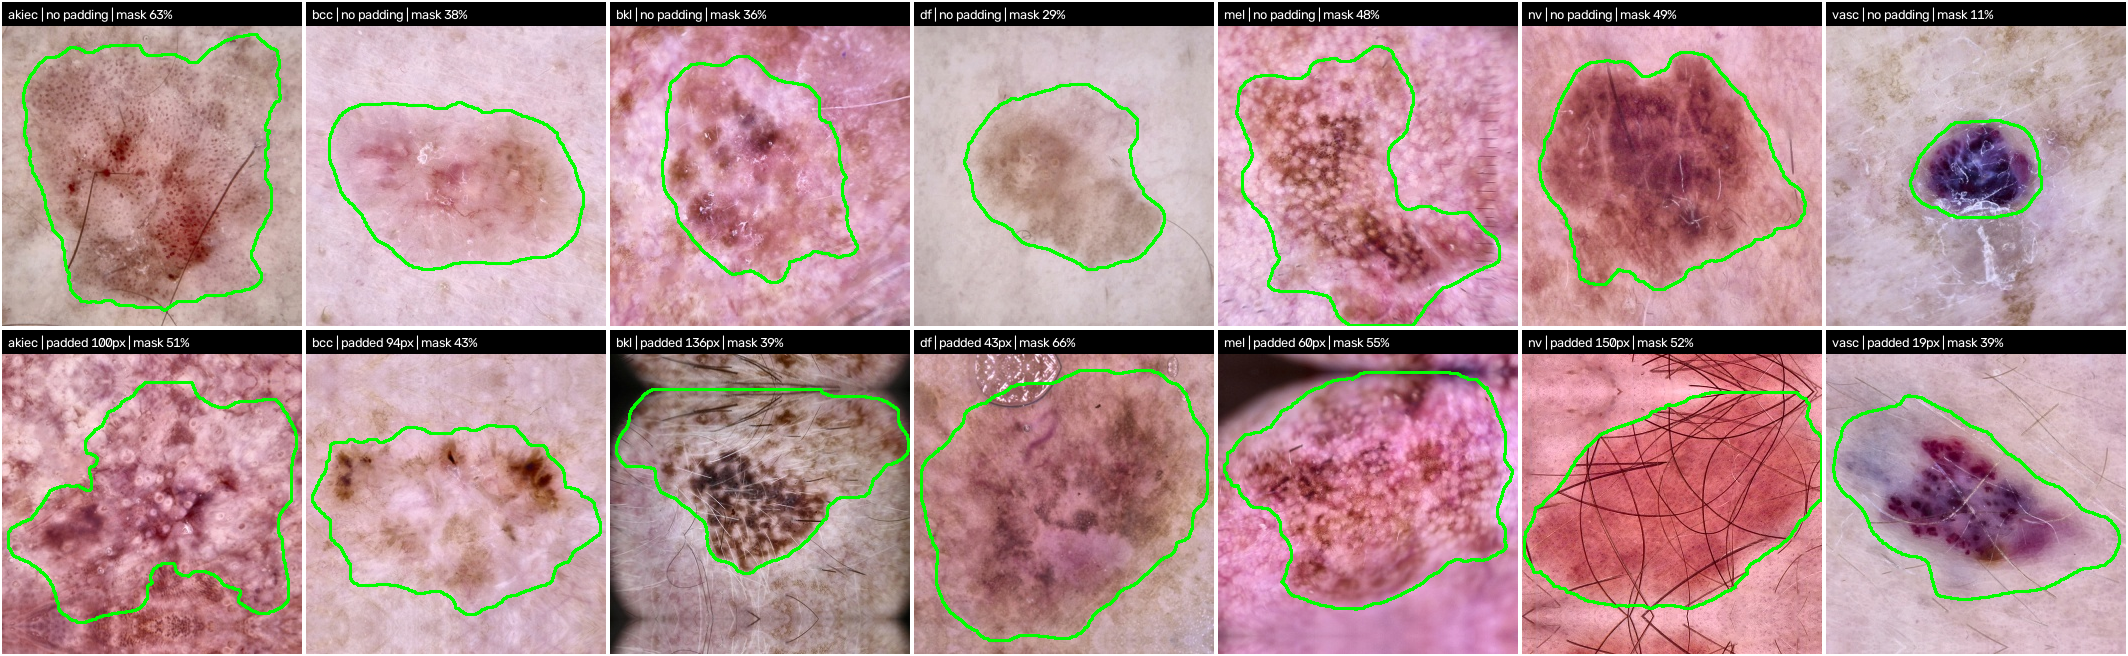


PAIR CHECK PASSED: every holdout image is 300 x 300 x 3 (8-bit), every mask is 300 x 300 with only 0 and 255, and no mask is empty.
Still needed from you: look at the figure and say whether the green outlines sit on the lesions (numbers cannot show that).


In [11]:
"""
03_02_pair_check.txt
Phase 4 -- Module 03: Holdout dataset -- Image and mask pair check (verification; safe to re-run)

TITLE: Image and mask pair check

TITLE DESCRIPTION
  Before any heatmap is scored against a lesion mask, this cell looks at every one of the 1,432 holdout image/mask
  pairs and proves they are usable: the right size and type, a mask that is a clean lesion/not-lesion map, and no
  empty mask (an empty mask would score every heatmap 0 and quietly pull a class down). It also draws an unpadded
  and a padded example of each class with the mask outline on top, so you can see with your own eyes that the
  outline sits on the lesion, which no number can prove.

CODE DESCRIPTION
  - Reads every image (must be 300 x 300 x 3, 8-bit) and every mask (through load_mask: 300 x 300, only 0 and 255),
    counts the lesion pixels, and flags an empty mask as a failure and a mask covering 99% or more of the image as a
    note only. Saves holdout_pair_check.csv (image_id, dx, padded, pad_px, mask_area_px, mask_area_fraction) and
    prints the mask-size spread per class, plus padded versus unpadded.
  - Saves alignment_check_holdout.png (row 1: first unpadded image of each class, row 2: first padded image, both in
    table order, mask outline in green) and shows it here. Problems are collected and ONE error is raised at the end,
    after both files are saved. Expect a few seconds.

Requires: 03_00 and 03_01 already run.
"""

import os
import tempfile

import cv2
import numpy as np
import pandas as pd

HOLDOUT_PAIR_CHECK_PATH = PHASE4_ARTIFACTS_DIR / "holdout_pair_check.csv"
ALIGNMENT_FIGURE_PATH = PHASE4_FIGURES_DIR / "alignment_check_holdout.png"

NEAR_FULL_MASK_FRACTION = 0.99      # a mask this full is noted, not failed (it would make Dice/IoU easy to inflate)
TILE_LABEL_HEIGHT = 24              # pixels of black label strip above each figure tile
OUTLINE_BGR = (0, 255, 0)           # green, in OpenCV's BGR order
OUTLINE_THICKNESS = 2
FIGURE_DISPLAY_WIDTH = 1400         # pixels, only for showing the figure in the notebook (the saved file is full size)
MAX_PROBLEMS_SHOWN = 25


def atomic_write_bytes(path, data):
    """Temporary file + fsync + retrying os.replace (the same pattern as atomic_write_json), for the CSV and the PNG."""
    path = str(path)
    folder = os.path.dirname(path) or "."
    os.makedirs(folder, exist_ok=True)
    fd, tmp_path = tempfile.mkstemp(dir=folder, suffix=".tmp")
    try:
        with os.fdopen(fd, "wb") as f:
            f.write(data)
            f.flush()
            os.fsync(f.fileno())
        replace_with_retry(tmp_path, path)
    except BaseException:
        remove_quietly(tmp_path)
        raise


def check_all_pairs():
    """Read every holdout image and mask. Returns (one record per image, list of problems)."""
    problems, records = [], []
    for row in HOLDOUT_TABLE.itertuples(index=False):
        record = {"image_id": row.image_id, "dx": row.dx, "padded": bool(row.padded), "pad_px": int(row.pad_px),
                  "mask_area_px": pd.NA, "mask_area_fraction": np.nan}

        image = cv2.imread(str(image_path(row.image_id)))
        if image is None:
            problems.append(f"{row.image_id}: the image could not be read ({image_path(row.image_id)})")
        elif image.shape != (IMAGE_SIZE, IMAGE_SIZE, 3) or image.dtype != np.uint8:
            problems.append(f"{row.image_id}: the image is {image.shape} {image.dtype}, "
                            f"expected {(IMAGE_SIZE, IMAGE_SIZE, 3)} uint8")

        try:
            mask = load_mask(row.image_id)            # raises on a missing file, a wrong size or values other than 0/255
        except (FileNotFoundError, ValueError) as exc:
            problems.append(str(exc))
        else:
            area = int(mask.sum())
            record["mask_area_px"] = area
            record["mask_area_fraction"] = area / float(IMAGE_SIZE * IMAGE_SIZE)
            if area == 0:
                problems.append(f"{row.image_id}: the mask is empty")

        records.append(record)

    pair_df = pd.DataFrame(records)
    pair_df["mask_area_px"] = pair_df["mask_area_px"].astype("Int64")
    return pair_df, problems


def print_area_summary(pair_df):
    print(f"\nMask size as % of the {IMAGE_SIZE} x {IMAGE_SIZE} image (lesion pixels / all pixels):")
    print(f"  {'class':<8}{'N':>6}{'min':>8}{'median':>8}{'mean':>8}{'max':>8}{'empty':>7}{'>=99%':>7}")
    for cls in list(CLASSES) + ["all"]:
        sub = pair_df if cls == "all" else pair_df[pair_df["dx"] == cls]
        pct = sub["mask_area_fraction"] * 100.0
        n_empty = int((sub["mask_area_px"] == 0).sum())
        n_full = int((sub["mask_area_fraction"] >= NEAR_FULL_MASK_FRACTION).sum())
        print(f"  {cls:<8}{len(sub):>6}{pct.min():>7.1f}%{pct.median():>7.1f}%{pct.mean():>7.1f}%{pct.max():>7.1f}%"
              f"{n_empty:>7}{n_full:>7}")
    print("\nPadded versus unpadded images (all classes together):")
    for flag, name in ((False, "unpadded"), (True, "padded")):
        pct = pair_df.loc[pair_df["padded"] == flag, "mask_area_fraction"] * 100.0
        print(f"  {name:<9} N {len(pct):>5}   mask median {pct.median():.1f}%   min {pct.min():.1f}%   max {pct.max():.1f}%")


def label_strip(text):
    strip = np.zeros((TILE_LABEL_HEIGHT, IMAGE_SIZE, 3), dtype=np.uint8)
    cv2.putText(strip, text, (6, 17), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    return strip


def blank_tile(text, note):
    body = np.full((IMAGE_SIZE, IMAGE_SIZE, 3), 70, dtype=np.uint8)
    cv2.putText(body, note, (60, IMAGE_SIZE // 2), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
    return np.vstack([label_strip(text), body])


def overlay_tile(row):
    """One figure tile: the image with the outline of its lesion mask in green, under a label strip."""
    image = cv2.imread(str(image_path(row.image_id)))
    if image is None:
        raise FileNotFoundError(f"Failed to load image: {image_path(row.image_id)}")
    mask = load_mask(row.image_id)
    contours = cv2.findContours(mask.astype(np.uint8) * 255, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[-2]
    outlined = image.copy()
    cv2.drawContours(outlined, contours, -1, OUTLINE_BGR, OUTLINE_THICKNESS)
    pad_text = f"padded {row.pad_px}px" if row.padded else "no padding"
    area_pct = 100.0 * float(mask.sum()) / mask.size
    return np.vstack([label_strip(f"{row.dx} | {pad_text} | mask {area_pct:.0f}%"), outlined])


def build_alignment_figure(problems):
    """2 rows x 7 classes. The first image of each kind in table order is used (no choosing, no scores involved)."""
    figure_rows = []
    for padded_flag in (False, True):
        tiles = []
        for cls in CLASSES:
            sub = HOLDOUT_TABLE[(HOLDOUT_TABLE["dx"] == cls) & (HOLDOUT_TABLE["padded"] == padded_flag)]
            label = f"{cls} | {'padded' if padded_flag else 'no padding'}"
            if sub.empty:
                tile = blank_tile(label, "none in holdout")
            else:
                try:
                    tile = overlay_tile(next(sub.head(1).itertuples(index=False)))
                except (FileNotFoundError, ValueError) as exc:
                    problems.append(f"alignment figure: could not draw the {label} example: {exc}")
                    tile = blank_tile(label, "unreadable")
            tiles.append(cv2.copyMakeBorder(tile, 2, 2, 2, 2, cv2.BORDER_CONSTANT, value=(255, 255, 255)))
        figure_rows.append(np.hstack(tiles))
    return np.vstack(figure_rows)


def run_pair_check():
    print(f"Checking {len(HOLDOUT_TABLE):,} image/mask pairs ...")
    pair_df, problems = check_all_pairs()
    if len(pair_df) != EXPECTED_HOLDOUT_ROWS:
        problems.append(f"the pair check covers {len(pair_df)} images, expected {EXPECTED_HOLDOUT_ROWS}")

    n_read = int(pair_df["mask_area_px"].notna().sum())
    print(f"  masks read cleanly: {n_read:,} of {len(pair_df):,}")

    near_full = pair_df.loc[pair_df["mask_area_fraction"] >= NEAR_FULL_MASK_FRACTION, "image_id"].tolist()
    if near_full:
        shown = ", ".join(near_full[:10]) + (" ..." if len(near_full) > 10 else "")
        print(f"  NOTE: {len(near_full)} mask(s) cover {NEAR_FULL_MASK_FRACTION:.0%} or more of the image: {shown}")
    else:
        print(f"  no mask covers {NEAR_FULL_MASK_FRACTION:.0%} or more of the image")

    atomic_write_bytes(HOLDOUT_PAIR_CHECK_PATH, pair_df.to_csv(index=False).encode("utf-8"))
    print(f"Saved: {HOLDOUT_PAIR_CHECK_PATH}")

    print_area_summary(pair_df)

    figure = build_alignment_figure(problems)
    ok, png = cv2.imencode(".png", figure)
    if not ok:
        raise RuntimeError("Could not encode the alignment figure as PNG")
    png_bytes = png.tobytes()
    atomic_write_bytes(ALIGNMENT_FIGURE_PATH, png_bytes)
    print(f"\nSaved: {ALIGNMENT_FIGURE_PATH}  ({figure.shape[1]} x {figure.shape[0]} pixels)")
    print("Figure: row 1 = first UNPADDED image of each class, row 2 = first PADDED image; green line = the mask outline.")

    try:
        from IPython.display import Image as _IPyImage, display as _display
        _display(_IPyImage(data=png_bytes, width=FIGURE_DISPLAY_WIDTH))
    except ImportError:
        print("(not running in a notebook: open the saved figure to look at it)")

    return pair_df, problems


HOLDOUT_PAIR_CHECK, _pair_problems = run_pair_check()

if _pair_problems:
    _shown = _pair_problems[:MAX_PROBLEMS_SHOWN]
    _more = len(_pair_problems) - len(_shown)
    raise RuntimeError(f"PAIR CHECK FAILED ({len(_pair_problems)} problem(s)):\n  - " + "\n  - ".join(_shown)
                       + (f"\n  ... and {_more} more" if _more > 0 else ""))
print("\nPAIR CHECK PASSED: every holdout image is 300 x 300 x 3 (8-bit), every mask is 300 x 300 with only 0 and 255, "
      "and no mask is empty.")
print("Still needed from you: look at the figure and say whether the green outlines sit on the lesions (numbers cannot show that).")

In [12]:
"""
03_03_metadata_check.txt
Phase 4 -- Module 03: Holdout dataset -- Metadata and dataset check (verification; safe to re-run)

TITLE: Metadata and dataset check

TITLE DESCRIPTION
  The multimodal model is only as right as the 20 numbers it receives with each image. This cell proves that the
  holdout's metadata vectors are what the frozen model expects: fold 3's age scaling (never a fresh fit on the
  holdout), the right sex and site slots, a missing age handled the way training handled it, and no overlap between
  the holdout and the cross-validation pool. It also proves that the dataset hands the model the right image,
  metadata and label for chosen rows.

CODE DESCRIPTION
  - Re-encodes all 1,432 rows with a second encoder written separately from the pasted Phase 3 one (slot positions
    typed by hand) and compares it with HOLDOUT_METADATA. Checks the age scaling against a fresh read of the
    encoder-stats file, the model card and the recorded values; checks the 9 missing ages, the sex counts (778 / 646 / 8),
    the site counts, exactly one sex slot and one site slot set per row, and the order of rows against holdout_split.csv.
  - Spot-checks five dataset items (first, last, a missing-age row, an unknown-sex row, a padded row) against a manual
    image computation, then the first DataLoader batch, then the holdout/CV-pool separation (no shared image or lesion;
    8,583 + 1,432 = 10,015). Every check is printed; ONE error is raised at the end if any failed. Nothing is written.

Requires: 03_00 and 03_01 already run (and Module 02, for MODEL_CARD).
"""

import cv2
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

# --- Facts to compare against, typed here by hand (not taken from the pasted Phase 3 code) -----------------------
HAND_SEX_ORDER = ("male", "female", "unknown")
HAND_SITE_ORDER = ("abdomen", "acral", "back", "chest", "ear", "face", "foot", "genital", "hand",
                   "lower extremity", "neck", "scalp", "trunk", "unknown", "upper extremity")
HAND_SEX_SLOT_START = 2             # slots 0-1 are age_z and age_recorded
HAND_SITE_SLOT_START = 5            # slots 2-4 are the three sex slots; slots 5-19 are the 15 sites
HAND_IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
HAND_IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

EXPECTED_FOLD3_AGE_MEAN = 51.76306926343535         # fold 3's training-fold age mean (Phase 3 encoder-stats file)
EXPECTED_FOLD3_AGE_STD = 16.98208097531615          # and std (population, divide by n)
EXPECTED_HOLDOUT_MISSING_AGE = 9                    # from the 01_00 printout
EXPECTED_HOLDOUT_SEX_COUNTS = {"male": 778, "female": 646, "unknown": 8}
EXPECTED_HOLDOUT_SITE_COUNTS = {"back": 314, "lower extremity": 297, "trunk": 199, "upper extremity": 158,
                                "abdomen": 144, "face": 105, "chest": 58, "foot": 48, "unknown": 35, "neck": 23,
                                "scalp": 20, "hand": 12, "genital": 8, "ear": 8, "acral": 3}
EXPECTED_TOTAL_IMAGES = 10_015                      # 8,583 in the CV pool + 1,432 in the holdout

HAND_ENCODE_TOLERANCE = 1e-5        # float32 rounding is about 1e-7; anything near 1e-5 is a real difference
AGE_STAT_TOLERANCE = 1e-9
IMAGE_TENSOR_TOLERANCE = 1e-6
PLAUSIBLE_MAX_ABS_AGE_Z = 6.0       # real ages (0-85) scaled by mean 51.8 / std 17.0 stay within about -3.1 to +2.0

assert sum(EXPECTED_HOLDOUT_SEX_COUNTS.values()) == EXPECTED_HOLDOUT_ROWS, "hand-typed sex counts do not add up"
assert sum(EXPECTED_HOLDOUT_SITE_COUNTS.values()) == EXPECTED_HOLDOUT_ROWS, "hand-typed site counts do not add up"
assert set(EXPECTED_HOLDOUT_SITE_COUNTS) == set(HAND_SITE_ORDER) and len(HAND_SITE_ORDER) == 15


def hand_encode_row(age, sex, site, age_mean, age_std):
    """The 20-value vector of one image, built slot by slot (float64): age_z, age_recorded, 3 sex slots, 15 site slots."""
    vec = np.zeros(20, dtype=np.float64)
    if pd.notna(age):
        vec[0] = (float(age) - age_mean) / age_std
        vec[1] = 1.0
    vec[HAND_SEX_SLOT_START + HAND_SEX_ORDER.index(sex)] = 1.0
    vec[HAND_SITE_SLOT_START + HAND_SITE_ORDER.index(site)] = 1.0
    return vec


def first_true(flags):
    flags = np.asarray(flags, dtype=bool)
    return int(np.flatnonzero(flags)[0]) if flags.any() else None


def run_metadata_check():
    results = []

    def check(name, ok, detail=""):
        results.append((name, bool(ok), detail))
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    table, meta = HOLDOUT_TABLE, HOLDOUT_METADATA
    n = len(table)

    print("A. Layout and row order")
    check("layout lists equal the hand-typed lists",
          tuple(SEX_CATEGORIES) == HAND_SEX_ORDER and tuple(SITE_CATEGORIES) == HAND_SITE_ORDER)
    check(f"metadata array is {n:,} x 20, float32, every value finite",
          meta.shape == (n, 20) and meta.dtype == np.float32 and bool(np.isfinite(meta).all()),
          f"shape {meta.shape}, dtype {meta.dtype}")
    file_ids = pd.read_csv(HOLDOUT_CSV_PATH)[HOLDOUT_ID_COL].tolist()
    check(f"table rows are in the order of {HOLDOUT_CSV_PATH.name}", table["image_id"].tolist() == file_ids)
    check("dataset rows are in the table's order",
          len(HOLDOUT_DATASET) == n and HOLDOUT_DATASET.image_ids == table["image_id"].tolist())

    print("\nB. Age scaling (must be fold 3's training-fold values)")
    used_mean, used_std = HOLDOUT_AGE_SCALING_USED
    fresh_mean, fresh_std = get_fold_age_stats(load_encoder_stats(), SELECTED_FOLD)
    card_age = MODEL_CARD["input_contract"]["metadata"]["age"]
    check("scaling used = a fresh read of fold 3's entry in the encoder-stats file",
          used_mean == fresh_mean and used_std == fresh_std, f"mean {used_mean!r}, std {used_std!r}")
    check("scaling used = the model card's age mean and std",
          abs(used_mean - card_age["mean"]) <= CARD_STAT_TOLERANCE and abs(used_std - card_age["std"]) <= CARD_STAT_TOLERANCE)
    check("scaling used = the recorded fold 3 values",
          abs(used_mean - EXPECTED_FOLD3_AGE_MEAN) <= AGE_STAT_TOLERANCE and abs(used_std - EXPECTED_FOLD3_AGE_STD) <= AGE_STAT_TOLERANCE)

    print("\nC. All rows against an independent encoder")
    hand = np.stack([hand_encode_row(a, s, loc, used_mean, used_std)
                     for a, s, loc in zip(table["age"], table["sex"], table["localization"])])
    diff = np.abs(hand - meta.astype(np.float64))
    n_differ = int((diff.max(axis=1) > HAND_ENCODE_TOLERANCE).sum())
    check(f"all {n:,} rows equal the independent encoder (tolerance {HAND_ENCODE_TOLERANCE:g})", n_differ == 0,
          f"largest difference {diff.max():.2e}, {n_differ} row(s) differ")

    print("\nD. Counts and structure")
    missing = table["age"].isna().to_numpy()
    check(f"images with no recorded age = {EXPECTED_HOLDOUT_MISSING_AGE}", int(missing.sum()) == EXPECTED_HOLDOUT_MISSING_AGE,
          f"found {int(missing.sum())}")
    check("missing-age rows: age_z = 0.0 and age_recorded = 0", bool((meta[missing, 0] == 0).all() and (meta[missing, 1] == 0).all()))
    check("recorded-age rows: age_recorded = 1", bool((meta[~missing, 1] == 1).all()))
    check(f"recorded ages scale to a plausible range (|age_z| < {PLAUSIBLE_MAX_ABS_AGE_Z:g})",
          float(np.abs(meta[~missing, 0]).max()) < PLAUSIBLE_MAX_ABS_AGE_Z,
          f"age_z from {meta[~missing, 0].min():.2f} to {meta[~missing, 0].max():.2f}")
    sex_block, site_block = meta[:, 2:5], meta[:, 5:20]
    check("every row has exactly one sex slot and one site slot set, and every slot after age_z is 0 or 1",
          bool((sex_block.sum(axis=1) == 1).all() and (site_block.sum(axis=1) == 1).all() and np.isin(meta[:, 1:], (0.0, 1.0)).all()))
    sex_found = {c: int(sex_block[:, i].sum()) for i, c in enumerate(HAND_SEX_ORDER)}
    check(f"sex counts from the vectors = {EXPECTED_HOLDOUT_SEX_COUNTS}", sex_found == EXPECTED_HOLDOUT_SEX_COUNTS, f"found {sex_found}")
    site_found = {c: int(site_block[:, i].sum()) for i, c in enumerate(HAND_SITE_ORDER)}
    check("site counts from the vectors = the 01_00 printout", site_found == EXPECTED_HOLDOUT_SITE_COUNTS,
          "all 15 sites match" if site_found == EXPECTED_HOLDOUT_SITE_COUNTS else
          f"differing: {[c for c in HAND_SITE_ORDER if site_found[c] != EXPECTED_HOLDOUT_SITE_COUNTS[c]]}")

    print("\nE. Dataset items against a manual computation")
    picks = []
    for label, idx in (("first row", 0), ("last row", n - 1),
                       ("first missing-age row", first_true(missing)),
                       ("first unknown-sex row", first_true((table["sex"] == "unknown").to_numpy())),
                       ("first padded row", first_true(table["padded"].to_numpy()))):
        if idx is not None and all(idx != seen for _, seen in picks):
            picks.append((label, idx))
    for label, idx in picks:
        row = table.iloc[idx]
        tensor, meta_item, label_item = HOLDOUT_DATASET[idx]
        bgr = cv2.imread(str(image_path(row["image_id"])))
        reference = ((bgr[..., ::-1].astype(np.float32) / 255.0 - HAND_IMAGENET_MEAN) / HAND_IMAGENET_STD).transpose(2, 0, 1)
        image_ok = (tuple(tensor.shape) == (3, IMAGE_SIZE, IMAGE_SIZE) and tensor.dtype == torch.float32
                    and bool(torch.isfinite(tensor).all()) and bool(np.allclose(tensor.numpy(), reference, atol=IMAGE_TENSOR_TOLERANCE)))
        meta_ok = (tuple(meta_item.shape) == (20,) and meta_item.dtype == torch.float32
                   and bool(np.array_equal(meta_item.numpy(), meta[idx])))
        label_ok = isinstance(label_item, int) and label_item == CLASS_TO_IDX[row["dx"]] == int(row["label"])
        check(f"item {idx} ({label}: {row['image_id']}, {row['dx']})", image_ok and meta_ok and label_ok,
              f"image {'ok' if image_ok else 'WRONG'}, metadata {'ok' if meta_ok else 'WRONG'}, label {'ok' if label_ok else 'WRONG'}")

    loader = DataLoader(HOLDOUT_DATASET, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    images, metadata, labels = next(iter(loader))
    check(f"first DataLoader batch has the right shapes and types (batch {BATCH_SIZE})",
          tuple(images.shape) == (BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE) and images.dtype == torch.float32
          and tuple(metadata.shape) == (BATCH_SIZE, 20) and metadata.dtype == torch.float32
          and tuple(labels.shape) == (BATCH_SIZE,) and labels.dtype == torch.int64)
    check(f"its labels and metadata equal table rows 0-{BATCH_SIZE - 1}",
          bool(np.array_equal(labels.numpy(), table["label"].to_numpy()[:BATCH_SIZE])
               and np.array_equal(metadata.numpy(), meta[:BATCH_SIZE])))

    print("\nF. Holdout kept apart from the cross-validation pool")
    pool = pd.read_csv(FOLD_CSV_PATH)
    shared_images = set(pool["image_id"]) & set(table["image_id"])
    shared_lesions = set(pool["lesion_id"]) & set(table["lesion_id"])
    check(f"the CV pool has {EXPECTED_POOL_ROWS:,} rows", len(pool) == EXPECTED_POOL_ROWS, f"found {len(pool):,}")
    check("no holdout image is in the CV pool", not shared_images, f"{len(shared_images)} shared")
    check("no holdout lesion is in the CV pool", not shared_lesions, f"{len(shared_lesions)} shared; the holdout has "
          f"{table['lesion_id'].nunique():,} distinct lesions")
    check(f"pool + holdout = {EXPECTED_TOTAL_IMAGES:,} images", len(pool) + n == EXPECTED_TOTAL_IMAGES, f"{len(pool):,} + {n:,}")

    failed = [name for name, ok, _ in results if not ok]
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    if failed:
        raise RuntimeError("METADATA CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("METADATA CHECK PASSED: the holdout metadata is encoded with fold 3's scaling and the right slots, the dataset "
          "returns the right image, metadata and label, and the holdout is clear of the cross-validation pool.")


run_metadata_check()

A. Layout and row order
  [ok] layout lists equal the hand-typed lists
  [ok] metadata array is 1,432 x 20, float32, every value finite  (shape (1432, 20), dtype float32)
  [ok] table rows are in the order of holdout_split.csv
  [ok] dataset rows are in the table's order

B. Age scaling (must be fold 3's training-fold values)
  [ok] scaling used = a fresh read of fold 3's entry in the encoder-stats file  (mean 51.76306926343535, std 16.98208097531615)
  [ok] scaling used = the model card's age mean and std
  [ok] scaling used = the recorded fold 3 values

C. All rows against an independent encoder
  [ok] all 1,432 rows equal the independent encoder (tolerance 1e-05)  (largest difference 9.39e-08, 0 row(s) differ)

D. Counts and structure
  [ok] images with no recorded age = 9  (found 9)
  [ok] missing-age rows: age_z = 0.0 and age_recorded = 0
  [ok] recorded-age rows: age_recorded = 1
  [ok] recorded ages scale to a plausible range (|age_z| < 6)  (age_z from -3.05 to 1.96)
  [ok] ever

# Module 4

In [13]:
"""
04_00_gradcam_function.txt
Phase 4 -- Module 04: Grad-CAM function -- The Grad-CAM function and the precision switches (reusable)

TITLE: Grad-CAM function

TITLE DESCRIPTION
  The one piece of code that produces every heatmap in Phase 4 (decision P4-8): our own small function, no library and
  no hooks, in full fp32, with the class index passed in by the caller so a class mix-up cannot go unnoticed. It also
  switches TF32 off (decision P4-10), which makes "full fp32" literally true for the explanation work in Modules 04 to 06.
  Everything is computed for one image at a time, on the frozen models, with nothing written to the models.

CODE DESCRIPTION
  - Switches TF32 off for convolutions and matrix products; gradcam() refuses to run if anyone switches it back on.
    tapped_forward() runs the backbone block by block, keeps the outputs of backbone[5] and backbone[-1], then finishes with
    the model's own head path (image-only: pool -> classifier; multimodal: metadata branch -> MetaBlock -> pool -> classifier).
  - gradcam(model, image, metadata, class_index): one torch.autograd.grad call returns the gradient at both layers; each
    channel weight is the gradient's average over space; the heatmap is ReLU(sum of weight x feature map), returned on its
    native grid (10 x 10 and 19 x 19) with the weights, the logits and the class index used. Also single_item() and
    fp32_logits(). Writes nothing; ends with a shapes-only smoke run that times one call.

Requires: Modules 01, 02 and 03 already run in this kernel.
"""

import time

import numpy as np
import torch

# ---------------------------------------------------------------------------
# Precision switches (decision P4-10): no TF32 anywhere, so fp32 means fp32
# ---------------------------------------------------------------------------
# PyTorch 2.9 and later control TF32 with fp32_precision ("ieee" = full fp32, "tf32" = reduced) and are phasing out the
# old allow_tf32 flags; mixing the two APIs is discouraged. So the new API is used when it exists, the old flags otherwise.
_NEW_TF32_API = (hasattr(torch.backends.cudnn, "conv") and hasattr(torch.backends.cudnn.conv, "fp32_precision")
                 and hasattr(torch.backends.cuda.matmul, "fp32_precision"))


def switch_tf32_off():
    if _NEW_TF32_API:
        torch.backends.cudnn.conv.fp32_precision = "ieee"
        torch.backends.cuda.matmul.fp32_precision = "ieee"
    else:
        torch.backends.cudnn.allow_tf32 = False
        torch.backends.cuda.matmul.allow_tf32 = False
        torch.set_float32_matmul_precision("highest")


def precision_state():
    """What convolutions and matrix products will use for fp32 data: 'ieee' (full fp32) or something else (e.g. 'tf32')."""
    if _NEW_TF32_API:
        return {"api": "fp32_precision", "convolution": str(torch.backends.cudnn.conv.fp32_precision),
                "matmul": str(torch.backends.cuda.matmul.fp32_precision)}
    legacy_matmul_ieee = (not torch.backends.cuda.matmul.allow_tf32) and torch.get_float32_matmul_precision() == "highest"
    return {"api": "allow_tf32 flags", "convolution": "tf32" if torch.backends.cudnn.allow_tf32 else "ieee",
            "matmul": "ieee" if legacy_matmul_ieee else "tf32 or reduced"}


def precision_is_strict():
    state = precision_state()
    return state["convolution"] == "ieee" and state["matmul"] == "ieee"


switch_tf32_off()


# ---------------------------------------------------------------------------
# Which backbone blocks are tapped (positions, not scores, chose them: P4-2, P4-3)
# ---------------------------------------------------------------------------
BACKBONE_BLOCKS = 9                                          # blocks 0-8 (checked in 02_01 and 02_03)
PRIMARY_BLOCK = PRIMARY_LAYER_INDEX % BACKBONE_BLOCKS        # backbone[-1] -> block 8
SECONDARY_BLOCK = SECONDARY_LAYER_INDEX % BACKBONE_BLOCKS    # backbone[5]  -> block 5
LAYER_NAMES = ("primary", "secondary")


def _check_class_index(class_index):
    """The class index must be given explicitly, as a whole number from 0 to 6 (a bool or a float is refused)."""
    if isinstance(class_index, bool) or not isinstance(class_index, (int, np.integer)):
        raise TypeError(f"class_index must be an integer, got {type(class_index).__name__}: {class_index!r}")
    class_index = int(class_index)
    if not 0 <= class_index < len(CLASSES):
        raise ValueError(f"class_index {class_index} is outside 0-{len(CLASSES) - 1}")
    return class_index


def head_forward(model, final_map, metadata):
    """Everything after the backbone: (B, 1536, 10, 10) feature map -> (B, 7) logits, exactly as the model's forward does it."""
    if isinstance(model, MultimodalNet):
        meta_features = model.metadata_branch(metadata)
        fused = model.metablock(final_map, meta_features)          # MetaBlock acts on the unpooled map
        pooled = model.pool(fused).flatten(1)                      # pooling after fusion
    elif isinstance(model, ImageOnlyNet):
        pooled = model.pool(final_map).flatten(1)
    else:
        raise TypeError(f"Unknown model type {type(model).__name__}; expected MultimodalNet or ImageOnlyNet")
    return model.classifier(pooled)


def tapped_forward(model, image, metadata):
    """Same computation as model(image, metadata), but the outputs of backbone[5] and backbone[-1] are kept.
    Returns (logits, activation at backbone[5], activation at backbone[-1])."""
    x = image
    a_mid = a_final = None
    for i, block in enumerate(model.backbone):
        x = block(x)
        if i == SECONDARY_BLOCK:
            a_mid = x
        if i == PRIMARY_BLOCK:
            a_final = x
    logits = head_forward(model, a_final, metadata)
    return logits, a_mid, a_final


def gradcam(model, image, metadata, class_index, keep_tensors=False):
    """Grad-CAM of ONE image for an explicit class index, at backbone[-1] ('primary') and backbone[5] ('secondary').

    image: float32 (1, 3, 300, 300); metadata: float32 (1, 20); both on the model's device.
    The score is the pre-softmax logit of class_index. keep_tensors=True also returns each layer's gradient and
    activation (for the verification files only).
    Returns {"class_index", "predicted_class", "logits" (7,), "score",
             "layers": {name: {"heatmap" (H, W) after ReLU, "alpha" (C,), "shape"}}}."""
    class_index = _check_class_index(class_index)
    if not precision_is_strict():
        raise RuntimeError(f"TF32 is switched on ({precision_state()}); Phase 4 explanations run in strict fp32 (P4-10)")
    if len(model.backbone) != BACKBONE_BLOCKS:
        raise RuntimeError(f"expected {BACKBONE_BLOCKS} backbone blocks, found {len(model.backbone)}")
    if tuple(image.shape) != (1, 3, IMAGE_SIZE, IMAGE_SIZE) or image.dtype != torch.float32:
        raise ValueError(f"image must be float32 (1, 3, {IMAGE_SIZE}, {IMAGE_SIZE}), got {tuple(image.shape)} {image.dtype}")
    if tuple(metadata.shape) != (1, METADATA_DIM) or metadata.dtype != torch.float32:
        raise ValueError(f"metadata must be float32 (1, {METADATA_DIM}), got {tuple(metadata.shape)} {metadata.dtype}")
    model_device = next(model.parameters()).device
    if image.device != model_device or metadata.device != model_device:
        raise ValueError(f"image/metadata are on {image.device}/{metadata.device}, the model is on {model_device}")

    model.eval()                                                    # dropout off, BatchNorm on running statistics
    with torch.enable_grad(), torch.autocast(device_type=image.device.type, enabled=False):
        logits, a_mid, a_final = tapped_forward(model, image, metadata)
        score = logits[0, class_index]                              # pre-softmax logit of the requested class
        grad_final, grad_mid = torch.autograd.grad(score, [a_final, a_mid])   # one call, both layers, no hooks

    layers = {}
    with torch.no_grad():
        for name, activation, gradient in (("primary", a_final, grad_final), ("secondary", a_mid, grad_mid)):
            expected = list(EXPECTED_LAYER_SHAPES[name])
            if list(activation.shape[1:]) != expected:
                raise RuntimeError(f"{name} layer has shape {list(activation.shape[1:])}, expected {expected}")
            alpha = gradient.mean(dim=(2, 3))                                        # (1, C): channel weights
            cam = torch.relu((alpha[:, :, None, None] * activation).sum(dim=1))     # (1, H, W)
            entry = {"heatmap": cam[0].cpu().numpy(), "alpha": alpha[0].cpu().numpy(), "shape": tuple(expected)}
            if keep_tensors:
                entry["gradient"] = gradient[0].cpu().numpy()
                entry["activation"] = activation[0].detach().cpu().numpy()
            layers[name] = entry

    logits_np = logits[0].detach().float().cpu().numpy()
    return {"class_index": class_index, "predicted_class": int(logits_np.argmax()), "logits": logits_np,
            "score": float(logits_np[class_index]), "layers": layers}


def single_item(dataset, index, device=None):
    """One dataset item as the batch-of-one tensors gradcam() wants: (image (1,3,300,300), metadata (1,20), label)."""
    device = device if device is not None else DEVICE
    image, metadata, label = dataset[index]
    return image.unsqueeze(0).to(device), metadata.unsqueeze(0).to(device), int(label)


def fp32_logits(model, image, metadata):
    """The model's own forward pass (not the tapped one) in strict fp32, no autocast: (7,) logits as numpy."""
    model.eval()
    with torch.no_grad(), torch.autocast(device_type=image.device.type, enabled=False):
        return model(image, metadata)[0].float().cpu().numpy()


# ---------------------------------------------------------------------------
# Smoke run: shapes and timing only. Holdout row 0 is used as an input; no logit or class is printed.
# ---------------------------------------------------------------------------
assert precision_is_strict(), f"TF32 could not be switched off: {precision_state()}"

print("Grad-CAM function ready.")
print(f"  precision : convolutions '{precision_state()['convolution']}', matrix products '{precision_state()['matmul']}' "
      f"(set through the {precision_state()['api']} API; 'ieee' = full fp32, decision P4-10)")
print(f"  layers    : primary = backbone[{PRIMARY_LAYER_INDEX}] (block {PRIMARY_BLOCK}), "
      f"secondary = backbone[{SECONDARY_LAYER_INDEX}] (block {SECONDARY_BLOCK})")

_image, _metadata, _label = single_item(HOLDOUT_DATASET, 0)
for _kind in MODEL_KINDS:
    gradcam(MODELS[_kind], _image, _metadata, 0)                      # first call: warm-up
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    _t0 = time.perf_counter()
    _smoke = gradcam(MODELS[_kind], _image, _metadata, 0)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    _ms = 1000.0 * (time.perf_counter() - _t0)
    print(f"  smoke run : {_kind:<10} primary map {_smoke['layers']['primary']['heatmap'].shape}, "
          f"secondary map {_smoke['layers']['secondary']['heatmap'].shape}, alpha lengths "
          f"{len(_smoke['layers']['primary']['alpha'])} and {len(_smoke['layers']['secondary']['alpha'])}; "
          f"{_ms:.0f} ms per image  (about {_ms * len(HOLDOUT_DATASET) / 60000.0:.1f} min for all {len(HOLDOUT_DATASET):,} images)")

Grad-CAM function ready.
  precision : convolutions 'ieee', matrix products 'ieee' (set through the fp32_precision API; 'ieee' = full fp32, decision P4-10)
  layers    : primary = backbone[-1] (block 8), secondary = backbone[5] (block 5)
  smoke run : multimodal primary map (10, 10), secondary map (19, 19), alpha lengths 1536 and 136; 67 ms per image  (about 1.6 min for all 1,432 images)
  smoke run : ablation   primary map (10, 10), secondary map (19, 19), alpha lengths 1536 and 136; 37 ms per image  (about 0.9 min for all 1,432 images)


In [14]:
"""
04_01_exact_tests.txt
Phase 4 -- Module 04: Grad-CAM function -- Exact tests of the Grad-CAM function (verification; safe to re-run)

TITLE: Exact tests of the Grad-CAM function

TITLE DESCRIPTION
  A wrong heatmap looks just as plausible as a right one, so the function from 04_00 is proven against answers that are known
  in advance. For the image-only model at the final layer the maths has a closed form: the logit is a weighted average of
  the 1536 feature maps, so every channel weight must equal the classifier's weight W[c,k] divided by 100 (the 10 x 10
  grid has 100 cells), and the heatmap must equal ReLU(sum of (W[c,k] / 100) x map k). The multimodal model has no such
  closed form (MetaBlock), so it relies on the same function passing these tests plus the checks in 04_02.

CODE DESCRIPTION
  - Uses seven holdout images (the first of each class in table order; only as inputs, no prediction is printed), every class
    index, both models. Checks: the tapped forward gives the model's own logits; image-only, final layer: channel weights
    = W/100 for all 7 classes, the gradient is identical in all 100 cells, the heatmap equals the closed form; both models,
    both layers: the gradient equals one obtained by a different route (restart the network from a detached copy of that
    layer's output); two identical calls give identical maps.
  - Also proves the tests leave the models alone (no stored parameter gradients, still in eval mode, weights and BatchNorm
    statistics byte-for-byte unchanged). Every check is printed; saves gradcam_exact_tests.json (settings, worst-case numbers,
    PASSED/FAILED); ONE error is raised at the end if any check failed. Expect well under a minute.

Requires: 04_00 already run.
"""

import hashlib

import numpy as np
import torch
import torch.nn as nn

GRADCAM_EXACT_TESTS_PATH = PHASE4_ARTIFACTS_DIR / "gradcam_exact_tests.json"

LOGIT_ATOL = 1e-5                    # tapped forward vs the model's own forward
ALPHA_RTOL = 1e-5                    # channel weights vs W/100 (a division and an average of 100 equal numbers: ~1e-7 expected)
ALPHA_ATOL = 1e-12
CELL_SPREAD_RTOL = 1e-6              # image-only final-layer gradient: largest max-min over the 100 cells, vs the largest |W/100|
HEATMAP_ATOL = 1e-6                  # closed-form heatmap: absolute floor ...
HEATMAP_PEAK_RTOL = 1e-4             # ... plus this fraction of the map's peak
GRADIENT_PEAK_RTOL = 1e-4            # re-entry gradient vs the function's gradient, as a fraction of the gradient's peak
REPEAT_ATOL = 1e-6                   # two identical calls


def state_digest(model):
    """SHA-256 over every weight and every BatchNorm statistic of a model (its whole state_dict)."""
    digest = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        digest.update(name.encode("utf-8"))
        digest.update(tensor.detach().cpu().numpy().tobytes())
    return digest.hexdigest()


def classifier_weight(model):
    """The classifier's (7, 1536) weight matrix as float64 numpy."""
    linears = [m for m in model.classifier.modules() if isinstance(m, nn.Linear)]
    if len(linears) != 1 or tuple(linears[0].weight.shape) != (len(CLASSES), FEATURE_CHANNELS):
        raise RuntimeError("the classifier is not a single Linear layer of shape (7, 1536) as expected")
    return linears[0].weight.detach().cpu().numpy().astype(np.float64)


def reentry_gradients(model, image, metadata, class_index):
    """The gradient of the class score at backbone[5] and backbone[-1] by a different route than gradcam(): run the backbone
    once without gradients, then restart the network from a detached copy of each block's output (a fresh leaf) and ask
    autograd for the gradient of that leaf. Returns {"primary": array, "secondary": array}, each (C, H, W)."""
    model.eval()
    blocks = list(model.backbone)
    with torch.no_grad(), torch.autocast(device_type=image.device.type, enabled=False):
        x = image
        outputs = []
        for block in blocks:
            x = block(x)
            outputs.append(x)
    result = {}
    with torch.enable_grad(), torch.autocast(device_type=image.device.type, enabled=False):
        leaf = outputs[PRIMARY_BLOCK].detach().clone().requires_grad_(True)
        logits = head_forward(model, leaf, metadata)
        (grad,) = torch.autograd.grad(logits[0, class_index], leaf)
        result["primary"] = grad[0].cpu().numpy()

        leaf = outputs[SECONDARY_BLOCK].detach().clone().requires_grad_(True)
        x = leaf
        for block in blocks[SECONDARY_BLOCK + 1:]:
            x = block(x)
        logits = head_forward(model, x, metadata)
        (grad,) = torch.autograd.grad(logits[0, class_index], leaf)
        result["secondary"] = grad[0].cpu().numpy()
    return result


def first_row_of_each_class():
    rows = []
    for cls in CLASSES:
        rows.append(int(np.flatnonzero((HOLDOUT_TABLE["dx"] == cls).to_numpy())[0]))
    return rows


def run_exact_tests():
    results = []

    def check(name, ok, detail="", numbers=None):
        results.append({"check": name, "ok": bool(ok), "detail": detail, "numbers": numbers or {}})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    rows = first_row_of_each_class()
    image_ids = [HOLDOUT_TABLE.iloc[r]["image_id"] for r in rows]
    inputs = [single_item(HOLDOUT_DATASET, r) for r in rows]                       # (image, metadata, label)
    print("Test images (first of each class, table order): " + ", ".join(f"{c} {i}" for c, i in zip(CLASSES, image_ids)))
    digests_before = {kind: state_digest(MODELS[kind]) for kind in MODEL_KINDS}

    print("\nA. Settings")
    state = precision_state()
    check("convolutions and matrix products run in full fp32 (no TF32)", precision_is_strict(), str(state))
    check("both models are in eval mode", all(not any(m.training for m in MODELS[k].modules()) for k in MODEL_KINDS))

    worst = {kind: {"logit": 0.0, "alpha_rel": 0.0, "alpha_abs": 0.0, "alpha_violations": 0, "cell_spread": 0.0,
                    "heatmap": 0.0, "reentry_primary": 0.0, "reentry_secondary": 0.0, "repeat": 0.0} for kind in MODEL_KINDS}
    n_cells = int(np.prod(EXPECTED_LAYER_SHAPES["primary"][1:]))
    n_calls = {kind: 0 for kind in MODEL_KINDS}
    flat_closed_form_maps = 0
    print(f"\nRunning {len(inputs) * len(CLASSES)} Grad-CAM calls per model, each with its re-entry run ...")

    for kind in MODEL_KINDS:
        model = MODELS[kind]
        weight = classifier_weight(model) if kind == "ablation" else None
        for (image, metadata, label) in inputs:
            reference = fp32_logits(model, image, metadata)
            for class_index in range(len(CLASSES)):
                out = gradcam(model, image, metadata, class_index, keep_tensors=True)
                n_calls[kind] += 1
                w = worst[kind]
                w["logit"] = max(w["logit"], float(np.abs(out["logits"] - reference).max()))

                reentry = reentry_gradients(model, image, metadata, class_index)
                for name in LAYER_NAMES:
                    g_fn, g_re = out["layers"][name]["gradient"], reentry[name]
                    peak = max(float(np.abs(g_fn).max()), 1e-12)
                    w["reentry_" + name] = max(w["reentry_" + name], float(np.abs(g_fn - g_re).max()) / peak)

                if kind == "ablation":                                  # image-only model: closed form at the final layer
                    primary = out["layers"]["primary"]
                    expected_alpha = weight[class_index] / n_cells
                    diff = np.abs(primary["alpha"].astype(np.float64) - expected_alpha)
                    w["alpha_abs"] = max(w["alpha_abs"], float(diff.max()))
                    w["alpha_rel"] = max(w["alpha_rel"], float((diff / np.maximum(np.abs(expected_alpha), 1e-30)).max()))
                    w["alpha_violations"] += int((diff > ALPHA_ATOL + ALPHA_RTOL * np.abs(expected_alpha)).sum())

                    grad = primary["gradient"]                           # (1536, 10, 10)
                    spread = float((grad.max(axis=(1, 2)) - grad.min(axis=(1, 2))).max())
                    w["cell_spread"] = max(w["cell_spread"], spread / max(float(np.abs(expected_alpha).max()), 1e-30))

                    with torch.no_grad(), torch.autocast(device_type=image.device.type, enabled=False):
                        a_independent = model.backbone(image)[0].cpu().numpy().astype(np.float64)   # (1536, 10, 10)
                    closed = np.maximum((expected_alpha[:, None, None] * a_independent).sum(axis=0), 0.0)
                    peak = float(closed.max())
                    if peak <= FLAT_MAP_EPS:
                        flat_closed_form_maps += 1
                    err = float(np.abs(primary["heatmap"].astype(np.float64) - closed).max())
                    w["heatmap"] = max(w["heatmap"], err / (HEATMAP_ATOL + HEATMAP_PEAK_RTOL * peak))   # <= 1 means within tolerance

        first_image, first_metadata, _ = inputs[0]
        first_call = gradcam(model, first_image, first_metadata, 0)["layers"]
        second_call = gradcam(model, first_image, first_metadata, 0)["layers"]
        for name in LAYER_NAMES:
            worst[kind]["repeat"] = max(worst[kind]["repeat"],
                                        float(np.abs(first_call[name]["heatmap"] - second_call[name]["heatmap"]).max()))

    print(f"\nB. Forward pass ({len(inputs)} images x {len(CLASSES)} class indices per model)")
    for kind in MODEL_KINDS:
        check(f"{kind}: tapped forward gives the model's own logits (tolerance {LOGIT_ATOL:g})",
              worst[kind]["logit"] <= LOGIT_ATOL, f"largest difference {worst[kind]['logit']:.2e}",
              {"max_abs_logit_difference": worst[kind]["logit"]})

    print("\nC. Image-only model, final layer, against the closed form")
    w = worst["ablation"]
    check(f"channel weights = W[c,k] / {n_cells} for every class and image (rtol {ALPHA_RTOL:g}, atol {ALPHA_ATOL:g})",
          n_cells == 100 and w["alpha_violations"] == 0,
          f"{n_calls['ablation']} cases x 1536 channels; {w['alpha_violations']} outside tolerance; "
          f"largest absolute difference {w['alpha_abs']:.2e}, largest relative {w['alpha_rel']:.2e}",
          {"cases": n_calls["ablation"], "violations": w["alpha_violations"],
           "max_abs_difference": w["alpha_abs"], "max_relative_difference": w["alpha_rel"]})
    check("the gradient is the same in all 100 cells of every channel", w["cell_spread"] <= CELL_SPREAD_RTOL,
          f"largest spread relative to the largest |W/100|: {w['cell_spread']:.2e}", {"max_relative_spread": w["cell_spread"]})
    check("the heatmap equals ReLU(sum of (W/100) x feature map), computed from an independent forward pass",
          w["heatmap"] <= 1.0, f"worst error is {w['heatmap']:.2e} of the allowed tolerance"
          + (f"; {flat_closed_form_maps} of {n_calls['ablation']} closed-form maps are flat (all zero)" if flat_closed_form_maps else ""),
          {"worst_error_over_tolerance": w["heatmap"], "flat_closed_form_maps": flat_closed_form_maps})

    print("\nD. Gradient by a different route, and repeatability (both models, both layers)")
    for kind in MODEL_KINDS:
        for name in LAYER_NAMES:
            value = worst[kind]["reentry_" + name]
            check(f"{kind}: {name} layer gradient = the re-entry gradient (tolerance {GRADIENT_PEAK_RTOL:g} of the peak)",
                  value <= GRADIENT_PEAK_RTOL, f"largest difference {value:.2e} of the peak",
                  {"max_difference_over_peak": value})
        check(f"{kind}: two identical calls give identical heatmaps (tolerance {REPEAT_ATOL:g})",
              worst[kind]["repeat"] <= REPEAT_ATOL, f"largest difference {worst[kind]['repeat']:.2e}",
              {"max_abs_difference": worst[kind]["repeat"]})

    print("\nE. The tests left the models alone")
    for kind in MODEL_KINDS:
        model = MODELS[kind]
        stray = sum(1 for p in model.parameters() if p.grad is not None)
        check(f"{kind}: no parameter gradients were stored", stray == 0, f"{stray} parameter(s) with a stored gradient")
        check(f"{kind}: still in eval mode", not any(m.training for m in model.modules()))
        same = state_digest(model) == digests_before[kind]
        check(f"{kind}: weights and BatchNorm statistics are unchanged (SHA-256 of the state)", same,
              f"digest {digests_before[kind][:16]}...")

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    atomic_write_json(GRADCAM_EXACT_TESTS_PATH, {
        "recorded_at": now_iso(), "status": status,
        "precision": precision_state(),
        "images": [{"class": c, "image_id": i, "table_row": r} for c, i, r in zip(CLASSES, image_ids, rows)],
        "class_indices_per_image": len(CLASSES),
        "tolerances": {"logit_atol": LOGIT_ATOL, "alpha_rtol": ALPHA_RTOL, "alpha_atol": ALPHA_ATOL,
                       "cell_spread_rtol": CELL_SPREAD_RTOL, "heatmap_atol": HEATMAP_ATOL,
                       "heatmap_peak_rtol": HEATMAP_PEAK_RTOL, "gradient_peak_rtol": GRADIENT_PEAK_RTOL,
                       "repeat_atol": REPEAT_ATOL},
        "checks": results, "failures": failed,
        "note": "Closed-form checks apply to the image-only model at backbone[-1]; the multimodal model (MetaBlock) has no closed form.",
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {GRADCAM_EXACT_TESTS_PATH}")
    if failed:
        raise RuntimeError("GRAD-CAM EXACT TESTS FAILED:\n  - " + "\n  - ".join(failed))
    print("GRAD-CAM EXACT TESTS PASSED: the function reproduces the closed-form answer for the image-only model, its gradients "
          "match an independent route in both models and both layers, and the models were left untouched.")


run_exact_tests()

Test images (first of each class, table order): akiec ISIC_0029659, bcc ISIC_0032384, bkl ISIC_0026769, df ISIC_0032247, mel ISIC_0030417, nv ISIC_0029828, vasc ISIC_0032076

A. Settings
  [ok] convolutions and matrix products run in full fp32 (no TF32)  ({'api': 'fp32_precision', 'convolution': 'ieee', 'matmul': 'ieee'})
  [ok] both models are in eval mode

Running 49 Grad-CAM calls per model, each with its re-entry run ...

B. Forward pass (7 images x 7 class indices per model)
  [ok] multimodal: tapped forward gives the model's own logits (tolerance 1e-05)  (largest difference 0.00e+00)
  [ok] ablation: tapped forward gives the model's own logits (tolerance 1e-05)  (largest difference 0.00e+00)

C. Image-only model, final layer, against the closed form
  [ok] channel weights = W[c,k] / 100 for every class and image (rtol 1e-05, atol 1e-12)  (49 cases x 1536 channels; 0 outside tolerance; largest absolute difference 4.84e-10, largest relative 2.00e-07)
  [ok] the gradient is the same

In [15]:
"""
04_02_target_class_check.txt
Phase 4 -- Module 04: Grad-CAM function -- Target-class spot-check (verification; safe to re-run)

TITLE: Target-class spot-check

TITLE DESCRIPTION
  A heatmap drawn for the wrong class goes unnoticed unless the class index is checked where it matters: on images the
  model gets wrong, where the predicted class and the true class differ. This cell checks, on five such images, that the
  index handed to the function is the class the model predicted, that the score used is that class's logit, and that
  asking for the true class instead produces a different heatmap with the true class's logit as its score. It uses images
  from fold 3's validation set (which Phase 3 already used), not the holdout, so no holdout result is seen before Module 05.

CODE DESCRIPTION
  - Takes the first five fold 3 validation images that the multimodal model misclassifies in BOTH the saved bf16 predictions
    and a fresh fp32 pass (the fp32 argmax is the predicted class used throughout Phase 4). For each, runs gradcam() twice,
    with the predicted class and with the true class, and checks: class index used, the returned prediction, the score equals
    the matching logit, the tapped logits equal the model's own, and the two heatmaps differ (at least 0.1% of the larger
    peak) at both layers. A pair of flat maps cannot show a change; at least 3 of 5 images must be informative.
  - Prints a table (image, true, predicted, score, how much each map changes), saves gradcam_target_check.json, and raises
    ONE error at the end if any check failed. Only the multimodal model is used: the target-class logic is identical for the
    image-only model, which 04_01 already proved class by class.

Requires: 04_00 already run (and 02_04, for the saved-predictions reader).
"""

import numpy as np

TARGET_CHECK_PATH = PHASE4_ARTIFACTS_DIR / "gradcam_target_check.json"
N_TARGET_CHECK_IMAGES = 5
SCORE_ATOL = 1e-5                    # returned score / logits vs the model's own fp32 logits
MAP_CHANGE_RTOL = 1e-3               # true-class map vs predicted-class map: largest difference, as a fraction of the larger peak
MIN_INFORMATIVE_IMAGES = 3           # images where at least one of the two maps is not flat, at each layer


def run_target_class_check():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    model = MODELS["multimodal"]
    saved = read_saved_val_predictions(SAVED_VAL_PREDICTIONS["multimodal"])
    val_ds = HAM10000MultimodalFoldDataset(SELECTED_FOLD, "val", ENCODER_RECORD, load_fold_table_with_metadata())

    print("A. Choosing the images")
    same_set = (val_ds.image_ids == saved["image_ids"]
                and bool(np.array_equal(val_ds.get_labels().astype(np.int64), saved["labels"])))
    check("fold 3 validation images, order and labels equal the saved predictions file", same_set)
    if not same_set:
        raise RuntimeError("The fold 3 validation set does not match the saved predictions; the images cannot be chosen.")

    saved_pred = saved["probs"].argmax(axis=1)
    wrong_in_saved = np.flatnonzero(saved_pred != saved["labels"])
    print(f"  the saved (bf16) multimodal predictions are wrong for {len(wrong_in_saved):,} of {len(saved['labels']):,} "
          f"fold 3 validation images")

    chosen, skipped = [], 0
    for idx in wrong_in_saved:
        image, metadata, label = single_item(val_ds, int(idx))
        logits = fp32_logits(model, image, metadata)
        if int(logits.argmax()) == label:
            skipped += 1                                  # wrong in bf16 but right in fp32: no predicted/true difference to test
            continue
        chosen.append({"index": int(idx), "image": image, "metadata": metadata, "label": label, "logits": logits})
        if len(chosen) == N_TARGET_CHECK_IMAGES:
            break
    check(f"found {N_TARGET_CHECK_IMAGES} images wrong in both the saved bf16 predictions and fp32",
          len(chosen) == N_TARGET_CHECK_IMAGES, f"{skipped} wrong-in-bf16 image(s) passed over because fp32 gets them right")
    if len(chosen) < 1:
        raise RuntimeError("No usable misclassified image was found; the target-class check cannot run.")

    print("\nB. Predicted class versus true class, image by image")
    per_image = []
    changed = {name: 0 for name in LAYER_NAMES}
    flat_pair = {name: 0 for name in LAYER_NAMES}
    unchanged = {name: 0 for name in LAYER_NAMES}
    print(f"  {'image':<14}{'true':>6}{'pred':>6}{'saved bf16':>12}{'logit pred':>12}{'logit true':>12}"
          f"{'primary map change':>20}{'secondary map change':>22}")
    for item in chosen:
        image_id = val_ds.image_ids[item["index"]]
        label, logits = item["label"], item["logits"]
        predicted = int(logits.argmax())
        out_pred = gradcam(model, item["image"], item["metadata"], predicted)
        out_true = gradcam(model, item["image"], item["metadata"], label)

        index_ok = (out_pred["class_index"] == predicted and out_pred["predicted_class"] == predicted
                    and out_true["class_index"] == label and out_true["predicted_class"] == predicted
                    and label != predicted)
        score_ok = (abs(out_pred["score"] - float(logits[predicted])) <= SCORE_ATOL
                    and abs(out_true["score"] - float(logits[label])) <= SCORE_ATOL)
        logits_ok = (float(np.abs(out_pred["logits"] - logits).max()) <= SCORE_ATOL
                     and float(np.abs(out_true["logits"] - logits).max()) <= SCORE_ATOL)
        check(f"{image_id}: index used = predicted class ({CLASSES[predicted]}) / true class ({CLASSES[label]}), "
              f"score = that logit, tapped logits = the model's own", index_ok and score_ok and logits_ok,
              f"scores {out_pred['score']:.4f} and {out_true['score']:.4f}")

        changes = {}
        for name in LAYER_NAMES:
            h_pred, h_true = out_pred["layers"][name]["heatmap"], out_true["layers"][name]["heatmap"]
            peak = max(float(h_pred.max()), float(h_true.max()))
            if peak <= FLAT_MAP_EPS:
                changes[name] = None
                flat_pair[name] += 1
            else:
                changes[name] = float(np.abs(h_pred - h_true).max()) / peak
                if changes[name] >= MAP_CHANGE_RTOL:
                    changed[name] += 1
                else:
                    unchanged[name] += 1
        fmt = lambda v: "both flat" if v is None else f"{100.0 * v:.1f}% of peak"
        print(f"  {image_id:<14}{CLASSES[label]:>6}{CLASSES[predicted]:>6}{CLASSES[int(saved_pred[item['index']])]:>12}"
              f"{float(logits[predicted]):>12.3f}{float(logits[label]):>12.3f}"
              f"{fmt(changes['primary']):>20}{fmt(changes['secondary']):>22}")
        per_image.append({"image_id": image_id, "true_class": CLASSES[label], "predicted_class_fp32": CLASSES[predicted],
                          "predicted_class_saved_bf16": CLASSES[int(saved_pred[item["index"]])],
                          "logit_predicted": float(logits[predicted]), "logit_true": float(logits[label]),
                          "map_change_fraction_of_peak": changes})

    print("\nC. Does the heatmap follow the class index?")
    for name in LAYER_NAMES:
        informative = changed[name] + unchanged[name]
        check(f"{name} layer: no identical (non-flat) maps for the predicted and the true class",
              unchanged[name] == 0, f"{changed[name]} changed, {unchanged[name]} unchanged, {flat_pair[name]} flat pair(s)")
        check(f"{name} layer: at least {MIN_INFORMATIVE_IMAGES} of {len(chosen)} images were informative (a flat pair shows nothing)",
              informative >= MIN_INFORMATIVE_IMAGES, f"{informative} informative")

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    atomic_write_json(TARGET_CHECK_PATH, {
        "recorded_at": now_iso(), "status": status, "model": "multimodal", "fold": SELECTED_FOLD,
        "source": "fold 3 validation images (not the holdout)", "precision": precision_state(),
        "tolerances": {"score_atol": SCORE_ATOL, "map_change_rtol": MAP_CHANGE_RTOL,
                       "min_informative_images": MIN_INFORMATIVE_IMAGES},
        "wrong_in_saved_bf16": int(len(wrong_in_saved)), "passed_over_because_fp32_is_right": int(skipped),
        "images": per_image, "checks": results, "failures": failed,
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {TARGET_CHECK_PATH}")
    if failed:
        raise RuntimeError("TARGET-CLASS CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("TARGET-CLASS CHECK PASSED: the class index used is the class asked for, the score is that class's logit, "
          "and the heatmap changes when the index changes.")


run_target_class_check()

A. Choosing the images
  [ok] fold 3 validation images, order and labels equal the saved predictions file
  the saved (bf16) multimodal predictions are wrong for 401 of 1,718 fold 3 validation images
  [ok] found 5 images wrong in both the saved bf16 predictions and fp32  (2 wrong-in-bf16 image(s) passed over because fp32 gets them right)

B. Predicted class versus true class, image by image
  image           true  pred  saved bf16  logit pred  logit true  primary map change  secondary map change
  [ok] ISIC_0025984: index used = predicted class (mel) / true class (bkl), score = that logit, tapped logits = the model's own  (scores 5.2710 and 2.8777)
  ISIC_0025984     bkl   mel         mel       5.271       2.878      100.0% of peak         83.6% of peak
  [ok] ISIC_0025140: index used = predicted class (mel) / true class (bkl), score = that logit, tapped logits = the model's own  (scores 5.4102 and 2.9559)
  ISIC_0025140     bkl   mel         mel       5.410       2.956      100.0% of

# Module 5


In [16]:
"""
05_00_holdout_predictions.txt
Phase 4 -- Module 05: Holdout predictions -- The two prediction passes and the predictions files (reusable; writes)

TITLE: Holdout predictions

TITLE DESCRIPTION
  Saves each model's predictions for the 1,432 holdout images once, so that Phase 5 reads exactly the predictions that
  Phase 4's heatmaps explain (P4-9). Each model is run twice: in bf16 exactly as Phase 3 ran it, and in strict fp32 one
  image at a time, the conditions of Grad-CAM. By decision P4-11 (Ghani, "Option A") the plain probs and pred entries hold
  the fp32 pass, so the class Phase 5 reports is the class Phase 4 explains; both passes are stored. Phase 4 reports no
  classification metric: no accuracy, no AUC and nothing like them is computed or printed here.

CODE DESCRIPTION
  - For each model: a bf16 pass (Phase 3's own predict_split: autocast bf16, batch 32, no shuffling) and an fp32 pass (batch
    of one, no autocast, TF32 off). Saves holdout_predictions\\multimodal_holdout_predictions.npz and
    ablation_fold3_holdout_predictions.npz, written atomically. Keys follow Phase 3's fold_N_val_predictions.npz (image_ids,
    labels, probs, best_epoch, class_names) plus pred, logits_fp32, probs_fp32, probs_bf16, pred_fp32, pred_bf16 and identity
    fields (model file SHA-256, epoch, fold, precision notes).
  - Never overwrites: a file that already exists is re-read and checked, then reused; if it does not check out the cell stops
    and says why (delete it yourself only if you mean to redo it). The record is validated in memory before it is written and
    re-read from disk after. Takes on the order of two minutes. Also defines read_holdout_predictions() and
    validate_prediction_record() for 05_01 and Phase 5.

Requires: Modules 01 to 04 already run (04_00 for the fp32 helpers).
"""

import io
import os
import tempfile
import time
from pathlib import Path

import numpy as np
from torch.utils.data import DataLoader

PREDICTION_FILES = {
    "multimodal": PHASE4_PREDICTIONS_DIR / "multimodal_holdout_predictions.npz",
    "ablation": PHASE4_PREDICTIONS_DIR / "ablation_fold3_holdout_predictions.npz",
}
HEADLINE_PRECISION = "fp32"         # decision P4-11: the plain `probs` and `pred` entries hold the fp32 pass
PROB_SUM_TOLERANCE = 1e-5           # each probability row must sum to 1 within this
SOFTMAX_TOLERANCE = 1e-6            # probs_fp32 vs a fresh softmax of logits_fp32
PRECISION_NOTES = (f"fp32: one image at a time, no autocast, TF32 off (convolutions and matrix products 'ieee'). "
                   f"bf16: Phase 3's predict_split, autocast bf16, batch {BATCH_SIZE}, no shuffling. "
                   f"probs and pred = the {HEADLINE_PRECISION} pass.")
REQUIRED_KEYS = ("image_ids", "labels", "probs", "pred", "best_epoch", "class_names", "logits_fp32", "probs_fp32",
                 "probs_bf16", "pred_fp32", "pred_bf16", "model_kind", "model_sha256", "model_file", "fold",
                 "val_auc_locked", "headline_precision", "precision_notes", "created_at")


def atomic_write_bytes(path, data):
    """Temporary file + fsync + retrying os.replace (same as the helper in 03_02; repeated so this file stands alone)."""
    path = str(path)
    folder = os.path.dirname(path) or "."
    os.makedirs(folder, exist_ok=True)
    fd, tmp_path = tempfile.mkstemp(dir=folder, suffix=".tmp")
    try:
        with os.fdopen(fd, "wb") as f:
            f.write(data)
            f.flush()
            os.fsync(f.fileno())
        replace_with_retry(tmp_path, path)
    except BaseException:
        remove_quietly(tmp_path)
        raise


def softmax_rows(logits):
    z = np.asarray(logits, dtype=np.float64)
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


def bf16_pass(model):
    """Phase 3's own prediction function on the holdout: autocast bf16 on the GPU, batch 32, no shuffling."""
    loader = DataLoader(HOLDOUT_DATASET, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    probs, labels = predict_split(model, loader, DEVICE)
    return probs.astype(np.float32), labels.astype(np.int64)


def fp32_pass(model):
    """Strict fp32, one image at a time, no autocast: the conditions Grad-CAM runs under. Returns (logits, probs) float32."""
    if not precision_is_strict():
        raise RuntimeError(f"TF32 is switched on ({precision_state()}); the fp32 pass needs strict fp32 (P4-10)")
    n = len(HOLDOUT_DATASET)
    logits = np.zeros((n, len(CLASSES)), dtype=np.float32)
    for i in range(n):
        image, metadata, _ = single_item(HOLDOUT_DATASET, i)
        logits[i] = fp32_logits(model, image, metadata)
        if (i + 1) % 500 == 0 or i + 1 == n:
            print(f"    fp32 pass: {i + 1:,} of {n:,} images")
    return logits, softmax_rows(logits).astype(np.float32)


def build_prediction_record(kind):
    model = MODELS[kind]
    info = MODEL_INFOS[kind]
    started = time.perf_counter()
    print(f"[{kind}] bf16 pass (Phase 3 conditions: autocast bf16, batch {BATCH_SIZE}) ...")
    probs_bf16, labels_bf16 = bf16_pass(model)
    print(f"[{kind}] fp32 pass (one image at a time, no autocast, TF32 off) ...")
    logits_fp32, probs_fp32 = fp32_pass(model)

    labels = HOLDOUT_TABLE["label"].to_numpy().astype(np.int64)
    if not np.array_equal(labels_bf16, labels):
        raise RuntimeError(f"{kind}: the labels the loader returned differ from the holdout table's labels")

    pred_fp32 = probs_fp32.argmax(axis=1).astype(np.int64)
    pred_bf16 = probs_bf16.argmax(axis=1).astype(np.int64)
    print(f"[{kind}] both passes done in {time.perf_counter() - started:.0f} s")
    return {
        "image_ids": np.array(HOLDOUT_TABLE["image_id"].tolist()),
        "labels": labels,
        "probs": probs_fp32, "pred": pred_fp32,                      # headline = fp32 (P4-11)
        "best_epoch": np.int64(info["epoch"]),
        "class_names": np.array(CLASSES),
        "logits_fp32": logits_fp32, "probs_fp32": probs_fp32, "probs_bf16": probs_bf16,
        "pred_fp32": pred_fp32, "pred_bf16": pred_bf16,
        "model_kind": np.array(kind), "model_sha256": np.array(info["sha256"]), "model_file": np.array(Path(info["file"]).name),
        "fold": np.int64(SELECTED_FOLD), "val_auc_locked": np.float64(info["val_auc"]),
        "headline_precision": np.array(HEADLINE_PRECISION), "precision_notes": np.array(PRECISION_NOTES),
        "created_at": np.array(now_iso()),
    }


def read_holdout_predictions(path):
    """Read one holdout predictions file (allow_pickle off). Returns a plain dict of numpy arrays."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Holdout predictions not found: {path}")
    with np.load(path, allow_pickle=False) as data:
        missing = [k for k in REQUIRED_KEYS if k not in data.files]
        if missing:
            raise ValueError(f"{path.name} is missing {missing}")
        return {k: data[k] for k in data.files}


def validate_prediction_record(rec, kind):
    """Every structural check on a predictions record (in memory or read back from disk). Returns a list of problems."""
    problems = []
    n, k = len(HOLDOUT_TABLE), len(CLASSES)

    def need(condition, message):
        if not condition:
            problems.append(message)

    for key in ("probs", "probs_fp32", "probs_bf16", "logits_fp32"):
        arr = np.asarray(rec[key])
        need(arr.shape == (n, k) and arr.dtype == np.float32, f"{key}: expected float32 {(n, k)}, got {arr.dtype} {arr.shape}")
        if arr.shape == (n, k):
            need(bool(np.isfinite(arr).all()), f"{key} contains non-finite values")
    for key in ("pred", "pred_fp32", "pred_bf16", "labels"):
        need(np.asarray(rec[key]).shape == (n,), f"{key}: expected {n} entries, got shape {np.asarray(rec[key]).shape}")
    if problems:
        return problems                                           # later checks assume the shapes above

    need([str(x) for x in rec["image_ids"]] == HOLDOUT_TABLE["image_id"].tolist(), "image IDs or their order differ from the holdout table")
    need(bool(np.array_equal(np.asarray(rec["labels"]).astype(np.int64), HOLDOUT_TABLE["label"].to_numpy().astype(np.int64))),
         "labels differ from the holdout table")
    need([str(x) for x in rec["class_names"]] == list(CLASSES), "class names differ from the Phase 3 class order")
    for key in ("probs", "probs_fp32", "probs_bf16"):
        need(float(np.abs(np.asarray(rec[key], dtype=np.float64).sum(axis=1) - 1.0).max()) <= PROB_SUM_TOLERANCE,
             f"{key}: a probability row does not sum to 1 (tolerance {PROB_SUM_TOLERANCE:g})")
    for pred_key, probs_key in (("pred", "probs"), ("pred_fp32", "probs_fp32"), ("pred_bf16", "probs_bf16")):
        need(bool(np.array_equal(np.asarray(rec[pred_key]).astype(np.int64), np.asarray(rec[probs_key]).argmax(axis=1))),
             f"{pred_key} is not the argmax of {probs_key}")
    need(bool(np.array_equal(rec["probs"], rec["probs_fp32"]) and np.array_equal(rec["pred"], rec["pred_fp32"])),
         f"the plain probs/pred entries are not the {HEADLINE_PRECISION} pass")
    need(float(np.abs(softmax_rows(rec["logits_fp32"]) - np.asarray(rec["probs_fp32"], dtype=np.float64)).max()) <= SOFTMAX_TOLERANCE,
         "probs_fp32 is not the softmax of logits_fp32")
    need(str(rec["headline_precision"]) == HEADLINE_PRECISION, f"headline precision is {str(rec['headline_precision'])!r}, expected {HEADLINE_PRECISION!r}")
    need(str(rec["model_kind"]) == kind, f"model kind is {str(rec['model_kind'])!r}, expected {kind!r}")
    need(str(rec["model_sha256"]) == MODEL_INFOS[kind]["sha256"], "the file was made by a different model file (SHA-256 differs)")
    need(int(rec["best_epoch"]) == MODEL_INFOS[kind]["epoch"], f"stored epoch {int(rec['best_epoch'])} differs from the loaded model's {MODEL_INFOS[kind]['epoch']}")
    need(int(rec["fold"]) == SELECTED_FOLD, f"stored fold {int(rec['fold'])} differs from {SELECTED_FOLD}")
    return problems


def make_predictions_file(kind):
    """Create the predictions file of one model, or check and reuse the one that already exists. Never overwrites."""
    path = PREDICTION_FILES[kind]
    if path.is_file():
        problems = validate_prediction_record(read_holdout_predictions(path), kind)
        if problems:
            raise RuntimeError(f"{path.name} already exists but does not check out, so it was left untouched:\n  - "
                               + "\n  - ".join(problems)
                               + "\nIf you really mean to redo it, delete the file yourself and run this cell again.")
        print(f"[{kind}] {path.name} already exists and checks out: reused, not recomputed.")
        return "reused"

    record = build_prediction_record(kind)
    problems = validate_prediction_record(record, kind)
    if problems:
        raise RuntimeError(f"[{kind}] the new record failed its checks, nothing was written:\n  - " + "\n  - ".join(problems))
    buffer = io.BytesIO()
    np.savez(buffer, **record)
    atomic_write_bytes(path, buffer.getvalue())
    problems = validate_prediction_record(read_holdout_predictions(path), kind)           # re-read from disk
    if problems:
        raise RuntimeError(f"[{kind}] {path.name} was written but fails its checks when read back:\n  - " + "\n  - ".join(problems))
    print(f"[{kind}] saved {path.name} ({path.stat().st_size:,} bytes) and re-read it from disk: all checks hold.")
    return "created"


assert precision_is_strict(), f"TF32 is on ({precision_state()}); run 04_00 first"

HOLDOUT_PREDICTION_STATUS = {kind: make_predictions_file(kind) for kind in MODEL_KINDS}

print("\nHoldout predictions ready.")
for _kind in MODEL_KINDS:
    print(f"  {_kind:<10}: {PREDICTION_FILES[_kind]}   ({HOLDOUT_PREDICTION_STATUS[_kind]})")
print(f"  plain probs/pred = {HEADLINE_PRECISION} (decision P4-11); probs_bf16/pred_bf16 stored alongside for the agreement check in 05_01.")
print("  No accuracy, AUC or other classification metric is computed in Phase 4 (P4-9); Phase 5 reads these files.")

[multimodal] bf16 pass (Phase 3 conditions: autocast bf16, batch 32) ...
[multimodal] fp32 pass (one image at a time, no autocast, TF32 off) ...
    fp32 pass: 500 of 1,432 images
    fp32 pass: 1,000 of 1,432 images
    fp32 pass: 1,432 of 1,432 images
[multimodal] both passes done in 44 s
[multimodal] saved multimodal_holdout_predictions.npz (281,224 bytes) and re-read it from disk: all checks hold.
[ablation] bf16 pass (Phase 3 conditions: autocast bf16, batch 32) ...
[ablation] fp32 pass (one image at a time, no autocast, TF32 off) ...
    fp32 pass: 500 of 1,432 images
    fp32 pass: 1,000 of 1,432 images
    fp32 pass: 1,432 of 1,432 images
[ablation] both passes done in 40 s
[ablation] saved ablation_fold3_holdout_predictions.npz (281,144 bytes) and re-read it from disk: all checks hold.

Holdout predictions ready.
  multimodal: T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\holdout_predictions\multimodal_holdout_predictions.npz   (created)
  ablation  : T:\Thesis - De

In [17]:
"""
05_01_predictions_check.txt
Phase 4 -- Module 05: Holdout predictions -- Predictions check and the fp32 vs bf16 agreement number (verification; safe to re-run)

TITLE: Predictions check and precision agreement

TITLE DESCRIPTION
  Re-reads the two predictions files from disk, the way Phase 5 will, and proves they are what Phase 4 says they are: the
  right images in the right order, probabilities that add up, predicted classes that follow from them, and fp32 values that
  Grad-CAM itself reproduces. It also produces the disclosure the plan asks for (P4-8): the frozen model was trained and
  checked in bf16 but is explained in fp32, so this counts how many holdout images change predicted class between the two
  precisions. It is a disclosure number, not a reason to change anything, and it says nothing about accuracy.

CODE DESCRIPTION
  - Reads both files from disk and runs the full structural check from 05_00 (IDs, labels, order, shapes, row sums,
    argmax, softmax, model identity). Recomputes five rows per model through gradcam() with the stored fp32 predicted class
    as the index: the logits must equal the stored fp32 logits and the predicted class must equal the stored one.
  - Per model: how many of the 1,432 images change predicted class between bf16 and fp32 (IDs and the two classes listed,
    no true labels), and the largest and mean difference between the two probability tables, with a gross-error guard
    (a largest difference above 0.5 would mean something is wired wrong). Saves precision_agreement_fp32_vs_bf16.json
    (with each predictions file's SHA-256) to results_summary. ONE error is raised at the end if any check failed.

Requires: 05_00 already run (and 04_00 for gradcam).
"""

import numpy as np

PRECISION_AGREEMENT_PATH = PHASE4_RESULTS_DIR / "precision_agreement_fp32_vs_bf16.json"
GROSS_ERROR_PROB_DIFFERENCE = 0.5      # a largest fp32-vs-bf16 probability difference above this is not rounding, it is a bug
RECOMPUTE_ATOL = 1e-5                  # stored fp32 logits vs a fresh gradcam() forward pass
MAX_CHANGED_SHOWN = 30


def run_predictions_check():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    n = len(HOLDOUT_TABLE)

    print("A. Files read back from disk")
    records = {}
    for kind in MODEL_KINDS:
        path = PREDICTION_FILES[kind]
        exists = path.is_file()
        check(f"{kind}: {path.name} exists", exists, f"{path.stat().st_size:,} bytes" if exists else str(path))
        if not exists:
            continue
        records[kind] = read_holdout_predictions(path)
        problems = validate_prediction_record(records[kind], kind)
        check(f"{kind}: IDs, labels, order, shapes, row sums, argmax, softmax and model identity all check out", not problems,
              "; ".join(problems) if problems else f"{n:,} images, headline precision {str(records[kind]['headline_precision'])}")
    if len(records) < len(MODEL_KINDS):
        raise RuntimeError("PREDICTIONS CHECK STOPPED: a predictions file is missing; run 05_00 first.")

    print("\nB. Five rows per model recomputed through gradcam()")
    rows = sorted({0, n // 4, n // 2, (3 * n) // 4, n - 1})
    for kind in MODEL_KINDS:
        rec = records[kind]
        worst, classes_ok = 0.0, True
        for r in rows:
            image, metadata, _ = single_item(HOLDOUT_DATASET, r)
            stored_class = int(rec["pred_fp32"][r])
            out = gradcam(MODELS[kind], image, metadata, stored_class)
            worst = max(worst, float(np.abs(out["logits"] - rec["logits_fp32"][r]).max()))
            classes_ok = classes_ok and out["predicted_class"] == stored_class and out["class_index"] == stored_class
        check(f"{kind}: rows {rows} - stored fp32 logits and predicted class equal a fresh gradcam() forward pass",
              worst <= RECOMPUTE_ATOL and classes_ok, f"largest logit difference {worst:.2e}")

    print("\nC. fp32 versus bf16 (disclosure; says nothing about accuracy)")
    agreement = {}
    for kind in MODEL_KINDS:
        rec = records[kind]
        ids = [str(x) for x in rec["image_ids"]]
        p32, p16 = np.asarray(rec["probs_fp32"], dtype=np.float64), np.asarray(rec["probs_bf16"], dtype=np.float64)
        pred32, pred16 = np.asarray(rec["pred_fp32"]).astype(np.int64), np.asarray(rec["pred_bf16"]).astype(np.int64)
        changed = np.flatnonzero(pred32 != pred16)
        diff = np.abs(p32 - p16)
        worst_row = int(diff.max(axis=1).argmax())
        agreement[kind] = {
            "n_images": n, "n_changed_predicted_class": int(len(changed)), "fraction_changed": float(len(changed)) / n,
            "changed": [{"image_id": ids[i], "bf16_class": CLASSES[int(pred16[i])], "fp32_class": CLASSES[int(pred32[i])]}
                        for i in changed],
            "max_abs_probability_difference": float(diff.max()), "max_difference_image_id": ids[worst_row],
            "mean_abs_probability_difference": float(diff.mean()),
            "model_sha256": str(rec["model_sha256"]), "predictions_file_sha256": sha256_of_file(PREDICTION_FILES[kind]),
        }
        a = agreement[kind]
        print(f"  {kind:<10}: {a['n_changed_predicted_class']} of {n:,} images change predicted class between bf16 and fp32 "
              f"({100.0 * a['fraction_changed']:.2f}%); largest probability difference {a['max_abs_probability_difference']:.4f} "
              f"({a['max_difference_image_id']}), mean {a['mean_abs_probability_difference']:.5f}")
        for i in changed[:MAX_CHANGED_SHOWN]:
            print(f"      {ids[i]}: bf16 {CLASSES[int(pred16[i])]} -> fp32 {CLASSES[int(pred32[i])]}")
        if len(changed) > MAX_CHANGED_SHOWN:
            print(f"      ... and {len(changed) - MAX_CHANGED_SHOWN} more (all of them are in the JSON file)")
        check(f"{kind}: largest probability difference between the precisions is below the gross-error guard ({GROSS_ERROR_PROB_DIFFERENCE})",
              a["max_abs_probability_difference"] <= GROSS_ERROR_PROB_DIFFERENCE, f"{a['max_abs_probability_difference']:.4f}")

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    atomic_write_json(PRECISION_AGREEMENT_PATH, {
        "recorded_at": now_iso(), "status": status, "headline_precision": HEADLINE_PRECISION,
        "settings": {"fp32": "one image at a time, no autocast, TF32 off", "fp32_precision_state": precision_state(),
                     "bf16": f"Phase 3 predict_split, autocast bf16 on the GPU, batch {BATCH_SIZE}, no shuffling",
                     "device": str(DEVICE)},
        "models": agreement, "checks": results, "failures": failed,
        "note": ("Disclosure only: counts how many holdout images change predicted class between bf16 (the condition the frozen "
                 "model was trained and checked under) and fp32 (the condition of the Grad-CAM runs). Not a classification metric."),
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {PRECISION_AGREEMENT_PATH}")
    if failed:
        raise RuntimeError("PREDICTIONS CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("PREDICTIONS CHECK PASSED: the predictions files read back correctly, Grad-CAM reproduces their fp32 logits, "
          "and the fp32 vs bf16 disclosure is saved.")


run_predictions_check()

A. Files read back from disk
  [ok] multimodal: multimodal_holdout_predictions.npz exists  (281,224 bytes)
  [ok] multimodal: IDs, labels, order, shapes, row sums, argmax, softmax and model identity all check out  (1,432 images, headline precision fp32)
  [ok] ablation: ablation_fold3_holdout_predictions.npz exists  (281,144 bytes)
  [ok] ablation: IDs, labels, order, shapes, row sums, argmax, softmax and model identity all check out  (1,432 images, headline precision fp32)

B. Five rows per model recomputed through gradcam()
  [ok] multimodal: rows [0, 358, 716, 1074, 1431] - stored fp32 logits and predicted class equal a fresh gradcam() forward pass  (largest logit difference 0.00e+00)
  [ok] ablation: rows [0, 358, 716, 1074, 1431] - stored fp32 logits and predicted class equal a fresh gradcam() forward pass  (largest logit difference 0.00e+00)

C. fp32 versus bf16 (disclosure; says nothing about accuracy)
  multimodal: 20 of 1,432 images change predicted class between bf16 and fp32

# Module 6

In [18]:
"""
06_00_heatmap_chunks.txt
Phase 4 -- Module 06: Heatmap generation -- Raw heatmaps in resumable chunks (reusable; writes)

TITLE: Heatmap chunks

TITLE DESCRIPTION
  Produces the raw Grad-CAM heatmaps of all 1,432 holdout images for both models and both layers, in small chunks that
  are saved one by one, so a power cut costs at most one chunk. The class explained is each image's fp32 predicted class,
  read from the saved predictions file on disk (P4-8, P4-11). The maps are saved exactly as the function returns them (ReLU
  applied, native grid: 10 x 10 and 19 x 19), before any resizing or thresholding. No Dice, IoU or any score is computed,
  and nothing about the maps' content is printed.

CODE DESCRIPTION
  - For each model, in chunks of 250 images (6 per model): gradcam() with the stored fp32 predicted class as the explicit
    index, both layers from one pass. Every image checks that the function's own predicted class and score equal the stored
    ones. Each chunk is saved atomically to heatmaps\\_chunks\\<model>\\chunk_NNN.npz with the image IDs, class indices, scores,
    both raw map stacks and what produced them (model SHA-256, predictions-file SHA-256, precision state).
  - Resumable: a finished chunk that checks out is skipped; one that does not stops the cell with the reason (never
    overwritten); leftover .tmp files from a power cut are removed. The record is validated before writing and re-read
    after. Because Grad-CAM here is deterministic, a resumed run gives the same maps as an uninterrupted one (06_02 proves
    it on a sample). About 2.5 minutes for everything.

Requires: Modules 01 to 05 already run (05_00 for the predictions reader).
"""

import io
import json
import time
from pathlib import Path

import numpy as np

HEATMAP_CHUNK_SIZE = 250
HEATMAP_CHUNKS_DIR = PHASE4_HEATMAPS_DIR / "_chunks"
HEATMAP_SCORE_ATOL = 1e-5            # score returned by gradcam() vs the stored fp32 logit of the explained class
CHUNK_KEYS = ("start", "stop", "image_ids", "class_index", "score", "heatmap_primary", "heatmap_secondary",
              "model_kind", "model_sha256", "predictions_file_sha256", "precision_state", "created_at")
LAYER_MAP_KEYS = {"primary": "heatmap_primary", "secondary": "heatmap_secondary"}


def chunk_ranges(n, size=HEATMAP_CHUNK_SIZE):
    return [(start, min(start + size, n)) for start in range(0, n, size)]


def chunk_path(kind, index):
    return HEATMAP_CHUNKS_DIR / kind / f"chunk_{index:03d}.npz"


def load_prediction_inputs(kind):
    """The model's predictions file as read from disk (checked), and its SHA-256."""
    path = PREDICTION_FILES[kind]
    pred_rec = read_holdout_predictions(path)
    problems = validate_prediction_record(pred_rec, kind)
    if problems:
        raise RuntimeError(f"{path.name} does not check out:\n  - " + "\n  - ".join(problems))
    return pred_rec, sha256_of_file(path)


def read_chunk(path):
    with np.load(path, allow_pickle=False) as data:
        missing = [k for k in CHUNK_KEYS if k not in data.files]
        if missing:
            raise ValueError(f"{Path(path).name} is missing {missing}")
        return {k: data[k] for k in data.files}


def validate_chunk(rec, kind, start, stop, pred_rec, pred_sha):
    """Every check on one chunk record (in memory or read back). Returns a list of problems."""
    problems = []
    m = stop - start

    def need(condition, message):
        if not condition:
            problems.append(message)

    shapes = {"heatmap_primary": (m,) + tuple(EXPECTED_LAYER_SHAPES["primary"][1:]),
              "heatmap_secondary": (m,) + tuple(EXPECTED_LAYER_SHAPES["secondary"][1:]),
              "score": (m,), "class_index": (m,)}
    for key, shape in shapes.items():
        arr = np.asarray(rec[key])
        need(arr.shape == shape, f"{key}: expected shape {shape}, got {arr.shape}")
    need(np.asarray(rec["heatmap_primary"]).dtype == np.float32 and np.asarray(rec["heatmap_secondary"]).dtype == np.float32,
         "the heatmaps are not float32")
    if problems:
        return problems                                        # later checks assume these shapes

    need(int(rec["start"]) == start and int(rec["stop"]) == stop,
         f"chunk covers images {int(rec['start'])}-{int(rec['stop'])}, expected {start}-{stop} (was the chunk size changed?)")
    need([str(x) for x in rec["image_ids"]] == HOLDOUT_TABLE["image_id"].tolist()[start:stop], "image IDs differ from the holdout table")
    classes = np.asarray(rec["class_index"]).astype(np.int64)
    need(bool(np.array_equal(classes, np.asarray(pred_rec["pred_fp32"]).astype(np.int64)[start:stop])),
         "class indices differ from pred_fp32 of the predictions file")
    for key in ("heatmap_primary", "heatmap_secondary", "score"):
        need(bool(np.isfinite(np.asarray(rec[key])).all()), f"{key} contains non-finite values")
    for key in ("heatmap_primary", "heatmap_secondary"):
        need(float(np.asarray(rec[key]).min()) >= 0.0, f"{key} has negative values (the ReLU should make them all >= 0)")
    stored = np.asarray(pred_rec["logits_fp32"])[start:stop][np.arange(m), classes]
    need(float(np.abs(np.asarray(rec["score"], dtype=np.float64) - stored.astype(np.float64)).max()) <= HEATMAP_SCORE_ATOL,
         "scores differ from the stored fp32 logits of the explained class")
    need(str(rec["model_kind"]) == kind, f"model kind is {str(rec['model_kind'])!r}, expected {kind!r}")
    need(str(rec["model_sha256"]) == MODEL_INFOS[kind]["sha256"], "made by a different model file (SHA-256 differs)")
    need(str(rec["predictions_file_sha256"]) == pred_sha, "made from a different predictions file (SHA-256 differs)")
    state = json.loads(str(rec["precision_state"]))
    need(state.get("convolution") == "ieee" and state.get("matmul") == "ieee", f"made without strict fp32: {state}")
    return problems


def generate_chunk(kind, start, stop, pred_rec, pred_sha):
    model = MODELS[kind]
    m = stop - start
    primary = np.zeros((m,) + tuple(EXPECTED_LAYER_SHAPES["primary"][1:]), dtype=np.float32)
    secondary = np.zeros((m,) + tuple(EXPECTED_LAYER_SHAPES["secondary"][1:]), dtype=np.float32)
    classes = np.asarray(pred_rec["pred_fp32"]).astype(np.int64)[start:stop]
    scores = np.zeros(m, dtype=np.float32)
    for j, i in enumerate(range(start, stop)):
        image, metadata, _ = single_item(HOLDOUT_DATASET, i)
        class_index = int(classes[j])
        out = gradcam(model, image, metadata, class_index)
        image_id = HOLDOUT_TABLE.iloc[i]["image_id"]
        if out["class_index"] != class_index or out["predicted_class"] != class_index:
            raise RuntimeError(f"[{kind}] {image_id}: gradcam() predicts class {out['predicted_class']} but the predictions file "
                               f"says {class_index}")
        stored_logit = float(np.asarray(pred_rec["logits_fp32"])[i, class_index])
        if abs(out["score"] - stored_logit) > HEATMAP_SCORE_ATOL:
            raise RuntimeError(f"[{kind}] {image_id}: gradcam() score {out['score']:.6f} differs from the stored logit {stored_logit:.6f}")
        primary[j] = out["layers"]["primary"]["heatmap"]
        secondary[j] = out["layers"]["secondary"]["heatmap"]
        scores[j] = out["score"]
    return {
        "start": np.int64(start), "stop": np.int64(stop),
        "image_ids": np.array(HOLDOUT_TABLE["image_id"].tolist()[start:stop]),
        "class_index": classes, "score": scores,
        "heatmap_primary": primary, "heatmap_secondary": secondary,
        "model_kind": np.array(kind), "model_sha256": np.array(MODEL_INFOS[kind]["sha256"]),
        "predictions_file_sha256": np.array(pred_sha),
        "precision_state": np.array(json.dumps(precision_state())), "created_at": np.array(now_iso()),
    }


def run_model_chunks(kind):
    pred_rec, pred_sha = load_prediction_inputs(kind)
    folder = HEATMAP_CHUNKS_DIR / kind
    folder.mkdir(parents=True, exist_ok=True)
    for leftover in folder.glob("*.tmp"):                       # half-written temporary files from a power cut
        remove_quietly(leftover)

    ranges = chunk_ranges(len(HOLDOUT_TABLE))
    created = skipped = 0
    for index, (start, stop) in enumerate(ranges):
        path = chunk_path(kind, index)
        label = f"[{kind}] chunk {index + 1}/{len(ranges)} (images {start}-{stop - 1})"
        if path.is_file():
            problems = validate_chunk(read_chunk(path), kind, start, stop, pred_rec, pred_sha)
            if problems:
                raise RuntimeError(f"{label}: {path.name} exists but does not check out, so it was left untouched:\n  - "
                                   + "\n  - ".join(problems)
                                   + "\nIf you really mean to redo it, delete the file yourself and run this cell again.")
            skipped += 1
            print(f"{label}: already done and checked, skipped")
            continue
        started = time.perf_counter()
        rec = generate_chunk(kind, start, stop, pred_rec, pred_sha)
        problems = validate_chunk(rec, kind, start, stop, pred_rec, pred_sha)
        if problems:
            raise RuntimeError(f"{label}: the new chunk failed its checks, nothing was written:\n  - " + "\n  - ".join(problems))
        buffer = io.BytesIO()
        np.savez(buffer, **rec)
        atomic_write_bytes(path, buffer.getvalue())
        problems = validate_chunk(read_chunk(path), kind, start, stop, pred_rec, pred_sha)       # re-read from disk
        if problems:
            raise RuntimeError(f"{label}: {path.name} was written but fails its checks when read back:\n  - " + "\n  - ".join(problems))
        created += 1
        print(f"{label}: saved and re-read, {time.perf_counter() - started:.0f} s")
    return {"created": created, "skipped": skipped, "chunks": len(ranges)}


assert precision_is_strict(), f"TF32 is on ({precision_state()}); run 04_00 first"

HEATMAP_CHUNK_STATUS = {}
for _kind in MODEL_KINDS:
    HEATMAP_CHUNK_STATUS[_kind] = run_model_chunks(_kind)

print("\nHeatmap chunks complete.")
for _kind in MODEL_KINDS:
    _s = HEATMAP_CHUNK_STATUS[_kind]
    print(f"  {_kind:<10}: {_s['chunks']} chunks ({_s['created']} created, {_s['skipped']} already done)   {HEATMAP_CHUNKS_DIR / _kind}")
print("  Raw maps only (ReLU applied, native grids). No score is computed and no map content is shown; next: 06_01 assembles the four files.")

[multimodal] chunk 1/6 (images 0-249): saved and re-read, 13 s
[multimodal] chunk 2/6 (images 250-499): saved and re-read, 11 s
[multimodal] chunk 3/6 (images 500-749): saved and re-read, 9 s
[multimodal] chunk 4/6 (images 750-999): saved and re-read, 10 s
[multimodal] chunk 5/6 (images 1000-1249): saved and re-read, 10 s
[multimodal] chunk 6/6 (images 1250-1431): saved and re-read, 7 s
[ablation] chunk 1/6 (images 0-249): saved and re-read, 9 s
[ablation] chunk 2/6 (images 250-499): saved and re-read, 10 s
[ablation] chunk 3/6 (images 500-749): saved and re-read, 9 s
[ablation] chunk 4/6 (images 750-999): saved and re-read, 9 s
[ablation] chunk 5/6 (images 1000-1249): saved and re-read, 10 s
[ablation] chunk 6/6 (images 1250-1431): saved and re-read, 7 s

Heatmap chunks complete.
  multimodal: 6 chunks (6 created, 0 already done)   T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\heatmaps\_chunks\multimodal
  ablation  : 6 chunks (6 created, 0 already done)   T:\Thesis - Devel

In [19]:
"""
06_01_heatmap_assemble.txt
Phase 4 -- Module 06: Heatmap generation -- Assemble the four heatmap files (reusable; writes)

TITLE: Heatmap assembly

TITLE DESCRIPTION
  Joins the chunks from 06_00 into the four files that Modules 07 to 10 will read: one per model and layer, each holding the
  raw Grad-CAM maps of all 1,432 holdout images in holdout-table order. The "final" files are the primary layer
  (backbone[-1], 10 x 10 grid); the "mid" files are the secondary layer (backbone[5], 19 x 19 grid). The maps stay exactly as
  the function returned them (ReLU applied, native grid, float32); resizing and thresholding are Module 07's job. No Dice,
  IoU or any score is computed, and nothing about the maps' content is printed.

CODE DESCRIPTION
  - Reads the six chunks of each model (each one re-checked), requires images 0 to 1,431 exactly once each, in order, and
    writes heatmaps\\multimodal_final.npz, multimodal_mid.npz, ablation_final.npz and ablation_mid.npz. Each file carries the
    image IDs, the explained class of every image (the fp32 predicted class, decision P4-11), the score (that class's fp32
    logit), the map stack, the layer role and expression, the native grid, the class names, and what produced it (model
    SHA-256, predictions-file SHA-256, precision state, the SHA-256 of every chunk it was joined from).
  - Never overwrites: a file that already exists is re-read and checked, then reused; if it does not check out the cell stops
    and says why (delete it yourself only if you mean to redo it). A file that is already done does not need its chunks, so
    the chunk folder can be removed after Phase 4 closes. Every new file is validated in memory before it is written and
    re-read from disk after. Also defines read_heatmap_file(), validate_heatmap_record() and load_heatmap_file() for 06_02
    and Module 07.

Requires: 06_00 already run (for the chunk files and its reader); Modules 01 to 05 as before.
"""

import io
import json
from pathlib import Path

import numpy as np

LAYER_SUFFIX = {"primary": "final", "secondary": "mid"}                 # file-name part of each layer role
LAYER_EXPRESSION = {"primary": f"model.backbone[{PRIMARY_LAYER_INDEX}]", "secondary": f"model.backbone[{SECONDARY_LAYER_INDEX}]"}
HEATMAP_FILES = {(kind, layer): PHASE4_HEATMAPS_DIR / f"{kind}_{LAYER_SUFFIX[layer]}.npz"
                 for kind in MODEL_KINDS for layer in LAYER_NAMES}
EXPLAINED_CLASS_RULE = ("each image's own fp32 predicted class (pred_fp32 of the saved predictions file), not its true label; "
                        "true-class maps of misclassified images are made separately in Module 09 (P4-7)")
HEATMAP_KEYS = ("image_ids", "class_index", "class_names", "score", "heatmaps", "layer_role", "layer_expression", "native_shape",
                "model_kind", "model_sha256", "predictions_file_sha256", "precision_state", "explained_class_rule",
                "source_chunks", "created_at")


def read_heatmap_file(path):
    """Read one heatmap file (allow_pickle off). Returns a plain dict of numpy arrays."""
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"Heatmap file not found: {path}")
    with np.load(path, allow_pickle=False) as data:
        missing = [k for k in HEATMAP_KEYS if k not in data.files]
        if missing:
            raise ValueError(f"{path.name} is missing {missing}")
        return {k: data[k] for k in data.files}


def validate_heatmap_record(rec, kind, layer, pred_rec, pred_sha):
    """Every check on one heatmap record (in memory or read back from disk). Returns a list of problems."""
    problems = []
    n = len(HOLDOUT_TABLE)
    native = tuple(int(x) for x in EXPECTED_LAYER_SHAPES[layer][1:])

    def need(condition, message):
        if not condition:
            problems.append(message)

    maps = np.asarray(rec["heatmaps"])
    need(maps.shape == (n,) + native and maps.dtype == np.float32, f"heatmaps: expected float32 {(n,) + native}, got {maps.dtype} {maps.shape}")
    need(np.asarray(rec["class_index"]).shape == (n,), f"class_index: expected {n} entries, got shape {np.asarray(rec['class_index']).shape}")
    need(np.asarray(rec["score"]).shape == (n,), f"score: expected {n} entries, got shape {np.asarray(rec['score']).shape}")
    if problems:
        return problems                                           # later checks assume these shapes

    ids = [str(x) for x in rec["image_ids"]]
    need(ids == HOLDOUT_TABLE["image_id"].tolist(), "image IDs or their order differ from the holdout table")
    need(len(set(ids)) == n, "an image appears more than once")
    classes = np.asarray(rec["class_index"]).astype(np.int64)
    need(bool(np.array_equal(classes, np.asarray(pred_rec["pred_fp32"]).astype(np.int64))),
         "class indices differ from pred_fp32 of the predictions file")
    need([str(x) for x in rec["class_names"]] == list(CLASSES), "class names differ from the Phase 3 class order")
    need(bool(np.isfinite(maps).all()), "heatmaps contain non-finite values")
    need(float(maps.min()) >= 0.0, "heatmaps have negative values (the ReLU should make them all >= 0)")
    need(bool(np.isfinite(np.asarray(rec["score"])).all()), "score contains non-finite values")
    stored = np.asarray(pred_rec["logits_fp32"])[np.arange(n), classes]
    need(float(np.abs(np.asarray(rec["score"], dtype=np.float64) - stored.astype(np.float64)).max()) <= HEATMAP_SCORE_ATOL,
         "scores differ from the stored fp32 logits of the explained class")
    need(str(rec["layer_role"]) == layer, f"layer role is {str(rec['layer_role'])!r}, expected {layer!r}")
    need(str(rec["layer_expression"]) == LAYER_EXPRESSION[layer],
         f"layer expression is {str(rec['layer_expression'])!r}, expected {LAYER_EXPRESSION[layer]!r}")
    need(tuple(int(x) for x in np.asarray(rec["native_shape"]).ravel()) == native, f"native shape is {np.asarray(rec['native_shape']).tolist()}, expected {list(native)}")
    need(str(rec["model_kind"]) == kind, f"model kind is {str(rec['model_kind'])!r}, expected {kind!r}")
    need(str(rec["model_sha256"]) == MODEL_INFOS[kind]["sha256"], "made by a different model file (SHA-256 differs)")
    need(str(rec["predictions_file_sha256"]) == pred_sha, "made from a different predictions file (SHA-256 differs)")
    state = json.loads(str(rec["precision_state"]))
    need(state.get("convolution") == "ieee" and state.get("matmul") == "ieee", f"made without strict fp32: {state}")
    need(str(rec["explained_class_rule"]) == EXPLAINED_CLASS_RULE, "the explained-class rule differs from the one this module records")
    sources = json.loads(str(rec["source_chunks"]))
    n_chunks = len(chunk_ranges(n))
    need(isinstance(sources, list) and len(sources) == n_chunks, f"expected a list of {n_chunks} source chunks in source_chunks")
    return problems


def load_heatmap_file(kind, layer):
    """Read one heatmap file from disk and check it against the predictions file it was made from. Stops with the reasons if it fails."""
    pred_rec, pred_sha = load_prediction_inputs(kind)
    path = HEATMAP_FILES[(kind, layer)]
    rec = read_heatmap_file(path)
    problems = validate_heatmap_record(rec, kind, layer, pred_rec, pred_sha)
    if problems:
        raise RuntimeError(f"{path.name} does not check out:\n  - " + "\n  - ".join(problems))
    return rec


def join_chunks(kind, pred_rec, pred_sha):
    """The chunks of one model, each re-checked, joined in order. Images 0 to n-1 must each appear exactly once."""
    n = len(HOLDOUT_TABLE)
    ranges = chunk_ranges(n)
    parts, sources, states = [], [], set()
    for index, (start, stop) in enumerate(ranges):
        path = chunk_path(kind, index)
        if not path.is_file():
            raise FileNotFoundError(f"[{kind}] {path.name} is missing: run 06_00 first (it resumes where it stopped).")
        rec = read_chunk(path)
        problems = validate_chunk(rec, kind, start, stop, pred_rec, pred_sha)
        if problems:
            raise RuntimeError(f"[{kind}] {path.name} does not check out:\n  - " + "\n  - ".join(problems))
        parts.append(rec)
        states.add(str(rec["precision_state"]))
        sources.append({"file": path.name, "start": start, "stop": stop, "sha256": sha256_of_file(path)})
    if len(states) != 1:
        raise RuntimeError(f"[{kind}] the chunks were made under different precision states: {sorted(states)}")
    joined = {
        "image_ids": np.concatenate([p["image_ids"] for p in parts]),
        "class_index": np.concatenate([np.asarray(p["class_index"]).astype(np.int64) for p in parts]),
        "score": np.concatenate([np.asarray(p["score"], dtype=np.float32) for p in parts]),
        "primary": np.concatenate([np.asarray(p["heatmap_primary"], dtype=np.float32) for p in parts], axis=0),
        "secondary": np.concatenate([np.asarray(p["heatmap_secondary"], dtype=np.float32) for p in parts], axis=0),
        "precision_state": states.pop(), "sources": sources,
    }
    ids = [str(x) for x in joined["image_ids"]]
    if ids != HOLDOUT_TABLE["image_id"].tolist() or len(set(ids)) != n:
        raise RuntimeError(f"[{kind}] the joined chunks do not cover images 0 to {n - 1} exactly once each, in order")
    return joined


def build_heatmap_record(kind, layer, joined, pred_sha):
    native = np.array(EXPECTED_LAYER_SHAPES[layer][1:], dtype=np.int64)
    return {
        "image_ids": np.array(joined["image_ids"]), "class_index": joined["class_index"], "class_names": np.array(CLASSES),
        "score": joined["score"], "heatmaps": joined[layer],
        "layer_role": np.array(layer), "layer_expression": np.array(LAYER_EXPRESSION[layer]), "native_shape": native,
        "model_kind": np.array(kind), "model_sha256": np.array(MODEL_INFOS[kind]["sha256"]),
        "predictions_file_sha256": np.array(pred_sha), "precision_state": np.array(joined["precision_state"]),
        "explained_class_rule": np.array(EXPLAINED_CLASS_RULE), "source_chunks": np.array(json.dumps(joined["sources"])),
        "created_at": np.array(now_iso()),
    }


def assemble_model(kind):
    """Create the two heatmap files of one model, or check and reuse the ones that already exist. Never overwrites."""
    pred_rec, pred_sha = load_prediction_inputs(kind)
    status = {}
    todo = []
    for layer in LAYER_NAMES:
        path = HEATMAP_FILES[(kind, layer)]
        if path.is_file():
            problems = validate_heatmap_record(read_heatmap_file(path), kind, layer, pred_rec, pred_sha)
            if problems:
                raise RuntimeError(f"[{kind}] {path.name} already exists but does not check out, so it was left untouched:\n  - "
                                   + "\n  - ".join(problems)
                                   + "\nIf you really mean to redo it, delete the file yourself and run this cell again.")
            status[layer] = "reused"
            print(f"[{kind}] {path.name} already exists and checks out: reused.")
        else:
            todo.append(layer)
    if not todo:
        return status

    joined = join_chunks(kind, pred_rec, pred_sha)
    for layer in todo:
        path = HEATMAP_FILES[(kind, layer)]
        record = build_heatmap_record(kind, layer, joined, pred_sha)
        problems = validate_heatmap_record(record, kind, layer, pred_rec, pred_sha)
        if problems:
            raise RuntimeError(f"[{kind}] the new {path.name} failed its checks, nothing was written:\n  - " + "\n  - ".join(problems))
        buffer = io.BytesIO()
        np.savez(buffer, **record)
        atomic_write_bytes(path, buffer.getvalue())
        problems = validate_heatmap_record(read_heatmap_file(path), kind, layer, pred_rec, pred_sha)       # re-read from disk
        if problems:
            raise RuntimeError(f"[{kind}] {path.name} was written but fails its checks when read back:\n  - " + "\n  - ".join(problems))
        status[layer] = "created"
        print(f"[{kind}] saved {path.name} ({path.stat().st_size:,} bytes) and re-read it from disk: all checks hold.")
    return status


HEATMAP_ASSEMBLY_STATUS = {kind: assemble_model(kind) for kind in MODEL_KINDS}

print("\nHeatmap files ready.")
for _kind in MODEL_KINDS:
    for _layer in LAYER_NAMES:
        _path = HEATMAP_FILES[(_kind, _layer)]
        _shape = (len(HOLDOUT_TABLE),) + tuple(int(x) for x in EXPECTED_LAYER_SHAPES[_layer][1:])
        print(f"  {_kind:<10} {_layer:<9} {LAYER_EXPRESSION[_layer]:<20} {str(_shape):<16} {HEATMAP_ASSEMBLY_STATUS[_kind][_layer]:<8} {_path.name}")
print("  Raw maps only (ReLU applied, native grids). No score is computed and no map content is shown; next: 06_02 checks the files and recomputes a sample.")

[multimodal] saved multimodal_final.npz (667,664 bytes) and re-read it from disk: all checks hold.
[multimodal] saved multimodal_mid.npz (2,162,676 bytes) and re-read it from disk: all checks hold.
[ablation] saved ablation_final.npz (667,656 bytes) and re-read it from disk: all checks hold.
[ablation] saved ablation_mid.npz (2,162,668 bytes) and re-read it from disk: all checks hold.

Heatmap files ready.
  multimodal primary   model.backbone[-1]   (1432, 10, 10)   created  multimodal_final.npz
  multimodal secondary model.backbone[5]    (1432, 19, 19)   created  multimodal_mid.npz
  ablation   primary   model.backbone[-1]   (1432, 10, 10)   created  ablation_final.npz
  ablation   secondary model.backbone[5]    (1432, 19, 19)   created  ablation_mid.npz
  Raw maps only (ReLU applied, native grids). No score is computed and no map content is shown; next: 06_02 checks the files and recomputes a sample.


In [20]:
"""
06_02_heatmap_check.txt
Phase 4 -- Module 06: Heatmap generation -- Heatmap check and the generation manifest (verification; safe to re-run)

TITLE: Heatmap check

TITLE DESCRIPTION
  Re-reads the four heatmap files from disk, the way Modules 07 to 10 will, and proves they are what Phase 4 says they are:
  the right images in the right order, the class each map explains equal to the saved fp32 predicted class, maps that are the
  right shape, finite and non-negative, and scores that equal the saved fp32 logits. It then recomputes a sample of images
  from scratch and compares them with the stored maps; because Grad-CAM here is deterministic, this shows that chunking,
  stopping and resuming changed nothing. It is a structure check: no Dice, IoU or other score is computed, and nothing about
  the maps' content (peaks, averages, flat-map counts) is printed.

CODE DESCRIPTION
  - A. Each of the four files is read back and put through the full check from 06_01. Prints its size, shape and SHA-256.
  - B. Cross-file consistency: a model's final and mid files agree on image IDs, explained classes, scores and identity, and the
    two models list the images in the same order.
  - C. Provenance: while the chunk files are still on disk, the chunk SHA-256s recorded in each file must match them, and every
    chunk's maps must sit in exactly the right rows of the assembled files (exact equality).
  - D. Recompute: 30 images drawn with the project seed (np.random.default_rng(RANDOM_SEED)) plus the first and last image of
    every chunk (where an off-by-one would show) are run through gradcam() again with the stored fp32 predicted class. Both
    layers must equal the stored maps (tolerance 1e-6 absolute + 1e-5 relative; 0 is expected), the score must equal the
    stored logit and the predicted class must equal the stored one.
  - Saves heatmaps\\heatmap_generation.json (each file's SHA-256, bytes, shape, layer, the sample indices, the recompute
    result and every check). ONE error is raised at the end if any check failed.

Requires: 06_00 and 06_01 already run (and 04_00 for gradcam).
"""

import json

import numpy as np

HEATMAP_MANIFEST_PATH = PHASE4_HEATMAPS_DIR / "heatmap_generation.json"
RECOMPUTE_SAMPLE_SIZE = 30
RECOMPUTE_MAP_ATOL = 1e-6              # fresh map vs stored map: absolute part of the tolerance (0 is expected)
RECOMPUTE_MAP_RTOL = 1e-5              # relative part of the tolerance


def recompute_sample_indices(n):
    """30 seeded images plus the first and last image of every chunk. Returns (sorted indices, seeded part, boundary part)."""
    rng = np.random.default_rng(RANDOM_SEED)
    seeded = sorted(int(i) for i in rng.choice(n, size=RECOMPUTE_SAMPLE_SIZE, replace=False))
    boundary = sorted({int(i) for start, stop in chunk_ranges(n) for i in (start, stop - 1)})
    return sorted(set(seeded) | set(boundary)), seeded, boundary


def compare_maps(fresh, stored):
    """(largest absolute difference, whether every value is within the tolerance)."""
    fresh = np.asarray(fresh, dtype=np.float64)
    stored = np.asarray(stored, dtype=np.float64)
    diff = np.abs(fresh - stored)
    return float(diff.max()), bool((diff <= RECOMPUTE_MAP_ATOL + RECOMPUTE_MAP_RTOL * np.abs(stored)).all())


def run_heatmap_check():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    n = len(HOLDOUT_TABLE)
    preds = {kind: load_prediction_inputs(kind) for kind in MODEL_KINDS}          # (record, SHA-256), checked

    print("A. The four files read back from disk")
    recs, file_info = {}, {}
    for kind in MODEL_KINDS:
        pred_rec, pred_sha = preds[kind]
        for layer in LAYER_NAMES:
            path = HEATMAP_FILES[(kind, layer)]
            exists = path.is_file()
            check(f"{path.name} exists", exists, f"{path.stat().st_size:,} bytes" if exists else str(path))
            if not exists:
                continue
            rec = read_heatmap_file(path)
            problems = validate_heatmap_record(rec, kind, layer, pred_rec, pred_sha)
            shape = tuple(np.asarray(rec["heatmaps"]).shape)
            sha = sha256_of_file(path)
            check(f"{path.name}: IDs, order, explained classes, shapes, finite, non-negative, scores and identity all check out",
                  not problems, "; ".join(problems) if problems else f"{LAYER_EXPRESSION[layer]}, maps {shape} float32")
            print(f"      SHA-256 {sha}")
            if not problems:
                recs[(kind, layer)] = rec
            file_info[f"{kind}_{LAYER_SUFFIX[layer]}"] = {
                "file": path.name, "bytes": int(path.stat().st_size), "sha256": sha, "layer_role": layer,
                "layer_expression": LAYER_EXPRESSION[layer], "heatmaps_shape": list(shape), "heatmaps_dtype": str(np.asarray(rec["heatmaps"]).dtype),
                "model_sha256": str(rec["model_sha256"]), "predictions_file_sha256": str(rec["predictions_file_sha256"]),
            }
    if len(recs) < len(HEATMAP_FILES):
        raise RuntimeError("HEATMAP CHECK STOPPED: a heatmap file is missing or fails its structural check (see above); run 06_01 first.")

    print("\nB. Consistency between files")
    for kind in MODEL_KINDS:
        a, b = recs[(kind, "primary")], recs[(kind, "secondary")]
        same = (np.array_equal(a["image_ids"], b["image_ids"]) and np.array_equal(a["class_index"], b["class_index"])
                and np.array_equal(a["score"], b["score"]) and str(a["model_sha256"]) == str(b["model_sha256"])
                and str(a["predictions_file_sha256"]) == str(b["predictions_file_sha256"])
                and str(a["precision_state"]) == str(b["precision_state"]))
        check(f"{kind}: final and mid files agree on image IDs, explained classes, scores and identity", same)
    kinds = list(MODEL_KINDS)
    check("both models list the same images in the same order",
          all(np.array_equal(recs[(kinds[0], "primary")]["image_ids"], recs[(k, "primary")]["image_ids"]) for k in kinds[1:]))

    print("\nC. Provenance: the chunks the files were joined from")
    chunk_report = {}
    for kind in MODEL_KINDS:
        pred_rec, pred_sha = preds[kind]
        sources = json.loads(str(recs[(kind, "primary")]["source_chunks"]))
        missing, changed, misplaced = [], [], []
        for s in sources:
            path = HEATMAP_CHUNKS_DIR / kind / s["file"]
            if not path.is_file():
                missing.append(s["file"])
                continue
            if sha256_of_file(path) != s["sha256"]:
                changed.append(s["file"])
                continue
            chunk = read_chunk(path)
            start, stop = int(s["start"]), int(s["stop"])
            for layer in LAYER_NAMES:
                if not np.array_equal(np.asarray(chunk[LAYER_MAP_KEYS[layer]]), np.asarray(recs[(kind, layer)]["heatmaps"])[start:stop]):
                    misplaced.append(f"{s['file']} ({layer})")
        chunk_report[kind] = {"chunks_recorded": len(sources), "chunks_missing_from_disk": missing, "chunks_changed_since": changed, "chunks_misplaced": misplaced}
        if len(missing) == len(sources):
            check(f"{kind}: chunk files compared with the assembled files", True, "chunk folder no longer on disk: skipped (allowed once Phase 4 has closed)")
        else:
            check(f"{kind}: every chunk on disk is unchanged since assembly and its maps sit in exactly the right rows (exact equality)",
                  not changed and not misplaced,
                  f"{len(sources) - len(missing)} of {len(sources)} chunks compared" + (f"; changed {changed}" if changed else "") + (f"; misplaced {misplaced}" if misplaced else ""))

    print("\nD. A sample recomputed from scratch")
    sample, seeded, boundary = recompute_sample_indices(n)
    print(f"  {len(sample)} images per model: {len(seeded)} drawn with seed {RANDOM_SEED}, plus the first and last image of every chunk "
          f"({len(boundary)} images; some may coincide)")
    recompute = {}
    for kind in MODEL_KINDS:
        pred_rec, _ = preds[kind]
        worst = {"primary": 0.0, "secondary": 0.0}
        maps_ok, score_worst, classes_ok = True, 0.0, True
        for i in sample:
            image, metadata, _ = single_item(HOLDOUT_DATASET, i)
            stored_class = int(np.asarray(pred_rec["pred_fp32"])[i])
            out = gradcam(MODELS[kind], image, metadata, stored_class)
            classes_ok = classes_ok and out["predicted_class"] == stored_class and out["class_index"] == stored_class
            score_worst = max(score_worst, abs(out["score"] - float(np.asarray(pred_rec["logits_fp32"])[i, stored_class])))
            for layer in LAYER_NAMES:
                diff, ok = compare_maps(out["layers"][layer]["heatmap"], np.asarray(recs[(kind, layer)]["heatmaps"])[i])
                worst[layer] = max(worst[layer], diff)
                maps_ok = maps_ok and ok
        recompute[kind] = {"n_images": len(sample), "largest_map_difference": worst, "largest_score_difference": score_worst,
                           "all_maps_within_tolerance": bool(maps_ok), "all_classes_equal": bool(classes_ok)}
        check(f"{kind}: {len(sample)} recomputed images - both layers equal the stored maps",
              maps_ok, f"largest difference: final {worst['primary']:.2e}, mid {worst['secondary']:.2e}")
        check(f"{kind}: {len(sample)} recomputed images - predicted class equals the stored class and score equals the stored logit",
              classes_ok and score_worst <= HEATMAP_SCORE_ATOL, f"largest score difference {score_worst:.2e}")

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    atomic_write_json(HEATMAP_MANIFEST_PATH, {
        "recorded_at": now_iso(), "status": status, "n_images": n, "chunk_size": HEATMAP_CHUNK_SIZE,
        "explained_class_rule": EXPLAINED_CLASS_RULE, "fp32_precision_state": precision_state(), "device": str(DEVICE),
        "files": file_info, "chunks": chunk_report,
        "recompute": {"seed": RANDOM_SEED, "tolerance": {"absolute": RECOMPUTE_MAP_ATOL, "relative": RECOMPUTE_MAP_RTOL},
                      "seeded_indices": seeded, "chunk_boundary_indices": boundary, "all_indices": sample, "per_model": recompute},
        "checks": results, "failures": failed,
        "note": ("Structure check of the raw Grad-CAM maps (ReLU applied, native grids). No Dice, IoU or other score, and no statistic "
                 "of the maps' content, is recorded here."),
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {HEATMAP_MANIFEST_PATH}")
    if failed:
        raise RuntimeError("HEATMAP CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("HEATMAP CHECK PASSED: the four heatmap files read back correctly, the chunks sit in the right rows, and a recomputed sample "
          "equals the stored maps. The manifest is saved.")


run_heatmap_check()

A. The four files read back from disk
  [ok] multimodal_final.npz exists  (667,664 bytes)
  [ok] multimodal_final.npz: IDs, order, explained classes, shapes, finite, non-negative, scores and identity all check out  (model.backbone[-1], maps (1432, 10, 10) float32)
      SHA-256 22f03cb8d3ed4ce6a1d3701d817e92f2f212576c91a353240c142c81b3f13ed1
  [ok] multimodal_mid.npz exists  (2,162,676 bytes)
  [ok] multimodal_mid.npz: IDs, order, explained classes, shapes, finite, non-negative, scores and identity all check out  (model.backbone[5], maps (1432, 19, 19) float32)
      SHA-256 d768c1fd8285ff288ee686a28d38a22dadf9601ad3ebcd4945ead7e779895200
  [ok] ablation_final.npz exists  (667,656 bytes)
  [ok] ablation_final.npz: IDs, order, explained classes, shapes, finite, non-negative, scores and identity all check out  (model.backbone[-1], maps (1432, 10, 10) float32)
      SHA-256 0ac4ac785e4ca739d3173e2581f657adc17d0e842cce5c0fbcde1a4396d83c8f
  [ok] ablation_mid.npz exists  (2,162,668 bytes)
 

# Module 7

In [21]:
"""
07_00_claim2_rule.txt
Phase 4 -- Module 07: Binarise and score -- The Claim 2 "comparable" rule, recorded before any score exists (reusable; writes once)

TITLE: Claim 2 rule

TITLE DESCRIPTION
  Claim 2 says the multimodal model's heatmaps should be "at least comparable to or better than" the image-only model's on
  the primary layer, but the Methodology gives no rule for "comparable". Ghani chose the rule on 2026-10-03 (decision P4-12,
  "Option A"): the paired per-image difference in Dice, its 95% bootstrap interval resampled by lesion, and a fixed reading of
  that interval. This file writes the rule down, with a timestamp, before the first Dice or IoU value exists, and refuses to
  do so if any score file is already on disk. It computes no score. Once written, the rule cannot be changed: the scoring file
  (07_02) checks the recorded rule before it runs, and a later edit to the wording in this file is detected and stops the cell.

CODE DESCRIPTION
  - Holds the rule as a plain dictionary (CLAIM2_RULE) and its SHA-256. On the first run it checks that no score output exists
    (per_image_scores.csv, any table in results_summary), checks that the holdout has the expected 1,432 images and 1,067
    lesions, and saves claim2_rule.json (the rule, its SHA-256, the time, and the state it was written under) at the root of
    the Phase 4 folder, atomically; it then re-reads the file and checks it.
  - On later runs it re-reads the file and checks it against the rule in this cell: unchanged means "already recorded"; any
    difference stops the cell and says so (the recorded rule stands).
  - Defines read_claim2_rule() and assert_claim2_rule_recorded() for 07_02 and Module 08.

Requires: Modules 01 to 03 already run (01_01 for the paths and seed, 01_02 for the helpers, 03_00 for HOLDOUT_TABLE).
"""

import hashlib
import json

CLAIM2_RULE_PATH = PHASE4_ARTIFACTS_DIR / "claim2_rule.json"
EXPECTED_HOLDOUT_LESIONS = 1067              # measured in 03_03: 1,067 distinct holdout lesions behind the 1,432 images
SCORE_FILE_NAMES_AT_ROOT = ("per_image_scores.csv",)
SCORE_FILE_PATTERNS_IN_RESULTS = ("table_*.csv", "flat_map_counts.csv", "benchmark_comparison.csv",
                                  "supplementary_*.csv", "misclassified_*.csv")

CLAIM2_RULE = {
    "decision": {
        "id": "P4-12", "decided_by": "Ghani", "decided_on": "2026-10-03",
        "option": "A: paired per-image Dice difference, 95% bootstrap interval resampled by lesion",
        "not_chosen": "B: the same, resampling single images (narrower interval; ignores that images of one lesion score alike)",
    },
    "claim": ("Claim 2 (Methodology 9.2): on the primary layer, the multimodal model's Grad-CAM heatmaps should be at least "
              "comparable to, or better than, the image-only model's when scored against the expert lesion masks."),
    "quantity": {
        "per_image_difference": "d_i = Dice(multimodal, image i) - Dice(image-only, image i)",
        "layer": "primary layer, model.backbone[-1] (the 'final' heatmap files)",
        "binarisation": "Otsu (the primary method)",
        "images": "all 1,432 holdout images; a flat (empty) heatmap scores Dice 0 and stays in (P4-5)",
        "class_explained": "each model explains its own fp32 predicted class",
        "statistic": "the mean of d_i over images",
    },
    "interval": {
        "method": "percentile bootstrap, 95% (the 2.5th and 97.5th percentiles of the resampled means)",
        "resamples": 1000,
        "seed": int(RANDOM_SEED),
        "resampling_unit": ("lesion (lesion_id): draw lesions with replacement until there are as many draws as there are "
                            "lesions in the holdout, keeping every image of each drawn lesion (a lesion drawn twice counts twice)"),
        "resampled_mean": "the sum of d_i over the images of the drawn lesions divided by the number of those images",
    },
    "reading_fixed_in_advance": {
        "better": "the whole interval is above 0",
        "no_detectable_difference": ("the interval contains 0; reported with its two bounds as 'no detectable difference'. "
                                     "This is not a claim of equivalence"),
        "lower": ("the whole interval is below 0; Claim 2's 'at least comparable' is not met on this measure. Reported plainly; "
                  "the measure is not changed afterwards to rescue it"),
    },
    "only_this_decides_the_verdict": "the mean paired Dice difference above, with its interval; nothing in the next list does",
    "reported_alongside_not_used_for_verdict": [
        "the same paired difference for IoU (Otsu) and for Dice and IoU under the top-50% rule",
        "the same on the secondary layer, model.backbone[5] (the 'mid' heatmap files)",
        "the macro-average over the seven classes, and each class separately (low-sample classes flagged)",
        "the same Dice difference on only the images where both models predict the same class",
    ],
    "limits": [
        "The interval covers which images and lesions were sampled. It does not cover variation from training: there is one frozen model per arm, from fold 3 only.",
        "An interval that contains 0 shows no detectable difference. Showing equivalence would need a pre-set margin, which was deliberately not chosen.",
    ],
}


def rule_digest(rule):
    return hashlib.sha256(json.dumps(rule, sort_keys=True, ensure_ascii=False).encode("utf-8")).hexdigest()


def score_files_present():
    """Names of any score outputs already on disk. The rule may only be recorded while this list is empty."""
    found = [name for name in SCORE_FILE_NAMES_AT_ROOT if (PHASE4_ARTIFACTS_DIR / name).exists()]
    for pattern in SCORE_FILE_PATTERNS_IN_RESULTS:
        found += [f"results_summary\\{p.name}" for p in sorted(PHASE4_RESULTS_DIR.glob(pattern))]
    return found


def read_claim2_rule():
    """The recorded rule file, as a dictionary."""
    if not CLAIM2_RULE_PATH.is_file():
        raise FileNotFoundError(f"The Claim 2 rule has not been recorded yet: run 07_00 first ({CLAIM2_RULE_PATH})")
    with open(CLAIM2_RULE_PATH, "r", encoding="utf-8") as f:
        return json.load(f)


def claim2_rule_problems(record):
    """What is wrong with a recorded rule file compared with the rule in this cell. Empty list = fine."""
    problems = []
    for key in ("recorded_at", "rule", "rule_sha256", "state_when_recorded"):
        if key not in record:
            problems.append(f"the recorded file is missing '{key}'")
    if problems:
        return problems
    if rule_digest(record["rule"]) != record["rule_sha256"]:
        problems.append("the recorded rule does not match the SHA-256 stored beside it (the file was edited after it was written)")
    if record["rule"] != CLAIM2_RULE:
        problems.append("the rule in this cell differs from the rule recorded on " + str(record["recorded_at"])
                        + " (the recorded rule stands; do not change the wording after the fact)")
    return problems


def assert_claim2_rule_recorded():
    """For 07_02 and Module 08: stops unless the recorded rule exists and equals the rule in this session."""
    record = read_claim2_rule()
    problems = claim2_rule_problems(record)
    if problems:
        raise RuntimeError("The Claim 2 rule check failed:\n  - " + "\n  - ".join(problems))
    return record


def record_claim2_rule():
    if CLAIM2_RULE_PATH.is_file():
        record = read_claim2_rule()
        problems = claim2_rule_problems(record)
        if problems:
            raise RuntimeError(f"{CLAIM2_RULE_PATH.name} exists but does not check out, so it was left untouched:\n  - "
                               + "\n  - ".join(problems))
        print(f"Claim 2 rule already recorded at {record['recorded_at']} and unchanged: reused, not rewritten.")
        return record, "reused"

    present = score_files_present()
    if present:
        raise RuntimeError("The rule can only be recorded before any score exists, but these score files are already on disk:\n  - "
                           + "\n  - ".join(present))
    n_images = len(HOLDOUT_TABLE)
    per_lesion = HOLDOUT_TABLE.groupby("lesion_id").size()
    n_lesions = int(len(per_lesion))
    if n_images != EXPECTED_HOLDOUT_ROWS or n_lesions != EXPECTED_HOLDOUT_LESIONS:
        raise RuntimeError(f"the holdout has {n_images} images and {n_lesions} lesions; expected {EXPECTED_HOLDOUT_ROWS} and "
                           f"{EXPECTED_HOLDOUT_LESIONS} (03_03). Nothing was written.")
    record = {
        "recorded_at": now_iso(),
        "rule": CLAIM2_RULE,
        "rule_sha256": rule_digest(CLAIM2_RULE),
        "state_when_recorded": {
            "score_files_present": [], "checked_for": list(SCORE_FILE_NAMES_AT_ROOT) + list(SCORE_FILE_PATTERNS_IN_RESULTS),
            "n_images": n_images, "n_lesions": n_lesions,
            "n_lesions_with_more_than_one_image": int((per_lesion > 1).sum()),
            "n_images_in_those_lesions": int(per_lesion[per_lesion > 1].sum()),
        },
        "note": "Written before any Dice or IoU value existed. It must not be edited; 07_02 and Module 08 check it.",
    }
    atomic_write_json(CLAIM2_RULE_PATH, record)
    problems = claim2_rule_problems(read_claim2_rule())                           # re-read from disk
    if problems:
        raise RuntimeError(f"{CLAIM2_RULE_PATH.name} was written but fails its checks when read back:\n  - " + "\n  - ".join(problems))
    print(f"Claim 2 rule recorded at {record['recorded_at']}: {CLAIM2_RULE_PATH}")
    return record, "recorded"


CLAIM2_RULE_RECORD, CLAIM2_RULE_STATUS = record_claim2_rule()

_q, _i, _r = CLAIM2_RULE["quantity"], CLAIM2_RULE["interval"], CLAIM2_RULE["reading_fixed_in_advance"]
_s = CLAIM2_RULE_RECORD["state_when_recorded"]
print(f"\nClaim 2 rule ({CLAIM2_RULE['decision']['id']}, decided by {CLAIM2_RULE['decision']['decided_by']} on {CLAIM2_RULE['decision']['decided_on']}), status: {CLAIM2_RULE_STATUS}")
print(f"  quantity : {_q['per_image_difference']}")
print(f"             {_q['layer']}; {_q['binarisation']}; {_q['images']}")
print(f"             statistic: {_q['statistic']}")
print(f"  interval : {_i['method']}; {_i['resamples']:,} resamples, seed {_i['seed']}")
print(f"             resampling unit: lesion ({_s['n_lesions']:,} lesions behind {_s['n_images']:,} images; "
      f"{_s['n_lesions_with_more_than_one_image']:,} lesions have more than one image, {_s['n_images_in_those_lesions']:,} images in all)")
print("  reading  : " + _r["better"] + " -> better")
print("             " + _r["no_detectable_difference"])
print("             " + _r["lower"])
print(f"  SHA-256 of the rule: {CLAIM2_RULE_RECORD['rule_sha256']}")
print("  No score exists yet and none was computed here. 07_02 refuses to run unless this record is present and unchanged.")

Claim 2 rule recorded at 2026-10-03T21:15:48+06:00: T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\claim2_rule.json

Claim 2 rule (P4-12, decided by Ghani on 2026-10-03), status: recorded
  quantity : d_i = Dice(multimodal, image i) - Dice(image-only, image i)
             primary layer, model.backbone[-1] (the 'final' heatmap files); Otsu (the primary method); all 1,432 holdout images; a flat (empty) heatmap scores Dice 0 and stays in (P4-5)
             statistic: the mean of d_i over images
  interval : percentile bootstrap, 95% (the 2.5th and 97.5th percentiles of the resampled means); 1,000 resamples, seed 42
             resampling unit: lesion (1,067 lesions behind 1,432 images; 280 lesions have more than one image, 645 images in all)
  reading  : the whole interval is above 0 -> better
             the interval contains 0; reported with its two bounds as 'no detectable difference'. This is not a claim of equivalence
             the whole interval is below 0; Claim 2'

In [22]:
"""
07_01_scoring_functions.txt
Phase 4 -- Module 07: Binarise and score -- The scoring functions, with their self-test (reusable; writes nothing)

TITLE: Scoring functions

TITLE DESCRIPTION
  Defines every step that turns one raw Grad-CAM map into Dice and IoU against the lesion mask, exactly as the Phase 4 plan
  fixes them (P4-4, P4-5): stretch the native 10 x 10 or 19 x 19 map to 300 x 300 with bilinear interpolation, rescale it to 0-1
  with its own minimum and maximum, apply the flat-map rule, then threshold twice (Otsu, and "at least 0.5 of the peak") and
  score both masks. The bilinear step and the Otsu step are written out here in full, so their definition is ours and nothing
  depends on a library's settings; libraries are used only to cross-check them. Nothing is written to disk. No class average,
  table or comparison is computed or shown.

CODE DESCRIPTION
  - Functions: bilinear_matrix / upsample_map (separable bilinear weights, half-pixel centres, edge values held, float64),
    is_flat_map (max - min < 1e-8 on the native map), rescale_01, otsu_split / otsu_mask (256 equal bins on [0, 1]; the split
    that maximises the between-class variance, first maximum on ties; the mask is every pixel at or above the bin edge
    (k + 1) / 256, which is the threshold reported), dice_iou, and score_map (one native map + one mask -> the nine score
    values). library_* functions (PyTorch and OpenCV paths) exist only for cross-checks in this file and in 07_03.
  - A. Self-test on small made-up cases whose answers are known in advance (bilinear weights, a linear ramp, flat maps,
    rescaling, a two-level Otsu image, a ramp whose top-50% is exactly half, a hand-worked Dice and IoU, a synthetic bump,
    a flat map through score_map).
  - B. Cross-check on 8 seeded holdout images per model and layer (flat maps skipped): our upsample against PyTorch and
    OpenCV, our Otsu split against a plain loop that tries every split (it must be a maximiser) and against OpenCV's Otsu
    (a gross-error guard only: the two use slightly different bins). Only the size of each disagreement is printed.
  - ONE error is raised at the end if any check failed.

Requires: Modules 01 to 06 already run (06_01 for load_heatmap_file; 03_01 for load_mask is used from 07_02 on).
"""

import cv2
import numpy as np
import torch
import torch.nn.functional as F

SCORE_SIZE = IMAGE_SIZE                  # 300: heatmaps are stretched to the size of the masks
OTSU_BINS = 256
FLAT_RANGE_TOL = 1e-8                    # P4-5: a native map with max - min below this has found no lesion evidence
TOP_FRACTION = 0.5                       # P4-4: "top-50%" = pixels at or above 0.5 of the rescaled map's peak
CROSSCHECK_IMAGES = 8                    # seeded holdout images per model and layer for part B
UPSAMPLE_TORCH_TOL = 1e-9                # ours vs PyTorch float64, relative to the native map's peak
UPSAMPLE_CV2_TOL = 1e-5                  # ours vs OpenCV (float32 arithmetic), relative to the native map's peak
OTSU_OPTIMUM_TOL = 1e-9                  # our split's variance vs the best split of the plain loop (relative)
OTSU_THRESHOLD_GUARD = 0.10              # ours vs OpenCV Otsu threshold (fraction of the 0-1 range): gross-error guard only
OTSU_PIXEL_GUARD = 0.20                  # share of pixels on which our Otsu mask and OpenCV's differ: gross-error guard only


# ---------------------------------------------------------------------------
# The scoring chain
# ---------------------------------------------------------------------------
def bilinear_matrix(n_in, n_out):
    """(n_out, n_in) weights of 1-D bilinear interpolation: output pixel centres map to input positions
    (j + 0.5) * n_in / n_out - 0.5, held at the first and last input value beyond the ends (the same convention as
    torch align_corners=False and OpenCV INTER_LINEAR)."""
    if n_in < 2:
        raise ValueError("bilinear interpolation needs at least two input values")
    centres = (np.arange(n_out, dtype=np.float64) + 0.5) * (n_in / n_out) - 0.5
    centres = np.clip(centres, 0.0, n_in - 1.0)
    low = np.minimum(np.floor(centres).astype(np.int64), n_in - 2)
    frac = centres - low
    weights = np.zeros((n_out, n_in), dtype=np.float64)
    rows = np.arange(n_out)
    weights[rows, low] = 1.0 - frac
    weights[rows, low + 1] += frac
    return weights


_UPSAMPLE_MATRICES = {}


def _upsample_matrix(n_in):
    if n_in not in _UPSAMPLE_MATRICES:
        _UPSAMPLE_MATRICES[n_in] = bilinear_matrix(n_in, SCORE_SIZE)
    return _UPSAMPLE_MATRICES[n_in]


def upsample_map(native_map):
    """A native (H, W) map stretched to (300, 300) by bilinear interpolation, in float64."""
    m = np.asarray(native_map, dtype=np.float64)
    if m.ndim != 2:
        raise ValueError(f"expected a 2-D map, got shape {m.shape}")
    return _upsample_matrix(m.shape[0]) @ m @ _upsample_matrix(m.shape[1]).T


def is_flat_map(native_map):
    """P4-5: the (ReLU'd, native-grid) map holds no spatial evidence at all (all zero, or max - min < 1e-8)."""
    m = np.asarray(native_map, dtype=np.float64)
    return bool(float(m.max()) - float(m.min()) < FLAT_RANGE_TOL)


def rescale_01(upsampled):
    """Min-max rescale to [0, 1] with the map's own minimum and maximum."""
    low, high = float(upsampled.min()), float(upsampled.max())
    if not high - low > 0.0:
        raise ValueError("cannot rescale a constant map")
    return (upsampled - low) / (high - low)


def otsu_split(rescaled):
    """Otsu on a [0, 1] map: 256 equal bins; returns (k, bins) where bins <= k is the background class and
    bins > k the foreground class, k being the first split that maximises the between-class variance."""
    bins = np.clip(np.floor(rescaled * OTSU_BINS).astype(np.int64), 0, OTSU_BINS - 1)
    counts = np.bincount(bins.ravel(), minlength=OTSU_BINS).astype(np.float64)
    total = counts.sum()
    levels = np.arange(OTSU_BINS, dtype=np.float64)
    below = np.cumsum(counts)                                   # pixels in bins 0..k
    moment = np.cumsum(counts * levels)                         # their summed bin index
    above = total - below
    score = np.full(OTSU_BINS, -1.0)
    usable = (below > 0) & (above > 0)
    # between-class variance up to a constant factor: (M_total * W0 - M0 * N)^2 / (W0 * W1)
    score[usable] = (moment[-1] * below[usable] - moment[usable] * total) ** 2 / (below[usable] * above[usable])
    k = int(np.argmax(score))
    if not usable[k]:
        raise RuntimeError("Otsu found no split with two non-empty classes")
    return k, bins


def otsu_mask(rescaled):
    """(mask, threshold): pixels at or above the bin edge (k + 1) / 256, and that edge."""
    k, bins = otsu_split(rescaled)
    return bins > k, (k + 1) / OTSU_BINS


def dice_iou(pred, mask):
    """Dice and IoU of two boolean masks; both are 0 when the prediction is empty."""
    pred = np.asarray(pred, dtype=bool)
    mask = np.asarray(mask, dtype=bool)
    inter = int(np.logical_and(pred, mask).sum())
    a, b = int(pred.sum()), int(mask.sum())
    dice = 2.0 * inter / (a + b) if a + b > 0 else 0.0
    union = a + b - inter
    iou = inter / union if union > 0 else 0.0
    return dice, iou


def score_map(native_map, mask):
    """One native heatmap + one lesion mask -> the nine score values (P4-4, P4-5). A flat map scores 0 and stays in."""
    mask = np.asarray(mask, dtype=bool)
    if mask.shape != (SCORE_SIZE, SCORE_SIZE):
        raise ValueError(f"mask shape is {mask.shape}, expected {(SCORE_SIZE, SCORE_SIZE)}")
    mask_area = int(mask.sum())
    if mask_area == 0:
        raise ValueError("the lesion mask is empty")
    if is_flat_map(native_map):
        return {"flat_map": True, "otsu_threshold": float("nan"), "mask_area": mask_area, "pred_area_otsu": 0, "pred_area_top50": 0,
                "dice_otsu": 0.0, "iou_otsu": 0.0, "dice_top50": 0.0, "iou_top50": 0.0}
    rescaled = rescale_01(upsample_map(native_map))
    otsu, threshold = otsu_mask(rescaled)
    top = rescaled >= TOP_FRACTION
    dice_o, iou_o = dice_iou(otsu, mask)
    dice_t, iou_t = dice_iou(top, mask)
    return {"flat_map": False, "otsu_threshold": float(threshold), "mask_area": mask_area, "pred_area_otsu": int(otsu.sum()),
            "pred_area_top50": int(top.sum()), "dice_otsu": dice_o, "iou_otsu": iou_o, "dice_top50": dice_t, "iou_top50": iou_t}


# ---------------------------------------------------------------------------
# Library paths, used only for cross-checks (here and in 07_03)
# ---------------------------------------------------------------------------
def library_upsample(native_map):
    """PyTorch bilinear, align_corners=False, float64."""
    t = torch.from_numpy(np.ascontiguousarray(np.asarray(native_map, dtype=np.float64)))[None, None]
    return F.interpolate(t, size=(SCORE_SIZE, SCORE_SIZE), mode="bilinear", align_corners=False)[0, 0].numpy()


def library_cv2_upsample(native_map):
    """OpenCV INTER_LINEAR on float32."""
    resized = cv2.resize(np.asarray(native_map, dtype=np.float32), (SCORE_SIZE, SCORE_SIZE), interpolation=cv2.INTER_LINEAR)
    return resized.astype(np.float64)


def library_otsu(rescaled):
    """OpenCV's Otsu on the map rounded to 8 bits: (mask, threshold as a fraction of 0-1)."""
    u8 = np.clip(np.rint(rescaled * 255.0), 0, 255).astype(np.uint8)
    t, _ = cv2.threshold(u8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return u8 > t, (float(t) + 0.5) / 255.0


def reference_otsu_variances(rescaled):
    """Plain loop, different code from otsu_split: the between-class variance of every split k = 0..254, from the class
    means and weights computed directly (-1 where a class would be empty)."""
    bins = np.digitize(rescaled.ravel(), np.arange(1, OTSU_BINS) / OTSU_BINS)
    n = bins.size
    out = np.full(OTSU_BINS - 1, -1.0)
    for k in range(OTSU_BINS - 1):
        low, high = bins[bins <= k], bins[bins > k]
        if low.size == 0 or high.size == 0:
            continue
        out[k] = (low.size / n) * (high.size / n) * (float(low.mean()) - float(high.mean())) ** 2
    return out


def library_score_map(native_map, mask):
    """The Dice values of the library path, for the sampled comparison in 07_03: PyTorch upsample, then (a) our Otsu,
    (b) OpenCV's Otsu, and the top-50% rule."""
    rescaled = rescale_01(library_upsample(native_map))
    ours, _ = otsu_mask(rescaled)
    theirs, _ = library_otsu(rescaled)
    top = rescaled >= TOP_FRACTION
    return {"dice_otsu_our_otsu": dice_iou(ours, mask)[0], "dice_otsu_cv2_otsu": dice_iou(theirs, mask)[0],
            "dice_top50": dice_iou(top, mask)[0], "pred_area_top50": int(top.sum())}


# ---------------------------------------------------------------------------
# Self-test and cross-check
# ---------------------------------------------------------------------------
def run_scoring_selftest():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    print("A. Self-test on made-up cases with known answers")
    for n_in in (10, 19):
        w = bilinear_matrix(n_in, SCORE_SIZE)
        check(f"bilinear weights {n_in} -> {SCORE_SIZE}: right shape, no negative weight, every row sums to 1",
              w.shape == (SCORE_SIZE, n_in) and bool((w >= 0).all()) and float(np.abs(w.sum(axis=1) - 1.0).max()) <= 1e-12)
    check("bilinear weights 5 -> 5 are the identity", float(np.abs(bilinear_matrix(5, 5) - np.eye(5)).max()) <= 1e-12)
    check("a constant map stays constant after upsampling", float(np.abs(upsample_map(np.full((10, 10), 0.7)) - 0.7).max()) <= 1e-12)
    ramp = np.tile(np.arange(10.0), (10, 1))
    expected_ramp = np.clip((np.arange(SCORE_SIZE) + 0.5) * (10.0 / SCORE_SIZE) - 0.5, 0.0, 9.0)
    check("a linear ramp is reproduced exactly (half-pixel centres, end values held)",
          float(np.abs(upsample_map(ramp) - expected_ramp[None, :]).max()) <= 1e-12)

    one_cell = np.zeros((10, 10))
    one_cell[4, 4] = 1.0
    tiny = np.zeros((10, 10))
    tiny[4, 4] = 5e-9
    small = np.zeros((10, 10))
    small[4, 4] = 2e-8
    check("flat-map rule: all zero, constant, and a range of 5e-9 are flat; a range of 2e-8 and a single bright cell are not",
          is_flat_map(np.zeros((10, 10))) and is_flat_map(np.full((10, 10), 0.4)) and is_flat_map(tiny)
          and (not is_flat_map(small)) and (not is_flat_map(one_cell)))

    sample = upsample_map(one_cell + 0.25 * np.eye(10))
    r1, r2 = rescale_01(sample), rescale_01(5.0 * sample)
    check("rescale: minimum exactly 0, maximum exactly 1, and unchanged by multiplying the map by 5",
          float(r1.min()) == 0.0 and float(r1.max()) == 1.0 and float(np.abs(r1 - r2).max()) <= 1e-12)

    two_level = np.full((SCORE_SIZE, SCORE_SIZE), 0.1)
    two_level[:, 180:] = 0.9
    two_level[0, 0], two_level[0, 1] = 0.0, 1.0
    mask_two, threshold_two = otsu_mask(two_level)
    check("Otsu on a two-level image: the mask is exactly the bright level, the threshold lies between the levels",
          bool(np.array_equal(mask_two, two_level >= 0.5)) and 0.1 < threshold_two <= 0.9, f"threshold {threshold_two:.4f}")

    ramp_image = np.tile(np.linspace(0.0, 1.0, SCORE_SIZE), (SCORE_SIZE, 1))
    n_top = int((rescale_01(ramp_image) >= TOP_FRACTION).sum())
    check("top-50% on a left-to-right ramp is exactly the right half (150 columns of 300)", n_top == 150 * SCORE_SIZE, f"{n_top:,} pixels")

    a = np.zeros((30, 30), dtype=bool)
    b = np.zeros((30, 30), dtype=bool)
    c = np.zeros((30, 30), dtype=bool)
    a[0:10, 0:10] = True
    b[0:10, 5:15] = True
    c[20:25, 20:25] = True
    dice_ab, iou_ab = dice_iou(a, b)
    check("Dice and IoU worked by hand: 100-pixel boxes overlapping on 50 pixels give Dice 0.5 and IoU 1/3",
          dice_ab == 0.5 and abs(iou_ab - 1.0 / 3.0) <= 1e-15, f"Dice {dice_ab}, IoU {iou_ab:.6f}")
    check("identical masks give 1 and 1; disjoint masks and an empty prediction give 0 and 0",
          dice_iou(a, a) == (1.0, 1.0) and dice_iou(a, c) == (0.0, 0.0) and dice_iou(np.zeros_like(a), b) == (0.0, 0.0))

    bump = np.zeros((10, 10))
    bump[3:7, 3:7] = 1.0
    bump_mask = np.zeros((SCORE_SIZE, SCORE_SIZE), dtype=bool)
    bump_mask[90:210, 90:210] = True
    s = score_map(bump, bump_mask)
    check("a bright 4 x 4-cell block scored against the mask of the same block: top-50% and Otsu both find it (Dice >= 0.97 and >= 0.90)",
          (not s["flat_map"]) and s["dice_top50"] >= 0.97 and s["dice_otsu"] >= 0.90 and 0.0 < s["otsu_threshold"] < 1.0,
          f"Dice top-50% {s['dice_top50']:.3f}, Otsu {s['dice_otsu']:.3f}")
    check("for that case IoU = Dice / (2 - Dice) for both rules and the mask area is 14,400",
          abs(s["iou_otsu"] - s["dice_otsu"] / (2.0 - s["dice_otsu"])) <= 1e-12
          and abs(s["iou_top50"] - s["dice_top50"] / (2.0 - s["dice_top50"])) <= 1e-12 and s["mask_area"] == 14400)

    flat = score_map(np.zeros((10, 10)), bump_mask)
    check("a flat map through score_map: flagged, empty masks, all four scores 0, threshold blank (NaN)",
          flat["flat_map"] and flat["pred_area_otsu"] == 0 and flat["pred_area_top50"] == 0
          and flat["dice_otsu"] == flat["iou_otsu"] == flat["dice_top50"] == flat["iou_top50"] == 0.0 and flat["otsu_threshold"] != flat["otsu_threshold"])
    try:
        score_map(bump, np.zeros((SCORE_SIZE, SCORE_SIZE), dtype=bool))
        refused = False
    except ValueError:
        refused = True
    check("an empty lesion mask is refused", refused)

    bump_up = upsample_map(bump)
    check("our upsample equals PyTorch's and OpenCV's on the block",
          float(np.abs(bump_up - library_upsample(bump)).max()) <= UPSAMPLE_TORCH_TOL
          and float(np.abs(bump_up - library_cv2_upsample(bump)).max()) <= UPSAMPLE_CV2_TOL)

    print("\nB. Cross-check on real maps (only the size of each disagreement is printed)")
    n = len(HOLDOUT_TABLE)
    rng = np.random.default_rng(RANDOM_SEED)
    picked = sorted(int(i) for i in rng.choice(n, size=CROSSCHECK_IMAGES, replace=False))
    worst = {"torch": 0.0, "cv2": 0.0, "threshold": 0.0, "pixels": 0.0}
    optimum_ok, used = True, 0
    for kind in MODEL_KINDS:
        for layer in LAYER_NAMES:
            maps = np.asarray(load_heatmap_file(kind, layer)["heatmaps"])
            for i in picked:
                native = maps[i]
                if is_flat_map(native):
                    continue
                used += 1
                peak = float(native.max())
                ours = upsample_map(native)
                worst["torch"] = max(worst["torch"], float(np.abs(ours - library_upsample(native)).max()) / peak)
                worst["cv2"] = max(worst["cv2"], float(np.abs(ours - library_cv2_upsample(native)).max()) / peak)
                rescaled = rescale_01(ours)
                k, _ = otsu_split(rescaled)
                reference = reference_otsu_variances(rescaled)
                optimum_ok = optimum_ok and k <= OTSU_BINS - 2 and reference[k] >= reference.max() * (1.0 - OTSU_OPTIMUM_TOL)
                our_mask, our_threshold = otsu_mask(rescaled)
                their_mask, their_threshold = library_otsu(rescaled)
                worst["threshold"] = max(worst["threshold"], abs(our_threshold - their_threshold))
                worst["pixels"] = max(worst["pixels"], float((our_mask != their_mask).mean()))
    check("cross-check maps available (flat maps are skipped)", used > 0, f"{used} maps used")
    check("our upsample equals PyTorch's on every map", worst["torch"] <= UPSAMPLE_TORCH_TOL, f"largest difference {worst['torch']:.2e} of the map's peak")
    check("our upsample equals OpenCV's on every map (float32 arithmetic)", worst["cv2"] <= UPSAMPLE_CV2_TOL, f"largest difference {worst['cv2']:.2e} of the map's peak")
    check("our Otsu split is a true maximiser of the between-class variance on every map (plain loop over all splits)", optimum_ok)
    check("our Otsu threshold and mask agree with OpenCV's within the gross-error guards",
          worst["threshold"] <= OTSU_THRESHOLD_GUARD and worst["pixels"] <= OTSU_PIXEL_GUARD,
          f"largest threshold difference {worst['threshold']:.4f}, largest share of pixels differing {100.0 * worst['pixels']:.2f}%")

    failed = [r["check"] for r in results if not r["ok"]]
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    if failed:
        raise RuntimeError("SCORING FUNCTIONS FAILED THEIR SELF-TEST (do not run 07_02):\n  - " + "\n  - ".join(failed))
    print("SCORING FUNCTIONS READY: the self-test and the cross-check passed. Nothing was written and no class average was computed.")


run_scoring_selftest()

A. Self-test on made-up cases with known answers
  [ok] bilinear weights 10 -> 300: right shape, no negative weight, every row sums to 1
  [ok] bilinear weights 19 -> 300: right shape, no negative weight, every row sums to 1
  [ok] bilinear weights 5 -> 5 are the identity
  [ok] a constant map stays constant after upsampling
  [ok] a linear ramp is reproduced exactly (half-pixel centres, end values held)
  [ok] flat-map rule: all zero, constant, and a range of 5e-9 are flat; a range of 2e-8 and a single bright cell are not
  [ok] rescale: minimum exactly 0, maximum exactly 1, and unchanged by multiplying the map by 5
  [ok] Otsu on a two-level image: the mask is exactly the bright level, the threshold lies between the levels  (threshold 0.1016)
  [ok] top-50% on a left-to-right ramp is exactly the right half (150 columns of 300)  (45,000 pixels)
  [ok] Dice and IoU worked by hand: 100-pixel boxes overlapping on 50 pixels give Dice 0.5 and IoU 1/3  (Dice 0.5, IoU 0.333333)
  [ok] identi

In [23]:
"""
07_02_score_all.txt
Phase 4 -- Module 07: Binarise and score -- Score every image, model and layer and save per_image_scores.csv (reusable; writes)

TITLE: Score all

TITLE DESCRIPTION
  Applies the scoring functions of 07_01 to every holdout image for both models and both layers and saves the result as one
  table, per_image_scores.csv: 1,432 images x 2 models x 2 layers = 5,728 rows. Modules 08 to 10 and Phase 6 read this file
  and nothing else for scores. It stops unless the Claim 2 rule (07_00) is on record and unchanged. By decision it shows no
  class average, table or comparison: only the structure of the file and the number of flat (empty) heatmaps in each block,
  which P4-5 requires to be counted.

CODE DESCRIPTION
  - Loads the two predictions files and the four heatmap files from disk and re-checks them (06_01 checks). For each image it
    reads the lesion mask once (300 x 300, strictly 0/255, never empty) and scores the four model x layer combinations with
    score_map(). Rows are ordered block by block (multimodal final, multimodal mid, ablation final, ablation mid), each block
    in holdout-table order.
  - Columns: image_id, lesion_id, true_class, pred_class, correct, padded, model, layer, flat_map, otsu_threshold, mask_area,
    pred_area_otsu, pred_area_top50, dice_otsu, iou_otsu, dice_top50, iou_top50. model is multimodal or ablation; layer is
    final (backbone[-1]) or mid (backbone[5]). A flat map has a blank otsu_threshold, areas 0 and all four scores 0.
  - The frame is validated in memory (right IDs, order, classes, ranges, IoU = Dice / (2 - Dice) on every row, Dice never
    above what the two areas allow, class counts), written atomically, re-read and validated again and compared with the
    in-memory frame number for number. Never overwrites: an existing file that checks out is reused; one that does not
    stops the cell with the reasons. Expect well under a minute. Also defines read_scores_csv, validate_scores_frame,
    compute_scores_frame and the other helpers 07_03 uses.

Requires: 07_00 and 07_01 already run (and 06_01 for the heatmap readers; 03_01 for load_mask).
"""

import time
from pathlib import Path

import numpy as np
import pandas as pd

SCORES_PATH = PHASE4_ARTIFACTS_DIR / "per_image_scores.csv"
SCORE_COLUMNS = ["image_id", "lesion_id", "true_class", "pred_class", "correct", "padded", "model", "layer", "flat_map",
                 "otsu_threshold", "mask_area", "pred_area_otsu", "pred_area_top50", "dice_otsu", "iou_otsu", "dice_top50", "iou_top50"]
SCORE_DTYPES = {"correct": bool, "padded": bool, "flat_map": bool, "mask_area": np.int64, "pred_area_otsu": np.int64,
                "pred_area_top50": np.int64, "otsu_threshold": np.float64, "dice_otsu": np.float64, "iou_otsu": np.float64,
                "dice_top50": np.float64, "iou_top50": np.float64}
SCORE_BLOCKS = [(kind, layer) for kind in MODEL_KINDS for layer in LAYER_NAMES]      # block order in the file
MAX_PIXELS = SCORE_SIZE * SCORE_SIZE
IDENTITY_TOL = 1e-12                    # |IoU - Dice / (2 - Dice)| on every row


def load_scoring_inputs():
    """The predictions records and the four heatmap records, read from disk and re-checked."""
    preds, heat = {}, {}
    for kind in MODEL_KINDS:
        pred_rec, pred_sha = load_prediction_inputs(kind)
        preds[kind] = (pred_rec, pred_sha)
        for layer in LAYER_NAMES:
            path = HEATMAP_FILES[(kind, layer)]
            rec = read_heatmap_file(path)
            problems = validate_heatmap_record(rec, kind, layer, pred_rec, pred_sha)
            if problems:
                raise RuntimeError(f"{path.name} does not check out:\n  - " + "\n  - ".join(problems))
            heat[(kind, layer)] = rec
    return preds, heat


def compute_scores_frame(preds, heat, show_progress=True):
    """Score every image in every block. Returns a DataFrame with SCORE_COLUMNS."""
    table = HOLDOUT_TABLE
    n = len(table)
    ids = table["image_id"].tolist()
    lesions = table["lesion_id"].tolist()
    labels = table["label"].to_numpy().astype(np.int64)
    padded = table["padded"].to_numpy().astype(bool)
    pred_classes = {kind: np.asarray(preds[kind][0]["pred_fp32"]).astype(np.int64) for kind in MODEL_KINDS}
    rows = {block: [] for block in SCORE_BLOCKS}
    started = time.perf_counter()
    for i in range(n):
        mask = load_mask(ids[i])
        for kind, layer in SCORE_BLOCKS:
            pred_class = int(pred_classes[kind][i])
            scored = score_map(heat[(kind, layer)]["heatmaps"][i], mask)
            rows[(kind, layer)].append({
                "image_id": ids[i], "lesion_id": lesions[i], "true_class": CLASSES[int(labels[i])], "pred_class": CLASSES[pred_class],
                "correct": pred_class == int(labels[i]), "padded": bool(padded[i]), "model": kind, "layer": LAYER_SUFFIX[layer], **scored})
        if show_progress and ((i + 1) % 500 == 0 or i + 1 == n):
            print(f"    scored {i + 1:,} of {n:,} images ({time.perf_counter() - started:.0f} s)")
    frame = pd.concat([pd.DataFrame(rows[block]) for block in SCORE_BLOCKS], ignore_index=True)[SCORE_COLUMNS]
    return frame.astype(SCORE_DTYPES)


def _as_bool(series, name):
    if series.dtype == bool:
        return series
    mapped = series.map({True: True, False: False, "True": True, "False": False})
    if mapped.isna().any():
        raise ValueError(f"column {name} holds values other than True/False")
    return mapped.astype(bool)


def read_scores_csv(path):
    """per_image_scores.csv read back with exact float round-tripping and the intended types."""
    frame = pd.read_csv(path, float_precision="round_trip",
                        dtype={"image_id": str, "lesion_id": str, "true_class": str, "pred_class": str, "model": str, "layer": str})
    missing = [c for c in SCORE_COLUMNS if c not in frame.columns]
    if missing:
        raise ValueError(f"{Path(path).name} is missing columns {missing}")
    for name in ("correct", "padded", "flat_map"):
        frame[name] = _as_bool(frame[name], name)
    return frame[SCORE_COLUMNS].astype(SCORE_DTYPES)


def frames_differ(a, b):
    """None if the two frames are identical in every column (exact), otherwise a short description."""
    try:
        pd.testing.assert_frame_equal(a.reset_index(drop=True), b.reset_index(drop=True), check_exact=True, check_dtype=False)
    except AssertionError as error:
        return str(error).splitlines()[0] if str(error) else "the frames differ"
    return None


def validate_scores_frame(df, preds):
    """Every structural and consistency check on the scores table (in memory or read back). Returns a list of problems."""
    problems = []
    n = len(HOLDOUT_TABLE)

    def need(condition, message):
        if not condition:
            problems.append(message)

    if list(df.columns) != SCORE_COLUMNS:
        return [f"columns are {list(df.columns)}, expected {SCORE_COLUMNS}"]
    if len(df) != n * len(SCORE_BLOCKS):
        return [f"{len(df):,} rows, expected {n * len(SCORE_BLOCKS):,}"]

    ids = HOLDOUT_TABLE["image_id"].tolist()
    lesions = HOLDOUT_TABLE["lesion_id"].tolist()
    labels = HOLDOUT_TABLE["label"].to_numpy().astype(np.int64)
    padded = HOLDOUT_TABLE["padded"].to_numpy().astype(bool)
    true_names = [CLASSES[int(x)] for x in labels]
    for b, (kind, layer) in enumerate(SCORE_BLOCKS):
        sub = df.iloc[b * n:(b + 1) * n]
        tag = f"{kind}/{LAYER_SUFFIX[layer]}"
        pred = np.asarray(preds[kind][0]["pred_fp32"]).astype(np.int64)
        need(bool((sub["model"] == kind).all()) and bool((sub["layer"] == LAYER_SUFFIX[layer]).all()), f"{tag}: model or layer column does not match the block")
        need(sub["image_id"].tolist() == ids, f"{tag}: image IDs or their order differ from the holdout table")
        need(sub["lesion_id"].tolist() == lesions, f"{tag}: lesion IDs differ from the holdout table")
        need(sub["true_class"].tolist() == true_names, f"{tag}: true classes differ from the holdout labels")
        need(sub["pred_class"].tolist() == [CLASSES[int(x)] for x in pred], f"{tag}: predicted classes differ from pred_fp32 of the predictions file")
        need(bool(np.array_equal(sub["correct"].to_numpy().astype(bool), pred == labels)), f"{tag}: the correct flag differs from predicted == true")
        need(bool(np.array_equal(sub["padded"].to_numpy().astype(bool), padded)), f"{tag}: the padded flag differs from the holdout table")
        counts = sub["true_class"].value_counts().to_dict()
        need({c: int(counts.get(c, 0)) for c in CLASSES} == EXPECTED_HOLDOUT_CLASS_COUNTS, f"{tag}: N per true class differs from the holdout class counts")
    need(not bool(df.duplicated(["image_id", "model", "layer"]).any()), "an image x model x layer combination appears more than once")
    if problems:
        return problems                                           # the numeric checks assume the structure above

    flat = df["flat_map"].to_numpy().astype(bool)
    live = ~flat
    threshold = df["otsu_threshold"].to_numpy(dtype=np.float64)
    mask_area = df["mask_area"].to_numpy().astype(np.int64)
    area_otsu = df["pred_area_otsu"].to_numpy().astype(np.int64)
    area_top = df["pred_area_top50"].to_numpy().astype(np.int64)
    dice_o, iou_o = df["dice_otsu"].to_numpy(dtype=np.float64), df["iou_otsu"].to_numpy(dtype=np.float64)
    dice_t, iou_t = df["dice_top50"].to_numpy(dtype=np.float64), df["iou_top50"].to_numpy(dtype=np.float64)

    for name, arr in (("dice_otsu", dice_o), ("iou_otsu", iou_o), ("dice_top50", dice_t), ("iou_top50", iou_t)):
        need(bool(np.isfinite(arr).all()), f"{name} contains non-finite values")
        need(bool((arr >= 0.0).all() and (arr <= 1.0).all()), f"{name} has values outside [0, 1]")
    need(bool((mask_area >= 1).all() and (mask_area <= MAX_PIXELS).all()), "mask_area is outside 1 to 90,000")
    for name, arr in (("pred_area_otsu", area_otsu), ("pred_area_top50", area_top)):
        need(bool((arr >= 0).all() and (arr <= MAX_PIXELS).all()), f"{name} is outside 0 to 90,000")
    need(bool(np.isnan(threshold[flat]).all()) and bool(np.isfinite(threshold[live]).all()), "otsu_threshold must be blank exactly on the flat-map rows")
    if live.any():
        levels = threshold[live] * OTSU_BINS
        need(float(np.abs(levels - np.rint(levels)).max()) <= 1e-9 and float(levels.min()) >= 1.0 - 1e-9 and float(levels.max()) <= OTSU_BINS - 1.0 + 1e-9,
             "otsu_threshold is not a bin edge k/256 with k from 1 to 255")
        need(bool((area_otsu[live] >= 1).all() and (area_top[live] >= 1).all()), "a non-flat map has an empty predicted mask")
    if flat.any():
        need(bool((area_otsu[flat] == 0).all() and (area_top[flat] == 0).all() and (dice_o[flat] == 0).all() and (iou_o[flat] == 0).all()
                  and (dice_t[flat] == 0).all() and (iou_t[flat] == 0).all()), "a flat-map row does not have empty masks and four zero scores")
    for name, dice, iou in (("Otsu", dice_o, iou_o), ("top-50%", dice_t, iou_t)):
        need(float(np.abs(iou - dice / (2.0 - dice)).max()) <= IDENTITY_TOL, f"{name}: IoU is not Dice / (2 - Dice) on every row")
    for name, dice, area in (("Otsu", dice_o, area_otsu), ("top-50%", dice_t, area_top)):
        allowed = 2.0 * np.minimum(area, mask_area) / (area + mask_area)
        need(bool((dice <= allowed + 1e-12).all()), f"{name}: a Dice value is larger than the two areas allow")
    return problems


def make_scores_file(preds, heat):
    """Create per_image_scores.csv, or check and reuse the existing one. Never overwrites. Returns (status, frame as read from disk)."""
    if SCORES_PATH.is_file():
        disk = read_scores_csv(SCORES_PATH)
        problems = validate_scores_frame(disk, preds)
        if problems:
            raise RuntimeError(f"{SCORES_PATH.name} already exists but does not check out, so it was left untouched:\n  - " + "\n  - ".join(problems)
                               + "\nIf you really mean to redo it, delete the file yourself and run this cell again.")
        print(f"{SCORES_PATH.name} already exists and checks out: reused, not recomputed (07_03 proves it matches the heatmaps).")
        return "reused", disk

    print("Scoring every image, model and layer ...")
    frame = compute_scores_frame(preds, heat)
    problems = validate_scores_frame(frame, preds)
    if problems:
        raise RuntimeError("the new scores table failed its checks, nothing was written:\n  - " + "\n  - ".join(problems))
    atomic_write_bytes(SCORES_PATH, frame.to_csv(index=False).encode("utf-8"))
    disk = read_scores_csv(SCORES_PATH)                                              # re-read from disk
    problems = validate_scores_frame(disk, preds)
    if problems:
        raise RuntimeError(f"{SCORES_PATH.name} was written but fails its checks when read back:\n  - " + "\n  - ".join(problems))
    difference = frames_differ(frame, disk)
    if difference:
        raise RuntimeError(f"{SCORES_PATH.name} read back differently from what was written: {difference}")
    return "created", disk


CLAIM2_RULE_RECORD = assert_claim2_rule_recorded()                                   # no score without the rule on record
SCORING_INPUTS = load_scoring_inputs()
SCORES_STATUS, SCORES_FRAME = make_scores_file(*SCORING_INPUTS)

print(f"\nPer-image scores ready ({SCORES_STATUS}): {SCORES_PATH}")
print(f"  {len(SCORES_FRAME):,} rows x {len(SCORES_FRAME.columns)} columns, {SCORES_PATH.stat().st_size:,} bytes, SHA-256 {sha256_of_file(SCORES_PATH)}")
print(f"  Claim 2 rule on record since {CLAIM2_RULE_RECORD['recorded_at']} (SHA-256 {CLAIM2_RULE_RECORD['rule_sha256'][:16]}...)")
print(f"  {'model':<11} {'layer':<6} {'rows':>6} {'flat maps':>10}")
_n = len(HOLDOUT_TABLE)
for _b, (_kind, _layer) in enumerate(SCORE_BLOCKS):
    _sub = SCORES_FRAME.iloc[_b * _n:(_b + 1) * _n]
    print(f"  {_kind:<11} {LAYER_SUFFIX[_layer]:<6} {len(_sub):>6,} {int(_sub['flat_map'].sum()):>10,}")
print("  N per true class in every block: " + ", ".join(f"{c} {EXPECTED_HOLDOUT_CLASS_COUNTS[c]}" for c in CLASSES) + f"  (total {_n:,})")
print("  No average, table or comparison is shown here; Module 08 builds them. Next: 07_03 re-reads the file and proves it.")

Scoring every image, model and layer ...
    scored 500 of 1,432 images (3 s)
    scored 1,000 of 1,432 images (6 s)
    scored 1,432 of 1,432 images (9 s)

Per-image scores ready (created): T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\per_image_scores.csv
  5,728 rows x 17 columns, 959,650 bytes, SHA-256 f872cf5a67e3aa1ee3567af173ac1f03dc5ac45e689faf67594c18f693ac91cb
  Claim 2 rule on record since 2026-10-03T21:15:48+06:00 (SHA-256 2038e303fe80982d...)
  model       layer    rows  flat maps
  multimodal  final   1,432          0
  multimodal  mid     1,432          0
  ablation    final   1,432          0
  ablation    mid     1,432          0
  N per true class in every block: akiec 46, bcc 76, bkl 158, df 15, mel 159, nv 959, vasc 19  (total 1,432)
  No average, table or comparison is shown here; Module 08 builds them. Next: 07_03 re-reads the file and proves it.


In [24]:
"""
07_03_scores_check.txt
Phase 4 -- Module 07: Binarise and score -- Scores check and the scoring manifest (verification; safe to re-run)

TITLE: Scores check

TITLE DESCRIPTION
  Re-reads per_image_scores.csv from disk, the way Modules 08 to 10 and Phase 6 will, and proves it is what Phase 4 says it is:
  every image x model x layer exactly once, the right classes and flags, scores inside their legal ranges and tied together by
  the identity IoU = Dice / (2 - Dice) on every row, mask areas equal to the ones measured in Module 03, and flat-map flags equal to
  a fresh look at the heatmap files. It then recomputes the whole file from scratch and requires identical numbers (so a job
  that was killed and re-run gives the same file), and re-scores a seeded sample of rows through a different code path (PyTorch
  upsampling, OpenCV Otsu). It also confirms that the Claim 2 rule was on record before the scores file was written. It shows no
  class average, table or comparison.

CODE DESCRIPTION
  - A. The file read back and fully validated (07_02's checks); the Claim 2 rule is present, unchanged and older than the file.
  - B. mask_area of every row equals mask_area_px in holdout_pair_check.csv (03_02).
  - C. flat_map of every row equals max - min < 1e-8 recomputed in one pass over each heatmap file.
  - D. Everything recomputed from scratch from the heatmap files and the masks: identical in every column, row for row.
  - E. 100 rows drawn with the project seed re-scored with the library path (flat rows skipped): top-50% Dice and area must agree
    with the stored values almost exactly; our Otsu on the library upsample must agree almost exactly; OpenCV's Otsu must agree
    within a gross-error guard (the two use slightly different bins).
  - Saves score_generation.json at the root of the Phase 4 folder (the scores file's SHA-256, the SHA-256 of the four heatmap
    files, the two predictions files and the Claim 2 record, the settings, the flat-map rows per block, every check). ONE error is
    raised at the end if any check failed.

Requires: 07_00 to 07_02 already run.
"""

import json
from datetime import datetime

import numpy as np
import pandas as pd

SCORE_MANIFEST_PATH = PHASE4_ARTIFACTS_DIR / "score_generation.json"
LIBRARY_SAMPLE_ROWS = 100
LIBRARY_TOP50_DICE_TOL = 1e-4          # top-50% Dice: stored vs the PyTorch-upsample path
LIBRARY_TOP50_AREA_TOL = 50            # pixels
LIBRARY_OWN_OTSU_DICE_TOL = 1e-4       # our Otsu applied to the PyTorch upsample vs the stored value
LIBRARY_CV2_OTSU_DICE_GUARD = 0.10     # OpenCV's Otsu vs the stored value: gross-error guard only
OTSU_DEFINITION = ("256 equal bins on [0, 1] of the min-max rescaled 300 x 300 map; the first split that maximises the between-class "
                   "variance; the mask is every pixel at or above the bin edge (k + 1) / 256, which is the threshold reported")


def run_scores_check():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    n = len(HOLDOUT_TABLE)
    ids = HOLDOUT_TABLE["image_id"].tolist()

    print("A. The scores file read back from disk")
    exists = SCORES_PATH.is_file()
    check(f"{SCORES_PATH.name} exists", exists, f"{SCORES_PATH.stat().st_size:,} bytes" if exists else str(SCORES_PATH))
    if not exists:
        raise RuntimeError("SCORES CHECK STOPPED: per_image_scores.csv is missing; run 07_02 first.")
    preds, heat = load_scoring_inputs()
    frame = read_scores_csv(SCORES_PATH)
    problems = validate_scores_frame(frame, preds)
    check("rows, columns, IDs, order, classes, flags, ranges, flat-map rows, IoU = Dice / (2 - Dice) and the Dice bounds all check out",
          not problems, "; ".join(problems) if problems else f"{len(frame):,} rows, {n:,} images in each of {len(SCORE_BLOCKS)} blocks, N per class equals the holdout counts")
    if problems:
        raise RuntimeError("SCORES CHECK STOPPED: the scores file fails its structural check (see above).")
    scores_sha = sha256_of_file(SCORES_PATH)
    print(f"      SHA-256 {scores_sha}")
    try:
        rule_record = assert_claim2_rule_recorded()
        rule_time = datetime.fromisoformat(rule_record["recorded_at"]).timestamp()
        scores_time = SCORES_PATH.stat().st_mtime
        check("the Claim 2 rule is on record, unchanged, and was written before the scores file", rule_time <= scores_time,
              f"rule recorded {rule_record['recorded_at']}, scores file saved {datetime.fromtimestamp(scores_time).astimezone().isoformat(timespec='seconds')}")
    except Exception as error:
        rule_record = None
        check("the Claim 2 rule is on record, unchanged, and was written before the scores file", False, str(error))

    print("\nB. Mask areas against Module 03")
    pair = pd.read_csv(HOLDOUT_PAIR_CHECK_PATH)
    area_by_id = dict(zip(pair["image_id"].astype(str), pair["mask_area_px"].astype(np.int64)))
    expected_area = frame["image_id"].map(area_by_id)
    areas_ok = bool(expected_area.notna().all()) and bool((expected_area.astype(np.int64).to_numpy() == frame["mask_area"].to_numpy()).all())
    check(f"mask_area of all {len(frame):,} rows equals mask_area_px in {HOLDOUT_PAIR_CHECK_PATH.name}", areas_ok)

    print("\nC. Flat-map flags against a fresh look at the heatmap files")
    flat_ok, flat_rows = True, {}
    for b, (kind, layer) in enumerate(SCORE_BLOCKS):
        maps = np.asarray(heat[(kind, layer)]["heatmaps"], dtype=np.float64).reshape(n, -1)
        expected_flat = (maps.max(axis=1) - maps.min(axis=1)) < FLAT_RANGE_TOL
        stored_flat = frame.iloc[b * n:(b + 1) * n]["flat_map"].to_numpy().astype(bool)
        flat_ok = flat_ok and bool(np.array_equal(expected_flat, stored_flat))
        flat_rows[f"{kind}_{LAYER_SUFFIX[layer]}"] = int(stored_flat.sum())
    check("flat_map of every row equals (max - min < 1e-8) recomputed from the four heatmap files", flat_ok)

    print("\nD. Everything recomputed from scratch")
    fresh = compute_scores_frame(preds, heat, show_progress=False)
    difference = frames_differ(fresh, frame)
    check(f"all {len(frame):,} rows recomputed from the heatmap files and the masks are identical to the file in every column "
          f"(a killed and re-run job gives the same file)", difference is None, difference or "")

    print("\nE. A seeded sample re-scored through the library path (PyTorch upsample, OpenCV Otsu)")
    rng = np.random.default_rng(RANDOM_SEED)
    sample_rows = sorted(int(r) for r in rng.choice(len(frame), size=LIBRARY_SAMPLE_ROWS, replace=False))
    worst = {"top50_dice": 0.0, "top50_area_pixels": 0.0, "our_otsu_dice": 0.0, "cv2_otsu_dice": 0.0}
    used = 0
    for r in sample_rows:
        b, i = divmod(r, n)
        kind, layer = SCORE_BLOCKS[b]
        stored = frame.iloc[r]
        if bool(stored["flat_map"]):
            continue
        used += 1
        library = library_score_map(heat[(kind, layer)]["heatmaps"][i], load_mask(ids[i]))
        worst["top50_dice"] = max(worst["top50_dice"], abs(float(stored["dice_top50"]) - library["dice_top50"]))
        worst["top50_area_pixels"] = max(worst["top50_area_pixels"], abs(int(stored["pred_area_top50"]) - library["pred_area_top50"]))
        worst["our_otsu_dice"] = max(worst["our_otsu_dice"], abs(float(stored["dice_otsu"]) - library["dice_otsu_our_otsu"]))
        worst["cv2_otsu_dice"] = max(worst["cv2_otsu_dice"], abs(float(stored["dice_otsu"]) - library["dice_otsu_cv2_otsu"]))
    check("sampled rows available (flat-map rows are skipped)", used > 0, f"{used} of {LIBRARY_SAMPLE_ROWS} sampled rows used")
    check("top-50%: stored Dice and predicted area equal the library path's",
          worst["top50_dice"] <= LIBRARY_TOP50_DICE_TOL and worst["top50_area_pixels"] <= LIBRARY_TOP50_AREA_TOL,
          f"largest Dice difference {worst['top50_dice']:.2e}, largest area difference {worst['top50_area_pixels']:.0f} pixels")
    check("Otsu: stored Dice equals our Otsu applied to the library upsample", worst["our_otsu_dice"] <= LIBRARY_OWN_OTSU_DICE_TOL,
          f"largest difference {worst['our_otsu_dice']:.2e}")
    check("Otsu: stored Dice agrees with OpenCV's Otsu within the gross-error guard", worst["cv2_otsu_dice"] <= LIBRARY_CV2_OTSU_DICE_GUARD,
          f"largest difference {worst['cv2_otsu_dice']:.4f}")

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    atomic_write_json(SCORE_MANIFEST_PATH, {
        "recorded_at": now_iso(), "status": status,
        "scores_file": {"file": SCORES_PATH.name, "bytes": int(SCORES_PATH.stat().st_size), "sha256": scores_sha, "rows": int(len(frame)),
                        "columns": SCORE_COLUMNS, "block_order": [f"{kind}_{LAYER_SUFFIX[layer]}" for kind, layer in SCORE_BLOCKS]},
        "flat_map_rows_per_block": flat_rows,
        "heatmap_files": {f"{kind}_{LAYER_SUFFIX[layer]}": {"file": HEATMAP_FILES[(kind, layer)].name, "sha256": sha256_of_file(HEATMAP_FILES[(kind, layer)])}
                          for kind, layer in SCORE_BLOCKS},
        "predictions_files": {kind: {"file": PREDICTION_FILES[kind].name, "sha256": preds[kind][1]} for kind in MODEL_KINDS},
        "claim2_rule": ({"file": CLAIM2_RULE_PATH.name, "file_sha256": sha256_of_file(CLAIM2_RULE_PATH), "rule_sha256": rule_record["rule_sha256"],
                         "recorded_at": rule_record["recorded_at"]} if rule_record else None),
        "settings": {"score_size": SCORE_SIZE, "upsampling": "separable bilinear, half-pixel centres, end values held, float64 (bilinear_matrix)",
                     "rescale": "min-max to [0, 1] per image", "otsu": OTSU_DEFINITION, "top50": f"pixels at or above {TOP_FRACTION} of the rescaled map",
                     "flat_map_rule": f"native map with max - min < {FLAT_RANGE_TOL:g}: empty masks, Dice = IoU = 0, row kept (P4-5)"},
        "library_sample": {"seed": RANDOM_SEED, "rows": sample_rows, "rows_used": used, "largest_differences": worst},
        "checks": results, "failures": failed,
        "note": "Structure and provenance of the per-image scores. No class average, table or comparison is recorded here (Module 08).",
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {SCORE_MANIFEST_PATH}")
    if failed:
        raise RuntimeError("SCORES CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("SCORES CHECK PASSED: the scores file reads back correctly, every row is reproduced by a fresh recomputation, and the library "
          "path agrees. The manifest is saved. Nothing was averaged.")


run_scores_check()

A. The scores file read back from disk
  [ok] per_image_scores.csv exists  (959,650 bytes)
  [ok] rows, columns, IDs, order, classes, flags, ranges, flat-map rows, IoU = Dice / (2 - Dice) and the Dice bounds all check out  (5,728 rows, 1,432 images in each of 4 blocks, N per class equals the holdout counts)
      SHA-256 f872cf5a67e3aa1ee3567af173ac1f03dc5ac45e689faf67594c18f693ac91cb
  [ok] the Claim 2 rule is on record, unchanged, and was written before the scores file  (rule recorded 2026-10-03T21:15:48+06:00, scores file saved 2026-10-03T21:24:10+06:00)

B. Mask areas against Module 03
  [ok] mask_area of all 5,728 rows equals mask_area_px in holdout_pair_check.csv

C. Flat-map flags against a fresh look at the heatmap files
  [ok] flat_map of every row equals (max - min < 1e-8) recomputed from the four heatmap files

D. Everything recomputed from scratch
  [ok] all 5,728 rows recomputed from the heatmap files and the masks are identical to the file in every column (a killed and re

# Module 8

In [25]:
"""
08_00_aggregation_functions.txt
Phase 4 -- Module 08: Aggregate -- Aggregation, bootstrap and reading functions (reusable; writes nothing)

TITLE: Aggregation functions

TITLE DESCRIPTION
  Everything Module 08 needs to turn per_image_scores.csv into the results tables, in one reusable block: the loader that
  refuses a scores file that 07_03 did not pass, the class aggregation (N, mean Dice and IoU under both binarisation rules,
  flat-map count, and the low-sample flag, which the code applies and never a person), the two overall rows, the paired
  Claim 2 comparison with its lesion-level bootstrap exactly as decision P4-12 fixes it, the readers for the result files, and
  the plain-text table printer. This cell writes no file and shows no result. It ends with a self-test on small made-up tables
  whose answers were worked out by hand, so the maths is proved before it touches a real score.

CODE DESCRIPTION
  - A. Settings: the file names of Module 08, the class order of the Methodology template (MEL, NV, BKL, BCC, AKIEC, VASC, DF),
    the table columns, and the bootstrap settings read from the recorded Claim 2 rule (1,000 resamples, seed 42, 95% percentile
    interval) instead of being typed again.
  - B. load_verified_scores(): stops unless score_generation.json says PASSED, per_image_scores.csv still has the SHA-256 that
    07_03 recorded, the Claim 2 rule is on record and unchanged, and the file passes the structural check of 07_02 again.
  - C. build_class_table(block): one model x layer block -> 7 class rows + "Overall (all images)" + "Overall (macro-average)".
    Class rows group images by TRUE class; the heatmap of each image explains the model's own predicted class (P4-11), so a
    misclassified image is scored against the mask for the class the model chose. N < 100 gets the "low sample" flag from code.
    build_flat_counts_frame(): the flat-map counts that P4-5 requires, per block and class.
  - D. Bootstrap (P4-12): lesion-level percentile bootstrap of a mean. Lesions are ordered by sorted lesion_id; one random
    generator per analysis, seeded with the rule's seed; each resample draws as many lesions as the scope holds (with
    replacement), keeps every image of a drawn lesion, and takes sum(d_i) / number of images. The pooled version is the
    verdict's. The stratified version (per-class and macro rows, which are reported alongside and not used for the verdict)
    draws lesions inside each class, one class after another from a single generator. A naive image-by-image version of the
    same draws exists only to prove the fast one.
  - E. build_claim2_frame(): the 17 rows of claim2_paired_comparison.csv (the verdict row first, then everything the rule lists
    as "alongside, not used for the verdict").
  - F. Readers and one writer for the Module 08 CSV files (floats are written in full and read back exactly; an existing file
    is compared with a fresh computation and reused only if identical).
  - G. Self-test on made-up tables (class means by hand, the flag at N = 99 and 100, flat counts, the all-images and macro rows,
    constant differences give a zero-width interval, resampling is by lesion and not by image, same seed same interval, the fast
    and naive bootstraps agree, percentile definition, the pre-set reading at its boundaries, pairing refuses misaligned tables).

Requires: Modules 01 to 07 already run in this notebook session (07_00 to 07_02 supply the rule, the scoring helpers and
read_scores_csv / validate_scores_frame; 07_03 must have been run once so that score_generation.json exists).
"""

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# A. Settings
# ---------------------------------------------------------------------------
SCORE_MANIFEST_PATH = PHASE4_ARTIFACTS_DIR / "score_generation.json"      # written by 07_03 (same value; repeated so 07_03 need not be re-run)
TABLE_PATHS = {(kind, layer): PHASE4_RESULTS_DIR / f"table_{kind}_{LAYER_SUFFIX[layer]}.csv"
               for kind in MODEL_KINDS for layer in LAYER_NAMES}
FLAT_COUNTS_PATH = PHASE4_RESULTS_DIR / "flat_map_counts.csv"
CLAIM2_COMPARISON_PATH = PHASE4_RESULTS_DIR / "claim2_paired_comparison.csv"
BENCHMARK_PATH = PHASE4_RESULTS_DIR / "benchmark_comparison.csv"
RESULTS_MANIFEST_PATH = PHASE4_RESULTS_DIR / "results_generation.json"

TABLE_CLASS_ORDER = ["mel", "nv", "bkl", "bcc", "akiec", "vasc", "df"]      # the Methodology template's order
assert sorted(TABLE_CLASS_ORDER) == sorted(CLASSES), "the table class order must contain exactly the seven classes"
TABLE_COLUMNS = ["Class", "N", "Dice (Otsu)", "IoU (Otsu)", "Dice (Top-50%)", "IoU (Top-50%)", "Flat maps", "Flag"]
TABLE_METRIC_COLUMNS = {"Dice (Otsu)": "dice_otsu", "IoU (Otsu)": "iou_otsu", "Dice (Top-50%)": "dice_top50", "IoU (Top-50%)": "iou_top50"}
ALL_ROW_LABEL = "Overall (all images)"
MACRO_ROW_LABEL = "Overall (macro-average)"

MODEL_TITLES = {"multimodal": "Multimodal model (EfficientNet-B3 + MetaBlock)", "ablation": "Image-only ablation (EfficientNet-B3)"}
LAYER_TITLES = {"primary": "primary layer, backbone[-1] ('final')", "secondary": "secondary layer, backbone[5] ('mid')"}

FLAT_COUNT_COLUMNS = ["model", "layer", "class", "n_images", "flat_maps", "flat_share"]

CLAIM2_COLUMNS = ["order", "role", "scope", "layer", "binarisation", "metric", "n_images", "n_lesions", "mean_multimodal", "mean_ablation",
                  "mean_difference", "ci_low", "ci_high", "reading", "flag", "resampling", "resamples", "seed"]
CLAIM2_TEXT_COLUMNS = ["role", "scope", "layer", "binarisation", "metric", "reading", "flag", "resampling"]
ROLE_VERDICT = "verdict (P4-12)"
ROLE_ALONGSIDE = "alongside, not used for the verdict"
SCOPE_ALL = "all images"
SCOPE_MACRO = f"macro-average of {len(TABLE_CLASS_ORDER)} classes"
SCOPE_SAME_PREDICTION = "images where both models predict the same class"
RESAMPLING_POOLED = "lesions drawn with replacement from the scope"
RESAMPLING_STRATIFIED = "lesions drawn with replacement within each class (one generator); macro = mean of the class means"
READING_LABEL = {"better": "better", "no_detectable_difference": "no detectable difference", "lower": "lower"}
PAIR_SCORE_COLUMNS = ("dice_otsu", "iou_otsu", "dice_top50", "iou_top50")

BENCHMARK_COLUMNS = ["source", "row", "model", "binarisation", "average", "dice", "iou", "images_scored", "what_was_measured",
                     "mask_source", "status", "caveat"]
BENCHMARK_NUMBER_COLUMNS = ["dice", "iou"]

# Bootstrap settings come from the recorded rule, never typed again.
BOOTSTRAP_RESAMPLES = int(CLAIM2_RULE["interval"]["resamples"])
BOOTSTRAP_SEED = int(CLAIM2_RULE["interval"]["seed"])
CONFIDENCE_PERCENT = 95.0
assert BOOTSTRAP_RESAMPLES == 1000 and BOOTSTRAP_SEED == RANDOM_SEED, "the bootstrap settings must be those of rule P4-12 (1,000 resamples, seed 42)"
EXACT_TOL = 1e-12


# ---------------------------------------------------------------------------
# Small helpers: formatting and plain-text tables
# ---------------------------------------------------------------------------
def format_percent(x, digits=1):
    """0.8346 -> '83.5'. A missing value prints as '-'."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "-"
    return f"{100.0 * float(x):.{digits}f}"


def format_points(x, digits=2):
    """A difference on the 0 to 1 scale, as signed percentage points: 0.0083 -> '+0.83'."""
    return f"{100.0 * float(x):+.{digits}f}"


def render_text_table(headers, rows, align, rule_after=None):
    """A plain-text table. align is a string of 'l' / 'r' per column; rule_after = number of body rows after which to draw a line."""
    cells = [[str(c) for c in r] for r in rows]
    widths = [max([len(h)] + [len(r[i]) for r in cells]) for i, h in enumerate(headers)]

    def line(r):
        return "  ".join((c.ljust(w) if a == "l" else c.rjust(w)) for c, w, a in zip(r, widths, align)).rstrip()

    header_line = line(headers)
    divider = "-" * max(len(header_line), 1)
    out = [header_line, divider]
    for k, r in enumerate(cells):
        out.append(line(r))
        if rule_after is not None and k + 1 == rule_after:
            out.append(divider)
    return "\n".join(out)


def format_class_table(table):
    """A class table (the TABLE_COLUMNS frame) as printable text: percentages with one decimal."""
    rows = []
    for r in table.to_dict("records"):
        rows.append([r["Class"], f"{int(r['N']):,}"] + [format_percent(r[c]) for c in TABLE_METRIC_COLUMNS] + [f"{int(r['Flat maps']):,}", r["Flag"]])
    return render_text_table(TABLE_COLUMNS, rows, "lrrrrrrl", rule_after=len(TABLE_CLASS_ORDER))


# ---------------------------------------------------------------------------
# B. The verified scores
# ---------------------------------------------------------------------------
def load_verified_scores():
    """per_image_scores.csv, but only if 07_03 passed it and nothing has changed since. Returns
    (scores frame, 07_03 manifest, Claim 2 rule record, SHA-256 of the scores file)."""
    if not SCORE_MANIFEST_PATH.is_file():
        raise FileNotFoundError(f"{SCORE_MANIFEST_PATH.name} is missing: run 07_03 first ({SCORE_MANIFEST_PATH})")
    with open(SCORE_MANIFEST_PATH, "r", encoding="utf-8") as f:
        manifest = json.load(f)
    if manifest.get("status") != "PASSED":
        raise RuntimeError(f"{SCORE_MANIFEST_PATH.name} says '{manifest.get('status')}', not PASSED: fix and re-run 07_03 before Module 08")
    if not SCORES_PATH.is_file():
        raise FileNotFoundError(f"{SCORES_PATH.name} is missing: run 07_02 first ({SCORES_PATH})")
    scores_sha = sha256_of_file(SCORES_PATH)
    if scores_sha != manifest["scores_file"]["sha256"]:
        raise RuntimeError(f"{SCORES_PATH.name} has changed since 07_03 checked it (SHA-256 {scores_sha[:16]}... against "
                           f"{manifest['scores_file']['sha256'][:16]}...). Re-run 07_03 before Module 08.")
    rule_record = assert_claim2_rule_recorded()
    preds = {kind: load_prediction_inputs(kind) for kind in MODEL_KINDS}
    frame = read_scores_csv(SCORES_PATH)
    problems = validate_scores_frame(frame, preds)
    if problems:
        raise RuntimeError(f"{SCORES_PATH.name} fails its structural check:\n  - " + "\n  - ".join(problems))
    return frame, manifest, rule_record, scores_sha


def get_block(scores, kind, layer_suffix):
    """The rows of one model x layer block, in holdout-table order, with a fresh index. layer_suffix is 'final' or 'mid'."""
    block = scores[(scores["model"] == kind) & (scores["layer"] == layer_suffix)].reset_index(drop=True)
    if len(block) == 0:
        raise ValueError(f"no rows for model '{kind}', layer '{layer_suffix}'")
    return block


# ---------------------------------------------------------------------------
# C. Class tables
# ---------------------------------------------------------------------------
def low_sample_flag(n):
    """The flag is applied by code: any class with fewer than LOW_SAMPLE_N images."""
    return f"low sample (N < {LOW_SAMPLE_N})" if int(n) < LOW_SAMPLE_N else ""


def build_class_table(block):
    """One model x layer block -> the TABLE_COLUMNS frame: seven class rows, then all images, then the macro-average."""
    needed = ["true_class", "flat_map"] + list(TABLE_METRIC_COLUMNS.values())
    absent = [c for c in needed if c not in block.columns]
    if absent:
        raise ValueError(f"the block has no column(s) {absent}")
    unknown = sorted(set(block["true_class"]) - set(TABLE_CLASS_ORDER))
    if unknown:
        raise ValueError(f"unknown class value(s) {unknown}")
    rows, class_means = [], []
    for cls in TABLE_CLASS_ORDER:
        sub = block[block["true_class"] == cls]
        if len(sub) == 0:
            raise ValueError(f"no images of class {cls}")
        means = {label: float(sub[col].to_numpy(dtype=np.float64).mean()) for label, col in TABLE_METRIC_COLUMNS.items()}
        class_means.append(means)
        rows.append({"Class": cls.upper(), "N": int(len(sub)), **means,
                     "Flat maps": int(sub["flat_map"].to_numpy().astype(bool).sum()), "Flag": low_sample_flag(len(sub))})
    n_flat_all = int(block["flat_map"].to_numpy().astype(bool).sum())
    all_means = {label: float(block[col].to_numpy(dtype=np.float64).mean()) for label, col in TABLE_METRIC_COLUMNS.items()}
    rows.append({"Class": ALL_ROW_LABEL, "N": int(len(block)), **all_means, "Flat maps": n_flat_all, "Flag": ""})
    macro = {label: float(np.mean([m[label] for m in class_means])) for label in TABLE_METRIC_COLUMNS}
    n_low = sum(1 for r in rows if r["N"] < LOW_SAMPLE_N and r["Class"] not in (ALL_ROW_LABEL, MACRO_ROW_LABEL))
    rows.append({"Class": MACRO_ROW_LABEL, "N": int(len(block)), **macro, "Flat maps": n_flat_all,
                 "Flag": f"equal weight per class; {n_low} of {len(TABLE_CLASS_ORDER)} classes have N < {LOW_SAMPLE_N}"})
    return pd.DataFrame(rows)[TABLE_COLUMNS]


def build_flat_counts_frame(scores):
    """Flat (empty) heatmaps per block and class (P4-5 requires them to be counted and reported)."""
    rows = []
    for kind, layer in SCORE_BLOCKS:
        block = get_block(scores, kind, LAYER_SUFFIX[layer])
        for cls in TABLE_CLASS_ORDER + ["ALL"]:
            sub = block if cls == "ALL" else block[block["true_class"] == cls]
            n_flat = int(sub["flat_map"].to_numpy().astype(bool).sum())
            rows.append({"model": kind, "layer": LAYER_SUFFIX[layer], "class": cls.upper(), "n_images": int(len(sub)),
                         "flat_maps": n_flat, "flat_share": float(n_flat / len(sub))})
    return pd.DataFrame(rows)[FLAT_COUNT_COLUMNS]


# ---------------------------------------------------------------------------
# D. Bootstrap (P4-12): lesion-level percentile bootstrap of a mean
# ---------------------------------------------------------------------------
def lesion_sums_counts(lesion_ids, values):
    """For each lesion (in sorted lesion_id order): the sum of the values of its images and the number of its images."""
    codes, uniques = pd.factorize(np.asarray(list(lesion_ids), dtype=object), sort=True)
    values = np.asarray(values, dtype=np.float64)
    if len(values) != len(codes) or len(codes) == 0:
        raise ValueError("lesion_ids and values must be the same non-zero length")
    sums = np.bincount(codes, weights=values, minlength=len(uniques))
    counts = np.bincount(codes, minlength=len(uniques)).astype(np.float64)
    return sums, counts


def _resample_means(sums, counts, rng, resamples):
    """Draw as many lesions as there are lesions, with replacement, 'resamples' times. Resampled mean = the sum of the
    values over the images of the drawn lesions / the number of those images (a lesion drawn twice counts twice)."""
    n_lesions = len(sums)
    draws = rng.integers(0, n_lesions, size=(resamples, n_lesions))
    means = np.empty(resamples, dtype=np.float64)
    for b in range(resamples):
        times_drawn = np.bincount(draws[b], minlength=n_lesions)
        means[b] = float(np.dot(times_drawn, sums)) / float(np.dot(times_drawn, counts))
    return means


def bootstrap_means_pooled(lesion_ids, values, resamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED):
    """The resampled means (length 'resamples') for one scope, lesions drawn from the whole scope. A fresh generator per call."""
    sums, counts = lesion_sums_counts(lesion_ids, values)
    return _resample_means(sums, counts, np.random.default_rng(seed), resamples)


def bootstrap_means_stratified(lesion_ids_by_class, values_by_class, resamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED):
    """Lesions drawn inside each class, class after class from ONE generator. Returns (per-class means, resamples x classes;
    macro means, length 'resamples' = the mean of the class means in each resample)."""
    rng = np.random.default_rng(seed)
    columns = []
    for ids, vals in zip(lesion_ids_by_class, values_by_class):
        sums, counts = lesion_sums_counts(ids, vals)
        columns.append(_resample_means(sums, counts, rng, resamples))
    per_class = np.column_stack(columns)
    return per_class, per_class.mean(axis=1)


def bootstrap_means_naive(lesion_ids, values, resamples=BOOTSTRAP_RESAMPLES, seed=BOOTSTRAP_SEED):
    """The same draws as bootstrap_means_pooled, gathered image by image (lists and math.fsum): slow, only used to prove the fast one."""
    lesion_ids = [str(x) for x in lesion_ids]
    values = [float(v) for v in values]
    names = sorted(set(lesion_ids))
    by_lesion = {name: [] for name in names}
    for name, v in zip(lesion_ids, values):
        by_lesion[name].append(v)
    rng = np.random.default_rng(seed)
    n = len(names)
    draws = rng.integers(0, n, size=(resamples, n))
    out = np.empty(resamples, dtype=np.float64)
    for b in range(resamples):
        gathered = []
        for k in draws[b]:
            gathered.extend(by_lesion[names[int(k)]])
        out[b] = math.fsum(gathered) / len(gathered)
    return out


def percentile_interval(means, level=CONFIDENCE_PERCENT):
    """The 2.5th and 97.5th percentiles of the resampled means (NumPy's default linear interpolation)."""
    tail = (100.0 - level) / 2.0
    low, high = np.percentile(np.asarray(means, dtype=np.float64), [tail, 100.0 - tail])
    return float(low), float(high)


def claim2_reading(low, high):
    """The reading fixed in advance (P4-12): the whole interval above 0 = better; the whole interval below 0 = lower; otherwise
    (0 inside it, or on its edge) = no detectable difference, which is not a claim of equivalence."""
    if low > 0.0:
        return "better"
    if high < 0.0:
        return "lower"
    return "no_detectable_difference"


# ---------------------------------------------------------------------------
# E. The paired comparison (P4-12)
# ---------------------------------------------------------------------------
def build_pairs(scores, layer_suffix):
    """One row per image: both models' scores side by side and d = multimodal - image-only for each of the four scores.
    Stops unless the two blocks list the same images, lesions and true classes in the same order."""
    mm = get_block(scores, "multimodal", layer_suffix)
    ab = get_block(scores, "ablation", layer_suffix)
    if len(mm) != len(ab):
        raise ValueError(f"the two blocks have different lengths ({len(mm)} and {len(ab)})")
    for col in ("image_id", "lesion_id", "true_class"):
        if mm[col].tolist() != ab[col].tolist():
            raise ValueError(f"the multimodal and image-only blocks do not list the same {col} in the same order")
    pairs = pd.DataFrame({"image_id": mm["image_id"].to_numpy(), "lesion_id": mm["lesion_id"].to_numpy(), "true_class": mm["true_class"].to_numpy(),
                          "pred_multimodal": mm["pred_class"].to_numpy(), "pred_ablation": ab["pred_class"].to_numpy()})
    pairs["same_prediction"] = pairs["pred_multimodal"].to_numpy() == pairs["pred_ablation"].to_numpy()
    for col in PAIR_SCORE_COLUMNS:
        a = mm[col].to_numpy(dtype=np.float64)
        b = ab[col].to_numpy(dtype=np.float64)
        pairs[f"mm_{col}"] = a
        pairs[f"ab_{col}"] = b
        pairs[f"d_{col}"] = a - b
    return pairs


def claim2_row(order, role, scope, layer, rule, metric, n_images, n_lesions, mean_mm, mean_ab, mean_d, boot_means, flag, resampling):
    low, high = percentile_interval(boot_means)
    return {"order": int(order), "role": role, "scope": scope, "layer": layer, "binarisation": rule, "metric": metric,
            "n_images": int(n_images), "n_lesions": int(n_lesions), "mean_multimodal": float(mean_mm), "mean_ablation": float(mean_ab),
            "mean_difference": float(mean_d), "ci_low": low, "ci_high": high, "reading": READING_LABEL[claim2_reading(low, high)],
            "flag": flag, "resampling": resampling, "resamples": int(BOOTSTRAP_RESAMPLES), "seed": int(BOOTSTRAP_SEED)}


def build_claim2_frame(scores):
    """The 17 rows of claim2_paired_comparison.csv. Row 1 is the verdict (P4-12); everything else is reported alongside."""
    suffixes = list(LAYER_SUFFIX.values())                        # ['final', 'mid']
    pairs = {s: build_pairs(scores, s) for s in suffixes}
    rows = []

    def pooled(role, layer, rule, metric, scope=SCOPE_ALL, keep=None):
        p = pairs[layer] if keep is None else pairs[layer][np.asarray(keep, dtype=bool)]
        col = f"{metric}_{rule}"
        d = p[f"d_{col}"].to_numpy()
        boot = bootstrap_means_pooled(p["lesion_id"].tolist(), d)
        rows.append(claim2_row(len(rows) + 1, role, scope, layer, rule, metric, len(p), p["lesion_id"].nunique(),
                               p[f"mm_{col}"].mean(), p[f"ab_{col}"].mean(), d.mean(), boot, "", RESAMPLING_POOLED))

    pooled(ROLE_VERDICT, "final", "otsu", "dice")                                           # 1: the verdict
    for rule, metric in (("otsu", "iou"), ("top50", "dice"), ("top50", "iou")):             # 2-4: the other three scores, final layer
        pooled(ROLE_ALONGSIDE, "final", rule, metric)
    for rule, metric in (("otsu", "dice"), ("otsu", "iou"), ("top50", "dice"), ("top50", "iou")):   # 5-8: the same on the mid layer
        pooled(ROLE_ALONGSIDE, "mid", rule, metric)

    fp = pairs["final"]                                                                      # 9-16: macro and each class (Dice, Otsu, final)
    col = "dice_otsu"
    ids_by_class = [fp.loc[fp["true_class"] == c, "lesion_id"].tolist() for c in TABLE_CLASS_ORDER]
    d_by_class = [fp.loc[fp["true_class"] == c, f"d_{col}"].to_numpy() for c in TABLE_CLASS_ORDER]
    per_class_boot, macro_boot = bootstrap_means_stratified(ids_by_class, d_by_class)
    mm_class = [fp.loc[fp["true_class"] == c, f"mm_{col}"].mean() for c in TABLE_CLASS_ORDER]
    ab_class = [fp.loc[fp["true_class"] == c, f"ab_{col}"].mean() for c in TABLE_CLASS_ORDER]
    d_class = [float(d.mean()) for d in d_by_class]
    n_low = sum(1 for d in d_by_class if len(d) < LOW_SAMPLE_N)
    rows.append(claim2_row(len(rows) + 1, ROLE_ALONGSIDE, SCOPE_MACRO, "final", "otsu", "dice", len(fp), fp["lesion_id"].nunique(),
                           np.mean(mm_class), np.mean(ab_class), np.mean(d_class), macro_boot,
                           f"equal weight per class; {n_low} of {len(TABLE_CLASS_ORDER)} classes have N < {LOW_SAMPLE_N}", RESAMPLING_STRATIFIED))
    for j, cls in enumerate(TABLE_CLASS_ORDER):
        rows.append(claim2_row(len(rows) + 1, ROLE_ALONGSIDE, f"class {cls.upper()}", "final", "otsu", "dice", len(d_by_class[j]),
                               len(set(ids_by_class[j])), mm_class[j], ab_class[j], d_class[j], per_class_boot[:, j],
                               low_sample_flag(len(d_by_class[j])), RESAMPLING_STRATIFIED))

    pooled(ROLE_ALONGSIDE, "final", "otsu", "dice", scope=SCOPE_SAME_PREDICTION, keep=fp["same_prediction"].to_numpy())   # 17
    return pd.DataFrame(rows)[CLAIM2_COLUMNS]


# ---------------------------------------------------------------------------
# F. Readers and the one writer for the Module 08 CSV files
# ---------------------------------------------------------------------------
def _read_results_csv(path, columns, text_columns, int_columns, na_columns=()):
    na_values = {c: [""] for c in na_columns} if na_columns else None
    frame = pd.read_csv(path, float_precision="round_trip", keep_default_na=False, na_values=na_values,
                        dtype={c: str for c in text_columns})
    if list(frame.columns) != list(columns):
        raise ValueError(f"{Path(path).name} has columns {list(frame.columns)}, expected {list(columns)}")
    return frame.astype({c: np.int64 for c in int_columns})


def read_table_csv(path):
    return _read_results_csv(path, TABLE_COLUMNS, ["Class", "Flag"], ["N", "Flat maps"])


def read_flat_counts_csv(path):
    return _read_results_csv(path, FLAT_COUNT_COLUMNS, ["model", "layer", "class"], ["n_images", "flat_maps"])


def read_claim2_csv(path):
    return _read_results_csv(path, CLAIM2_COLUMNS, CLAIM2_TEXT_COLUMNS, ["order", "n_images", "n_lesions", "resamples", "seed"])


def read_benchmark_csv(path):
    text = [c for c in BENCHMARK_COLUMNS if c not in BENCHMARK_NUMBER_COLUMNS]
    return _read_results_csv(path, BENCHMARK_COLUMNS, text, [], na_columns=BENCHMARK_NUMBER_COLUMNS)


def write_or_reuse_csv(path, frame, reader, label):
    """Never overwrites. A file already on disk is read back and compared with 'frame' (a fresh computation): identical means
    'reused'; different stops the cell with the first difference. A new file is written atomically, read back and compared.
    Returns (status, the frame as read from disk)."""
    if path.is_file():
        disk = reader(path)
        difference = frames_differ(frame, disk)
        if difference:
            raise RuntimeError(f"{path.name} already exists but differs from a fresh computation ({difference}), so it was left untouched. "
                               f"If you really mean to redo the {label}, delete the file yourself and run this cell again.")
        return "reused", disk
    atomic_write_bytes(path, frame.to_csv(index=False).encode("utf-8"))
    disk = reader(path)                                                                       # re-read from disk
    difference = frames_differ(frame, disk)
    if difference:
        raise RuntimeError(f"{path.name} was written but reads back differently from what was computed: {difference}")
    return "created", disk


# ---------------------------------------------------------------------------
# G. Self-test on made-up tables (known answers, worked out by hand)
# ---------------------------------------------------------------------------
def _fake_block(entries):
    """entries: (true_class, lesion_id, dice_otsu, iou_otsu, dice_top50, iou_top50, flat_map) -> a block-like frame."""
    columns = ["true_class", "lesion_id", "dice_otsu", "iou_otsu", "dice_top50", "iou_top50", "flat_map"]
    frame = pd.DataFrame(entries, columns=columns)
    frame["image_id"] = [f"img{i:04d}" for i in range(len(frame))]
    return frame


def _fake_scores(model_rows):
    """model_rows: {model: [(image_id, lesion_id, true_class, pred_class, dice_otsu), ...]} for layer 'final' -> a scores-like frame."""
    records = []
    for model, items in model_rows.items():
        for image_id, lesion_id, true_class, pred_class, dice in items:
            records.append({"model": model, "layer": "final", "image_id": image_id, "lesion_id": lesion_id, "true_class": true_class,
                            "pred_class": pred_class, "dice_otsu": dice, "iou_otsu": 0.5, "dice_top50": 0.5, "iou_top50": 0.5})
    return pd.DataFrame(records)


def run_aggregation_self_test():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    def close(a, b):
        return bool(abs(float(a) - float(b)) <= EXACT_TOL)

    print("A. Class tables on a made-up block (answers worked out by hand)")
    singles = {"nv": 0.5, "bkl": 0.6, "bcc": 0.7, "akiec": 0.8, "vasc": 0.9, "df": 0.1}
    entries = [("mel", "L1", 0.2, 0.10, 0.5, 0.3, False), ("mel", "L2", 0.4, 0.25, 0.7, 0.5, False)]
    entries += [(c, f"L_{c}", v, v, v, v, False) for c, v in singles.items()]
    table = build_class_table(_fake_block(entries))
    mel = table[table["Class"] == "MEL"].iloc[0]
    check("the table has 9 rows in the template order MEL, NV, BKL, BCC, AKIEC, VASC, DF, all images, macro",
          table["Class"].tolist() == ["MEL", "NV", "BKL", "BCC", "AKIEC", "VASC", "DF", ALL_ROW_LABEL, MACRO_ROW_LABEL] and list(table.columns) == TABLE_COLUMNS)
    check("MEL (two images) means: Dice(Otsu) 0.3, IoU(Otsu) 0.175, Dice(Top-50%) 0.6, IoU(Top-50%) 0.4, N = 2",
          int(mel["N"]) == 2 and close(mel["Dice (Otsu)"], 0.3) and close(mel["IoU (Otsu)"], 0.175) and close(mel["Dice (Top-50%)"], 0.6) and close(mel["IoU (Top-50%)"], 0.4))
    all_row = table[table["Class"] == ALL_ROW_LABEL].iloc[0]
    check("all-images row = mean over the 8 images: Dice(Otsu) 4.2/8, IoU(Otsu) 3.95/8, Dice(Top-50%) 4.8/8, IoU(Top-50%) 4.4/8",
          int(all_row["N"]) == 8 and close(all_row["Dice (Otsu)"], 4.2 / 8) and close(all_row["IoU (Otsu)"], 3.95 / 8)
          and close(all_row["Dice (Top-50%)"], 4.8 / 8) and close(all_row["IoU (Top-50%)"], 4.4 / 8))
    macro_row = table[table["Class"] == MACRO_ROW_LABEL].iloc[0]
    check("macro row = unweighted mean of the 7 class means: Dice(Otsu) 3.9/7, IoU(Otsu) 3.775/7, Dice(Top-50%) 4.2/7, IoU(Top-50%) 4.0/7",
          close(macro_row["Dice (Otsu)"], 3.9 / 7) and close(macro_row["IoU (Otsu)"], 3.775 / 7)
          and close(macro_row["Dice (Top-50%)"], 4.2 / 7) and close(macro_row["IoU (Top-50%)"], 4.0 / 7))
    class_rows = table.iloc[:len(TABLE_CLASS_ORDER)]
    weighted = (class_rows["N"] * class_rows["Dice (Otsu)"]).sum() / class_rows["N"].sum()
    check("all-images mean equals the N-weighted mean of the class means", close(weighted, all_row["Dice (Otsu)"]))

    print("\nB. The low-sample flag and the flat-map count")
    check("flag function: 99 images flagged, 100 not", low_sample_flag(99) != "" and low_sample_flag(100) == "" and low_sample_flag(99) == f"low sample (N < {LOW_SAMPLE_N})")
    entries = [("nv", f"N{i}", 0.5, 0.4, 0.5, 0.4, i < 3) for i in range(100)]              # 100 NV images, the first 3 flat
    entries += [("bkl", f"B{i}", 0.5, 0.4, 0.5, 0.4, False) for i in range(99)]             # 99 BKL images
    entries += [(c, f"L_{c}", 0.5, 0.4, 0.5, 0.4, False) for c in ("mel", "bcc", "akiec", "vasc", "df")]
    flag_table = build_class_table(_fake_block(entries)).set_index("Class")
    check("NV with N = 100 has no flag; BKL with N = 99 and the five one-image classes are flagged",
          flag_table.loc["NV", "Flag"] == "" and flag_table.loc["BKL", "Flag"] == low_sample_flag(99)
          and all(flag_table.loc[c, "Flag"] == low_sample_flag(1) for c in ("MEL", "BCC", "AKIEC", "VASC", "DF")))
    check("the all-images row has no flag; the macro row says 'equal weight per class; 6 of 7 classes have N < 100'",
          flag_table.loc[ALL_ROW_LABEL, "Flag"] == "" and flag_table.loc[MACRO_ROW_LABEL, "Flag"] == f"equal weight per class; 6 of 7 classes have N < {LOW_SAMPLE_N}")
    check("flat maps: 3 in NV, 0 in BKL, 3 in the all-images and macro rows",
          int(flag_table.loc["NV", "Flat maps"]) == 3 and int(flag_table.loc["BKL", "Flat maps"]) == 0
          and int(flag_table.loc[ALL_ROW_LABEL, "Flat maps"]) == 3 and int(flag_table.loc[MACRO_ROW_LABEL, "Flat maps"]) == 3)

    print("\nC. The lesion-level bootstrap")
    lesion_ids = ["A", "B", "B", "C", "C", "C", "D", "E", "E"]                              # 5 lesions of 1, 2, 3, 1, 2 images
    means_const = bootstrap_means_pooled(lesion_ids, [0.25] * 9, resamples=200, seed=BOOTSTRAP_SEED)
    low_c, high_c = percentile_interval(means_const)
    check("a constant difference gives a zero-width interval at that value",
          float(np.abs(means_const - 0.25).max()) <= EXACT_TOL and close(low_c, 0.25) and close(high_c, 0.25))
    means_unit = bootstrap_means_pooled(["X", "X", "Y"], [1.0, 1.0, 0.0], resamples=1000, seed=BOOTSTRAP_SEED)
    allowed = [0.0, 2.0 / 3.0, 1.0]                                                        # draws (Y,Y), (X,Y) or (Y,X), (X,X) of whole lesions
    on_allowed = all(any(abs(m - a) <= EXACT_TOL for a in allowed) for m in means_unit)
    seen = {a for a in allowed if any(abs(m - a) <= EXACT_TOL for m in means_unit)}
    check("resampling is by lesion, not by image: with lesions X (2 images, d = 1) and Y (1 image, d = 0) only the means 0, 2/3 and 1 occur, never 1/3",
          on_allowed and len(seen) == 3)
    again = bootstrap_means_pooled(["X", "X", "Y"], [1.0, 1.0, 0.0], resamples=1000, seed=BOOTSTRAP_SEED)
    other = bootstrap_means_pooled(["X", "X", "Y"], [1.0, 1.0, 0.0], resamples=1000, seed=BOOTSTRAP_SEED + 1)
    check("the same seed gives exactly the same resampled means; a different seed does not", bool(np.array_equal(means_unit, again)) and not bool(np.array_equal(means_unit, other)))
    rng = np.random.default_rng(7)
    sizes = rng.integers(1, 5, size=40)
    ids = [f"S{k:02d}" for k, s in enumerate(sizes) for _ in range(int(s))]
    vals = rng.normal(0.0, 0.2, size=len(ids))
    fast = bootstrap_means_pooled(ids, vals, resamples=200, seed=BOOTSTRAP_SEED)
    slow = bootstrap_means_naive(ids, vals, resamples=200, seed=BOOTSTRAP_SEED)
    check("the fast bootstrap equals the naive image-by-image bootstrap on 40 lesions of 1 to 4 images (200 resamples)",
          float(np.abs(fast - slow).max()) <= EXACT_TOL, f"largest difference {float(np.abs(fast - slow).max()):.1e}")
    low_p, high_p = percentile_interval(np.arange(1001.0))
    check("the 95% interval is the 2.5th and 97.5th percentile (25 and 975 for the numbers 0 to 1000)", close(low_p, 25.0) and close(high_p, 975.0))
    per_class, macro = bootstrap_means_stratified([["A", "A", "B"], ["C", "D"]], [[1.0, 1.0, 1.0], [3.0, 3.0]], resamples=100, seed=BOOTSTRAP_SEED)
    check("stratified: constant 1 in class one and constant 3 in class two give class means 1 and 3 in every resample and a macro mean of 2",
          per_class.shape == (100, 2) and float(np.abs(per_class[:, 0] - 1.0).max()) <= EXACT_TOL and float(np.abs(per_class[:, 1] - 3.0).max()) <= EXACT_TOL
          and float(np.abs(macro - 2.0).max()) <= EXACT_TOL)
    first_only = bootstrap_means_pooled(["A", "A", "B", "E"], [0.1, 0.4, 0.3, 0.9], resamples=100, seed=BOOTSTRAP_SEED)
    per_class2, _ = bootstrap_means_stratified([["A", "A", "B", "E"], ["C", "D"]], [[0.1, 0.4, 0.3, 0.9], [3.0, 3.0]], resamples=100, seed=BOOTSTRAP_SEED)
    check("stratified: the first class uses the same draws as a pooled run with the same seed", bool(np.array_equal(first_only, per_class2[:, 0])))

    print("\nD. The reading fixed in advance, and the pairing")
    check("reading: interval wholly above 0 = better; wholly below 0 = lower; containing 0, or touching it = no detectable difference",
          claim2_reading(1e-9, 0.2) == "better" and claim2_reading(-0.2, -1e-9) == "lower" and claim2_reading(-0.1, 0.2) == "no_detectable_difference"
          and claim2_reading(0.0, 0.2) == "no_detectable_difference" and claim2_reading(-0.2, 0.0) == "no_detectable_difference")
    mm_items = [("a", "1", "mel", "mel", 0.5), ("b", "1", "mel", "nv", 0.2), ("c", "2", "nv", "nv", 0.9)]
    ab_items = [("a", "1", "mel", "mel", 0.4), ("b", "1", "mel", "mel", 0.3), ("c", "2", "nv", "nv", 0.9)]
    paired = build_pairs(_fake_scores({"multimodal": mm_items, "ablation": ab_items}), "final")
    check("pairing: d = multimodal - image-only per image (0.1, -0.1, 0), and 'same prediction' is True, False, True",
          close(paired["d_dice_otsu"].iloc[0], 0.1) and close(paired["d_dice_otsu"].iloc[1], -0.1) and close(paired["d_dice_otsu"].iloc[2], 0.0)
          and paired["same_prediction"].tolist() == [True, False, True])
    swapped = [ab_items[1], ab_items[0], ab_items[2]]
    try:
        build_pairs(_fake_scores({"multimodal": mm_items, "ablation": swapped}), "final")
        refused = False
    except ValueError:
        refused = True
    check("pairing refuses two blocks that list the images in a different order", refused)
    check("percent formatting: 0.8346 -> 83.5; a missing value -> '-'; 0.0083 -> +0.83 points",
          format_percent(0.8346) == "83.5" and format_percent(float("nan")) == "-" and format_points(0.0083) == "+0.83")

    failed = [r["check"] for r in results if not r["ok"]]
    print(f"\n{len(results) - len(failed)} of {len(results)} self-test checks passed.")
    if failed:
        raise RuntimeError("AGGREGATION SELF-TEST FAILED:\n  - " + "\n  - ".join(failed))
    return results


AGGREGATION_SELF_TEST = run_aggregation_self_test()

print("\nAggregation functions ready. Nothing was written and no real score was read.")
print(f"  bootstrap: {BOOTSTRAP_RESAMPLES:,} resamples, seed {BOOTSTRAP_SEED}, {CONFIDENCE_PERCENT:g}% percentile interval, resampling whole lesions (all read from the recorded rule)")
print(f"  class order in the tables: {', '.join(c.upper() for c in TABLE_CLASS_ORDER)}; low-sample flag for N < {LOW_SAMPLE_N}")
print(f"  results will be written to: {PHASE4_RESULTS_DIR}")

A. Class tables on a made-up block (answers worked out by hand)
  [ok] the table has 9 rows in the template order MEL, NV, BKL, BCC, AKIEC, VASC, DF, all images, macro
  [ok] MEL (two images) means: Dice(Otsu) 0.3, IoU(Otsu) 0.175, Dice(Top-50%) 0.6, IoU(Top-50%) 0.4, N = 2
  [ok] all-images row = mean over the 8 images: Dice(Otsu) 4.2/8, IoU(Otsu) 3.95/8, Dice(Top-50%) 4.8/8, IoU(Top-50%) 4.4/8
  [ok] macro row = unweighted mean of the 7 class means: Dice(Otsu) 3.9/7, IoU(Otsu) 3.775/7, Dice(Top-50%) 4.2/7, IoU(Top-50%) 4.0/7
  [ok] all-images mean equals the N-weighted mean of the class means

B. The low-sample flag and the flat-map count
  [ok] flag function: 99 images flagged, 100 not
  [ok] NV with N = 100 has no flag; BKL with N = 99 and the five one-image classes are flagged
  [ok] the all-images row has no flag; the macro row says 'equal weight per class; 6 of 7 classes have N < 100'
  [ok] flat maps: 3 in NV, 0 in BKL, 3 in the all-images and macro rows

C. The lesion-level bo

In [26]:
"""
08_01_main_tables.txt
Phase 4 -- Module 08: Aggregate -- The four main tables and the flat-map counts (writes; safe to re-run)

TITLE: Main tables

TITLE DESCRIPTION
  Builds the four Phase 4 results tables from per_image_scores.csv (multimodal and image-only, each on the primary layer
  backbone[-1] and the secondary layer backbone[5]) and the flat-map counts that decision P4-5 requires, saves them as CSV
  files and prints all four tables. This is the first time Phase 4 shows a result. Every rule that shapes the numbers was fixed
  before the first score existed (P4-4 binarisation, P4-5 flat maps, P4-12 the Claim 2 rule), and nothing here chooses between
  methods: both binarisation rules are shown side by side and neither is picked afterwards.
  How to read a table: a row is a TRUE class; each image's Grad-CAM explains the class its model PREDICTED (P4-11), so a
  misclassified image is scored against the lesion mask for the class the model chose. Scores are means over images, on a
  0 to 100% scale in the printout (the CSV keeps the 0 to 1 scale in full precision). "Overall (all images)" weights every image
  equally, so it is dominated by NV (959 of 1,432 images). "Overall (macro-average)" gives each class the same weight and
  carries a note in the Flag column. Classes with N < 100 are flagged by the code. The tables hold class means only; intervals
  for every reported number come in Phase 6 from the same per-image file (the Claim 2 comparison in 08_02 is the exception).

CODE DESCRIPTION
  - Loads per_image_scores.csv through load_verified_scores() (needs score_generation.json = PASSED, an unchanged scores file
    and the recorded Claim 2 rule).
  - Builds table_multimodal_final.csv, table_multimodal_mid.csv, table_ablation_final.csv, table_ablation_mid.csv (9 rows x 8
    columns each) and flat_map_counts.csv (4 blocks x 8 rows) in results_summary. Never overwrites: an existing file is compared
    with a fresh computation and reused only if identical; one that differs stops the cell and says why.
  - Reads every file back from disk and prints the tables from the files as read back, then a flat-map summary computed from
    the data.

Requires: 08_00 already run (and Modules 01 to 07).
"""

def run_main_tables():
    scores, manifest, rule_record, scores_sha = load_verified_scores()
    print(f"Scores file verified: {SCORES_PATH.name}, {len(scores):,} rows, SHA-256 {scores_sha[:16]}... (07_03 PASSED; Claim 2 rule on record since {rule_record['recorded_at']})")

    tables, statuses = {}, {}
    for kind, layer in SCORE_BLOCKS:
        block = get_block(scores, kind, LAYER_SUFFIX[layer])
        fresh = build_class_table(block)
        statuses[(kind, layer)], tables[(kind, layer)] = write_or_reuse_csv(
            TABLE_PATHS[(kind, layer)], fresh, read_table_csv, f"{kind} / {LAYER_SUFFIX[layer]} table")
    flat_status, flat_frame = write_or_reuse_csv(FLAT_COUNTS_PATH, build_flat_counts_frame(scores), read_flat_counts_csv, "flat-map counts")

    print("\nFiles (read back from disk after writing):")
    for key, path in TABLE_PATHS.items():
        print(f"  {statuses[key]:<8} {path.name}   ({len(tables[key])} rows)")
    print(f"  {flat_status:<8} {FLAT_COUNTS_PATH.name}   ({len(flat_frame)} rows)")

    print("\nHow to read the tables: rows are TRUE classes; each map explains the class the model predicted (so misclassified images are")
    print("scored against the mask for the class the model chose). Percentages are means over images. The Otsu and Top-50% columns are")
    print("two binarisation rules shown side by side; neither was chosen after seeing results. Flag: low-sample classes (N < 100).")
    for kind, layer in SCORE_BLOCKS:
        print(f"\n=== {MODEL_TITLES[kind]}, {LAYER_TITLES[layer]} ===")
        print(format_class_table(tables[(kind, layer)]))

    print("\nFlat (empty) heatmaps, counted as required by P4-5 (a flat map scores Dice = IoU = 0 and stays in N):")
    total_flat = 0
    for kind, layer in SCORE_BLOCKS:
        row = flat_frame[(flat_frame["model"] == kind) & (flat_frame["layer"] == LAYER_SUFFIX[layer]) & (flat_frame["class"] == "ALL")].iloc[0]
        total_flat += int(row["flat_maps"])
        print(f"  {kind:<11} {LAYER_SUFFIX[layer]:<6} {int(row['flat_maps']):>5,} of {int(row['n_images']):,}")
    if total_flat == 0:
        print("  No flat map in any block: no image was given an automatic zero, so every number above comes from a real heatmap.")
    else:
        by_class = flat_frame[(flat_frame["class"] != "ALL") & (flat_frame["flat_maps"] > 0)]
        print(f"  {total_flat:,} flat map(s) in total; they are inside the averages above as zeros. By class:")
        for r in by_class.to_dict("records"):
            print(f"    {r['model']} / {r['layer']} / {r['class']}: {int(r['flat_maps'])} of {int(r['n_images'])}")
    return tables, statuses, flat_frame, flat_status


MAIN_TABLES, MAIN_TABLES_STATUS, FLAT_COUNTS_FRAME, FLAT_COUNTS_STATUS = run_main_tables()
print("\nMain tables done. Nothing was ranked or chosen here. Next: 08_02 (the Claim 2 comparison fixed in advance by P4-12).")

Scores file verified: per_image_scores.csv, 5,728 rows, SHA-256 f872cf5a67e3aa1e... (07_03 PASSED; Claim 2 rule on record since 2026-10-03T21:15:48+06:00)

Files (read back from disk after writing):
  created  table_multimodal_final.csv   (9 rows)
  created  table_multimodal_mid.csv   (9 rows)
  created  table_ablation_final.csv   (9 rows)
  created  table_ablation_mid.csv   (9 rows)
  created  flat_map_counts.csv   (32 rows)

How to read the tables: rows are TRUE classes; each map explains the class the model predicted (so misclassified images are
scored against the mask for the class the model chose). Percentages are means over images. The Otsu and Top-50% columns are
two binarisation rules shown side by side; neither was chosen after seeing results. Flag: low-sample classes (N < 100).

=== Multimodal model (EfficientNet-B3 + MetaBlock), primary layer, backbone[-1] ('final') ===
Class                        N  Dice (Otsu)  IoU (Otsu)  Dice (Top-50%)  IoU (Top-50%)  Flat maps  Flag
--

In [27]:
"""
08_02_claim2_comparison.txt
Phase 4 -- Module 08: Aggregate -- The Claim 2 paired comparison, exactly as decision P4-12 fixed it (writes; safe to re-run)

TITLE: Claim 2 comparison

TITLE DESCRIPTION
  Claim 2 says the multimodal model's Grad-CAM heatmaps should be at least comparable to, or better than, the image-only
  model's, scored against the expert lesion masks. Decision P4-12 (recorded in claim2_rule.json before any score existed)
  fixed how that is judged: for every one of the 1,432 holdout images, d_i = Dice(multimodal) - Dice(image-only) on the primary
  layer backbone[-1] with Otsu binarisation, each model explaining its own predicted class (a flat map counts as Dice 0); the
  statistic is the mean of d_i; the interval is a 95% percentile bootstrap, 1,000 resamples, seed 42, resampling whole lesions
  (1,067 lesions; every image of a drawn lesion is kept). Reading fixed in advance: interval wholly above 0 = better; interval
  containing 0 = "no detectable difference" (not a claim of equivalence); interval wholly below 0 = lower, Claim 2's "at least
  comparable" is not met on this measure, which is then reported plainly and the measure is not changed afterwards.
  This file computes that one number first and prints it with its pre-set reading. It then lists, clearly marked "not used for
  the verdict", everything the rule says is reported alongside: IoU, the top-50% rule, the secondary layer, the macro-average,
  each class, and the same Dice difference on only the images where both models predict the same class.
  The interval covers which images and lesions were sampled. It does not cover variation from training (one frozen model per arm,
  fold 3 only).

CODE DESCRIPTION
  - Loads the verified scores (08_00), confirms the rule on record is unchanged and that its settings (1,000 resamples, seed 42)
    are the ones used, and builds the 17-row table with build_claim2_frame().
  - Saves claim2_paired_comparison.csv in results_summary (never overwrites; an existing file is compared with a fresh
    computation and reused only if identical), reads it back, and prints the verdict row with its reading, then the
    alongside rows. Differences are shown in percentage points of Dice or IoU.
  - The per-class and macro rows resample lesions inside each class (a choice of the code, not of the rule; these rows are not
    used for the verdict). The pooled rows, including the verdict row, resample from the whole scope exactly as the rule says.

Requires: 08_00 already run (and Modules 01 to 07).
"""

SCORE_NAMES = {"dice": "Dice", "iou": "IoU"}
RULE_NAMES = {"otsu": "Otsu", "top50": "Top-50%"}
READING_KEY = {label: key for key, label in READING_LABEL.items()}


def run_claim2_comparison():
    scores, manifest, rule_record, scores_sha = load_verified_scores()
    rule = rule_record["rule"]
    if int(rule["interval"]["resamples"]) != BOOTSTRAP_RESAMPLES or int(rule["interval"]["seed"]) != BOOTSTRAP_SEED:
        raise RuntimeError("the recorded Claim 2 rule and the bootstrap settings in this session disagree")

    status, frame = write_or_reuse_csv(CLAIM2_COMPARISON_PATH, build_claim2_frame(scores), read_claim2_csv, "Claim 2 comparison")
    print(f"{status.capitalize()}: {CLAIM2_COMPARISON_PATH.name}  ({len(frame)} rows, read back from disk)")
    print(f"Rule P4-12 on record since {rule_record['recorded_at']} (SHA-256 {rule_record['rule_sha256'][:16]}...); scores file SHA-256 {scores_sha[:16]}...")

    verdict = frame.iloc[0]
    if verdict["role"] != ROLE_VERDICT or verdict["scope"] != SCOPE_ALL or verdict["layer"] != "final" \
            or verdict["binarisation"] != "otsu" or verdict["metric"] != "dice":
        raise RuntimeError("the first row of the comparison is not the verdict row fixed by P4-12")
    key = READING_KEY[verdict["reading"]]

    print("\n" + "=" * 100)
    print("CLAIM 2 -- the comparison fixed in advance (P4-12)")
    print("=" * 100)
    print("  Quantity   : d_i = Dice(multimodal) - Dice(image-only), primary layer backbone[-1], Otsu, per image")
    print(f"  Images     : {int(verdict['n_images']):,} (every holdout image; a flat map counts as 0) from {int(verdict['n_lesions']):,} lesions")
    print(f"  Mean Dice  : multimodal {format_percent(verdict['mean_multimodal'])}%   image-only {format_percent(verdict['mean_ablation'])}%")
    print(f"  Mean of d_i: {format_points(verdict['mean_difference'])} percentage points")
    print(f"  95% interval ({int(verdict['resamples']):,} lesion-level resamples, seed {int(verdict['seed'])}): "
          f"[{format_points(verdict['ci_low'])}, {format_points(verdict['ci_high'])}] percentage points")
    print(f"  Reading fixed in advance: {verdict['reading'].upper()}")
    print(f"      {rule['reading_fixed_in_advance'][key]}")
    for limit in rule["limits"]:
        print(f"  Limit: {limit}")

    print("\nReported alongside -- NOT used for the verdict (same sign convention: positive = multimodal higher).")
    print("Differences are percentage points; brackets are 95% intervals; pooled rows resample lesions from their whole scope,")
    print("class and macro rows resample lesions inside each class.")
    rows = []
    for r in frame.iloc[1:].to_dict("records"):
        rows.append([int(r["order"]), r["scope"], r["layer"], f"{SCORE_NAMES[r['metric']]} ({RULE_NAMES[r['binarisation']]})", f"{int(r['n_images']):,}",
                     format_percent(r["mean_multimodal"]), format_percent(r["mean_ablation"]),
                     f"{format_points(r['mean_difference'])} [{format_points(r['ci_low'])}, {format_points(r['ci_high'])}]", r["reading"], r["flag"]])
    print(render_text_table(["#", "Scope", "Layer", "Score", "N", "Multimodal %", "Image-only %", "Difference [95% interval]", "Reading", "Flag"],
                            rows, "rllllrrrll"))
    print("\nA reading of 'no detectable difference' means the interval contains 0. It is not evidence that the two are equivalent.")
    return frame, status


CLAIM2_FRAME, CLAIM2_STATUS = run_claim2_comparison()
print("\nClaim 2 comparison done. The reading above was fixed before any score existed; the measure is not to be changed after seeing it.")

Created: claim2_paired_comparison.csv  (17 rows, read back from disk)
Rule P4-12 on record since 2026-10-03T21:15:48+06:00 (SHA-256 2038e303fe80982d...); scores file SHA-256 f872cf5a67e3aa1e...

CLAIM 2 -- the comparison fixed in advance (P4-12)
  Quantity   : d_i = Dice(multimodal) - Dice(image-only), primary layer backbone[-1], Otsu, per image
  Images     : 1,432 (every holdout image; a flat map counts as 0) from 1,067 lesions
  Mean Dice  : multimodal 48.0%   image-only 62.6%
  Mean of d_i: -14.62 percentage points
  95% interval (1,000 lesion-level resamples, seed 42): [-16.28, -12.92] percentage points
  Reading fixed in advance: LOWER
      the whole interval is below 0; Claim 2's 'at least comparable' is not met on this measure. Reported plainly; the measure is not changed afterwards to rescue it
  Limit: The interval covers which images and lesions were sampled. It does not cover variation from training: there is one frozen model per arm, from fold 3 only.
  Limit: An interval

In [28]:
"""
08_03_benchmark_comparison.txt
Phase 4 -- Module 08: Aggregate -- Our results beside the closest published benchmarks (writes; safe to re-run)

TITLE: Benchmark comparison

TITLE DESCRIPTION
  Methodology 5.3 describes the ISIC 2018 masks as the "same masks used by Javaid and Gamage, enabling direct benchmark
  comparability". Reading both papers (PDFs supplied by Ghani, 2026-10-03) showed that this is not supported, so this file never
  says "like-for-like". It sets our primary-layer overall results beside the two published figures the Methodology cited, as the
  closest published benchmarks, and puts the difference in protocol on the row itself:
  - Javaid et al. (2025, Scientific Reports 15:41554, DSSCC-Net), Table 8: mean Dice 83.0% and IoU 71.7%, the plain average of
    seven per-class values; Grad-CAM compared with "expert-annotated lesion masks on the HAM10000 and ISIC 2018 test sets";
    input 28 x 28. Not stated: which mask set was used for which images, how many images were scored, how the heatmap was
    turned into a mask.
  - Gamage et al. (2024, Electronics 13(4):680), Table 11: average IoU 0.6947 for SM-ViT with Grad-CAM. This is a
    bounding-box localisation score (their Equation 11: heatmap pixels inside the box divided by box area plus heatmap pixels
    outside it) against boxes derived from ISIC 2017 lesion masks, for a binary melanoma-vs-nevus vision transformer. It is not a
    pixel-mask IoU and no Dice is reported. The ISIC 2018 Task 2 attribute masks were used only for qualitative figures.
  Ours is pixel-level Dice and IoU against Tschandl's HAM10000 lesion masks, on the 1,432-image internal holdout, seven classes,
  each model explaining its own predicted class (correct and incorrect predictions both included). Both overall definitions are
  shown for both binarisation rules and both models, because Javaid's figure is a macro-average and the all-images mean is
  dominated by NV. No row is ranked or called better or worse than another.

CODE DESCRIPTION
  - Reads the two primary-layer tables of 08_01 back from disk (our numbers are copied from there, not recomputed here).
  - Holds the published values as constants with their table numbers; the seven Javaid per-class values are kept too, so the code
    can confirm that their plain mean reproduces the published 83.0 / 71.7 (it stops if not: a typing slip would show).
  - Builds 10 rows (8 ours, 1 Javaid, 1 Gamage), each with what_was_measured, mask_source, status and a caveat, saves
    benchmark_comparison.csv (never overwrites; an existing file is compared with a fresh computation), reads it back and prints
    it with the caveats as footnotes. The CSV keeps the 0 to 1 scale; a blank Dice means the paper reports none.

Requires: 08_00 and 08_01 already run (and Modules 01 to 07).
"""

import numpy as np
import pandas as pd

JAVAID_TABLE8 = {                      # Javaid et al. 2025, Table 8 "Segmentation Performance of Different Skin Lesion Classes": (Dice %, IoU %)
    "AKIEC": (82.4, 71.6), "BCC": (85.1, 73.9), "BKL": (81.8, 70.2), "DF": (83.3, 71.5),
    "NV": (80.5, 68.7), "VASC": (83.9, 73.1), "MEL": (84.2, 72.8),
}
JAVAID_PUBLISHED_MEAN = (0.830, 0.717)                  # Table 8, "Mean" row (83.0 %, 71.7 %), also quoted in the Results text
GAMAGE_SM_VIT_GRAD_CAM_IOU = 0.6947                     # Gamage et al. 2024, Table 11, SM-ViT, Grad-CAM (Grad-CAM++ 0.6220)

OUR_MODEL_SHORT = {"multimodal": "Multimodal", "ablation": "Image-only"}
OUR_RULES = (("otsu", "Otsu", "Dice (Otsu)", "IoU (Otsu)"), ("top50", "Top-50%", "Dice (Top-50%)", "IoU (Top-50%)"))
OUR_AVERAGES = ((MACRO_ROW_LABEL, "macro-average of 7 classes"), (ALL_ROW_LABEL, "all images"))

OUR_MEASURED = ("Pixel-level Dice and IoU between the binarised Grad-CAM map of backbone[-1] (10 x 10 map, upsampled to 300 x 300, min-max "
                "rescaled) and the lesion mask; each model explains its own predicted class; correct and incorrect predictions both included; 7 classes")
OUR_MASKS = "HAM10000 lesion segmentation masks (Tschandl et al.), the 300 x 300 masks from Phase 1"
OUR_CAVEAT = ("Our own protocol, stated in full in Phase 4. Beside the published rows only as the closest published benchmarks; "
              "the all-images average is dominated by NV (959 of 1,432 images).")

JAVAID_STATUS = "closest published benchmark (different protocol)"
GAMAGE_STATUS = "context only (different quantity)"


def check_javaid_constants():
    """The plain mean of the seven per-class values must reproduce the published mean (a typing slip would show here)."""
    dice = np.mean([v[0] for v in JAVAID_TABLE8.values()]) / 100.0
    iou = np.mean([v[1] for v in JAVAID_TABLE8.values()]) / 100.0
    if len(JAVAID_TABLE8) != 7 or round(dice, 3) != JAVAID_PUBLISHED_MEAN[0] or round(iou, 3) != JAVAID_PUBLISHED_MEAN[1]:
        raise RuntimeError(f"the seven Javaid per-class values average to Dice {100 * dice:.2f}, IoU {100 * iou:.2f}, not the published "
                           f"{100 * JAVAID_PUBLISHED_MEAN[0]:.1f} / {100 * JAVAID_PUBLISHED_MEAN[1]:.1f}: check the constants against Table 8")
    return 100.0 * dice, 100.0 * iou


def build_benchmark_frame():
    tables = {kind: read_table_csv(TABLE_PATHS[(kind, "primary")]) for kind in MODEL_KINDS}
    rows = []
    for kind in MODEL_KINDS:
        table = tables[kind].set_index("Class")
        for rule_key, rule_name, dice_col, iou_col in OUR_RULES:
            for row_label, average_name in OUR_AVERAGES:
                rows.append({"source": "This thesis", "row": f"{OUR_MODEL_SHORT[kind]} | {rule_name} | {average_name}", "model": kind,
                             "binarisation": rule_key, "average": average_name, "dice": float(table.loc[row_label, dice_col]),
                             "iou": float(table.loc[row_label, iou_col]), "images_scored": "1,432 (internal holdout)",
                             "what_was_measured": OUR_MEASURED, "mask_source": OUR_MASKS, "status": "this thesis", "caveat": OUR_CAVEAT})
    rows.append({"source": "Javaid et al. 2025 (Scientific Reports 15:41554, DSSCC-Net), Table 8", "row": "DSSCC-Net | Grad-CAM | mean of 7 classes",
                 "model": "DSSCC-Net", "binarisation": "not stated", "average": "mean of the 7 per-class values, as published",
                 "dice": JAVAID_PUBLISHED_MEAN[0], "iou": JAVAID_PUBLISHED_MEAN[1], "images_scored": "not stated",
                 "what_was_measured": "Dice and IoU between Grad-CAM heatmaps and 'expert-annotated lesion masks on the HAM10000 and ISIC 2018 test sets', per class",
                 "mask_source": "not stated which mask set was used for which images",
                 "status": JAVAID_STATUS,
                 "caveat": ("Input images were 28 x 28, so the heatmaps are very coarse. The paper does not say how many images were scored or how a "
                            "heatmap was turned into a mask. The figure is the plain average of seven per-class values, so it sits beside our "
                            "macro-average rows. Closest published benchmark, not a like-for-like comparison.")})
    rows.append({"source": "Gamage et al. 2024 (Electronics 13(4):680), Table 11", "row": "SM-ViT | Grad-CAM | average IoU",
                 "model": "SM-ViT", "binarisation": "a threshold shared by both explanation methods; its value is not stated in the explainability section",
                 "average": "average IoU, as published (averaging unit not stated)", "dice": float("nan"), "iou": GAMAGE_SM_VIT_GRAD_CAM_IOU,
                 "images_scored": "not stated in the explainability section",
                 "what_was_measured": ("Bounding-box localisation score (their Equation 11: heatmap pixels inside the box / (box area + heatmap pixels "
                                       "outside it)); binary task, melanoma vs nevus; vision transformer"),
                 "mask_source": "ISIC 2017 lesion masks converted to bounding boxes (ISIC 2018 Task 2 attribute masks were used only for qualitative figures)",
                 "status": GAMAGE_STATUS,
                 "caveat": ("Not a pixel-mask Dice or IoU: the target is a box, the task has two classes and the model is a transformer, so this figure "
                            "cannot be compared with ours as a score. Shown only because the Methodology cited it, with what it measures. No Dice reported.")})
    return pd.DataFrame(rows)[BENCHMARK_COLUMNS]


def run_benchmark_comparison():
    mean_dice, mean_iou = check_javaid_constants()
    print(f"Constants checked: the seven Javaid per-class values average to Dice {mean_dice:.2f}, IoU {mean_iou:.2f} (published 83.0 / 71.7).")
    status, frame = write_or_reuse_csv(BENCHMARK_PATH, build_benchmark_frame(), read_benchmark_csv, "benchmark comparison")
    print(f"{status.capitalize()}: {BENCHMARK_PATH.name}  ({len(frame)} rows, read back from disk)")

    print("\nOur primary-layer results beside the closest published benchmarks (percentages; '-' = not reported).")
    print("This is NOT a like-for-like comparison: the protocols differ, see the notes. No row is ranked.")
    rows = []
    for r in frame.to_dict("records"):
        mark = {"this thesis": "", JAVAID_STATUS: " [1]", GAMAGE_STATUS: " [2]"}[r["status"]]
        rows.append([r["row"] + mark, format_percent(r["dice"]), format_percent(r["iou"]), r["images_scored"]])
    print(render_text_table(["Row", "Dice %", "IoU %", "Images scored"], rows, "lrrl", rule_after=8))

    javaid = frame[frame["status"] == JAVAID_STATUS].iloc[0]
    gamage = frame[frame["status"] == GAMAGE_STATUS].iloc[0]
    print(f"\n[1] {javaid['source']}")
    print(f"    Measured: {javaid['what_was_measured']}.")
    print(f"    Masks: {javaid['mask_source']}.")
    print(f"    {javaid['caveat']}")
    print(f"[2] {gamage['source']}")
    print(f"    Measured: {gamage['what_was_measured']}.")
    print(f"    Masks: {gamage['mask_source']}.")
    print(f"    {gamage['caveat']}")
    print(f"Ours: {OUR_MEASURED}.")
    print(f"    Masks: {OUR_MASKS}. {OUR_CAVEAT}")
    return frame, status


BENCHMARK_FRAME, BENCHMARK_STATUS = run_benchmark_comparison()
print("\nBenchmark comparison done. Carry to the write-up: Methodology 5.3 and the Runbook must no longer say the masks are the 'same' as Javaid's and Gamage's.")

Constants checked: the seven Javaid per-class values average to Dice 83.03, IoU 71.69 (published 83.0 / 71.7).
Created: benchmark_comparison.csv  (10 rows, read back from disk)

Our primary-layer results beside the closest published benchmarks (percentages; '-' = not reported).
This is NOT a like-for-like comparison: the protocols differ, see the notes. No row is ranked.
Row                                                Dice %  IoU %  Images scored
-------------------------------------------------------------------------------
Multimodal | Otsu | macro-average of 7 classes       43.6   30.4  1,432 (internal holdout)
Multimodal | Otsu | all images                       48.0   34.4  1,432 (internal holdout)
Multimodal | Top-50% | macro-average of 7 classes    42.9   29.8  1,432 (internal holdout)
Multimodal | Top-50% | all images                    45.5   32.1  1,432 (internal holdout)
Image-only | Otsu | macro-average of 7 classes       59.2   44.3  1,432 (internal holdout)
Image-only 

In [29]:
"""
08_04_results_check.txt
Phase 4 -- Module 08: Aggregate -- Results check and the results manifest (verification; safe to re-run)

TITLE: Results check

TITLE DESCRIPTION
  Re-reads every Module 08 output from disk, the way Modules 09 and 10 and Phase 6 will, and proves it is what Phase 4 says it
  is: the four tables and the flat-map counts match a fresh computation from per_image_scores.csv AND a second computation
  written a different way (Python's csv module and math.fsum instead of pandas), the class counts add up to 1,432, the low-sample
  flag is present exactly where N < 100, the Claim 2 table's verdict row is reproduced by a naive image-by-image bootstrap
  with the same draws, the reading matches the interval, and the benchmark file holds exactly the numbers of the tables and the
  published constants. It also confirms that the Claim 2 rule was on record before any result file existed. It prints check
  results only, no new numbers. ONE error is raised at the end if any check failed.

CODE DESCRIPTION
  - A. The scores file is the one 07_03 passed; the Claim 2 rule is on record, unchanged and older than every result file.
  - B. All seven result files exist.
  - C. The four tables: identical to a fresh computation; 9 rows in the template order; N per class equals the holdout counts
    and sums to 1,432; flags exactly where N < 100; every value finite and inside [0, 1]; IoU never above Dice.
  - D. The four tables again, from a second route (csv module + math.fsum): every cell within 1e-12.
  - E. The flat-map counts: identical to a fresh computation and to a count made with the csv module; the classes add up to ALL.
  - F. The Claim 2 table: identical to a fresh computation; 17 rows, the verdict row first and only once; settings equal to the
    recorded rule; mean difference equals the difference of the means; the reading equals the reading of the interval; the verdict
    row (mean, both interval ends, N and lesion count) reproduced by the naive bootstrap; the MEL row reproduced the same way;
    class lesion counts add up; the same-prediction N recounted.
  - G. The benchmark file: identical to a fresh computation; 10 rows; our rows equal the table cells exactly; the published
    constants are the ones in the papers; statuses and caveats present.
  - Saves results_generation.json in results_summary (SHA-256 of every result file, the scores file and the rule record, the
    settings, the verdict row, every check).

Requires: 08_00 to 08_03 already run (and Modules 01 to 07).
"""

import csv
import math
from datetime import datetime

import numpy as np

RESULT_FILE_PATHS = {**{p.name: p for p in TABLE_PATHS.values()}, FLAT_COUNTS_PATH.name: FLAT_COUNTS_PATH,
                     CLAIM2_COMPARISON_PATH.name: CLAIM2_COMPARISON_PATH, BENCHMARK_PATH.name: BENCHMARK_PATH}
CELL_TOL = 1e-12
EXPECTED_CLAIM2_ROWS = 17
EXPECTED_BENCHMARK_ROWS = 10
EXPECTED_STATUSES = {"this thesis": 8, "closest published benchmark (different protocol)": 1, "context only (different quantity)": 1}


def read_scores_by_csv_module():
    """per_image_scores.csv read with the csv module only: {(model, layer): [dict per row]} in file order."""
    blocks = {}
    with open(SCORES_PATH, "r", newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            blocks.setdefault((row["model"], row["layer"]), []).append({
                "image_id": row["image_id"], "lesion_id": row["lesion_id"], "true_class": row["true_class"], "pred_class": row["pred_class"],
                "flat_map": row["flat_map"] == "True", **{c: float(row[c]) for c in PAIR_SCORE_COLUMNS}})
    return blocks


def second_route_table(rows):
    """The nine table rows from plain Python: {row label: {'N', 'flat', and the four averages}} using math.fsum."""
    out = {}
    for cls in TABLE_CLASS_ORDER:
        sub = [r for r in rows if r["true_class"] == cls]
        out[cls.upper()] = {"N": len(sub), "flat": sum(1 for r in sub if r["flat_map"]),
                            **{label: math.fsum(r[col] for r in sub) / len(sub) for label, col in TABLE_METRIC_COLUMNS.items()}}
    out[ALL_ROW_LABEL] = {"N": len(rows), "flat": sum(1 for r in rows if r["flat_map"]),
                          **{label: math.fsum(r[col] for r in rows) / len(rows) for label, col in TABLE_METRIC_COLUMNS.items()}}
    out[MACRO_ROW_LABEL] = {"N": len(rows), "flat": out[ALL_ROW_LABEL]["flat"],
                            **{label: math.fsum(out[c.upper()][label] for c in TABLE_CLASS_ORDER) / len(TABLE_CLASS_ORDER) for label in TABLE_METRIC_COLUMNS}}
    return out


def run_results_check():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    n_total = len(HOLDOUT_TABLE)
    expected_n = {c.upper(): EXPECTED_HOLDOUT_CLASS_COUNTS[c] for c in TABLE_CLASS_ORDER}

    print("A. Inputs")
    try:
        scores, manifest, rule_record, scores_sha = load_verified_scores()
        check("per_image_scores.csv is the file 07_03 passed (PASSED, same SHA-256), the Claim 2 rule is on record and unchanged, and the file passes the structural check again",
              True, f"{len(scores):,} rows, SHA-256 {scores_sha[:16]}...")
    except Exception as error:
        check("per_image_scores.csv is the file 07_03 passed and the Claim 2 rule is on record", False, str(error))
        raise RuntimeError("RESULTS CHECK STOPPED: the verified scores could not be loaded (see above).")

    print("\nB. The result files exist")
    missing = [name for name, path in RESULT_FILE_PATHS.items() if not path.is_file()]
    check(f"all {len(RESULT_FILE_PATHS)} result files are in results_summary", not missing, ("missing: " + ", ".join(missing)) if missing else "4 tables, flat_map_counts, claim2_paired_comparison, benchmark_comparison")
    if missing:
        raise RuntimeError("RESULTS CHECK STOPPED: " + ", ".join(missing) + " missing; run 08_01 to 08_03 first.")
    rule_time = datetime.fromisoformat(rule_record["recorded_at"]).timestamp()
    oldest = min(path.stat().st_mtime for path in RESULT_FILE_PATHS.values())
    check("the Claim 2 rule was recorded before every result file was written", rule_time <= oldest,
          f"rule {rule_record['recorded_at']}, oldest result file {datetime.fromtimestamp(oldest).astimezone().isoformat(timespec='seconds')}")

    print("\nC. The four tables, read back from disk")
    disk_tables = {}
    for kind, layer in SCORE_BLOCKS:
        key, name = (kind, layer), TABLE_PATHS[(kind, layer)].name
        disk = read_table_csv(TABLE_PATHS[key])
        disk_tables[key] = disk
        difference = frames_differ(build_class_table(get_block(scores, kind, LAYER_SUFFIX[layer])), disk)
        check(f"{name}: identical to a fresh computation from per_image_scores.csv", difference is None, difference or "")
        order_ok = disk["Class"].tolist() == [c.upper() for c in TABLE_CLASS_ORDER] + [ALL_ROW_LABEL, MACRO_ROW_LABEL]
        n_by_class = dict(zip(disk["Class"].tolist(), disk["N"].tolist()))
        n_ok = all(n_by_class[c] == expected_n[c] for c in expected_n) and sum(n_by_class[c] for c in expected_n) == n_total \
            and n_by_class[ALL_ROW_LABEL] == n_total and n_by_class[MACRO_ROW_LABEL] == n_total
        check(f"{name}: 9 rows in the template order; N per class equals the holdout counts and adds up to {n_total:,}", order_ok and n_ok)
        class_part = disk.iloc[:len(TABLE_CLASS_ORDER)]
        flags_ok = bool(((class_part["Flag"] != "") == (class_part["N"] < LOW_SAMPLE_N)).all()) and disk.iloc[len(TABLE_CLASS_ORDER)]["Flag"] == "" \
            and disk.iloc[len(TABLE_CLASS_ORDER) + 1]["Flag"] == (f"equal weight per class; {sum(1 for v in expected_n.values() if v < LOW_SAMPLE_N)} of "
                                                                  f"{len(TABLE_CLASS_ORDER)} classes have N < {LOW_SAMPLE_N}")
        check(f"{name}: low-sample flag exactly on the classes with N < {LOW_SAMPLE_N}; none on the all-images row; the macro row carries its note", flags_ok)
        values = disk[list(TABLE_METRIC_COLUMNS)].to_numpy(dtype=np.float64)
        range_ok = bool(np.isfinite(values).all() and (values >= 0.0).all() and (values <= 1.0).all())
        iou_ok = bool((disk["IoU (Otsu)"] <= disk["Dice (Otsu)"] + CELL_TOL).all() and (disk["IoU (Top-50%)"] <= disk["Dice (Top-50%)"] + CELL_TOL).all())
        check(f"{name}: every average finite and inside [0, 1]; IoU never above Dice", range_ok and iou_ok)

    print("\nD. The four tables from a second route (csv module + math.fsum)")
    by_csv = read_scores_by_csv_module()
    worst_cell = 0.0
    cells_ok = True
    for kind, layer in SCORE_BLOCKS:
        recomputed = second_route_table(by_csv[(kind, LAYER_SUFFIX[layer])])
        disk = disk_tables[(kind, layer)].set_index("Class")
        for label, cells in recomputed.items():
            cells_ok = cells_ok and int(disk.loc[label, "N"]) == cells["N"] and int(disk.loc[label, "Flat maps"]) == cells["flat"]
            for metric in TABLE_METRIC_COLUMNS:
                worst_cell = max(worst_cell, abs(float(disk.loc[label, metric]) - cells[metric]))
    check(f"all {len(SCORE_BLOCKS) * 9 * 6} numbers (9 rows x 6 columns x 4 tables) equal the second route's: N and flat maps exactly, averages within {CELL_TOL:g}",
          cells_ok and worst_cell <= CELL_TOL, f"largest difference {worst_cell:.1e}")

    print("\nE. The flat-map counts")
    flat_disk = read_flat_counts_csv(FLAT_COUNTS_PATH)
    difference = frames_differ(build_flat_counts_frame(scores), flat_disk)
    check(f"{FLAT_COUNTS_PATH.name}: identical to a fresh computation ({len(flat_disk)} rows)", difference is None, difference or "")
    flat_by_csv_ok = True
    for kind, layer in SCORE_BLOCKS:
        rows = by_csv[(kind, LAYER_SUFFIX[layer])]
        part = flat_disk[(flat_disk["model"] == kind) & (flat_disk["layer"] == LAYER_SUFFIX[layer])].set_index("class")
        counted = {c.upper(): sum(1 for r in rows if r["true_class"] == c and r["flat_map"]) for c in TABLE_CLASS_ORDER}
        flat_by_csv_ok = flat_by_csv_ok and all(int(part.loc[c, "flat_maps"]) == counted[c] for c in counted) \
            and int(part.loc["ALL", "flat_maps"]) == sum(counted.values()) == sum(1 for r in rows if r["flat_map"]) \
            and int(part.loc["ALL", "n_images"]) == len(rows)
    check("flat-map counts equal a count made with the csv module, and the seven classes add up to ALL in every block", flat_by_csv_ok,
          "total flat maps in the four blocks: " + str(int(flat_disk[flat_disk["class"] == "ALL"]["flat_maps"].sum())))

    print("\nF. The Claim 2 table")
    claim2 = read_claim2_csv(CLAIM2_COMPARISON_PATH)
    difference = frames_differ(build_claim2_frame(scores), claim2)
    check(f"{CLAIM2_COMPARISON_PATH.name}: identical to a fresh computation ({len(claim2)} rows)", difference is None, difference or "")
    rule = rule_record["rule"]
    structure_ok = (len(claim2) == EXPECTED_CLAIM2_ROWS and claim2["order"].tolist() == list(range(1, EXPECTED_CLAIM2_ROWS + 1))
                    and claim2.iloc[0]["role"] == ROLE_VERDICT and int((claim2["role"] == ROLE_VERDICT).sum()) == 1
                    and bool((claim2["resamples"] == int(rule["interval"]["resamples"])).all()) and bool((claim2["seed"] == int(rule["interval"]["seed"])).all()))
    check("17 rows; the verdict row is first and the only one; every row uses the recorded rule's 1,000 resamples and seed 42", structure_ok)
    identity = float(np.abs(claim2["mean_difference"] - (claim2["mean_multimodal"] - claim2["mean_ablation"])).max())
    check("mean difference = mean multimodal - mean image-only on every row", identity <= CELL_TOL, f"largest gap {identity:.1e}")
    reading_ok = all(READING_LABEL[claim2_reading(r["ci_low"], r["ci_high"])] == r["reading"] for r in claim2.to_dict("records"))
    check("the reading on every row is the reading of its interval (above 0 = better, below 0 = lower, otherwise no detectable difference)", reading_ok)
    large = claim2[claim2["n_images"] >= LOW_SAMPLE_N]
    inside = bool(((large["ci_low"] - CELL_TOL <= large["mean_difference"]) & (large["mean_difference"] <= large["ci_high"] + CELL_TOL)).all())
    check(f"on the {len(large)} rows with N >= {LOW_SAMPLE_N}, the point estimate lies inside its own interval", inside)

    mm_rows, ab_rows = by_csv[("multimodal", "final")], by_csv[("ablation", "final")]
    ab_by_image = {r["image_id"]: r for r in ab_rows}
    d_all = [r["dice_otsu"] - ab_by_image[r["image_id"]]["dice_otsu"] for r in mm_rows]
    lesions_all = [r["lesion_id"] for r in mm_rows]
    boot = bootstrap_means_naive(lesions_all, d_all)
    low_n, high_n = percentile_interval(boot)
    verdict = claim2.iloc[0]
    gaps = [abs(float(verdict["mean_difference"]) - math.fsum(d_all) / len(d_all)), abs(float(verdict["ci_low"]) - low_n), abs(float(verdict["ci_high"]) - high_n)]
    check("verdict row: mean, lower and upper interval ends reproduced by the naive image-by-image bootstrap (same seed, same draws)",
          max(gaps) <= CELL_TOL and int(verdict["n_images"]) == len(d_all) == n_total and int(verdict["n_lesions"]) == len(set(lesions_all)) == EXPECTED_HOLDOUT_LESIONS,
          f"largest gap {max(gaps):.1e}; {len(d_all):,} images, {len(set(lesions_all)):,} lesions")
    mel_pairs = [(r["lesion_id"], r["dice_otsu"] - ab_by_image[r["image_id"]]["dice_otsu"]) for r in mm_rows if r["true_class"] == TABLE_CLASS_ORDER[0]]
    mel_low, mel_high = percentile_interval(bootstrap_means_naive([p[0] for p in mel_pairs], [p[1] for p in mel_pairs]))
    mel_row = claim2[claim2["scope"] == f"class {TABLE_CLASS_ORDER[0].upper()}"].iloc[0]
    mel_gaps = [abs(float(mel_row["mean_difference"]) - math.fsum(p[1] for p in mel_pairs) / len(mel_pairs)), abs(float(mel_row["ci_low"]) - mel_low), abs(float(mel_row["ci_high"]) - mel_high)]
    check("the MEL row (the first class of the stratified run, which shares its draws with a pooled run) is reproduced by the naive bootstrap",
          max(mel_gaps) <= CELL_TOL and int(mel_row["n_images"]) == len(mel_pairs), f"largest gap {max(mel_gaps):.1e}")
    class_rows = claim2[claim2["scope"].str.startswith("class ")]
    macro_row = claim2[claim2["scope"] == SCOPE_MACRO].iloc[0]
    check("the seven class rows add up to 1,432 images and to the macro row's lesion count (each lesion belongs to one class)",
          len(class_rows) == len(TABLE_CLASS_ORDER) and int(class_rows["n_images"].sum()) == n_total and int(class_rows["n_lesions"].sum()) == int(macro_row["n_lesions"]),
          f"{int(class_rows['n_lesions'].sum()):,} lesions")
    same_count = sum(1 for r in mm_rows if r["pred_class"] == ab_by_image[r["image_id"]]["pred_class"])
    same_row = claim2[claim2["scope"] == SCOPE_SAME_PREDICTION].iloc[0]
    check("the images where both models predict the same class are recounted from the csv", int(same_row["n_images"]) == same_count, f"{same_count:,} images")

    print("\nG. The benchmark file")
    bench = read_benchmark_csv(BENCHMARK_PATH)
    try:
        check_javaid_constants()
        constants_ok = True
    except Exception as error:
        constants_ok = False
        print("      " + str(error))
    check("the seven Javaid per-class values average to the published 83.0 / 71.7", constants_ok)
    difference = frames_differ(build_benchmark_frame(), bench)
    check(f"{BENCHMARK_PATH.name}: identical to a fresh computation ({len(bench)} rows)", difference is None, difference or "")
    ours = bench[bench["status"] == "this thesis"]
    ours_ok = len(ours) == 8
    for r in ours.to_dict("records"):
        table = disk_tables[(r["model"], "primary")].set_index("Class")
        row_label = MACRO_ROW_LABEL if r["average"].startswith("macro") else ALL_ROW_LABEL
        dice_col, iou_col = ("Dice (Otsu)", "IoU (Otsu)") if r["binarisation"] == "otsu" else ("Dice (Top-50%)", "IoU (Top-50%)")
        ours_ok = ours_ok and float(r["dice"]) == float(table.loc[row_label, dice_col]) and float(r["iou"]) == float(table.loc[row_label, iou_col])
    check("our 8 benchmark rows equal the cells of the primary-layer tables exactly", ours_ok)
    status_counts = bench["status"].value_counts().to_dict()
    javaid = bench[bench["status"] == "closest published benchmark (different protocol)"].iloc[0]
    gamage = bench[bench["status"] == "context only (different quantity)"].iloc[0]
    published_ok = (float(javaid["dice"]) == JAVAID_PUBLISHED_MEAN[0] and float(javaid["iou"]) == JAVAID_PUBLISHED_MEAN[1]
                    and float(gamage["iou"]) == GAMAGE_SM_VIT_GRAD_CAM_IOU and bool(np.isnan(float(gamage["dice"]))))
    check("10 rows with the expected statuses; Javaid 83.0 / 71.7, Gamage IoU 0.6947 with no Dice",
          len(bench) == EXPECTED_BENCHMARK_ROWS and status_counts == EXPECTED_STATUSES and published_ok)
    caveats_ok = all(str(v).strip() != "" for v in bench["caveat"]) and all(str(v).strip() != "" for v in bench["what_was_measured"]) \
        and all(str(v).strip() != "" for v in bench["mask_source"])
    check("every row carries what was measured, its mask source and a caveat", caveats_ok)

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    files_record = {name: {"bytes": int(path.stat().st_size), "sha256": sha256_of_file(path)} for name, path in RESULT_FILE_PATHS.items()}
    atomic_write_json(RESULTS_MANIFEST_PATH, {
        "recorded_at": now_iso(), "status": status,
        "scores_file": {"file": SCORES_PATH.name, "sha256": scores_sha, "rows": int(len(scores))},
        "claim2_rule": {"file": CLAIM2_RULE_PATH.name, "rule_sha256": rule_record["rule_sha256"], "recorded_at": rule_record["recorded_at"]},
        "result_files": files_record,
        "settings": {"table_class_order": [c.upper() for c in TABLE_CLASS_ORDER], "low_sample_n": int(LOW_SAMPLE_N),
                     "bootstrap": {"resamples": int(BOOTSTRAP_RESAMPLES), "seed": int(BOOTSTRAP_SEED), "interval_percent": CONFIDENCE_PERCENT,
                                   "unit": "lesion (whole lesions resampled)", "interval": "percentile, NumPy default linear interpolation"},
                     "numbers": "CSV files keep the 0 to 1 scale in full precision; printouts are percentages"},
        "claim2_verdict_row": {k: (v.item() if hasattr(v, "item") else v) for k, v in claim2.iloc[0].to_dict().items()},
        "checks": results, "failures": failed,
        "note": "Class tables, the Claim 2 comparison and the benchmark rows. The verdict row is the one fixed in advance by P4-12; the other Claim 2 rows are reported alongside and do not decide the verdict.",
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {RESULTS_MANIFEST_PATH}")
    if failed:
        raise RuntimeError("RESULTS CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("RESULTS CHECK PASSED: every table matches two independent computations, the Claim 2 verdict row is reproduced by a naive bootstrap, "
          "the benchmark file holds the right numbers and caveats, and the manifest is saved.")


run_results_check()

A. Inputs
  [ok] per_image_scores.csv is the file 07_03 passed (PASSED, same SHA-256), the Claim 2 rule is on record and unchanged, and the file passes the structural check again  (5,728 rows, SHA-256 f872cf5a67e3aa1e...)

B. The result files exist
  [ok] all 7 result files are in results_summary  (4 tables, flat_map_counts, claim2_paired_comparison, benchmark_comparison)
  [ok] the Claim 2 rule was recorded before every result file was written  (rule 2026-10-03T21:15:48+06:00, oldest result file 2026-10-03T21:46:38+06:00)

C. The four tables, read back from disk
  [ok] table_multimodal_final.csv: identical to a fresh computation from per_image_scores.csv
  [ok] table_multimodal_final.csv: 9 rows in the template order; N per class equals the holdout counts and adds up to 1,432
  [ok] table_multimodal_final.csv: low-sample flag exactly on the classes with N < 100; none on the all-images row; the macro row carries its note
  [ok] table_multimodal_final.csv: every average finite and insid

# Module 9

In [30]:
"""
09_00_supplementary_functions.txt
Phase 4 -- Module 09: Supplementary analyses -- Functions for the padded table, the area diagnostic and the true-class maps (reusable; writes nothing)

TITLE: Supplementary functions

TITLE DESCRIPTION
  Everything Module 09 needs, in one reusable block, and nothing that writes a file or shows a real result. Module 09 holds three
  descriptive analyses that sit outside the main tables and outside the Claim 2 verdict:
  - P4-6, padded vs unpadded: the per-class scores split by the padding flag, with N in every cell and the median lesion size beside
    it (padded images have much larger lesions, so a padded-vs-unpadded gap cannot be put down to padding alone).
  - The area diagnostic (proposed after the Module 08 results): how much of the image each binarisation rule marks, compared with the
    lesion, plus exact per-image precision and recall derived from Dice and the two areas. It describes; it does not change the
    Claim 2 verdict or the measure.
  - P4-7, misclassified images: Grad-CAM of the TRUE class on the primary layer, scored with Otsu only, for the images a model got
    wrong, and the one summary the Methodology asks for in the discussion.
  The cell ends with a self-test on small made-up tables whose answers were worked out by hand.

CODE DESCRIPTION
  - A. Settings: the file names of Module 09 and the column lists.
  - B. build_padded_frame(): rows = model x class (7 + ALL) x padding (unpadded, padded): N, mean Dice and IoU under Otsu and
    top-50%, median lesion share of the image, the code-applied low-sample flag. An empty cell stops the code.
  - C. intersection_pixels() and build_area_frame(): intersection = Dice x (marked + lesion) / 2, which must be a whole number of
    pixels no larger than either area on every row (otherwise the code stops: it would mean the scores and areas disagree);
    precision = intersection / marked (0 for an empty marked region), recall = intersection / lesion; medians of the areas.
  - D. P4-7 helpers: misclassified_rows(), generate_true_class_record(), validate_true_class_record(), score_map_otsu_only(),
    the per-image scores frame and the one-row-per-model summary.
  - E. Readers for the four Module 09 CSV files, built on the Module 08 reader.
  - F. Self-test on made-up tables.

Requires: Modules 01 to 08 already run in this notebook session (08_00 supplies the loader, readers and printers; 04_00 the Grad-CAM
function; 06_00 the score tolerance; 07_01 score_map; 07_02 MAX_PIXELS).
"""

import json
import math
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# A. Settings
# ---------------------------------------------------------------------------
PADDED_TABLE_PATH = PHASE4_RESULTS_DIR / "supplementary_padded_vs_unpadded.csv"
AREA_TABLE_PATH = PHASE4_RESULTS_DIR / "supplementary_area_diagnostic.csv"
TRUE_CLASS_HEATMAP_FILES = {kind: PHASE4_HEATMAPS_DIR / f"true_class_misclassified_{kind}.npz" for kind in MODEL_KINDS}
TRUE_CLASS_SCORES_PATH = PHASE4_ARTIFACTS_DIR / "true_class_misclassified_scores.csv"
TRUE_CLASS_SUMMARY_PATH = PHASE4_RESULTS_DIR / "misclassified_true_class_summary.csv"
SUPPLEMENT_MANIFEST_PATH = PHASE4_RESULTS_DIR / "supplementary_generation.json"

PADDING_ORDER = ("unpadded", "padded")
PADDED_COLUMNS = ["model", "layer", "class", "padding", "n_images", "dice_otsu", "iou_otsu", "dice_top50", "iou_top50",
                  "median_mask_share", "flag"]
PADDED_TEXT_COLUMNS = ["model", "layer", "class", "padding", "flag"]
AREA_RULES = ("otsu", "top50")
AREA_COLUMNS = ["model", "layer", "rule", "class", "n_images", "median_marked_share", "median_lesion_share", "median_marked_to_lesion_ratio",
                "share_marked_larger_than_lesion", "median_otsu_threshold", "mean_precision", "mean_recall", "mean_dice"]
AREA_TEXT_COLUMNS = ["model", "layer", "rule", "class"]
TRUE_CLASS_SCORE_COLUMNS = ["model", "image_id", "lesion_id", "true_class", "pred_class", "padded", "mask_area", "flat_map_true_map",
                            "dice_otsu_pred_map", "iou_otsu_pred_map", "dice_otsu_true_map", "iou_otsu_true_map", "dice_difference"]
TRUE_CLASS_SCORE_TEXT_COLUMNS = ["model", "image_id", "lesion_id", "true_class", "pred_class"]
TRUE_CLASS_SUMMARY_COLUMNS = ["model", "n_misclassified", "n_lesions", "median_dice_pred_map", "median_dice_true_map", "median_difference",
                              "mean_dice_pred_map", "mean_dice_true_map", "mean_difference", "flat_true_maps"]
TRUE_CLASS_KEYS = ("image_ids", "holdout_rows", "true_class_index", "predicted_class_index", "class_names", "score", "heatmaps",
                   "layer_role", "layer_expression", "native_shape", "model_kind", "model_sha256", "predictions_file_sha256",
                   "precision_state", "explained_class_rule", "created_at")
TRUE_CLASS_EXPLAINED_RULE = ("the TRUE class of each image the model misclassified (pred_fp32 != label), primary layer only, made for the "
                             "P4-7 note; the main heatmaps explain the predicted class")
INTERSECTION_TOL = 1e-6                 # pixels: Dice x (A + B) / 2 must be this close to a whole number


# ---------------------------------------------------------------------------
# B. Padded vs unpadded (P4-6)
# ---------------------------------------------------------------------------
def build_padded_frame(scores, models=MODEL_KINDS, layer_suffixes=("final",), classes=None):
    """Per model, layer and true class (plus ALL), split by the padded flag. An empty cell stops the code."""
    classes = list(TABLE_CLASS_ORDER) if classes is None else list(classes)
    rows = []
    for kind in models:
        for suffix in layer_suffixes:
            block = get_block(scores, kind, suffix)
            padded_flag = block["padded"].to_numpy().astype(bool)
            for cls in classes + ["ALL"]:
                in_class = np.ones(len(block), dtype=bool) if cls == "ALL" else (block["true_class"].to_numpy() == cls)
                for padding in PADDING_ORDER:
                    cell = block[in_class & (padded_flag == (padding == "padded"))]
                    if len(cell) == 0:
                        raise ValueError(f"empty cell: model {kind}, layer {suffix}, class {cls}, {padding}")
                    rows.append({"model": kind, "layer": suffix, "class": cls.upper(), "padding": padding, "n_images": int(len(cell)),
                                 "dice_otsu": float(cell["dice_otsu"].to_numpy(dtype=np.float64).mean()),
                                 "iou_otsu": float(cell["iou_otsu"].to_numpy(dtype=np.float64).mean()),
                                 "dice_top50": float(cell["dice_top50"].to_numpy(dtype=np.float64).mean()),
                                 "iou_top50": float(cell["iou_top50"].to_numpy(dtype=np.float64).mean()),
                                 "median_mask_share": float(np.median(cell["mask_area"].to_numpy(dtype=np.float64) / MAX_PIXELS)),
                                 "flag": low_sample_flag(len(cell))})
    return pd.DataFrame(rows)[PADDED_COLUMNS]


def format_padded_table(frame, kind):
    records = [r for r in frame.to_dict("records") if r["model"] == kind]
    body = [[r["class"], r["padding"], f"{int(r['n_images']):,}", format_percent(r["dice_otsu"]), format_percent(r["iou_otsu"]),
             format_percent(r["dice_top50"]), format_percent(r["iou_top50"]), format_percent(r["median_mask_share"]), r["flag"]] for r in records]
    n_class_rows = sum(1 for r in records if r["class"] != "ALL")
    return render_text_table(["Class", "Padding", "N", "Dice (Otsu)", "IoU (Otsu)", "Dice (Top-50%)", "IoU (Top-50%)", "Lesion, median % of image", "Flag"],
                             body, "llrrrrrrl", rule_after=n_class_rows)


# ---------------------------------------------------------------------------
# C. Area diagnostic
# ---------------------------------------------------------------------------
def intersection_pixels(dice, marked_area, lesion_area):
    """The overlap in pixels, recovered exactly: Dice = 2 x intersection / (marked + lesion). Stops unless every row gives a whole number of
    pixels between 0 and the smaller of the two areas (a failure would mean the stored scores and areas disagree)."""
    dice = np.asarray(dice, dtype=np.float64)
    marked = np.asarray(marked_area, dtype=np.float64)
    lesion = np.asarray(lesion_area, dtype=np.float64)
    inter = dice * (marked + lesion) / 2.0
    rounded = np.rint(inter)
    if float(np.abs(inter - rounded).max()) > INTERSECTION_TOL:
        raise ValueError(f"Dice x (marked + lesion) / 2 is not a whole number of pixels on every row (largest gap {float(np.abs(inter - rounded).max()):.2e})")
    if bool((rounded < 0).any()) or bool((rounded > np.minimum(marked, lesion) + INTERSECTION_TOL).any()):
        raise ValueError("the recovered overlap is negative or larger than the smaller of the two areas on at least one row")
    return rounded


def build_area_frame(scores, models=MODEL_KINDS, layer_suffixes=tuple(LAYER_SUFFIX.values()), rules=AREA_RULES, classes=None):
    """Per model, layer, rule and true class (plus ALL): medians of the marked and lesion areas, how often the marked region is larger than
    the lesion, the median Otsu threshold, and the mean exact precision, recall and Dice."""
    classes = list(TABLE_CLASS_ORDER) if classes is None else list(classes)
    rows = []
    for kind in models:
        for suffix in layer_suffixes:
            block = get_block(scores, kind, suffix)
            lesion = block["mask_area"].to_numpy(dtype=np.float64)
            for rule in rules:
                marked = block[f"pred_area_{rule}"].to_numpy(dtype=np.float64)
                dice = block[f"dice_{rule}"].to_numpy(dtype=np.float64)
                inter = intersection_pixels(dice, marked, lesion)
                precision = np.where(marked > 0, inter / np.maximum(marked, 1.0), 0.0)          # an empty marked region has precision 0
                recall = inter / lesion
                threshold = block["otsu_threshold"].to_numpy(dtype=np.float64)
                for cls in classes + ["ALL"]:
                    pick = np.ones(len(block), dtype=bool) if cls == "ALL" else (block["true_class"].to_numpy() == cls)
                    if not bool(pick.any()):
                        raise ValueError(f"no images: model {kind}, layer {suffix}, rule {rule}, class {cls}")
                    thr = threshold[pick]
                    thr = thr[np.isfinite(thr)]
                    rows.append({"model": kind, "layer": suffix, "rule": rule, "class": cls.upper(), "n_images": int(pick.sum()),
                                 "median_marked_share": float(np.median(marked[pick] / MAX_PIXELS)),
                                 "median_lesion_share": float(np.median(lesion[pick] / MAX_PIXELS)),
                                 "median_marked_to_lesion_ratio": float(np.median(marked[pick] / lesion[pick])),
                                 "share_marked_larger_than_lesion": float(np.mean(marked[pick] > lesion[pick])),
                                 "median_otsu_threshold": float(np.median(thr)) if (rule == "otsu" and len(thr) > 0) else float("nan"),
                                 "mean_precision": float(precision[pick].mean()), "mean_recall": float(recall[pick].mean()),
                                 "mean_dice": float(dice[pick].mean())})
    return pd.DataFrame(rows)[AREA_COLUMNS]


def format_area_table(records, with_scope=False):
    """records: rows of the area frame. Columns are percentages except the ratio and the threshold."""
    body = []
    for r in records:
        thr = "-" if (isinstance(r["median_otsu_threshold"], float) and math.isnan(r["median_otsu_threshold"])) else f"{r['median_otsu_threshold']:.2f}"
        head = [r["model"], r["layer"], r["rule"]] + ([r["class"], f"{int(r['n_images']):,}"] if with_scope else [])
        body.append(head + [format_percent(r["median_marked_share"]), format_percent(r["median_lesion_share"]),
                            f"{r['median_marked_to_lesion_ratio']:.2f}", format_percent(r["share_marked_larger_than_lesion"], 0), thr,
                            format_percent(r["mean_precision"]), format_percent(r["mean_recall"]), format_percent(r["mean_dice"])])
    headers = ["Model", "Layer", "Rule"] + (["Class", "N"] if with_scope else []) + [
        "Marked % (med)", "Lesion % (med)", "Marked/lesion (med)", "Marked > lesion %", "Otsu thr (med)", "Precision %", "Recall %", "Dice %"]
    align = "lll" + ("lr" if with_scope else "") + "rrrrrrrr"
    return render_text_table(headers, body, align)


# ---------------------------------------------------------------------------
# D. True-class maps for misclassified images (P4-7)
# ---------------------------------------------------------------------------
def misclassified_rows(pred_rec):
    """Holdout-table row numbers of the images whose fp32 predicted class differs from the true label."""
    labels = np.asarray(pred_rec["labels"]).astype(np.int64)
    predicted = np.asarray(pred_rec["pred_fp32"]).astype(np.int64)
    return np.flatnonzero(predicted != labels)


def generate_true_class_record(kind, pred_rec, pred_sha, show_progress=True):
    """Grad-CAM of the TRUE class, primary layer, for the images the model misclassified. Same gradcam() and strict-fp32 conditions as Module 06."""
    model = MODELS[kind]
    rows = misclassified_rows(pred_rec)
    labels = np.asarray(pred_rec["labels"]).astype(np.int64)
    predicted = np.asarray(pred_rec["pred_fp32"]).astype(np.int64)
    m = len(rows)
    maps = np.zeros((m,) + tuple(EXPECTED_LAYER_SHAPES["primary"][1:]), dtype=np.float32)
    scores = np.zeros(m, dtype=np.float32)
    for j, i in enumerate(rows):
        i = int(i)
        true_class, pred_class = int(labels[i]), int(predicted[i])
        image_id = HOLDOUT_TABLE.iloc[i]["image_id"]
        if true_class == pred_class:
            raise RuntimeError(f"[{kind}] {image_id}: not a misclassified image")
        image, metadata, _ = single_item(HOLDOUT_DATASET, i)
        out = gradcam(model, image, metadata, true_class)
        if out["class_index"] != true_class or out["predicted_class"] != pred_class:
            raise RuntimeError(f"[{kind}] {image_id}: gradcam() explained class {out['class_index']} and predicts {out['predicted_class']}; "
                               f"expected true class {true_class} and predicted class {pred_class}")
        stored_logit = float(np.asarray(pred_rec["logits_fp32"])[i, true_class])
        if abs(out["score"] - stored_logit) > HEATMAP_SCORE_ATOL:
            raise RuntimeError(f"[{kind}] {image_id}: gradcam() score {out['score']:.6f} differs from the stored logit {stored_logit:.6f}")
        maps[j] = out["layers"]["primary"]["heatmap"]
        scores[j] = out["score"]
        if show_progress and ((j + 1) % 100 == 0 or j + 1 == m):
            print(f"    [{kind}] true-class maps: {j + 1:,} of {m:,}")
    return {
        "image_ids": np.array([HOLDOUT_TABLE.iloc[int(i)]["image_id"] for i in rows]), "holdout_rows": rows.astype(np.int64),
        "true_class_index": labels[rows], "predicted_class_index": predicted[rows], "class_names": np.array(CLASSES),
        "score": scores, "heatmaps": maps, "layer_role": np.array("primary"), "layer_expression": np.array(LAYER_EXPRESSION["primary"]),
        "native_shape": np.array(EXPECTED_LAYER_SHAPES["primary"][1:], dtype=np.int64),
        "model_kind": np.array(kind), "model_sha256": np.array(MODEL_INFOS[kind]["sha256"]), "predictions_file_sha256": np.array(pred_sha),
        "precision_state": np.array(json.dumps(precision_state())), "explained_class_rule": np.array(TRUE_CLASS_EXPLAINED_RULE),
        "created_at": np.array(now_iso()),
    }


def read_true_class_file(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"True-class heatmap file not found: {path}")
    with np.load(path, allow_pickle=False) as data:
        missing = [k for k in TRUE_CLASS_KEYS if k not in data.files]
        if missing:
            raise ValueError(f"{path.name} is missing {missing}")
        return {k: data[k] for k in data.files}


def validate_true_class_record(rec, kind, pred_rec, pred_sha):
    """Every check on one true-class record (in memory or read back from disk). Returns a list of problems."""
    problems = []

    def need(condition, message):
        if not condition:
            problems.append(message)

    rows = misclassified_rows(pred_rec)
    m = len(rows)
    labels = np.asarray(pred_rec["labels"]).astype(np.int64)
    predicted = np.asarray(pred_rec["pred_fp32"]).astype(np.int64)
    shape = tuple(EXPECTED_LAYER_SHAPES["primary"][1:])
    heat = np.asarray(rec["heatmaps"])
    need(heat.shape == (m,) + shape and heat.dtype == np.float32, f"heatmaps: expected float32 {(m,) + shape}, got {heat.dtype} {heat.shape}")
    need(np.asarray(rec["score"]).shape == (m,), f"score: expected {m} entries")
    need(np.asarray(rec["holdout_rows"]).shape == (m,), f"holdout_rows: expected {m} entries")
    if problems:
        return problems                                           # later checks assume these shapes
    need(bool(np.isfinite(heat).all()) and bool((heat >= 0).all()), "heatmaps contain non-finite or negative values (Grad-CAM is ReLU'd)")
    need(bool(np.array_equal(np.asarray(rec["holdout_rows"]).astype(np.int64), rows)),
         "holdout_rows are not exactly the images the model misclassified (pred_fp32 != label)")
    need([str(x) for x in rec["image_ids"]] == [HOLDOUT_TABLE.iloc[int(i)]["image_id"] for i in rows], "image IDs differ from the holdout table at those rows")
    need(bool(np.array_equal(np.asarray(rec["true_class_index"]).astype(np.int64), labels[rows])), "true_class_index differs from the labels")
    need(bool(np.array_equal(np.asarray(rec["predicted_class_index"]).astype(np.int64), predicted[rows])), "predicted_class_index differs from pred_fp32")
    need(bool((np.asarray(rec["true_class_index"]) != np.asarray(rec["predicted_class_index"])).all()), "an image has the same true and predicted class")
    stored = np.asarray(pred_rec["logits_fp32"])[rows, labels[rows]].astype(np.float64) if m else np.zeros(0)
    need(float(np.abs(np.asarray(rec["score"], dtype=np.float64) - stored).max(initial=0.0)) <= HEATMAP_SCORE_ATOL,
         "the stored scores differ from the fp32 logit of the TRUE class in the predictions file")
    need([str(x) for x in rec["class_names"]] == list(CLASSES), "class names differ from the Phase 3 class order")
    need(str(rec["layer_role"]) == "primary" and str(rec["layer_expression"]) == LAYER_EXPRESSION["primary"], "not the primary layer")
    need(tuple(int(x) for x in rec["native_shape"]) == shape, f"native_shape is {tuple(rec['native_shape'])}, expected {shape}")
    need(str(rec["model_kind"]) == kind, f"model kind is {str(rec['model_kind'])!r}, expected {kind!r}")
    need(str(rec["model_sha256"]) == MODEL_INFOS[kind]["sha256"], "made by a different model file (SHA-256 differs)")
    need(str(rec["predictions_file_sha256"]) == pred_sha, "made from a different predictions file (SHA-256 differs)")
    state = json.loads(str(rec["precision_state"]))
    need(state.get("convolution") == "ieee" and state.get("matmul") == "ieee", f"made without strict fp32: {state}")
    need(str(rec["explained_class_rule"]) == TRUE_CLASS_EXPLAINED_RULE, "explained_class_rule differs from the P4-7 rule")
    return problems


def score_map_otsu_only(native_map, mask):
    """P4-7 scores the true-class maps with Otsu only: the top-50% values that score_map also computes are dropped here."""
    full = score_map(native_map, mask)
    return {"flat_map": bool(full["flat_map"]), "otsu_threshold": float(full["otsu_threshold"]),
            "dice_otsu": float(full["dice_otsu"]), "iou_otsu": float(full["iou_otsu"])}


def build_true_class_scores_frame(scores, records):
    """One row per model and misclassified image: the Otsu score of the predicted-class map (already in per_image_scores.csv, primary layer)
    beside the Otsu score of the new true-class map."""
    parts = []
    for kind in MODEL_KINDS:
        rec = records[kind]
        block = get_block(scores, kind, LAYER_SUFFIX["primary"])
        rows = np.asarray(rec["holdout_rows"]).astype(np.int64)
        picked = block.iloc[rows].reset_index(drop=True)
        if picked["image_id"].tolist() != [str(x) for x in rec["image_ids"]]:
            raise RuntimeError(f"[{kind}] the true-class record and per_image_scores.csv list different images")
        if bool(picked["correct"].to_numpy().astype(bool).any()):
            raise RuntimeError(f"[{kind}] per_image_scores.csv marks one of the listed images as correctly classified")
        true_scores = [score_map_otsu_only(rec["heatmaps"][j], load_mask(picked["image_id"].iloc[j])) for j in range(len(rows))]
        frame = pd.DataFrame({
            "model": kind, "image_id": picked["image_id"].to_numpy(), "lesion_id": picked["lesion_id"].to_numpy(),
            "true_class": picked["true_class"].to_numpy(), "pred_class": picked["pred_class"].to_numpy(),
            "padded": picked["padded"].to_numpy().astype(bool), "mask_area": picked["mask_area"].to_numpy().astype(np.int64),
            "flat_map_true_map": [bool(s["flat_map"]) for s in true_scores],
            "dice_otsu_pred_map": picked["dice_otsu"].to_numpy(dtype=np.float64), "iou_otsu_pred_map": picked["iou_otsu"].to_numpy(dtype=np.float64),
            "dice_otsu_true_map": np.array([s["dice_otsu"] for s in true_scores], dtype=np.float64),
            "iou_otsu_true_map": np.array([s["iou_otsu"] for s in true_scores], dtype=np.float64)})
        frame["dice_difference"] = frame["dice_otsu_true_map"] - frame["dice_otsu_pred_map"]
        parts.append(frame)
    return pd.concat(parts, ignore_index=True)[TRUE_CLASS_SCORE_COLUMNS]


def build_true_class_summary(frame):
    """The single P4-7 summary: one row per model."""
    rows = []
    for kind in MODEL_KINDS:
        part = frame[frame["model"] == kind]
        if len(part) == 0:
            raise ValueError(f"no misclassified images for model {kind}")
        d_pred = part["dice_otsu_pred_map"].to_numpy(dtype=np.float64)
        d_true = part["dice_otsu_true_map"].to_numpy(dtype=np.float64)
        diff = d_true - d_pred
        rows.append({"model": kind, "n_misclassified": int(len(part)), "n_lesions": int(part["lesion_id"].nunique()),
                     "median_dice_pred_map": float(np.median(d_pred)), "median_dice_true_map": float(np.median(d_true)),
                     "median_difference": float(np.median(diff)), "mean_dice_pred_map": float(d_pred.mean()),
                     "mean_dice_true_map": float(d_true.mean()), "mean_difference": float(diff.mean()),
                     "flat_true_maps": int(part["flat_map_true_map"].to_numpy().astype(bool).sum())})
    return pd.DataFrame(rows)[TRUE_CLASS_SUMMARY_COLUMNS]


# ---------------------------------------------------------------------------
# E. Readers
# ---------------------------------------------------------------------------
def read_padded_csv(path):
    return _read_results_csv(path, PADDED_COLUMNS, PADDED_TEXT_COLUMNS, ["n_images"])


def read_area_csv(path):
    return _read_results_csv(path, AREA_COLUMNS, AREA_TEXT_COLUMNS, ["n_images"], na_columns=["median_otsu_threshold"])


def read_true_class_scores_csv(path):
    return _read_results_csv(path, TRUE_CLASS_SCORE_COLUMNS, TRUE_CLASS_SCORE_TEXT_COLUMNS, ["mask_area"])


def read_true_class_summary_csv(path):
    return _read_results_csv(path, TRUE_CLASS_SUMMARY_COLUMNS, ["model"], ["n_misclassified", "n_lesions", "flat_true_maps"])


# ---------------------------------------------------------------------------
# F. Self-test on made-up tables (known answers, worked out by hand)
# ---------------------------------------------------------------------------
def _fake_supplement_scores(rows):
    """rows: (true_class, padded, mask_area, dice_otsu) for model 'multimodal', layer 'final'; the other columns are filled with fixed values."""
    return pd.DataFrame([{"model": "multimodal", "layer": "final", "true_class": c, "padded": p, "mask_area": a, "dice_otsu": d, "iou_otsu": d / 2,
                          "dice_top50": 2 * d, "iou_top50": d} for c, p, a, d in rows])


def run_supplementary_self_test():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    def close(a, b, tol=1e-12):
        return bool(abs(float(a) - float(b)) <= tol)

    print("A. Padded vs unpadded on a made-up table (answers worked out by hand)")
    fake = _fake_supplement_scores([("mel", False, 9000, 0.2), ("mel", False, 27000, 0.4), ("mel", True, 45000, 0.6),
                                    ("nv", False, 18000, 0.1), ("nv", True, 36000, 0.5), ("nv", True, 54000, 0.7)])
    padded = build_padded_frame(fake, models=("multimodal",), classes=("mel", "nv")).set_index(["class", "padding"])
    check("6 rows in the order class (MEL, NV, ALL) x padding (unpadded, padded)",
          list(padded.index) == [("MEL", "unpadded"), ("MEL", "padded"), ("NV", "unpadded"), ("NV", "padded"), ("ALL", "unpadded"), ("ALL", "padded")])
    check("N in every cell: MEL 2 / 1, NV 1 / 2, ALL 3 / 3",
          [int(padded.loc[k, "n_images"]) for k in padded.index] == [2, 1, 1, 2, 3, 3])
    check("means by hand: MEL unpadded Dice(Otsu) 0.3; NV padded 0.6; ALL unpadded 0.7/3; ALL padded 1.8/3",
          close(padded.loc[("MEL", "unpadded"), "dice_otsu"], 0.3) and close(padded.loc[("NV", "padded"), "dice_otsu"], 0.6)
          and close(padded.loc[("ALL", "unpadded"), "dice_otsu"], 0.7 / 3) and close(padded.loc[("ALL", "padded"), "dice_otsu"], 1.8 / 3))
    check("the other three scores follow the same cells (IoU(Otsu) = Dice/2, Dice(Top-50%) = 2 x Dice, IoU(Top-50%) = Dice in the made-up table)",
          close(padded.loc[("MEL", "unpadded"), "iou_otsu"], 0.15) and close(padded.loc[("MEL", "unpadded"), "dice_top50"], 0.6)
          and close(padded.loc[("NV", "padded"), "iou_top50"], 0.6))
    check("median lesion share: MEL unpadded (9,000 and 27,000 px) = 18,000 / 90,000 = 0.2; ALL padded (45,000, 36,000, 54,000) = 0.5",
          close(padded.loc[("MEL", "unpadded"), "median_mask_share"], 0.2) and close(padded.loc[("ALL", "padded"), "median_mask_share"], 0.5))
    check("every cell here has N < 100, so every cell carries the low-sample flag", all(padded["flag"] == low_sample_flag(1)))
    try:
        build_padded_frame(_fake_supplement_scores([("mel", False, 9000, 0.2), ("mel", True, 9000, 0.2), ("nv", False, 9000, 0.2)]),
                           models=("multimodal",), classes=("mel", "nv"))
        refused = False
    except ValueError:
        refused = True
    check("a class with no padded image (an empty cell) is refused, not averaged", refused)

    print("\nB. Area diagnostic on made-up rows (marked and lesion areas with known overlaps)")
    areas = [(100, 100, 50), (100, 200, 100), (300, 100, 100)]            # (marked, lesion, intersection)
    fake_area = pd.DataFrame([{"model": "multimodal", "layer": "final", "true_class": "mel", "mask_area": les, "pred_area_otsu": mar,
                               "pred_area_top50": mar, "dice_otsu": 2.0 * inter / (mar + les), "dice_top50": 2.0 * inter / (mar + les),
                               "otsu_threshold": thr} for (mar, les, inter), thr in zip(areas, (0.3, 0.4, 0.5))])
    area = build_area_frame(fake_area, models=("multimodal",), layer_suffixes=("final",), classes=("mel",)).set_index(["rule", "class"])
    row = area.loc[("otsu", "MEL")]
    check("precision = overlap / marked: (0.5 + 1 + 1/3) / 3; recall = overlap / lesion: (0.5 + 0.5 + 1) / 3",
          close(row["mean_precision"], (0.5 + 1.0 + 1.0 / 3.0) / 3.0) and close(row["mean_recall"], (0.5 + 0.5 + 1.0) / 3.0))
    check("medians: marked share 100 / 90,000, lesion share 100 / 90,000, marked-to-lesion ratio 1.0 (ratios 1, 0.5, 3); marked larger than lesion in 1 of 3",
          close(row["median_marked_share"], 100.0 / MAX_PIXELS) and close(row["median_lesion_share"], 100.0 / MAX_PIXELS)
          and close(row["median_marked_to_lesion_ratio"], 1.0) and close(row["share_marked_larger_than_lesion"], 1.0 / 3.0))
    check("median Otsu threshold 0.4 under the Otsu rule, blank (NaN) under top-50%; mean Dice = mean of the three Dice values",
          close(row["median_otsu_threshold"], 0.4) and bool(np.isnan(area.loc[("top50", "MEL"), "median_otsu_threshold"]))
          and close(row["mean_dice"], (0.5 + 2.0 * 100 / 300 + 0.5) / 3.0))
    try:
        intersection_pixels([0.5], [100], [101])                          # 0.5 x 201 / 2 = 50.25 pixels: not a whole number
        refused = False
    except ValueError:
        refused = True
    check("a Dice that does not give a whole number of pixels is refused (the scores and areas would disagree)", refused)
    try:
        intersection_pixels([0.9], [10], [100])                           # 0.9 x 110 / 2 = 49.5 ... and larger than the smaller area
        refused = False
    except ValueError:
        refused = True
    check("an overlap larger than the smaller area (or not whole) is refused", refused)
    flat = intersection_pixels([0.0], [0], [100])
    check("an empty marked region (flat map) has overlap 0, so precision 0 and recall 0 rather than 0 / 0",
          float(flat[0]) == 0.0 and close(build_area_frame(pd.DataFrame([{"model": "multimodal", "layer": "final", "true_class": "mel", "mask_area": 100,
                                                                         "pred_area_otsu": 0, "pred_area_top50": 0, "dice_otsu": 0.0, "dice_top50": 0.0,
                                                                         "otsu_threshold": float("nan")}]),
                                                    models=("multimodal",), layer_suffixes=("final",), classes=("mel",)).iloc[0]["mean_precision"], 0.0))

    print("\nC. The true-class helpers")
    fake_pred = {"labels": np.array([0, 2, 2, 1]), "pred_fp32": np.array([0, 1, 2, 3])}
    check("misclassified_rows picks exactly the rows where the predicted class differs from the label (rows 1 and 3)",
          misclassified_rows(fake_pred).tolist() == [1, 3])
    native = np.zeros((10, 10))
    native[2:7, 2:7] = 1.0
    mask = np.zeros((SCORE_SIZE, SCORE_SIZE), dtype=bool)
    mask[60:210, 60:210] = True
    full, only = score_map(native, mask), score_map_otsu_only(native, mask)
    check("Otsu-only scoring gives the same Dice and IoU as score_map, carries no top-50% value, and a bright block on its mask scores well",
          close(only["dice_otsu"], full["dice_otsu"]) and close(only["iou_otsu"], full["iou_otsu"]) and "dice_top50" not in only
          and only["dice_otsu"] > 0.85 and not only["flat_map"], f"Dice {only['dice_otsu']:.3f}")
    fake_frame = pd.DataFrame({"model": ["multimodal"] * 3 + ["ablation"] * 2, "lesion_id": ["A", "A", "B", "C", "D"],
                               "dice_otsu_pred_map": [0.2, 0.4, 0.6, 0.5, 0.1], "dice_otsu_true_map": [0.3, 0.3, 0.9, 0.2, 0.5],
                               "flat_map_true_map": [False, False, True, False, False]})
    summary = build_true_class_summary(fake_frame).set_index("model")
    m = summary.loc["multimodal"]
    check("summary, multimodal (predicted-map Dice 0.2, 0.4, 0.6; true-map 0.3, 0.3, 0.9): N 3, 2 lesions, medians 0.4 / 0.3 / +0.1, means 0.4 / 0.5 / +0.1, 1 flat true map",
          int(m["n_misclassified"]) == 3 and int(m["n_lesions"]) == 2 and close(m["median_dice_pred_map"], 0.4) and close(m["median_dice_true_map"], 0.3)
          and close(m["median_difference"], 0.1) and close(m["mean_dice_pred_map"], 0.4) and close(m["mean_dice_true_map"], 0.5)
          and close(m["mean_difference"], 0.1) and int(m["flat_true_maps"]) == 1)
    a = summary.loc["ablation"]
    check("summary, ablation (0.5 -> 0.2 and 0.1 -> 0.5): N 2, median difference +0.05, mean difference +0.05",
          int(a["n_misclassified"]) == 2 and close(a["median_difference"], 0.05) and close(a["mean_difference"], 0.05))

    failed = [r["check"] for r in results if not r["ok"]]
    print(f"\n{len(results) - len(failed)} of {len(results)} self-test checks passed.")
    if failed:
        raise RuntimeError("SUPPLEMENTARY SELF-TEST FAILED:\n  - " + "\n  - ".join(failed))
    return results


SUPPLEMENTARY_SELF_TEST = run_supplementary_self_test()

print("\nSupplementary functions ready. Nothing was written and no real score was read.")
print(f"  files that Module 09 will write: {PADDED_TABLE_PATH.name}, {AREA_TABLE_PATH.name}, {TRUE_CLASS_SUMMARY_PATH.name} (results_summary);")
print(f"  {TRUE_CLASS_SCORES_PATH.name} (Phase 4 folder); {', '.join(p.name for p in TRUE_CLASS_HEATMAP_FILES.values())} (heatmaps)")

A. Padded vs unpadded on a made-up table (answers worked out by hand)
  [ok] 6 rows in the order class (MEL, NV, ALL) x padding (unpadded, padded)
  [ok] N in every cell: MEL 2 / 1, NV 1 / 2, ALL 3 / 3
  [ok] means by hand: MEL unpadded Dice(Otsu) 0.3; NV padded 0.6; ALL unpadded 0.7/3; ALL padded 1.8/3
  [ok] the other three scores follow the same cells (IoU(Otsu) = Dice/2, Dice(Top-50%) = 2 x Dice, IoU(Top-50%) = Dice in the made-up table)
  [ok] median lesion share: MEL unpadded (9,000 and 27,000 px) = 18,000 / 90,000 = 0.2; ALL padded (45,000, 36,000, 54,000) = 0.5
  [ok] every cell here has N < 100, so every cell carries the low-sample flag
  [ok] a class with no padded image (an empty cell) is refused, not averaged

B. Area diagnostic on made-up rows (marked and lesion areas with known overlaps)
  [ok] precision = overlap / marked: (0.5 + 1 + 1/3) / 3; recall = overlap / lesion: (0.5 + 0.5 + 1) / 3
  [ok] medians: marked share 100 / 90,000, lesion share 100 / 90,000, marked-to-le

In [31]:
"""
09_01_padded_vs_unpadded.txt
Phase 4 -- Module 09: Supplementary analyses -- Padded vs unpadded scores, decision P4-6 (writes; safe to re-run)

TITLE: Padded vs unpadded

TITLE DESCRIPTION
  Phase 1 reflected the image edge to make some lesion crops square ("padded" images; 296 of the 1,432 holdout images). Mirrored
  lesion tissue can fall where the lesion mask is 0, so a heatmap that lights up a mirrored copy is scored as outside the lesion.
  This table shows the primary-layer scores split by the padding flag, per true class and for all images, for both models, with N in
  every cell and the median lesion size (% of the image) beside every cell. Padded images have much larger lesions than unpadded ones
  (median mask about 52% against about 23% of the image), so a padded-vs-unpadded gap cannot be put down to padding alone: padding
  and lesion size move together. The table is descriptive: no test, no interval, no macro row, and a cell with one or four images
  is an example, not a score. Cells with N < 100 carry the same code-applied low-sample flag as the main tables. The main tables
  are unchanged and still include every image.

CODE DESCRIPTION
  - Loads the verified scores (08_00) and builds the long-format table with build_padded_frame() (09_00): model, layer (final only),
    class (MEL, NV, BKL, BCC, AKIEC, VASC, DF, ALL), padding (unpadded, padded), n_images, mean Dice and IoU under Otsu and top-50%,
    median lesion share of the image, flag.
  - Checks that, for each model, the padded and unpadded N add up to the holdout class counts and that the padded images in the table
    equal the padded flags of the holdout table; saves supplementary_padded_vs_unpadded.csv (never overwrites; an existing file is
    compared with a fresh computation and reused only if identical), reads it back and prints one table per model.

Requires: 09_00 already run (and Modules 01 to 08).
"""


def run_padded_table():
    scores, manifest, rule_record, scores_sha = load_verified_scores()
    frame = build_padded_frame(scores)
    padded_total = int(HOLDOUT_TABLE["padded"].to_numpy().astype(bool).sum())
    for kind in MODEL_KINDS:
        part = frame[frame["model"] == kind].set_index(["class", "padding"])
        for cls in TABLE_CLASS_ORDER:
            both = int(part.loc[(cls.upper(), "unpadded"), "n_images"]) + int(part.loc[(cls.upper(), "padded"), "n_images"])
            if both != EXPECTED_HOLDOUT_CLASS_COUNTS[cls]:
                raise RuntimeError(f"[{kind}] {cls.upper()}: padded + unpadded = {both}, expected {EXPECTED_HOLDOUT_CLASS_COUNTS[cls]}")
        if int(part.loc[("ALL", "padded"), "n_images"]) != padded_total or int(part.loc[("ALL", "unpadded"), "n_images"]) != len(HOLDOUT_TABLE) - padded_total:
            raise RuntimeError(f"[{kind}] the padded / unpadded counts do not match the padded flags of the holdout table")

    status, disk = write_or_reuse_csv(PADDED_TABLE_PATH, frame, read_padded_csv, "padded vs unpadded table")
    print(f"{status.capitalize()}: {PADDED_TABLE_PATH.name}  ({len(disk)} rows, read back from disk)")
    print(f"Padded images in the holdout: {padded_total:,} of {len(HOLDOUT_TABLE):,}; unpadded {len(HOLDOUT_TABLE) - padded_total:,}.")
    print("\nHow to read: primary layer backbone[-1]; percentages are means over images; 'Lesion, median % of image' is the median lesion-mask size in the cell.")
    print("Padded images have much larger lesions, so padding and lesion size are confounded. Image padding mirrors the image edge, so mirrored")
    print("lesion tissue can fall where the mask is 0. Descriptive only: no test, no interval; the flag marks cells with N < 100, and tiny cells are examples.")
    for kind in MODEL_KINDS:
        print(f"\n=== {MODEL_TITLES[kind]}, primary layer, split by padding ===")
        print(format_padded_table(disk, kind))
    return disk, status


PADDED_FRAME, PADDED_STATUS = run_padded_table()
print("\nPadded vs unpadded done. Nothing was tested or ranked. Next: 09_02 (the area diagnostic).")

Created: supplementary_padded_vs_unpadded.csv  (32 rows, read back from disk)
Padded images in the holdout: 296 of 1,432; unpadded 1,136.

How to read: primary layer backbone[-1]; percentages are means over images; 'Lesion, median % of image' is the median lesion-mask size in the cell.
Padded images have much larger lesions, so padding and lesion size are confounded. Image padding mirrors the image edge, so mirrored
lesion tissue can fall where the mask is 0. Descriptive only: no test, no interval; the flag marks cells with N < 100, and tiny cells are examples.

=== Multimodal model (EfficientNet-B3 + MetaBlock), primary layer, split by padding ===
Class  Padding       N  Dice (Otsu)  IoU (Otsu)  Dice (Top-50%)  IoU (Top-50%)  Lesion, median % of image  Flag
---------------------------------------------------------------------------------------------------------------
MEL    unpadded    102         46.1        32.5            45.5           31.9                       22.7
MEL    padded

In [32]:
"""
09_02_area_diagnostic.txt
Phase 4 -- Module 09: Supplementary analyses -- Area diagnostic: how much each rule marks, precision and recall (writes; safe to re-run)

TITLE: Area diagnostic

TITLE DESCRIPTION
  In Module 08 the image-only model's Dice on the primary layer rose from 46.3% (top-50%) to 62.6% (Otsu), while the multimodal
  model's rose only from 45.5% to 48.0%. This file describes why, using only numbers already in per_image_scores.csv: for each model,
  layer and binarisation rule, overall and by true class, how much of the image the rule marks, how large the lesion is, how often the
  marked region is larger than the lesion, the Otsu threshold, and the exact per-image PRECISION (share of marked pixels that fall inside
  the lesion) and RECALL (share of lesion pixels that are marked). Precision and recall are not re-estimated: the overlap in pixels is
  Dice x (marked area + lesion area) / 2, and the code stops unless that is a whole number no larger than either area on every one of the
  5,728 x 2 rows (a free consistency check of the scores).
  This is a description. It does not change the Claim 2 verdict, which was fixed by P4-12 on Dice with Otsu on the primary layer, and
  it does not license a different measure. It carries no interval; intervals for every reported number come in Phase 6.

CODE DESCRIPTION
  - Loads the verified scores (08_00) and builds the long-format table with build_area_frame() (09_00): 2 models x 2 layers x 2 rules x
    8 scopes (7 classes + ALL) = 64 rows. Columns: median marked share of the image, median lesion share, median marked / lesion area,
    share of images where the marked region is larger than the lesion, median Otsu threshold (Otsu rule only), mean precision, mean
    recall, mean Dice.
  - Checks that mean_dice equals the matching cell of the Module 08 tables for every class and for all images; saves
    supplementary_area_diagnostic.csv (never overwrites; an existing file is compared with a fresh computation and reused only if
    identical), reads it back and prints the eight overall rows, then the primary-layer rows by class for both rules.

Requires: 09_00 already run (and Modules 01 to 08).
"""


def run_area_diagnostic():
    scores, manifest, rule_record, scores_sha = load_verified_scores()
    frame = build_area_frame(scores)

    worst = 0.0
    for kind, layer in SCORE_BLOCKS:
        table = read_table_csv(TABLE_PATHS[(kind, layer)]).set_index("Class")
        for rule, column in (("otsu", "Dice (Otsu)"), ("top50", "Dice (Top-50%)")):
            part = frame[(frame["model"] == kind) & (frame["layer"] == LAYER_SUFFIX[layer]) & (frame["rule"] == rule)].set_index("class")
            for cls in TABLE_CLASS_ORDER:
                worst = max(worst, abs(float(part.loc[cls.upper(), "mean_dice"]) - float(table.loc[cls.upper(), column])))
            worst = max(worst, abs(float(part.loc["ALL", "mean_dice"]) - float(table.loc[ALL_ROW_LABEL, column])))
    if worst > EXACT_TOL:
        raise RuntimeError(f"mean_dice in the area table differs from the Module 08 tables by up to {worst:.2e}")

    status, disk = write_or_reuse_csv(AREA_TABLE_PATH, frame, read_area_csv, "area diagnostic")
    print(f"{status.capitalize()}: {AREA_TABLE_PATH.name}  ({len(disk)} rows, read back from disk)")
    print(f"Every row passed the whole-pixel overlap check; mean Dice equals the Module 08 tables for all classes and all images (largest difference {worst:.1e}).")

    print("\nHow to read: 'Marked' = the region a binarisation rule marks on the 300 x 300 map; 'Lesion' = the expert mask. Medians for areas, means for")
    print("precision / recall / Dice. Precision = share of marked pixels inside the lesion; recall = share of lesion pixels marked. Description only.")

    print("\n=== Overall (all 1,432 images), both models, both layers, both rules ===")
    overall = [r for r in disk.to_dict("records") if r["class"] == "ALL"]
    print(format_area_table(overall))

    for rule in AREA_RULES:
        print(f"\n=== Primary layer, rule {rule}, by true class ===")
        by_class = [r for r in disk.to_dict("records") if r["layer"] == LAYER_SUFFIX["primary"] and r["rule"] == rule and r["class"] != "ALL"]
        print(format_area_table(by_class, with_scope=True))
    return disk, status


AREA_FRAME, AREA_STATUS = run_area_diagnostic()
print("\nArea diagnostic done. It describes the Otsu / top-50% gap; it does not change the Claim 2 verdict. Next: 09_03 (true-class maps; needs the GPU).")

Created: supplementary_area_diagnostic.csv  (64 rows, read back from disk)
Every row passed the whole-pixel overlap check; mean Dice equals the Module 08 tables for all classes and all images (largest difference 0.0e+00).

How to read: 'Marked' = the region a binarisation rule marks on the 300 x 300 map; 'Lesion' = the expert mask. Medians for areas, means for
precision / recall / Dice. Precision = share of marked pixels inside the lesion; recall = share of lesion pixels marked. Description only.

=== Overall (all 1,432 images), both models, both layers, both rules ===
Model       Layer  Rule   Marked % (med)  Lesion % (med)  Marked/lesion (med)  Marked > lesion %  Otsu thr (med)  Precision %  Recall %  Dice %
-----------------------------------------------------------------------------------------------------------------------------------------------
multimodal  final  otsu             52.4            28.1                 1.87                 81            0.51         41.4      74.8 

In [33]:
r"""
09_03_true_class_heatmaps.txt
Phase 4 -- Module 09: Supplementary analyses -- True-class heatmaps for misclassified images, decision P4-7 (writes; needs the GPU; safe to re-run)

TITLE: True-class heatmaps

TITLE DESCRIPTION
  The main heatmaps explain the class each model PREDICTED. For an image the model got wrong, the Methodology also asks one sentence in
  the discussion about what the model "looks at" for the TRUE class. This file makes exactly that and nothing more (decision P4-7): for
  the images a model misclassified (fp32 predicted class != true class), a Grad-CAM of the TRUE class, primary layer backbone[-1] only,
  with the same gradcam() function and strict-fp32 conditions as Module 06 (explicit class index, TF32 off, eval mode, no autocast). The
  maps are saved apart from the main ones and scored with Otsu only. One summary table (one row per model) feeds the discussion
  sentence; it is not a parallel set of tables.
  The code prints how many images each model misclassified, because that is the N of the summary. It is a count, not a rate; Phase 4
  reports no classification metric (P4-9), Phase 5 owns them. The images of one lesion can be misclassified together, so the number of
  lesions is shown beside N. No interval is computed here (Phase 6).

CODE DESCRIPTION
  - For each model: reads the fp32 predictions file (checked), finds the misclassified rows, makes the true-class map of each (asserting
    that gradcam() explains the true class, still predicts the stored predicted class, and gives the stored logit of the true class),
    validates the record and writes heatmaps\true_class_misclassified_<model>.npz atomically (read back and validated again). A file that
    already exists and checks out is reused; one that does not stops the cell. There is no chunking: only the misclassified images are
    processed, expected to take a few minutes at most, and nothing is half-written if the power fails.
  - Scores every true-class map with Otsu only against its lesion mask, puts the predicted-class map's Otsu Dice (already in
    per_image_scores.csv) beside it, and saves true_class_misclassified_scores.csv (Phase 4 folder) and the summary
    results_summary\misclassified_true_class_summary.csv (never overwritten; an existing file is compared with a fresh computation).
  - Prints N, the number of lesions and the medians and means for each model.

Requires: 09_00 already run (and Modules 01 to 08, with the models loaded and TF32 off from 04_00).
"""

import io
import time

import numpy as np


def make_true_class_file(kind):
    """Create the true-class heatmap file of one model, or check and reuse the existing one. Never overwrites. Returns (status, record as read from disk)."""
    pred_rec, pred_sha = load_prediction_inputs(kind)
    path = TRUE_CLASS_HEATMAP_FILES[kind]
    if path.is_file():
        rec = read_true_class_file(path)
        problems = validate_true_class_record(rec, kind, pred_rec, pred_sha)
        if problems:
            raise RuntimeError(f"{path.name} already exists but does not check out, so it was left untouched:\n  - " + "\n  - ".join(problems)
                               + "\nIf you really mean to redo it, delete the file yourself and run this cell again.")
        print(f"[{kind}] {path.name} already exists and checks out: reused, not recomputed ({len(rec['image_ids']):,} images).")
        return "reused", rec

    n_wrong = len(misclassified_rows(pred_rec))
    print(f"[{kind}] making true-class maps for the {n_wrong:,} misclassified images ...")
    started = time.perf_counter()
    rec = generate_true_class_record(kind, pred_rec, pred_sha)
    problems = validate_true_class_record(rec, kind, pred_rec, pred_sha)
    if problems:
        raise RuntimeError(f"[{kind}] the new record failed its checks, nothing was written:\n  - " + "\n  - ".join(problems))
    buffer = io.BytesIO()
    np.savez(buffer, **rec)
    atomic_write_bytes(path, buffer.getvalue())
    disk = read_true_class_file(path)                                                          # re-read from disk
    problems = validate_true_class_record(disk, kind, pred_rec, pred_sha)
    if problems:
        raise RuntimeError(f"{path.name} was written but fails its checks when read back:\n  - " + "\n  - ".join(problems))
    print(f"[{kind}] wrote {path.name} in {time.perf_counter() - started:.0f} s")
    return "created", disk


def run_true_class_heatmaps():
    scores, manifest, rule_record, scores_sha = load_verified_scores()
    records, file_status = {}, {}
    for kind in MODEL_KINDS:
        file_status[kind], records[kind] = make_true_class_file(kind)

    scores_frame = build_true_class_scores_frame(scores, records)
    summary = build_true_class_summary(scores_frame)
    scores_status, scores_disk = write_or_reuse_csv(TRUE_CLASS_SCORES_PATH, scores_frame, read_true_class_scores_csv, "true-class scores")
    summary_status, summary_disk = write_or_reuse_csv(TRUE_CLASS_SUMMARY_PATH, summary, read_true_class_summary_csv, "true-class summary")

    print("\nFiles (read back from disk after writing):")
    for kind in MODEL_KINDS:
        print(f"  {file_status[kind]:<8} {TRUE_CLASS_HEATMAP_FILES[kind].name}   ({len(records[kind]['image_ids']):,} maps, shape {tuple(np.asarray(records[kind]['heatmaps']).shape)})")
    print(f"  {scores_status:<8} {TRUE_CLASS_SCORES_PATH.name}   ({len(scores_disk):,} rows)")
    print(f"  {summary_status:<8} {TRUE_CLASS_SUMMARY_PATH.name}   ({len(summary_disk)} rows)")

    print("\nHow to read: images each model misclassified (a count, not a rate; Phase 5 owns the classification metrics). Both maps are on the primary layer")
    print("and scored with Otsu only. 'Predicted-class map' is the main analysis map (the class the model chose); 'true-class map' explains the true class.")
    print("A positive difference means the true-class map overlaps the lesion mask better than the map of the class the model chose. No interval (Phase 6).")
    rows = []
    for r in summary_disk.to_dict("records"):
        rows.append([r["model"], f"{int(r['n_misclassified']):,}", f"{int(r['n_lesions']):,}", format_percent(r["median_dice_pred_map"]), format_percent(r["median_dice_true_map"]),
                     format_points(r["median_difference"]), format_percent(r["mean_dice_pred_map"]), format_percent(r["mean_dice_true_map"]),
                     format_points(r["mean_difference"]), f"{int(r['flat_true_maps']):,}"])
    print(render_text_table(["Model", "N misclassified", "Lesions", "Median Dice: predicted-class map %", "Median Dice: true-class map %", "Median difference (points)",
                             "Mean Dice: predicted %", "Mean Dice: true %", "Mean difference (points)", "Flat true maps"], rows, "lrrrrrrrrr"))
    return records, scores_disk, summary_disk, file_status, scores_status, summary_status


TRUE_CLASS_RECORDS, TRUE_CLASS_SCORES_FRAME, TRUE_CLASS_SUMMARY_FRAME, TRUE_CLASS_FILE_STATUS, TRUE_CLASS_SCORES_STATUS, TRUE_CLASS_SUMMARY_STATUS = run_true_class_heatmaps()
print("\nTrue-class maps done. This feeds one sentence in the discussion; nothing here changes the main tables or the Claim 2 verdict. Next: 09_04 (check).")

[multimodal] making true-class maps for the 338 misclassified images ...
    [multimodal] true-class maps: 100 of 338
    [multimodal] true-class maps: 200 of 338
    [multimodal] true-class maps: 300 of 338
    [multimodal] true-class maps: 338 of 338
[multimodal] wrote true_class_misclassified_multimodal.npz in 14 s
[ablation] making true-class maps for the 308 misclassified images ...
    [ablation] true-class maps: 100 of 308
    [ablation] true-class maps: 200 of 308
    [ablation] true-class maps: 300 of 308
    [ablation] true-class maps: 308 of 308
[ablation] wrote true_class_misclassified_ablation.npz in 13 s

Files (read back from disk after writing):
  created  true_class_misclassified_multimodal.npz   (338 maps, shape (338, 10, 10))
  created  true_class_misclassified_ablation.npz   (308 maps, shape (308, 10, 10))
  created  true_class_misclassified_scores.csv   (646 rows)
  created  misclassified_true_class_summary.csv   (2 rows)

How to read: images each model misclassifi

In [35]:
"""
09_04_supplementary_check.txt
Phase 4 -- Module 09: Supplementary analyses -- Supplementary check and the supplementary manifest (verification; needs the GPU; safe to re-run)

TITLE: Supplementary check

TITLE DESCRIPTION
  Re-reads every Module 09 output from disk and proves it is what Phase 4 says it is: the padded table and the area table match a fresh
  computation AND a second computation written a different way (Python's csv module, statistics.median and math.fsum instead of
  pandas and NumPy); the padded and unpadded counts equal the holdout table's own padded flags; the true-class heatmaps are exactly the
  images each model misclassified, explain the true class, and are reproduced bit for bit (within the usual tolerance) by recomputing ALL
  of them from scratch; their Otsu scores are re-derived through a different code path (PyTorch upsampling; a flat map, which has no pattern to upsample, is checked against the flat-map rule instead); the one summary table is
  re-derived from the per-image file; and Module 08 had passed before any of this was built. It prints check results only, no new
  numbers. ONE error is raised at the end if any check failed.

CODE DESCRIPTION
  - A. Inputs: the scores file is the one 07_03 passed, the Claim 2 rule is on record, and results_generation.json (Module 08) says PASSED.
  - B. The six Module 09 files exist.
  - C. Padded table: identical to a fresh computation; 32 rows; padded + unpadded N per class equal the holdout class counts and the
    padded counts equal the holdout table's (class, padded) counts; every number from a second route.
  - D. Area table: identical to a fresh computation; 64 rows; every number from a second route (including a fresh whole-pixel overlap
    check); mean Dice equals the Module 08 tables.
  - E. True-class maps: record valid; the images are exactly those with correct == False in per_image_scores.csv; every map recomputed
    from scratch and compared; the flat-map flags re-derived from the rule; Otsu scores re-derived with the library upsample; the per-image scores file and the summary identical
    to fresh computations and to a second route; the predicted-class-map Dice equals per_image_scores.csv exactly.
  - Saves supplementary_generation.json in results_summary (SHA-256 of the six files, the scores file and the rule record, N misclassified,
    every check).

Requires: 09_00 to 09_03 already run (and Modules 01 to 08, with the models loaded and TF32 off).
"""

import csv
import json
import math
import statistics

import numpy as np

SUPPLEMENT_FILE_PATHS = {p.name: p for p in (PADDED_TABLE_PATH, AREA_TABLE_PATH, TRUE_CLASS_SCORES_PATH, TRUE_CLASS_SUMMARY_PATH,
                                             *TRUE_CLASS_HEATMAP_FILES.values())}
SUPPLEMENT_TOL = 1e-12
RECOMPUTE_ATOL = 1e-6                    # recomputed true-class maps vs the stored ones (absolute)
RECOMPUTE_RTOL = 1e-5                    # ... plus relative to the map's peak
LIBRARY_DICE_TOL = 1e-4                  # our Otsu applied to the PyTorch upsample vs the stored Dice (same tolerance as 07_03)
PADDED_ROWS_EXPECTED = len(MODEL_KINDS) * (len(TABLE_CLASS_ORDER) + 1) * len(PADDING_ORDER)
AREA_ROWS_EXPECTED = len(MODEL_KINDS) * len(LAYER_SUFFIX) * len(AREA_RULES) * (len(TABLE_CLASS_ORDER) + 1)


def read_scores_fully_by_csv_module():
    """per_image_scores.csv with the csv module only: {(model, layer): [dict per row]} in file order, with the fields Module 09 uses."""
    blocks = {}
    with open(SCORES_PATH, "r", newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            blocks.setdefault((row["model"], row["layer"]), []).append({
                "image_id": row["image_id"], "lesion_id": row["lesion_id"], "true_class": row["true_class"], "pred_class": row["pred_class"],
                "correct": row["correct"] == "True", "padded": row["padded"] == "True", "mask_area": int(row["mask_area"]),
                "pred_area_otsu": int(row["pred_area_otsu"]), "pred_area_top50": int(row["pred_area_top50"]),
                "otsu_threshold": float(row["otsu_threshold"]) if row["otsu_threshold"] != "" else float("nan"),
                **{c: float(row[c]) for c in ("dice_otsu", "iou_otsu", "dice_top50", "iou_top50")}})
    return blocks


def same_number(a, b, tol=SUPPLEMENT_TOL):
    a, b = float(a), float(b)
    if math.isnan(a) or math.isnan(b):
        return math.isnan(a) and math.isnan(b)
    return abs(a - b) <= tol


def second_route_padded(rows):
    out = {}
    for cls in TABLE_CLASS_ORDER + ["ALL"]:
        for padding in PADDING_ORDER:
            sub = [r for r in rows if (cls == "ALL" or r["true_class"] == cls) and r["padded"] == (padding == "padded")]
            out[(cls.upper(), padding)] = {"n": len(sub), "median_mask_share": statistics.median([r["mask_area"] / MAX_PIXELS for r in sub]),
                                           **{c: math.fsum(r[c] for r in sub) / len(sub) for c in ("dice_otsu", "iou_otsu", "dice_top50", "iou_top50")}}
    return out


def second_route_area(rows, rule):
    out = {}
    for cls in TABLE_CLASS_ORDER + ["ALL"]:
        sub = [r for r in rows if cls == "ALL" or r["true_class"] == cls]
        marked = [r[f"pred_area_{rule}"] for r in sub]
        lesion = [r["mask_area"] for r in sub]
        dice = [r[f"dice_{rule}"] for r in sub]
        precision, recall = [], []
        for d, a, b in zip(dice, marked, lesion):
            inter = d * (a + b) / 2.0
            if abs(inter - round(inter)) > INTERSECTION_TOL or round(inter) < 0 or round(inter) > min(a, b):
                raise ValueError("the overlap in pixels is not a whole number inside both areas")
            precision.append(round(inter) / a if a > 0 else 0.0)
            recall.append(round(inter) / b)
        thresholds = [r["otsu_threshold"] for r in sub if not math.isnan(r["otsu_threshold"])]
        out[cls.upper()] = {"n": len(sub), "median_marked_share": statistics.median([a / MAX_PIXELS for a in marked]),
                            "median_lesion_share": statistics.median([b / MAX_PIXELS for b in lesion]),
                            "median_marked_to_lesion_ratio": statistics.median([a / b for a, b in zip(marked, lesion)]),
                            "share_marked_larger_than_lesion": sum(1 for a, b in zip(marked, lesion) if a > b) / len(sub),
                            "median_otsu_threshold": statistics.median(thresholds) if (rule == "otsu" and thresholds) else float("nan"),
                            "mean_precision": math.fsum(precision) / len(sub), "mean_recall": math.fsum(recall) / len(sub),
                            "mean_dice": math.fsum(dice) / len(sub)}
    return out


def run_supplementary_check():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    print("A. Inputs")
    try:
        scores, manifest, rule_record, scores_sha = load_verified_scores()
        check("per_image_scores.csv is the file 07_03 passed, the Claim 2 rule is on record and unchanged, and the file passes the structural check again",
              True, f"{len(scores):,} rows, SHA-256 {scores_sha[:16]}...")
    except Exception as error:
        check("per_image_scores.csv is the file 07_03 passed and the Claim 2 rule is on record", False, str(error))
        raise RuntimeError("SUPPLEMENTARY CHECK STOPPED: the verified scores could not be loaded (see above).")
    preds = {kind: load_prediction_inputs(kind) for kind in MODEL_KINDS}
    try:
        with open(RESULTS_MANIFEST_PATH, "r", encoding="utf-8") as f:
            results_manifest = json.load(f)
        check("Module 08's results_generation.json says PASSED", results_manifest.get("status") == "PASSED", f"status {results_manifest.get('status')}")
    except Exception as error:
        check("Module 08's results_generation.json says PASSED", False, str(error))

    print("\nB. The Module 09 files exist")
    missing = [name for name, path in SUPPLEMENT_FILE_PATHS.items() if not path.is_file()]
    check(f"all {len(SUPPLEMENT_FILE_PATHS)} Module 09 files are on disk", not missing, ("missing: " + ", ".join(missing)) if missing else "padded table, area table, 2 true-class heatmap files, true-class scores, summary")
    if missing:
        raise RuntimeError("SUPPLEMENTARY CHECK STOPPED: " + ", ".join(missing) + " missing; run 09_01 to 09_03 first.")

    by_csv = read_scores_fully_by_csv_module()

    print("\nC. The padded table")
    padded = read_padded_csv(PADDED_TABLE_PATH)
    difference = frames_differ(build_padded_frame(scores), padded)
    check(f"{PADDED_TABLE_PATH.name}: identical to a fresh computation ({len(padded)} rows)", difference is None, difference or "")
    check(f"{PADDED_ROWS_EXPECTED} rows: 2 models x 8 scopes (7 classes + ALL) x 2 paddings; layer final only", len(padded) == PADDED_ROWS_EXPECTED and set(padded["layer"]) == {"final"})
    holdout_counts = HOLDOUT_TABLE.groupby(["dx", "padded"]).size().to_dict()
    counts_ok = True
    for kind in MODEL_KINDS:
        part = padded[padded["model"] == kind].set_index(["class", "padding"])
        for cls in TABLE_CLASS_ORDER:
            counts_ok = counts_ok and int(part.loc[(cls.upper(), "padded"), "n_images"]) == int(holdout_counts.get((cls, True), 0)) \
                and int(part.loc[(cls.upper(), "unpadded"), "n_images"]) == int(holdout_counts.get((cls, False), 0)) \
                and int(part.loc[(cls.upper(), "padded"), "n_images"]) + int(part.loc[(cls.upper(), "unpadded"), "n_images"]) == EXPECTED_HOLDOUT_CLASS_COUNTS[cls]
        counts_ok = counts_ok and int(part.loc[("ALL", "padded"), "n_images"]) == int(HOLDOUT_TABLE["padded"].sum())
    check("N in every cell equals the holdout table's own (class, padded) counts and the class counts; ALL padded equals the padded flags", counts_ok)
    worst = 0.0
    for kind in MODEL_KINDS:
        recomputed = second_route_padded(by_csv[(kind, "final")])
        part = padded[padded["model"] == kind].set_index(["class", "padding"])
        for key, cell in recomputed.items():
            for column, value in ((c, v) for c, v in cell.items() if c != "n"):
                name = column
                worst = max(worst, abs(float(part.loc[key, name]) - value))
    check(f"every mean and median lesion share equals the second route's (csv module + statistics.median + math.fsum), within {SUPPLEMENT_TOL:g}",
          worst <= SUPPLEMENT_TOL, f"largest difference {worst:.1e}")

    print("\nD. The area table")
    area = read_area_csv(AREA_TABLE_PATH)
    difference = frames_differ(build_area_frame(scores), area)
    check(f"{AREA_TABLE_PATH.name}: identical to a fresh computation ({len(area)} rows)", difference is None, difference or "")
    check(f"{AREA_ROWS_EXPECTED} rows: 2 models x 2 layers x 2 rules x 8 scopes", len(area) == AREA_ROWS_EXPECTED)
    worst, counts_ok, bounds_ok = 0.0, True, True
    for kind, layer in SCORE_BLOCKS:
        suffix = LAYER_SUFFIX[layer]
        for rule in AREA_RULES:
            recomputed = second_route_area(by_csv[(kind, suffix)], rule)
            part = area[(area["model"] == kind) & (area["layer"] == suffix) & (area["rule"] == rule)].set_index("class")
            for cls, cell in recomputed.items():
                counts_ok = counts_ok and int(part.loc[cls, "n_images"]) == cell["n"]
                for column, value in cell.items():
                    if column == "n":
                        continue
                    if not same_number(part.loc[cls, column], value):
                        worst = max(worst, abs(float(part.loc[cls, column]) - value)) if not math.isnan(value) else 1.0
                bounds_ok = bounds_ok and 0.0 <= float(part.loc[cls, "mean_precision"]) <= 1.0 and 0.0 <= float(part.loc[cls, "mean_recall"]) <= 1.0
    check(f"every median, share, precision, recall and Dice equals the second route's (which re-checks the whole-pixel overlap itself), within {SUPPLEMENT_TOL:g}",
          worst == 0.0 and counts_ok, f"largest difference {worst:.1e}")
    check("mean precision and mean recall lie inside [0, 1] in every row", bounds_ok)
    dice_gap = 0.0
    for kind, layer in SCORE_BLOCKS:
        table = read_table_csv(TABLE_PATHS[(kind, layer)]).set_index("Class")
        for rule, column in (("otsu", "Dice (Otsu)"), ("top50", "Dice (Top-50%)")):
            part = area[(area["model"] == kind) & (area["layer"] == LAYER_SUFFIX[layer]) & (area["rule"] == rule)].set_index("class")
            for cls in TABLE_CLASS_ORDER:
                dice_gap = max(dice_gap, abs(float(part.loc[cls.upper(), "mean_dice"]) - float(table.loc[cls.upper(), column])))
            dice_gap = max(dice_gap, abs(float(part.loc["ALL", "mean_dice"]) - float(table.loc[ALL_ROW_LABEL, column])))
    check("mean Dice in the area table equals the matching cell of the four Module 08 tables (every class and all images)", dice_gap <= SUPPLEMENT_TOL, f"largest difference {dice_gap:.1e}")

    print("\nE. The true-class maps (P4-7)")
    records, recompute_worst, library_worst, n_wrong = {}, 0.0, 0.0, {}
    for kind in MODEL_KINDS:
        pred_rec, pred_sha = preds[kind]
        rec = read_true_class_file(TRUE_CLASS_HEATMAP_FILES[kind])
        records[kind] = rec
        problems = validate_true_class_record(rec, kind, pred_rec, pred_sha)
        check(f"[{kind}] {TRUE_CLASS_HEATMAP_FILES[kind].name}: valid (rows are exactly the misclassified images, true class explained, strict fp32, right model and predictions file)",
              not problems, "; ".join(problems) if problems else f"{len(rec['image_ids']):,} maps")
        wrong_ids = [r["image_id"] for r in by_csv[(kind, "final")] if not r["correct"]]
        n_wrong[kind] = len(wrong_ids)
        check(f"[{kind}] the images are exactly those with correct == False in per_image_scores.csv", [str(x) for x in rec["image_ids"]] == wrong_ids, f"{len(wrong_ids):,} images")
        fresh = generate_true_class_record(kind, pred_rec, pred_sha, show_progress=False)
        gap = np.abs(np.asarray(fresh["heatmaps"], dtype=np.float64) - np.asarray(rec["heatmaps"], dtype=np.float64))
        peak = np.maximum(np.abs(np.asarray(rec["heatmaps"], dtype=np.float64)).reshape(len(gap), -1).max(axis=1), 1e-30)
        allowed = RECOMPUTE_ATOL + RECOMPUTE_RTOL * peak
        recompute_worst = max(recompute_worst, float(gap.max(initial=0.0)))
        check(f"[{kind}] all {len(gap):,} true-class maps recomputed from scratch equal the stored ones (absolute {RECOMPUTE_ATOL:g} + relative {RECOMPUTE_RTOL:g} of the map's peak)",
              bool((gap.reshape(len(gap), -1).max(axis=1) <= allowed).all()), f"largest difference {float(gap.max(initial=0.0)):.2e}")

    scores_disk = read_true_class_scores_csv(TRUE_CLASS_SCORES_PATH)
    difference = frames_differ(build_true_class_scores_frame(scores, records), scores_disk)
    check(f"{TRUE_CLASS_SCORES_PATH.name}: identical to a fresh scoring of the stored maps ({len(scores_disk):,} rows)", difference is None, difference or "")
    check("N per model in the scores file equals the number of misclassified images", all(int((scores_disk["model"] == k).sum()) == n_wrong[k] for k in MODEL_KINDS),
          ", ".join(f"{k} {n_wrong[k]:,}" for k in MODEL_KINDS))
    exact_ok = True
    for r in scores_disk.to_dict("records"):
        main_row = next(x for x in by_csv[(r["model"], "final")] if x["image_id"] == r["image_id"])
        exact_ok = exact_ok and main_row["dice_otsu"] == r["dice_otsu_pred_map"] and main_row["iou_otsu"] == r["iou_otsu_pred_map"] and not main_row["correct"]
    check("the predicted-class-map Dice and IoU in the file equal per_image_scores.csv exactly, and none of the images is a correct prediction", exact_ok)
    identity = float(np.abs(scores_disk["dice_difference"] - (scores_disk["dice_otsu_true_map"] - scores_disk["dice_otsu_pred_map"])).max())
    check("dice_difference = true-class-map Dice - predicted-class-map Dice on every row", identity <= SUPPLEMENT_TOL, f"largest gap {identity:.1e}")
    flat_flag_ok, flat_score_ok, flat_seen, library_seen = True, True, 0, 0
    for kind in MODEL_KINDS:
        rec = records[kind]
        part = scores_disk[scores_disk["model"] == kind].reset_index(drop=True)
        for j in range(len(part)):
            native = np.asarray(rec["heatmaps"][j], dtype=np.float64)
            flat_now = float(native.max()) - float(native.min()) < FLAT_RANGE_TOL           # the P4-5 rule, written out again here
            flat_stored = bool(part["flat_map_true_map"].iloc[j])
            flat_flag_ok = flat_flag_ok and (flat_now == flat_stored)
            if flat_stored:
                # a flat map has no spatial pattern: the library path cannot rescale it, so it is checked against the P4-5 rule instead
                flat_seen += 1
                flat_score_ok = flat_score_ok and float(part["dice_otsu_true_map"].iloc[j]) == 0.0 and float(part["iou_otsu_true_map"].iloc[j]) == 0.0
                continue
            library = library_score_map(rec["heatmaps"][j], load_mask(part["image_id"].iloc[j]))
            library_seen += 1
            library_worst = max(library_worst, abs(float(part["dice_otsu_true_map"].iloc[j]) - library["dice_otsu_our_otsu"]))
    check(f"the flat-map flag of every true-class map equals the rule (max - min < {FLAT_RANGE_TOL:g}) recomputed here, and every flat map scored Dice = IoU = 0 (P4-5)",
          flat_flag_ok and flat_score_ok, f"{flat_seen} flat true maps")
    check("true-class Otsu Dice re-derived with the PyTorch upsample agrees with the stored value on every map that is not flat", library_worst <= LIBRARY_DICE_TOL,
          f"{library_seen:,} maps compared, largest difference {library_worst:.2e}")

    summary_disk = read_true_class_summary_csv(TRUE_CLASS_SUMMARY_PATH)
    difference = frames_differ(build_true_class_summary(scores_disk), summary_disk)
    check(f"{TRUE_CLASS_SUMMARY_PATH.name}: identical to a fresh computation from the per-image file", difference is None, difference or "")
    summary_ok = len(summary_disk) == len(MODEL_KINDS)
    for kind in MODEL_KINDS:
        with open(TRUE_CLASS_SCORES_PATH, "r", newline="", encoding="utf-8") as f:
            rows = [r for r in csv.DictReader(f) if r["model"] == kind]
        d_pred = [float(r["dice_otsu_pred_map"]) for r in rows]
        d_true = [float(r["dice_otsu_true_map"]) for r in rows]
        diffs = [t - p for t, p in zip(d_true, d_pred)]
        row = summary_disk[summary_disk["model"] == kind].iloc[0]
        summary_ok = summary_ok and int(row["n_misclassified"]) == len(rows) == n_wrong[kind] and int(row["n_lesions"]) == len({r["lesion_id"] for r in rows}) \
            and same_number(row["median_dice_pred_map"], statistics.median(d_pred)) and same_number(row["median_dice_true_map"], statistics.median(d_true)) \
            and same_number(row["median_difference"], statistics.median(diffs)) and same_number(row["mean_dice_pred_map"], math.fsum(d_pred) / len(d_pred)) \
            and same_number(row["mean_dice_true_map"], math.fsum(d_true) / len(d_true)) and same_number(row["mean_difference"], math.fsum(diffs) / len(diffs)) \
            and int(row["flat_true_maps"]) == sum(1 for r in rows if r["flat_map_true_map"] == "True")
    check("the summary equals a second route from the per-image file (csv module + statistics.median + math.fsum): N, lesions, medians, means, flat maps", summary_ok)

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    atomic_write_json(SUPPLEMENT_MANIFEST_PATH, {
        "recorded_at": now_iso(), "status": status,
        "scores_file": {"file": SCORES_PATH.name, "sha256": scores_sha, "rows": int(len(scores))},
        "claim2_rule": {"file": CLAIM2_RULE_PATH.name, "rule_sha256": rule_record["rule_sha256"], "recorded_at": rule_record["recorded_at"]},
        "module08_manifest": {"file": RESULTS_MANIFEST_PATH.name, "sha256": sha256_of_file(RESULTS_MANIFEST_PATH)},
        "supplementary_files": {name: {"bytes": int(path.stat().st_size), "sha256": sha256_of_file(path)} for name, path in SUPPLEMENT_FILE_PATHS.items()},
        "n_misclassified": {kind: int(n_wrong[kind]) for kind in MODEL_KINDS},
        "settings": {"padded_table": "primary layer (final), both models, per true class + ALL, split by the padded flag; descriptive, no test or interval",
                     "area_diagnostic": "both layers, both rules, overall and by true class; precision and recall derived exactly from Dice and the two areas",
                     "true_class_maps": TRUE_CLASS_EXPLAINED_RULE + "; scored with Otsu only",
                     "recompute_tolerance": {"absolute": RECOMPUTE_ATOL, "relative_to_peak": RECOMPUTE_RTOL}},
        "checks": results, "failures": failed,
        "note": "Descriptive supplementary files (P4-6, P4-7 and the area diagnostic). Nothing here changes the main tables or the Claim 2 verdict.",
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {SUPPLEMENT_MANIFEST_PATH}")
    if failed:
        raise RuntimeError("SUPPLEMENTARY CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("SUPPLEMENTARY CHECK PASSED: the padded and area tables match two computations, the true-class maps are exactly the misclassified images and reproduce "
          "from scratch, the summary is re-derived, and the manifest is saved.")


run_supplementary_check()

A. Inputs
  [ok] per_image_scores.csv is the file 07_03 passed, the Claim 2 rule is on record and unchanged, and the file passes the structural check again  (5,728 rows, SHA-256 f872cf5a67e3aa1e...)
  [ok] Module 08's results_generation.json says PASSED  (status PASSED)

B. The Module 09 files exist
  [ok] all 6 Module 09 files are on disk  (padded table, area table, 2 true-class heatmap files, true-class scores, summary)

C. The padded table
  [ok] supplementary_padded_vs_unpadded.csv: identical to a fresh computation (32 rows)
  [ok] 32 rows: 2 models x 8 scopes (7 classes + ALL) x 2 paddings; layer final only
  [ok] N in every cell equals the holdout table's own (class, padded) counts and the class counts; ALL padded equals the padded flags
  [ok] every mean and median lesion share equals the second route's (csv module + statistics.median + math.fsum), within 1e-12  (largest difference 1.1e-16)

D. The area table
  [ok] supplementary_area_diagnostic.csv: identical to a fresh computa

# Module 10

In [38]:
"""
10_00_figure_functions.txt
Phase 4 -- Module 10: Figures -- Functions for choosing and drawing the qualitative overlay figures (reusable; writes nothing)

TITLE: Figure functions

TITLE DESCRIPTION
  Everything Module 10 needs, in one reusable block, and nothing that writes a file or shows a real example. Module 10 draws five
  figures of Grad-CAM overlays on the primary layer. They are qualitative: they show what the maps look like, they add no score and no
  evidence. Four figures follow the Checklist (each class, multimodal correct or misclassified, unpadded or padded); the fifth (Claude's
  addition, agreed with the plan) contrasts the smallest and the largest lesions of the holdout, to show with pictures what the
  Module 09 area diagnostic measured. The images are NOT chosen by looking at results: every cell gets up to two images by a seeded
  draw (a keyed hash of the seed, the cell and the image ID, so the answer cannot change with a library version), and a cell with no
  image is drawn as an empty tile that says so. The cell ends with a self-test on made-up data.

CODE DESCRIPTION
  - A. Settings: seed, examples per cell, the five figures and their file names, layout sizes, colours.
  - B. Choosing the images: draw_images(), cell_members(), size_group_members(), build_selection_frame() (one row per chosen image, and one
    row for an empty cell), the readers of figure_selection.csv and figure_tiles.csv.
  - C. Data for drawing: load_figure_data() (the verified scores, the primary-layer maps of both models and the true-class maps of the
    misclassified images, all re-checked) and fig_image_view().
  - D. Drawing: captions that shrink to fit, outlines, the map stretched to 300 x 300 and rescaled exactly as in scoring (07_01), a
    standard colour scale blended over the image, the Otsu region outlined in white and the lesion outline in green, a flat map drawn
    dimmed with a note, blocks of panels, rows of two blocks, the header with a colour bar, and fig_render_figure() which returns the
    picture, one record per drawn map (the Dice printed under it) and the position of every panel.
  - E. Self-test on made-up data: the draw is reproducible and order-independent, the hand-worked size groups, the cell rows, the
    outline, the map panel, the flat-map panel, the layout numbers, the guard that stops a wrong Dice.

Requires: Modules 01 to 09 already run in this notebook session (08_00 supplies the loader and readers, 09_00 the true-class readers,
07_01 the scoring chain, 06_01 the heatmap loader, 03_01/03_02 the image and mask loaders and the PNG writer).
"""

import hashlib
from pathlib import Path

import cv2
import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# A. Settings
# ---------------------------------------------------------------------------
FIGURE_SEED = 42
EXAMPLES_PER_CELL = 2
SIZE_LOW_PERCENTILE = 10
SIZE_HIGH_PERCENTILE = 90
SIZE_EXAMPLES_PER_GROUP = 4
SIZE_GROUPS = ("smallest tenth", "largest tenth")
CELL_STATUSES = ("correct", "misclassified")
CELL_PADDINGS = ("unpadded", "padded")
FIGURE_KEYS = ("correct_unpadded", "correct_padded", "misclassified_unpadded", "misclassified_padded", "size_contrast")
FIGURE_PATHS = {key: PHASE4_FIGURES_DIR / f"overlays_{key}.png" for key in FIGURE_KEYS}
SELECTION_PATH = PHASE4_FIGURES_DIR / "figure_selection.csv"
TILES_PATH = PHASE4_FIGURES_DIR / "figure_tiles.csv"
FIGURE_MANIFEST_PATH = PHASE4_FIGURES_DIR / "figures_generation.json"

SELECTION_COLUMNS = ["figure", "row_label", "n_in_cell", "draw_rank", "image_id", "true_class", "multimodal_correct", "padded"]
SELECTION_TEXT_COLUMNS = ["figure", "row_label", "image_id", "true_class"]
TILE_COLUMNS = ["figure", "row_label", "draw_rank", "image_id", "model", "map_role", "explained_class", "model_correct", "same_map", "flat_map",
                "dice_otsu"]
TILE_TEXT_COLUMNS = ["figure", "row_label", "image_id", "model", "map_role", "explained_class"]

FIG_PANEL = IMAGE_SIZE                  # a panel is the 300 x 300 image or map
FIG_LABEL_H = 40                        # two caption lines above every panel
FIG_BORDER = 2                          # white border around every panel (with its caption)
FIG_GAP = 12                            # white gap between the two blocks of one row
FIG_EMPTY_ROW_H = 64                    # height of the strip that stands for an empty cell
FIG_HEADER_LINE_H = 26
FIG_HEADER_PAD = 10
FIG_LABEL_SCALE = 0.5
FIG_HEADER_SCALE = 0.6
FIG_LESION_BGR = (0, 255, 0)            # green, in OpenCV's BGR order
FIG_OTSU_BGR = (255, 255, 255)          # white
FIG_OUTLINE_THICKNESS = 2
FIG_COLORMAP = cv2.COLORMAP_TURBO if hasattr(cv2, "COLORMAP_TURBO") else cv2.COLORMAP_JET
FIG_BLEND = 0.5                         # share of the colour in the blend with the image
FIG_FLAT_DIM = 0.35                     # a flat map shows the image dimmed to this fraction
FIG_GREY = 70
FIG_BAR_WIDTH = 256
FIG_BAR_HEIGHT = 14
FIG_DICE_GUARD_TOL = 1e-9               # the Dice recomputed while drawing vs the value in the CSV
FIG_MODEL_SHORT = {"multimodal": "multimodal", "ablation": "image-only"}
FIG_WORDS = {"correct_unpadded": "multimodal model correct, unpadded images",
             "correct_padded": "multimodal model correct, padded images",
             "misclassified_unpadded": "multimodal model misclassified, unpadded images",
             "misclassified_padded": "multimodal model misclassified, padded images",
             "size_contrast": "lesions in the smallest and the largest tenth of the holdout (by mask area)"}
_FIG_FONT = cv2.FONT_HERSHEY_SIMPLEX
_HOLDOUT_BY_ID = HOLDOUT_TABLE.set_index("image_id")


def fig_columns(key):
    """Panels per block: image + 2 maps for the correct and size figures; image + 4 maps (predicted and true class of each model) for the misclassified ones."""
    return 5 if key.startswith("misclassified") else 3


# ---------------------------------------------------------------------------
# B. Choosing the images (no score is looked at)
# ---------------------------------------------------------------------------
def _draw_key(label, image_id):
    return hashlib.sha256(f"{FIGURE_SEED}|{label}|{image_id}".encode("utf-8")).hexdigest()


def draw_images(members, label, k):
    """The k images of one cell with the smallest keyed hash (SHA-256 of seed | cell | image ID), in that order. The result does not depend on
    the order of 'members' or on any library's random stream. No score is involved."""
    ordered = sorted((str(m) for m in members), key=lambda image_id: (_draw_key(label, image_id), image_id))
    return ordered[:int(k)]


def cell_members(block, cls, status, padding):
    """Image IDs of one cell: true class, multimodal correct / misclassified, unpadded / padded."""
    pick = ((block["true_class"] == cls) & (block["correct"].astype(bool) == (status == "correct"))
            & (block["padded"].astype(bool) == (padding == "padded")))
    return block.loc[pick, "image_id"].astype(str).tolist()


def size_cutoffs(block):
    """Mask areas (pixels) at the low and high percentile of the whole holdout block (NumPy's default linear interpolation)."""
    area = block["mask_area"].to_numpy(dtype=np.float64)
    return float(np.percentile(area, SIZE_LOW_PERCENTILE)), float(np.percentile(area, SIZE_HIGH_PERCENTILE))


def size_group_members(block):
    """{group: image IDs}: lesions at or below the low cut-off, and at or above the high cut-off."""
    low, high = size_cutoffs(block)
    area = block["mask_area"].to_numpy(dtype=np.float64)
    ids = block["image_id"].astype(str).to_numpy()
    return {SIZE_GROUPS[0]: ids[area <= low].tolist(), SIZE_GROUPS[1]: ids[area >= high].tolist()}


def build_selection_frame_from_block(block, classes=None, examples=EXAMPLES_PER_CELL):
    """One row per chosen image (rank 1, 2, ...) and one row (rank 0, empty image ID) for a cell with no image. The block is the multimodal
    primary-layer block of per_image_scores.csv; only its class, correct, padded, mask_area and image_id columns are used."""
    classes = list(TABLE_CLASS_ORDER) if classes is None else list(classes)
    by_id = block.set_index("image_id")
    rows = []
    for status in CELL_STATUSES:
        for padding in CELL_PADDINGS:
            figure = f"{status}_{padding}"
            for cls in classes:
                members = cell_members(block, cls, status, padding)
                chosen = draw_images(members, f"{cls}|{status}|{padding}", examples)
                base = {"figure": figure, "row_label": cls.upper(), "n_in_cell": len(members), "true_class": cls,
                        "multimodal_correct": status == "correct", "padded": padding == "padded"}
                if not chosen:
                    rows.append({**base, "draw_rank": 0, "image_id": ""})
                for rank, image_id in enumerate(chosen, start=1):
                    rows.append({**base, "draw_rank": rank, "image_id": image_id})
    groups = size_group_members(block)
    for group in SIZE_GROUPS:
        members = groups[group]
        for rank, image_id in enumerate(draw_images(members, f"size|{group}", SIZE_EXAMPLES_PER_GROUP), start=1):
            row = by_id.loc[image_id]
            rows.append({"figure": "size_contrast", "row_label": group, "n_in_cell": len(members), "draw_rank": rank, "image_id": image_id,
                         "true_class": str(row["true_class"]), "multimodal_correct": bool(row["correct"]), "padded": bool(row["padded"])})
    return pd.DataFrame(rows)[SELECTION_COLUMNS]


def build_selection_frame(scores):
    return build_selection_frame_from_block(get_block(scores, "multimodal", LAYER_SUFFIX["primary"]))


def read_selection_csv(path):
    return _read_results_csv(path, SELECTION_COLUMNS, SELECTION_TEXT_COLUMNS, ["n_in_cell", "draw_rank"])


def read_tiles_csv(path):
    return _read_results_csv(path, TILE_COLUMNS, TILE_TEXT_COLUMNS, [])


# ---------------------------------------------------------------------------
# C. Data for drawing
# ---------------------------------------------------------------------------
def load_figure_data():
    """Everything the drawing needs, read from disk and re-checked: the verified scores (primary layer), the primary-layer maps of both models
    (explaining the predicted class), the true-class maps of the misclassified images, and the true-class scores."""
    scores, manifest, rule_record, scores_sha = load_verified_scores()
    true_scores = read_true_class_scores_csv(TRUE_CLASS_SCORES_PATH)
    data = {"scores": scores, "scores_sha": scores_sha, "block": {}, "pred_maps": {}, "true_maps": {}, "true_scores": {}}
    for kind in MODEL_KINDS:
        data["block"][kind] = get_block(scores, kind, LAYER_SUFFIX["primary"]).set_index("image_id")
        rec = load_heatmap_file(kind, "primary")                                               # read from disk and checked (06_01)
        data["pred_maps"][kind] = {str(i): rec["heatmaps"][j] for j, i in enumerate(rec["image_ids"])}
        pred_rec, pred_sha = load_prediction_inputs(kind)
        trec = read_true_class_file(TRUE_CLASS_HEATMAP_FILES[kind])
        problems = validate_true_class_record(trec, kind, pred_rec, pred_sha)
        if problems:
            raise RuntimeError(f"{TRUE_CLASS_HEATMAP_FILES[kind].name} does not check out:\n  - " + "\n  - ".join(problems))
        data["true_maps"][kind] = {str(i): trec["heatmaps"][j] for j, i in enumerate(trec["image_ids"])}
        data["true_scores"][kind] = true_scores[true_scores["model"] == kind].set_index("image_id")
    return data


def fig_image_view(data, kind, image_id):
    """What one model did on one image: its predicted class and correctness, the map of the predicted class and its Dice (Otsu), and the map of the
    true class and its Dice (the same map when the model is right; the P4-7 map when it is wrong)."""
    row = data["block"][kind].loc[image_id]
    view = {"pred_class": str(row["pred_class"]), "true_class": str(row["true_class"]), "correct": bool(row["correct"]),
            "pred_map": data["pred_maps"][kind][image_id], "dice_pred": float(row["dice_otsu"]), "flat_pred": bool(row["flat_map"])}
    if view["correct"]:
        view.update(true_map=view["pred_map"], dice_true=view["dice_pred"], flat_true=view["flat_pred"])
    else:
        record = data["true_scores"][kind].loc[image_id]
        view.update(true_map=data["true_maps"][kind][image_id], dice_true=float(record["dice_otsu_true_map"]),
                    flat_true=bool(record["flat_map_true_map"]))
    return view


# ---------------------------------------------------------------------------
# D. Drawing
# ---------------------------------------------------------------------------
def fig_fitted_scale(text, max_width, start, thickness=1, floor=0.3):
    """The largest font scale at or below 'start' (down to 'floor') at which the text is no wider than max_width."""
    scale = float(start)
    while scale > floor:
        if cv2.getTextSize(text, _FIG_FONT, scale, thickness)[0][0] <= max_width:
            return scale
        scale -= 0.02
    return float(floor)


def fig_caption(lines, width, height=FIG_LABEL_H):
    """A black strip with up to two caption lines in white; long lines shrink to fit."""
    strip = np.zeros((height, width, 3), dtype=np.uint8)
    for k, text in enumerate(lines):
        scale = fig_fitted_scale(text, width - 8, FIG_LABEL_SCALE)
        cv2.putText(strip, text, (4, 15 + 18 * k), _FIG_FONT, scale, (255, 255, 255), 1, cv2.LINE_AA)
    return strip


def fig_header(lines, width):
    """The figure header: text lines on black, and a colour bar (low to peak) at the right end."""
    height = FIG_HEADER_LINE_H * len(lines) + FIG_HEADER_PAD
    header = np.zeros((height, width, 3), dtype=np.uint8)
    text_width = width - FIG_BAR_WIDTH - 140
    for k, text in enumerate(lines):
        scale = fig_fitted_scale(text, text_width, FIG_HEADER_SCALE)
        cv2.putText(header, text, (8, FIG_HEADER_LINE_H * (k + 1) - 6), _FIG_FONT, scale, (255, 255, 255), 1, cv2.LINE_AA)
    ramp = np.tile(np.arange(256, dtype=np.uint8)[None, :], (FIG_BAR_HEIGHT, 1))
    bar = cv2.applyColorMap(ramp, FIG_COLORMAP)
    x0, y0 = width - FIG_BAR_WIDTH - 60, 10
    header[y0:y0 + FIG_BAR_HEIGHT, x0:x0 + FIG_BAR_WIDTH] = bar
    cv2.putText(header, "low", (x0 - 38, y0 + 12), _FIG_FONT, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    cv2.putText(header, "peak", (x0 + FIG_BAR_WIDTH + 6, y0 + 12), _FIG_FONT, 0.45, (255, 255, 255), 1, cv2.LINE_AA)
    return header


def fig_outline(panel, region, colour):
    """Draw the boundary of a boolean region on a BGR panel (every boundary, holes included)."""
    contours = cv2.findContours(np.asarray(region, dtype=bool).astype(np.uint8) * 255, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)[-2]
    cv2.drawContours(panel, contours, -1, colour, FIG_OUTLINE_THICKNESS)


def fig_rescaled(native_map, route="ours"):
    """The native map stretched to 300 x 300 and rescaled to 0-1 with its own minimum and maximum, as in scoring. route 'library' uses the PyTorch upsample
    (07_01), for the cross-check only."""
    upsampled = upsample_map(native_map) if route == "ours" else library_upsample(native_map)
    return rescale_01(upsampled)


def fig_overlay(image, rescaled):
    """The colour scale applied to the 0-1 map and blended over the image (no outlines)."""
    index = np.clip(np.rint(np.asarray(rescaled) * 255.0), 0, 255).astype(np.uint8)
    colour = cv2.applyColorMap(index, FIG_COLORMAP)
    return cv2.addWeighted(image, 1.0 - FIG_BLEND, colour, FIG_BLEND, 0.0)


def fig_lesion_panel(image, mask):
    panel = image.copy()
    fig_outline(panel, mask, FIG_LESION_BGR)
    return panel


def fig_map_panel(image, mask, native_map, route="ours"):
    """(panel, is_flat). A flat map has no evidence: the image is drawn dimmed with a note and the lesion outline. Otherwise the overlay with the Otsu
    region in white and the lesion in green."""
    if is_flat_map(native_map):
        panel = cv2.convertScaleAbs(image, alpha=FIG_FLAT_DIM)
        cv2.putText(panel, "flat map: no evidence", (40, FIG_PANEL // 2), _FIG_FONT, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
        fig_outline(panel, mask, FIG_LESION_BGR)
        return panel, True
    rescaled = fig_rescaled(native_map, route)
    panel = fig_overlay(image, rescaled)
    region, _ = otsu_mask(rescaled)
    fig_outline(panel, region, FIG_OTSU_BGR)
    fig_outline(panel, mask, FIG_LESION_BGR)
    return panel, False


def fig_guard_dice(native_map, mask, expected, what):
    """Stops if the Dice of the map being drawn is not the number the CSV holds for it (a wrong map or image would show up here)."""
    got = score_map_otsu_only(native_map, mask)["dice_otsu"]
    if abs(got - float(expected)) > FIG_DICE_GUARD_TOL:
        raise RuntimeError(f"{what}: the Dice recomputed while drawing is {got!r}, the CSV holds {float(expected)!r}")


def fig_grey_block(lines, width, height):
    body = np.full((height, width, 3), FIG_GREY, dtype=np.uint8)
    for k, text in enumerate(lines):
        scale = fig_fitted_scale(text, width - 16, 0.6)
        cv2.putText(body, text, (10, height // 2 - 8 + 26 * k), _FIG_FONT, scale, (255, 255, 255), 1, cv2.LINE_AA)
    return body


def fig_bordered(tile):
    return cv2.copyMakeBorder(tile, FIG_BORDER, FIG_BORDER, FIG_BORDER, FIG_BORDER, cv2.BORDER_CONSTANT, value=(255, 255, 255))


def fig_load_pair(image_id):
    image = cv2.imread(str(image_path(image_id)))
    if image is None or image.shape != (IMAGE_SIZE, IMAGE_SIZE, 3):
        raise FileNotFoundError(f"The image of {image_id} could not be read as 300 x 300 x 3: {image_path(image_id)}")
    return image, load_mask(image_id)


def fig_block_size(key):
    """(width, height) of one block (one image with all its panels), borders included."""
    return fig_columns(key) * (FIG_PANEL + 2 * FIG_BORDER), FIG_LABEL_H + FIG_PANEL + 2 * FIG_BORDER


def fig_render_item(data, item, key):
    """One block: the image with its lesion outline, then for each model the map of the predicted class (and, in the misclassified figures, the map
    of the true class). Returns (block, tile records, names of the panels in order)."""
    with_true = key.startswith("misclassified")
    image_id = item["image_id"]
    image, mask = fig_load_pair(image_id)
    hold = _HOLDOUT_BY_ID.loc[image_id]
    true_class = str(hold["dx"])
    pad_text = f"padded {int(hold['pad_px'])}px" if bool(hold["padded"]) else "no padding"
    share = 100.0 * float(mask.sum()) / mask.size
    tiles, records, names = [], [], ["image"]
    tiles.append(np.vstack([fig_caption([f"{item['tag']} | {image_id}", f"true {true_class.upper()} | {pad_text} | lesion {share:.0f}%"], FIG_PANEL),
                            fig_lesion_panel(image, mask)]))
    for kind in MODEL_KINDS:
        view = fig_image_view(data, kind, image_id)
        if view["true_class"] != true_class:
            raise RuntimeError(f"[{kind}] {image_id}: the scores file says true class {view['true_class']}, the holdout table says {true_class}")
        for role in (("predicted", "true") if with_true else ("predicted",)):
            if role == "predicted":
                native, dice, flat_stored, explained, same = view["pred_map"], view["dice_pred"], view["flat_pred"], view["pred_class"], False
            else:
                native, dice, flat_stored, explained, same = view["true_map"], view["dice_true"], view["flat_true"], view["true_class"], view["correct"]
            fig_guard_dice(native, mask, dice, f"[{kind}] {image_id} {role}-class map")
            panel, flat = fig_map_panel(image, mask, native)
            if flat != flat_stored:
                raise RuntimeError(f"[{kind}] {image_id} {role}-class map: flat according to the map is {flat}, according to the scores file {flat_stored}")
            dice_text = ("flat map, " if flat else "") + f"Dice {100.0 * dice:.1f}%"
            if role == "predicted":
                lines = [f"{FIG_MODEL_SHORT[kind]} | predicted {explained.upper()}", f"{'right' if view['correct'] else 'WRONG'} | {dice_text}"]
            else:
                lines = [f"{FIG_MODEL_SHORT[kind]} | true class {explained.upper()}", f"{'same map: model right' if same else 'true-class map'} | {dice_text}"]
            tiles.append(np.vstack([fig_caption(lines, FIG_PANEL), panel]))
            names.append(f"{kind}_{'pred' if role == 'predicted' else 'true'}")
            records.append({"figure": key, "row_label": item["row_label"], "draw_rank": int(item["draw_rank"]), "image_id": image_id, "model": kind,
                            "map_role": role, "explained_class": explained, "model_correct": bool(view["correct"]), "same_map": bool(same),
                            "flat_map": bool(flat), "dice_otsu": float(dice)})
    return np.hstack([fig_bordered(t) for t in tiles]), records, names


def fig_items(part):
    """The drawn items of a slice of the selection frame (rows with an image), in rank order."""
    items = []
    for row in part.to_dict("records"):
        if str(row["image_id"]) != "":
            items.append({"figure": row["figure"], "row_label": row["row_label"], "draw_rank": int(row["draw_rank"]), "image_id": str(row["image_id"]),
                          "tag": f"{row['row_label']} #{int(row['draw_rank'])}"})
    return items


def fig_figure_rows(selection, key):
    """Rows of the figure: each is {'items': [a, b], 'label', 'n_in_cell', 'empty'}; a slot with no image is None. A class with no image in the
    cell is one 'empty' row; the size figure packs its 8 images two to a row."""
    part = selection[selection["figure"] == key]
    rows = []
    if key == "size_contrast":
        items = fig_items(part)
        for i in range(0, len(items), 2):
            pair = items[i:i + 2]
            group_n = int(part.loc[part["row_label"] == pair[0]["row_label"], "n_in_cell"].iloc[0])
            rows.append({"items": pair + [None] * (2 - len(pair)), "label": pair[0]["row_label"], "n_in_cell": group_n, "empty": False})
        return rows
    for label in dict.fromkeys(part["row_label"].tolist()):
        sub = part[part["row_label"] == label]
        items = fig_items(sub)
        rows.append({"items": items + [None] * (2 - len(items)), "label": label, "n_in_cell": int(sub["n_in_cell"].iloc[0]), "empty": len(items) == 0})
    return rows


def fig_header_lines(key):
    lines = [f"Grad-CAM overlays, primary layer: {FIG_WORDS[key]}. Examples drawn at random with a fixed seed ({FIGURE_SEED}), not chosen by any score.",
             "Green outline = expert lesion mask. White outline = Otsu region that was scored. Colour = the map, rescaled 0 to 1 as in scoring.",
             "Anecdotes, not evidence. The smooth look comes from stretching a 10 x 10 grid. Padded images show reflected tissue."]
    if key.startswith("misclassified"):
        lines[2] += " Misclassified = fp32 predicted class differs from the true class."
    return lines


def fig_geometry(key, rows):
    """(width, height, header height) of a figure with these rows, and the y position of every row."""
    block_w, block_h = fig_block_size(key)
    width = 2 * block_w + FIG_GAP
    header_h = FIG_HEADER_LINE_H * len(fig_header_lines(key)) + FIG_HEADER_PAD
    ys, y = [], header_h
    for row in rows:
        ys.append(y)
        y += FIG_EMPTY_ROW_H if row["empty"] else block_h
    return width, y, header_h, ys


def fig_render_figure(data, selection, key):
    """(figure, tile records, placements). A placement is the position of one 300 x 300 panel (below its caption) in the figure."""
    rows = fig_figure_rows(selection, key)
    block_w, block_h = fig_block_size(key)
    width, height, header_h, ys = fig_geometry(key, rows)
    parts, records, placements = [fig_header(fig_header_lines(key), width)], [], []
    gap = np.full((block_h, FIG_GAP, 3), 255, dtype=np.uint8)
    for r, row in enumerate(rows):
        if row["empty"]:
            words = FIG_WORDS[key].replace(" images", "")
            parts.append(fig_grey_block([f"{row['label']}: no image in this cell ({words}; N = 0)"], width, FIG_EMPTY_ROW_H))
            continue
        blocks = []
        for slot, item in enumerate(row["items"]):
            if item is None:
                blocks.append(fig_grey_block(["no further image", f"(N = {row['n_in_cell']} in this cell)"], block_w, block_h))
                continue
            block, tile_records, names = fig_render_item(data, item, key)
            blocks.append(block)
            records.extend(tile_records)
            for p, name in enumerate(names):
                placements.append({"row": r, "slot": slot, "image_id": item["image_id"], "panel": name,
                                   "x": slot * (block_w + FIG_GAP) + p * (FIG_PANEL + 2 * FIG_BORDER) + FIG_BORDER,
                                   "y": ys[r] + FIG_BORDER + FIG_LABEL_H})
        parts.append(np.hstack([blocks[0], gap, blocks[1]]))
    figure = np.vstack(parts)
    if figure.shape != (height, width, 3):
        raise RuntimeError(f"{key}: the drawn figure is {figure.shape}, the layout says {(height, width, 3)}")
    return figure, records, placements


def decode_png(path):
    """A PNG file as a BGR array (None if it cannot be decoded)."""
    return cv2.imdecode(np.frombuffer(Path(path).read_bytes(), dtype=np.uint8), cv2.IMREAD_COLOR)


# ---------------------------------------------------------------------------
# E. Self-test on made-up data (answers worked out by hand)
# ---------------------------------------------------------------------------
def _fake_selection_block(rows):
    """rows: (image_id, true_class, correct, padded, mask_area)."""
    return pd.DataFrame(rows, columns=["image_id", "true_class", "correct", "padded", "mask_area"])


def run_figure_self_test():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    print("A. Choosing the images on a made-up block")
    members = [f"img{i:02d}" for i in range(20)]
    first = draw_images(members, "mel|correct|unpadded", 2)
    check("the draw is reproducible, ignores the order of the input, returns a subset of the right size, and an empty cell gives nothing",
          first == draw_images(members, "mel|correct|unpadded", 2) == draw_images(list(reversed(members)), "mel|correct|unpadded", 2)
          and len(first) == 2 and set(first) <= set(members) and draw_images([], "x", 2) == [] and draw_images(members[:1], "x", 2) == members[:1])
    block = _fake_selection_block([("m1", "mel", True, False, 1000), ("m2", "mel", True, False, 2000), ("m3", "mel", True, False, 3000),
                                   ("m4", "mel", False, False, 4000), ("m5", "mel", True, True, 5000), ("n1", "nv", True, False, 6000),
                                   ("n2", "nv", False, True, 7000)])
    check("cell_members picks the right images: (mel, correct, unpadded) = m1 m2 m3; (mel, misclassified, padded) = none; (nv, misclassified, padded) = n2",
          sorted(cell_members(block, "mel", "correct", "unpadded")) == ["m1", "m2", "m3"] and cell_members(block, "mel", "misclassified", "padded") == []
          and cell_members(block, "nv", "misclassified", "padded") == ["n2"])
    ten = _fake_selection_block([(f"p{i}", "nv", True, False, 1000 * (i + 1)) for i in range(10)])
    low, high = size_cutoffs(ten)
    groups = size_group_members(ten)
    check("size groups on ten lesions of 1,000 to 10,000 pixels: cut-offs 1,900 and 9,100 (linear percentiles), smallest tenth = p0, largest tenth = p9",
          abs(low - 1900.0) < 1e-9 and abs(high - 9100.0) < 1e-9 and groups[SIZE_GROUPS[0]] == ["p0"] and groups[SIZE_GROUPS[1]] == ["p9"], f"{low:.0f} and {high:.0f}")
    frame = build_selection_frame_from_block(block, classes=("mel", "nv"))
    main = frame[frame["figure"] != "size_contrast"]
    check("selection frame: 4 figures x 2 classes, one row per chosen image and one empty row (rank 0, empty ID) per empty cell: 9 rows (3 + 2 + 2 + 2, of which 3 empty), 2 size rows",
          len(main) == 9 and int((frame["figure"] == "size_contrast").sum()) == 2 and int((main["image_id"] == "").sum()) == 3
          and list(frame.columns) == SELECTION_COLUMNS)
    cell = main[(main["figure"] == "correct_unpadded") & (main["row_label"] == "MEL")]
    check("cell (mel, correct, unpadded): N 3, exactly 2 images chosen, both from m1 m2 m3, ranks 1 and 2",
          cell["n_in_cell"].tolist() == [3, 3] and cell["draw_rank"].tolist() == [1, 2] and set(cell["image_id"]) <= {"m1", "m2", "m3"} and cell["image_id"].nunique() == 2)
    chosen = main[main["image_id"] != ""]["image_id"].tolist()
    check("no image is drawn into two cells of the four main figures", len(chosen) == len(set(chosen)), f"{len(chosen)} images")

    print("\nB. Drawing on made-up maps")
    caption = fig_caption(["a very long first line " * 6, "short"], FIG_PANEL)
    check("a caption keeps its size however long the text is (the font shrinks to fit)", caption.shape == (FIG_LABEL_H, FIG_PANEL, 3) and caption.dtype == np.uint8)
    square = np.zeros((FIG_PANEL, FIG_PANEL), dtype=bool)
    square[100:200, 100:200] = True
    canvas = np.full((FIG_PANEL, FIG_PANEL, 3), 100, dtype=np.uint8)
    fig_outline(canvas, square, FIG_LESION_BGR)
    drawn = np.all(canvas == np.array(FIG_LESION_BGR, dtype=np.uint8), axis=2)
    ys, xs = np.nonzero(drawn)
    check("the outline of a square is drawn on its border only: green pixels exist, all within 3 px of the border, the centre and a far corner untouched",
          drawn.sum() > 300 and ys.min() >= 97 and ys.max() <= 202 and xs.min() >= 97 and xs.max() <= 202
          and not drawn[150, 150] and tuple(canvas[150, 150]) == (100, 100, 100) and tuple(canvas[5, 5]) == (100, 100, 100))
    native = np.zeros((10, 10))
    native[2:7, 2:7] = 1.0
    grey_image = np.full((FIG_PANEL, FIG_PANEL, 3), 100, dtype=np.uint8)
    mask = np.zeros((FIG_PANEL, FIG_PANEL), dtype=bool)
    mask[30:130, 30:130] = True                          # away from the bright block, so the white and green outlines cannot hide each other
    panel, flat = fig_map_panel(grey_image, mask, native)
    white = np.all(panel == np.array(FIG_OTSU_BGR, dtype=np.uint8), axis=2).sum()
    green = np.all(panel == np.array(FIG_LESION_BGR, dtype=np.uint8), axis=2).sum()
    check("a bright block on a grey image: not flat, panel 300 x 300 x 3, the middle redder than the corner, white (Otsu) and green (lesion) outlines present",
          (not flat) and panel.shape == (FIG_PANEL, FIG_PANEL, 3) and int(panel[135, 135, 2]) > int(panel[3, 3, 2]) and int(panel[135, 135, 0]) < int(panel[3, 3, 0])
          and white > 100 and green > 100, f"white {white} px, green {green} px")
    flat_panel, flat_flag = fig_map_panel(grey_image, mask, np.zeros((10, 10)))
    check("an all-zero map is drawn as a flat map: flagged flat, dimmed below the image's brightness, with the lesion outline",
          flat_flag and float(flat_panel[3, 3].mean()) < 100.0 and np.all(flat_panel == np.array(FIG_LESION_BGR, dtype=np.uint8), axis=2).sum() > 100)
    ours, theirs = fig_rescaled(native, "ours"), fig_rescaled(native, "library")
    check("the map stretched and rescaled by our code equals the PyTorch route (the route the check uses)", float(np.abs(ours - theirs).max()) <= 1e-9,
          f"largest difference {float(np.abs(ours - theirs).max()):.1e}")
    check("the overlay is deterministic and keeps the image size",
          np.array_equal(fig_overlay(grey_image, ours), fig_overlay(grey_image, ours)) and fig_overlay(grey_image, ours).shape == grey_image.shape)

    print("\nC. Layout and the guard")
    sel = pd.DataFrame([
        {"figure": "correct_unpadded", "row_label": "MEL", "n_in_cell": 5, "draw_rank": 1, "image_id": "a", "true_class": "mel", "multimodal_correct": True, "padded": False},
        {"figure": "correct_unpadded", "row_label": "MEL", "n_in_cell": 5, "draw_rank": 2, "image_id": "b", "true_class": "mel", "multimodal_correct": True, "padded": False},
        {"figure": "correct_unpadded", "row_label": "NV", "n_in_cell": 1, "draw_rank": 1, "image_id": "c", "true_class": "nv", "multimodal_correct": True, "padded": False},
        {"figure": "correct_unpadded", "row_label": "BKL", "n_in_cell": 0, "draw_rank": 0, "image_id": "", "true_class": "bkl", "multimodal_correct": True, "padded": False},
        {"figure": "size_contrast", "row_label": SIZE_GROUPS[0], "n_in_cell": 143, "draw_rank": 1, "image_id": "d", "true_class": "vasc", "multimodal_correct": False, "padded": False},
        {"figure": "size_contrast", "row_label": SIZE_GROUPS[0], "n_in_cell": 143, "draw_rank": 2, "image_id": "e", "true_class": "nv", "multimodal_correct": True, "padded": False},
        {"figure": "size_contrast", "row_label": SIZE_GROUPS[1], "n_in_cell": 143, "draw_rank": 1, "image_id": "f", "true_class": "akiec", "multimodal_correct": True, "padded": True}])
    rows = fig_figure_rows(sel, "correct_unpadded")
    check("rows of a figure: MEL has two images, NV one image and an empty second slot, BKL is an empty row",
          [r["label"] for r in rows] == ["MEL", "NV", "BKL"] and [r["empty"] for r in rows] == [False, False, True]
          and [None if x is None else x["image_id"] for x in rows[0]["items"]] == ["a", "b"] and rows[1]["items"][1] is None and rows[1]["items"][0]["tag"] == "NV #1")
    size_rows = fig_figure_rows(sel, "size_contrast")
    check("the size figure packs its images two to a row (3 images: one full row and one row with an empty second slot)",
          len(size_rows) == 2 and size_rows[1]["items"][1] is None and size_rows[0]["items"][1]["image_id"] == "e")
    width3, height3, header3, ys3 = fig_geometry("correct_unpadded", rows)
    width5, height5, header5, _ = fig_geometry("misclassified_padded", rows)
    check("geometry by hand: a 3-panel block is 3 x 304 = 912 px wide, a row 2 x 912 + 12 = 1,836; a 5-panel row is 2 x 1,520 + 12 = 3,052; a block is 40 + 300 + 4 = 344 px tall; "
          "two full rows and an empty strip under a 3-line header (88 px) are 88 + 2 x 344 + 64 = 840 px",
          fig_block_size("correct_unpadded") == (912, 344) and width3 == 1836 and width5 == 3052 and header3 == 88 and height3 == 840 and ys3 == [88, 432, 776],
          f"{width3} x {height3}")
    check("a filler block and a real block have the same size, so rows always join", fig_grey_block(["x"], 912, 344).shape == (344, 912, 3))
    try:
        fig_guard_dice(native, mask, 0.5, "made-up map")
        stopped = False
    except RuntimeError:
        stopped = True
    good = score_map_otsu_only(native, mask)["dice_otsu"]
    fig_guard_dice(native, mask, good, "made-up map")
    check("the guard stops a Dice that is not the map's own and lets the right one through", stopped)

    failed = [r["check"] for r in results if not r["ok"]]
    print(f"\n{len(results) - len(failed)} of {len(results)} self-test checks passed.")
    if failed:
        raise RuntimeError("FIGURE SELF-TEST FAILED:\n  - " + "\n  - ".join(failed))
    return results


FIGURE_SELF_TEST = run_figure_self_test()

print("\nFigure functions ready. Nothing was written and no real example was chosen.")
print(f"  figures that Module 10 will write (in {PHASE4_FIGURES_DIR.name}): " + ", ".join(p.name for p in FIGURE_PATHS.values()))
print(f"  plus {SELECTION_PATH.name} (which images), {TILES_PATH.name} (the Dice printed under every map) and {FIGURE_MANIFEST_PATH.name}")

A. Choosing the images on a made-up block
  [ok] the draw is reproducible, ignores the order of the input, returns a subset of the right size, and an empty cell gives nothing
  [ok] cell_members picks the right images: (mel, correct, unpadded) = m1 m2 m3; (mel, misclassified, padded) = none; (nv, misclassified, padded) = n2
  [ok] size groups on ten lesions of 1,000 to 10,000 pixels: cut-offs 1,900 and 9,100 (linear percentiles), smallest tenth = p0, largest tenth = p9  (1900 and 9100)
  [ok] selection frame: 4 figures x 2 classes, one row per chosen image and one empty row (rank 0, empty ID) per empty cell: 9 rows (3 + 2 + 2 + 2, of which 3 empty), 2 size rows
  [ok] cell (mel, correct, unpadded): N 3, exactly 2 images chosen, both from m1 m2 m3, ranks 1 and 2
  [ok] no image is drawn into two cells of the four main figures  (6 images)

B. Drawing on made-up maps
  [ok] a caption keeps its size however long the text is (the font shrinks to fit)
  [ok] the outline of a square is drawn 

In [39]:
"""
10_01_select_examples.txt
Phase 4 -- Module 10: Figures -- Choose the example images (writes figure_selection.csv; safe to re-run)

TITLE: Select the example images

TITLE DESCRIPTION
  Chooses which holdout images appear in the five figures, before any figure is drawn and without looking at any score. For each of the
  28 cells (7 true classes x multimodal model correct or misclassified x unpadded or padded) up to two images are taken by the seeded
  draw defined in 10_00 (a keyed hash of the seed 42, the cell and the image ID). A cell with no image gets one empty row and is drawn
  later as an empty tile that says so. The fifth figure takes four images from the smallest tenth and four from the largest tenth of the
  holdout's lesion sizes. The choice is saved with the cell sizes, so anyone can see exactly how it was made. Nothing printed here is a
  score: only classes, cell sizes and image IDs.

CODE DESCRIPTION
  - Reads the verified per_image_scores.csv (the multimodal primary-layer block: true class, correct, padded, mask area) and builds the
    selection with build_selection_frame().
  - Saves figure_selection.csv in the figures folder (never overwrites: an existing file is compared with a fresh computation and reused
    only if identical), reads it back, and prints one small table per figure: class, N in the cell and the chosen image IDs.
  - Prints the size cut-offs of the fifth figure as a share of the image.

Requires: 10_00 already run (and Modules 01 to 09).
"""


def run_selection():
    scores, manifest, rule_record, scores_sha = load_verified_scores()
    frame = build_selection_frame(scores)
    status, disk = write_or_reuse_csv(SELECTION_PATH, frame, read_selection_csv, "figure selection")
    print(f"{status.capitalize()}: {SELECTION_PATH.name}  ({len(disk)} rows, read back from disk)")
    n_images = int((disk["image_id"] != "").sum())
    n_empty = int((disk["image_id"] == "").sum())
    print(f"{n_images} image slots filled in the five figures; {n_empty} cell(s) with no image at all (drawn as empty tiles).")
    print("\nHow the images were chosen: a seeded draw (seed 42) inside each cell, up to 2 images per cell, with no score looked at. Cells are defined by the")
    print("MULTIMODAL model's correctness; the image-only model is shown on the same images. A cell is never filled from another cell.")

    titles = {"correct_unpadded": "Figure 1: multimodal correct, unpadded", "correct_padded": "Figure 2: multimodal correct, padded",
              "misclassified_unpadded": "Figure 3: multimodal misclassified, unpadded", "misclassified_padded": "Figure 4: multimodal misclassified, padded"}
    for key in FIGURE_KEYS[:4]:
        part = disk[disk["figure"] == key]
        body = []
        for label in dict.fromkeys(part["row_label"].tolist()):
            sub = part[part["row_label"] == label]
            ids = [i for i in sub["image_id"].tolist() if i != ""]
            body.append([label, f"{int(sub['n_in_cell'].iloc[0]):,}", ", ".join(ids) if ids else "(none: empty cell)"])
        print(f"\n=== {titles[key]} ===")
        print(render_text_table(["Class", "N in cell", "Chosen images (draw order)"], body, "lrl"))

    block = get_block(scores, "multimodal", LAYER_SUFFIX["primary"])
    low, high = size_cutoffs(block)
    cut_text = {SIZE_GROUPS[0]: f"lesion <= {100.0 * low / MAX_PIXELS:.1f}% of the image", SIZE_GROUPS[1]: f"lesion >= {100.0 * high / MAX_PIXELS:.1f}% of the image"}
    part = disk[disk["figure"] == "size_contrast"]
    body = []
    for group in SIZE_GROUPS:
        sub = part[part["row_label"] == group]
        body.append([group, cut_text[group], f"{int(sub['n_in_cell'].iloc[0]):,}", ", ".join(sub["image_id"].tolist())])
    print("\n=== Figure 5: size contrast (all classes together) ===")
    print(render_text_table(["Group", "Cut-off (10th / 90th percentile of the holdout)", "N in group", "Chosen images (draw order)"], body, "llrl"))
    return disk, status


SELECTION_FRAME, SELECTION_STATUS = run_selection()
print("\nSelection done. No figure has been drawn and no score was looked at. Next: 10_02 (draws the five figures).")

Created: figure_selection.csv  (61 rows, read back from disk)
60 image slots filled in the five figures; 1 cell(s) with no image at all (drawn as empty tiles).

How the images were chosen: a seeded draw (seed 42) inside each cell, up to 2 images per cell, with no score looked at. Cells are defined by the
MULTIMODAL model's correctness; the image-only model is shown on the same images. A cell is never filled from another cell.

=== Figure 1: multimodal correct, unpadded ===
Class  N in cell  Chosen images (draw order)
--------------------------------------------
MEL           67  ISIC_0033560, ISIC_0033902
NV           641  ISIC_0026161, ISIC_0030074
BKL           94  ISIC_0031650, ISIC_0028120
BCC           43  ISIC_0026760, ISIC_0024829
AKIEC          9  ISIC_0033413, ISIC_0030844
VASC          15  ISIC_0031201, ISIC_0031950
DF             5  ISIC_0029973, ISIC_0027141

=== Figure 2: multimodal correct, padded ===
Class  N in cell  Chosen images (draw order)
--------------------------

In [40]:
"""
10_02_make_figures.txt
Phase 4 -- Module 10: Figures -- Draw the five overlay figures (writes PNG files and figure_tiles.csv; safe to re-run)

TITLE: Make the figures

TITLE DESCRIPTION
  Draws the five figures from the selection saved by 10_01 and the maps already on disk. No new score is computed: the Dice printed under
  each map is read from per_image_scores.csv (the map of the class the model chose) or true_class_misclassified_scores.csv (the map of the
  true class of a misclassified image), and the drawing code stops if the Dice recomputed from the map it is about to draw is not that
  number. Each figure is a PNG file; every map drawn is also listed in figure_tiles.csv with the Dice printed under it, so the numbers on
  the pictures can be audited without reading pixels. A file that already exists is never overwritten: it is compared with a fresh drawing
  and kept only if identical.

CODE DESCRIPTION
  - Reads figure_selection.csv, checks it equals a fresh selection from the verified scores, and loads the maps (primary layer of both
    models; the true-class maps of the misclassified images), each re-checked.
  - For each of the five figures: draws it with fig_render_figure(), saves overlays_<name>.png atomically (re-read from disk and compared),
    and collects the tile records.
  - Saves figure_tiles.csv (one row per drawn map: figure, row label, draw rank, image, model, role, explained class, whether the model was
    right, whether it is the same map, whether it is flat, the Dice (Otsu) printed) and prints one summary line per figure.
  - The figures are tall, so they are not shown here: open the PNG files (or send them to Claude to look at).

Requires: 10_00 and 10_01 already run (and Modules 01 to 09).
"""

import cv2
import numpy as np
import pandas as pd


def write_or_reuse_png(path, figure):
    """Never overwrites. An existing file is decoded and compared with 'figure' pixel for pixel: identical means 'reused'; different stops.
    A new file is written atomically, then decoded from disk and compared. Returns the status."""
    ok, encoded = cv2.imencode(".png", figure)
    if not ok:
        raise RuntimeError(f"Could not encode {path.name} as PNG")
    if path.is_file():
        existing = decode_png(path)
        if existing is not None and existing.shape == figure.shape and np.array_equal(existing, figure):
            return "reused"
        raise RuntimeError(f"{path.name} already exists but differs from a fresh drawing, so it was left untouched. "
                           f"If you really mean to redraw it, delete the file yourself and run this cell again.")
    atomic_write_bytes(path, encoded.tobytes())
    disk = decode_png(path)                                                                   # re-read from disk
    if disk is None or disk.shape != figure.shape or not np.array_equal(disk, figure):
        raise RuntimeError(f"{path.name} was written but reads back differently from what was drawn")
    return "created"


def run_make_figures():
    if not SELECTION_PATH.is_file():
        raise FileNotFoundError(f"{SELECTION_PATH.name} is missing: run 10_01 first ({SELECTION_PATH})")
    selection = read_selection_csv(SELECTION_PATH)
    data = load_figure_data()
    difference = frames_differ(build_selection_frame(data["scores"]), selection)
    if difference:
        raise RuntimeError(f"{SELECTION_PATH.name} differs from a fresh selection ({difference}); it was not used. Delete it and re-run 10_01 only if you mean to change the choice.")

    all_records, summary = [], []
    for key in FIGURE_KEYS:
        figure, records, placements = fig_render_figure(data, selection, key)
        status = write_or_reuse_png(FIGURE_PATHS[key], figure)
        all_records.extend(records)
        n_rows = len(fig_figure_rows(selection, key))
        n_images = len({r["image_id"] for r in records})
        summary.append([FIGURE_PATHS[key].name, f"{figure.shape[1]:,} x {figure.shape[0]:,}", f"{n_rows}", f"{n_images}", f"{len(records)}", status])
        print(f"  {status:<8} {FIGURE_PATHS[key].name}  ({figure.shape[1]:,} x {figure.shape[0]:,} px, {n_images} images, {len(records)} maps)")

    tiles = pd.DataFrame(all_records)[TILE_COLUMNS]
    tiles_status, tiles_disk = write_or_reuse_csv(TILES_PATH, tiles, read_tiles_csv, "figure tiles")
    print(f"  {tiles_status:<8} {TILES_PATH.name}  ({len(tiles_disk)} rows, read back from disk)")

    n_flat = int(tiles_disk["flat_map"].sum())
    print("\nFigures drawn (width x height in pixels):")
    print(render_text_table(["File", "Size", "Rows", "Images", "Maps drawn", "Status"], summary, "lrrrrl"))
    print(f"\nMaps drawn as flat (no evidence, dimmed): {n_flat} of {len(tiles_disk)}.")
    print("The Dice under each map is the Otsu Dice from per_image_scores.csv (or the true-class scores file); the drawing stopped at once if a recomputed Dice differed.")
    print(f"\nThe PNG files are in {PHASE4_FIGURES_DIR}. They are tall, so they are not shown here: open them, and please send them to Claude to look at.")
    return tiles_disk, summary


FIGURE_TILES_FRAME, FIGURE_SUMMARY = run_make_figures()
print("\nFigures done. They are qualitative (anecdotes, not evidence) and add no score. Next: 10_03 (check).")

  created  overlays_correct_unpadded.png  (1,836 x 2,496 px, 14 images, 28 maps)
  created  overlays_correct_padded.png  (1,836 x 2,496 px, 12 images, 24 maps)
  created  overlays_misclassified_unpadded.png  (3,052 x 2,496 px, 14 images, 56 maps)
  created  overlays_misclassified_padded.png  (3,052 x 2,216 px, 12 images, 48 maps)
  created  overlays_size_contrast.png  (1,836 x 1,464 px, 8 images, 16 maps)
  created  figure_tiles.csv  (172 rows, read back from disk)

Figures drawn (width x height in pixels):
File                                          Size  Rows  Images  Maps drawn  Status
------------------------------------------------------------------------------------
overlays_correct_unpadded.png        1,836 x 2,496     7      14          28  created
overlays_correct_padded.png          1,836 x 2,496     7      12          24  created
overlays_misclassified_unpadded.png  3,052 x 2,496     7      14          56  created
overlays_misclassified_padded.png    3,052 x 2,216     7   

In [41]:
"""
10_03_figures_check.txt
Phase 4 -- Module 10: Figures -- Figures check and the figures manifest (verification; safe to re-run)

TITLE: Figures check

TITLE DESCRIPTION
  Proves the five figures show what Phase 4 says they show. The selection is re-derived by a second route (Python's csv module and plain
  loops, with the draw typed out again) and must equal figure_selection.csv, every chosen image must really sit in its cell, and no image
  appears in two cells. Every figure is drawn again from scratch and must equal the PNG on disk pixel for pixel and have the size the
  layout gives by hand. Every Dice printed under a map must equal the value in per_image_scores.csv or the true-class scores file, and must
  be re-derived from the stored map through the PyTorch route. Finally the pictures themselves are checked from the PNG files: each image
  panel must be the selected photograph (differing only where the green outline is drawn), and each map panel must equal an overlay built
  by the library route away from the outlines. It prints check results only, no new numbers. ONE error is raised at the end if any check failed.

CODE DESCRIPTION
  - A. Inputs: the verified scores; Module 09's supplementary_generation.json says PASSED.
  - B. The seven Module 10 files exist (selection, tiles, five PNGs).
  - C. Selection: identical to a fresh computation and to the second route; each chosen image belongs to its cell; the cell sizes are
    recounted; no image is in two cells of the four main figures; the size groups sit on the right side of the cut-offs.
  - D. The PNG files: decode, size by hand, identical to a fresh drawing.
  - E. The tiles: figure_tiles.csv identical to the fresh records; count by hand; Dice, explained class, correctness and flat flag equal the
    CSV values (csv module); Dice re-derived with the PyTorch upsample (flat maps checked against the flat-map rule instead).
  - F. The pictures: image panels, map panels and flat panels checked pixel by pixel against independent builds.
  - Saves figures_generation.json (SHA-256 of the files, the selection settings, every check).

Requires: 10_00 to 10_02 already run (and Modules 01 to 09).
"""

import csv
import hashlib
import json
import math

import cv2
import numpy as np
import pandas as pd

FIG_CHECK_FILES = {p.name: p for p in (SELECTION_PATH, TILES_PATH, *FIGURE_PATHS.values())}
FIG_CHECK_TOL = 1e-12
FIG_LIBRARY_DICE_TOL = 1e-4             # our Otsu applied to the PyTorch upsample vs the printed Dice (same tolerance as 07_03)
FIG_PIXEL_TOL = 2                       # grey levels: blend rounding between a panel in the PNG and the library-route overlay
FIG_PIXEL_BAD_SHARE = 0.001             # share of compared pixels allowed to differ by more than that
FIG_IMAGE_OUTLINE_MAX_SHARE = 0.30      # an image panel may differ from the photograph on at most this share of its pixels (the outline)
FIG_GREEN = np.array((0, 255, 0), dtype=np.uint8)
FIG_WHITE = np.array((255, 255, 255), dtype=np.uint8)


def fig_read_scores_by_csv():
    """Primary-layer rows of per_image_scores.csv with the csv module only: ({(model, image_id): fields}, multimodal rows in file order)."""
    by_key, multimodal_rows = {}, []
    with open(SCORES_PATH, "r", newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            if row["layer"] != "final":
                continue
            rec = {"image_id": row["image_id"], "true_class": row["true_class"], "pred_class": row["pred_class"], "correct": row["correct"] == "True",
                   "padded": row["padded"] == "True", "mask_area": int(row["mask_area"]), "flat_map": row["flat_map"] == "True",
                   "dice_otsu": float(row["dice_otsu"])}
            by_key[(row["model"], row["image_id"])] = rec
            if row["model"] == "multimodal":
                multimodal_rows.append(rec)
    return by_key, multimodal_rows


def fig_read_true_scores_by_csv():
    out = {}
    with open(TRUE_CLASS_SCORES_PATH, "r", newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            out[(row["model"], row["image_id"])] = {"dice_true": float(row["dice_otsu_true_map"]), "flat": row["flat_map_true_map"] == "True"}
    return out


def fig_percentile(values, q):
    """Linear-interpolation percentile written out (the same definition as NumPy's default)."""
    v = sorted(values)
    pos = (len(v) - 1) * q / 100.0
    lo, hi = math.floor(pos), math.ceil(pos)
    return v[lo] + (v[hi] - v[lo]) * (pos - lo)


def fig_second_route_selection(rows):
    """The selection again, in plain Python with the seed and the class list typed out again. Returns (list of row tuples in the file's column order, low cut-off, high cut-off)."""
    def key(label, image_id):
        return hashlib.sha256((str(42) + "|" + label + "|" + image_id).encode("utf-8")).hexdigest()

    def pick(members, label, k):
        return sorted(members, key=lambda image_id: (key(label, image_id), image_id))[:k]

    out = []
    for status in ("correct", "misclassified"):
        for padding in ("unpadded", "padded"):
            for cls in ("mel", "nv", "bkl", "bcc", "akiec", "vasc", "df"):
                members = [r["image_id"] for r in rows if r["true_class"] == cls and r["correct"] == (status == "correct") and r["padded"] == (padding == "padded")]
                chosen = pick(members, cls + "|" + status + "|" + padding, 2)
                if not chosen:
                    out.append((status + "_" + padding, cls.upper(), len(members), 0, "", cls, status == "correct", padding == "padded"))
                for rank, image_id in enumerate(chosen, start=1):
                    out.append((status + "_" + padding, cls.upper(), len(members), rank, image_id, cls, status == "correct", padding == "padded"))
    areas = [r["mask_area"] for r in rows]
    low, high = fig_percentile(areas, 10), fig_percentile(areas, 90)
    by_id = {r["image_id"]: r for r in rows}
    for group, members in (("smallest tenth", [r["image_id"] for r in rows if r["mask_area"] <= low]),
                           ("largest tenth", [r["image_id"] for r in rows if r["mask_area"] >= high])):
        for rank, image_id in enumerate(pick(members, "size|" + group, 4), start=1):
            r = by_id[image_id]
            out.append(("size_contrast", group, len(members), rank, image_id, r["true_class"], r["correct"], r["padded"]))
    return out, low, high


def fig_expected_size(key, second_route):
    """(width, height) of a figure worked out by hand from the second-route selection: 3 or 5 panels of 300 + 2 x 2 px per block, two blocks and a 12 px gap
    per row, a 3-line header of 3 x 26 + 10 px, 344 px per row with an image and 64 px per empty row."""
    ncols = 5 if key.startswith("misclassified") else 3
    width = 2 * (ncols * (300 + 2 * 2)) + 12
    part = [t for t in second_route if t[0] == key]
    if key == "size_contrast":
        rows_full, rows_empty = math.ceil(len([t for t in part if t[4] != ""]) / 2), 0
    else:
        labels = list(dict.fromkeys(t[1] for t in part))
        rows_empty = sum(1 for lab in labels if all(t[4] == "" for t in part if t[1] == lab))
        rows_full = len(labels) - rows_empty
    return width, 3 * 26 + 10 + rows_full * (40 + 300 + 2 * 2) + rows_empty * 64


def fig_same_number(a, b, tol=FIG_CHECK_TOL):
    return abs(float(a) - float(b)) <= tol


def run_figures_check():
    results = []

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    print("A. Inputs")
    try:
        scores, manifest, rule_record, scores_sha = load_verified_scores()
        check("per_image_scores.csv is the file 07_03 passed, the Claim 2 rule is on record and unchanged, and the file passes the structural check again",
              True, f"{len(scores):,} rows, SHA-256 {scores_sha[:16]}...")
    except Exception as error:
        check("per_image_scores.csv is the file 07_03 passed and the Claim 2 rule is on record", False, str(error))
        raise RuntimeError("FIGURES CHECK STOPPED: the verified scores could not be loaded (see above).")
    try:
        with open(SUPPLEMENT_MANIFEST_PATH, "r", encoding="utf-8") as f:
            supplement_manifest = json.load(f)
        check("Module 09's supplementary_generation.json says PASSED", supplement_manifest.get("status") == "PASSED", f"status {supplement_manifest.get('status')}")
    except Exception as error:
        check("Module 09's supplementary_generation.json says PASSED", False, str(error))

    print("\nB. The Module 10 files exist")
    missing = [name for name, path in FIG_CHECK_FILES.items() if not path.is_file()]
    check(f"all {len(FIG_CHECK_FILES)} Module 10 files are on disk", not missing, ("missing: " + ", ".join(missing)) if missing else "selection, tiles, 5 PNG files")
    if missing:
        raise RuntimeError("FIGURES CHECK STOPPED: " + ", ".join(missing) + " missing; run 10_01 and 10_02 first.")

    by_csv, multimodal_rows = fig_read_scores_by_csv()
    true_by_csv = fig_read_true_scores_by_csv()
    selection = read_selection_csv(SELECTION_PATH)

    print("\nC. The selection")
    difference = frames_differ(build_selection_frame(scores), selection)
    check(f"{SELECTION_PATH.name}: identical to a fresh computation ({len(selection)} rows)", difference is None, difference or "")
    second_route, low, high = fig_second_route_selection(multimodal_rows)
    disk_tuples = [tuple(row) for row in selection[SELECTION_COLUMNS].itertuples(index=False, name=None)]
    check("the selection equals a second route (csv module, plain loops, seed and class list typed again, percentiles written out)",
          disk_tuples == second_route, f"{len(second_route)} rows; cut-offs {low:.1f} and {high:.1f} pixels")
    belongs = True
    for t in disk_tuples:
        figure, label, n_cell, rank, image_id, cls, mm_correct, padded = t
        if image_id == "":
            belongs = belongs and n_cell == 0 and rank == 0
            continue
        rec = by_csv[("multimodal", image_id)]
        belongs = belongs and rec["true_class"] == cls and rec["correct"] == mm_correct and rec["padded"] == padded
        if figure == "size_contrast":
            belongs = belongs and (rec["mask_area"] <= low if label == "smallest tenth" else rec["mask_area"] >= high)
    check("every chosen image is in its cell (true class, multimodal correct or not, padded) or on the right side of its size cut-off, and an empty cell has N = 0", belongs)
    main_ids = [t[4] for t in disk_tuples if t[0] != "size_contrast" and t[4] != ""]
    sizes_ok = True
    for figure in FIGURE_KEYS[:4]:
        for label in dict.fromkeys(t[1] for t in disk_tuples if t[0] == figure):
            cell = [t for t in disk_tuples if t[0] == figure and t[1] == label]
            n_cell = cell[0][2]
            chosen = [t for t in cell if t[4] != ""]
            sizes_ok = sizes_ok and len(chosen) == min(2, n_cell)
    check("no image is in two cells of the four main figures, and every cell has min(2, N) images", len(main_ids) == len(set(main_ids)) and sizes_ok, f"{len(main_ids)} images in the four main figures")
    check("the size figure has 4 images from each tenth", [sum(1 for t in disk_tuples if t[0] == "size_contrast" and t[1] == g) for g in SIZE_GROUPS] == [4, 4])

    print("\nD. The PNG files")
    data = load_figure_data()
    rendered, decoded = {}, {}
    for key in FIGURE_KEYS:
        rendered[key] = fig_render_figure(data, selection, key)
        decoded[key] = decode_png(FIGURE_PATHS[key])
    sizes_ok, detail = True, []
    for key in FIGURE_KEYS:
        width, height = fig_expected_size(key, second_route)
        got = decoded[key]
        sizes_ok = sizes_ok and got is not None and got.shape == (height, width, 3)
        detail.append(f"{key.split('_')[0][:4]} {width}x{height}")
    check("all 5 PNG files decode and have the size the layout gives by hand", sizes_ok, ", ".join(detail))
    same = all(decoded[key] is not None and np.array_equal(decoded[key], rendered[key][0]) for key in FIGURE_KEYS)
    check("every PNG file equals a fresh drawing from the stored maps, pixel for pixel", same)

    print("\nE. The tiles (the Dice printed under every map)")
    tiles_disk = read_tiles_csv(TILES_PATH)
    fresh = pd.DataFrame([r for key in FIGURE_KEYS for r in rendered[key][1]])[TILE_COLUMNS]
    difference = frames_differ(fresh, tiles_disk)
    check(f"{TILES_PATH.name}: identical to the records of a fresh drawing ({len(tiles_disk)} rows)", difference is None, difference or "")
    expected_rows = 0
    for t in second_route:
        if t[4] == "":
            continue
        expected_rows += len(MODEL_KINDS) * (2 if t[0].startswith("misclassified") else 1)
    check("the number of drawn maps equals the count by hand (chosen images x 2 models x 1 map, or x 2 maps in the misclassified figures)", len(tiles_disk) == expected_rows, f"{expected_rows} maps")
    values_ok, tiles_flat = True, 0
    for r in tiles_disk.to_dict("records"):
        main = by_csv[(r["model"], r["image_id"])]
        if r["map_role"] == "predicted":
            want_dice, want_class, want_flat = main["dice_otsu"], main["pred_class"], main["flat_map"]
            ok = not r["same_map"]
        elif r["same_map"]:
            want_dice, want_class, want_flat = main["dice_otsu"], main["true_class"], main["flat_map"]
            ok = main["correct"]
        else:
            true_rec = true_by_csv[(r["model"], r["image_id"])]
            want_dice, want_class, want_flat = true_rec["dice_true"], main["true_class"], true_rec["flat"]
            ok = not main["correct"]
        values_ok = values_ok and ok and fig_same_number(r["dice_otsu"], want_dice) and r["explained_class"] == want_class and bool(r["flat_map"]) == want_flat \
            and bool(r["model_correct"]) == main["correct"]
        tiles_flat += int(want_flat)
    check("every printed Dice, explained class, correctness and flat flag equals the value read with the csv module from per_image_scores.csv or the true-class scores file", values_ok,
          f"{len(tiles_disk)} maps, {tiles_flat} flat")
    library_worst, flat_ok, compared = 0.0, True, 0
    for r in tiles_disk.to_dict("records"):
        view = fig_image_view(data, r["model"], r["image_id"])
        native = view["pred_map"] if r["map_role"] == "predicted" else view["true_map"]
        flat_now = float(np.max(native)) - float(np.min(native)) < FLAT_RANGE_TOL
        flat_ok = flat_ok and flat_now == bool(r["flat_map"])
        if bool(r["flat_map"]):
            flat_ok = flat_ok and float(r["dice_otsu"]) == 0.0
            continue
        library = library_score_map(native, load_mask(r["image_id"]))
        library_worst = max(library_worst, abs(float(r["dice_otsu"]) - library["dice_otsu_our_otsu"]))
        compared += 1
    check("the printed Dice re-derived from the stored map with the PyTorch upsample agrees on every map that is not flat; flat maps meet the flat-map rule and print 0", library_worst <= FIG_LIBRARY_DICE_TOL and flat_ok,
          f"{compared} maps compared, largest difference {library_worst:.2e}")

    print("\nF. The pictures, read back from the PNG files")
    image_ok, map_ok, flat_panel_ok = True, True, True
    n_image, n_map, n_flat_panel, worst_bad, worst_outline = 0, 0, 0, 0.0, 0.0
    for key in FIGURE_KEYS:
        png = decoded[key]
        for p in rendered[key][2]:
            x, y = p["x"], p["y"]
            crop = png[y:y + 300, x:x + 300]
            image, mask = fig_load_pair(p["image_id"])
            if p["panel"] == "image":
                differs = np.any(crop != image, axis=2)
                share = float(differs.mean())
                worst_outline = max(worst_outline, share)
                image_ok = image_ok and bool(differs.any()) and bool(np.all(np.all(crop[differs] == FIG_GREEN, axis=1))) and share <= FIG_IMAGE_OUTLINE_MAX_SHARE
                n_image += 1
                continue
            kind, role = p["panel"].split("_")
            view = fig_image_view(data, kind, p["image_id"])
            native = view["pred_map"] if role == "pred" else view["true_map"]
            outline = np.all(crop == FIG_GREEN, axis=2) | np.all(crop == FIG_WHITE, axis=2)
            near = cv2.dilate(outline.astype(np.uint8), np.ones((7, 7), dtype=np.uint8)).astype(bool)
            if float(np.max(native)) - float(np.min(native)) < FLAT_RANGE_TOL:
                expected = cv2.convertScaleAbs(image, alpha=0.35)
                rows_ok = slice(0, 100)                                                       # the note is written lower down
                diff = np.abs(crop[rows_ok].astype(np.int16) - expected[rows_ok].astype(np.int16)).max(axis=2)
                counted = ~near[rows_ok]
                bad = float(((diff > FIG_PIXEL_TOL) & counted).sum()) / max(1, int(counted.sum()))
                flat_panel_ok = flat_panel_ok and bad <= FIG_PIXEL_BAD_SHARE
                n_flat_panel += 1
            else:
                expected = fig_overlay(image, fig_rescaled(native, "library"))
                diff = np.abs(crop.astype(np.int16) - expected.astype(np.int16)).max(axis=2)
                counted = ~near
                bad = float(((diff > FIG_PIXEL_TOL) & counted).sum()) / max(1, int(counted.sum()))
                map_ok = map_ok and bad <= FIG_PIXEL_BAD_SHARE
                n_map += 1
            worst_bad = max(worst_bad, bad)
    check("every image panel is the selected photograph: it differs from the file only in green outline pixels (and the outline is a small share of the panel)", image_ok,
          f"{n_image} panels, largest outline share {worst_outline:.1%}")
    check(f"every map panel equals an overlay built by the PyTorch route from the stored map, away from the outlines (tolerance {FIG_PIXEL_TOL} grey levels on all but {FIG_PIXEL_BAD_SHARE:.1%} of pixels)",
          map_ok, f"{n_map} panels, largest share of differing pixels {worst_bad:.4%}")
    check("every flat-map panel is the dimmed photograph (top of the panel, away from the outline)", flat_panel_ok, f"{n_flat_panel} panels")

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if not failed else "FAILED"
    atomic_write_json(FIGURE_MANIFEST_PATH, {
        "recorded_at": now_iso(), "status": status,
        "scores_file": {"file": SCORES_PATH.name, "sha256": scores_sha, "rows": int(len(scores))},
        "claim2_rule": {"file": CLAIM2_RULE_PATH.name, "rule_sha256": rule_record["rule_sha256"], "recorded_at": rule_record["recorded_at"]},
        "supplementary_manifest": {"file": SUPPLEMENT_MANIFEST_PATH.name, "sha256": sha256_of_file(SUPPLEMENT_MANIFEST_PATH)},
        "figure_files": {name: {"bytes": int(path.stat().st_size), "sha256": sha256_of_file(path)} for name, path in FIG_CHECK_FILES.items()},
        "figure_sizes_px": {key: {"width": int(decoded[key].shape[1]), "height": int(decoded[key].shape[0])} for key in FIGURE_KEYS},
        "selection": {"seed": FIGURE_SEED, "examples_per_cell": EXAMPLES_PER_CELL, "size_examples_per_group": SIZE_EXAMPLES_PER_GROUP,
                      "size_cutoffs_pixels": {"low": float(low), "high": float(high), "low_percentile": SIZE_LOW_PERCENTILE, "high_percentile": SIZE_HIGH_PERCENTILE},
                      "rule": "seeded keyed-hash draw inside each cell; cells defined by the multimodal model's correctness and the padded flag; no score used"},
        "n_maps_drawn": int(len(tiles_disk)), "n_flat_maps_drawn": int(tiles_flat),
        "settings": {"layer": "primary (backbone[-1])", "colormap": "TURBO" if hasattr(cv2, "COLORMAP_TURBO") else "JET", "blend": FIG_BLEND,
                     "lesion_outline": "green", "otsu_outline": "white", "pixel_tolerance_grey_levels": FIG_PIXEL_TOL},
        "checks": results, "failures": failed,
        "note": "Qualitative figures (Checklist item: each class, correct and misclassified, padded and unpadded; plus a size-contrast figure). Anecdotes, not evidence. They add no score and change no table.",
    })
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {FIGURE_MANIFEST_PATH}")
    if failed:
        raise RuntimeError("FIGURES CHECK FAILED:\n  - " + "\n  - ".join(failed))
    print("FIGURES CHECK PASSED: the selection reproduces by a second route, the PNG files equal fresh drawings, every printed Dice matches the CSV and the stored map, "
          "the pictures match independent builds, and the manifest is saved.")


run_figures_check()

A. Inputs
  [ok] per_image_scores.csv is the file 07_03 passed, the Claim 2 rule is on record and unchanged, and the file passes the structural check again  (5,728 rows, SHA-256 f872cf5a67e3aa1e...)
  [ok] Module 09's supplementary_generation.json says PASSED  (status PASSED)

B. The Module 10 files exist
  [ok] all 7 Module 10 files are on disk  (selection, tiles, 5 PNG files)

C. The selection
  [ok] figure_selection.csv: identical to a fresh computation (61 rows)
  [ok] the selection equals a second route (csv module, plain loops, seed and class list typed again, percentiles written out)  (61 rows; cut-offs 6988.6 and 50862.2 pixels)
  [ok] every chosen image is in its cell (true class, multimodal correct or not, padded) or on the right side of its size cut-off, and an empty cell has N = 0
  [ok] no image is in two cells of the four main figures, and every cell has min(2, N) images  (52 images in the four main figures)
  [ok] the size figure has 4 images from each tenth

D. The PNG 

# Module 11

In [42]:
"""
11_00_gate_functions.txt
Phase 4 -- Module 11: Exit gate -- Gate functions and self-test (reusable; writes nothing)

TITLE: Exit-gate functions

TITLE DESCRIPTION
  The helpers that 11_01, 11_02 and 11_03 share, and a self-test that proves they work before the real gate is trusted. The gate
  adds no score and changes no verdict: it re-reads what Phase 4 wrote and shows that it is what the earlier checks said it was,
  that nothing changed after it was checked, and that the frozen models are untouched. The self-test runs every helper on small
  made-up inputs with answers worked out by hand, including deliberately broken inputs (a changed file, a missing row, a wrong
  flag, a record that says FAILED), so a gate that could not fail would be caught here.

CODE DESCRIPTION
  - Settings typed again on purpose (expected layer shapes, AUC values, ages, pool size, tolerances, the list of 43 files Phase 4
    promises), so a changed setting elsewhere cannot make the gate pass itself.
  - GateRecorder (collects the items, prints each, FAILED if any item failed or if there are none), gate_attempt (an error inside
    one item becomes a failed item instead of hiding the others), gate_plain (numpy values to plain JSON values).
  - Record helpers: json_differences, record_status_problems, layer_shapes_problems, loader_proof_problems, heat_shape_problems,
    file_hash_problems, manifest_items, chain_problems, verdict_row_problems.
  - Table helpers: completeness_problems, main_table_flag_problems, table_n_problems, cell_flag_problems, checklist_status.
  - Map and file helpers: smallest_ranges and describe_native_map (the near-flat report), gate_compare_chunk_records (the resume test), gate_inventory,
    clear_resume_scratch (deletes only the resume test's own scratch files).
  - A self-test of 24 checks. ONE error is raised at the end if any failed. Nothing is written.

Requires: Modules 01 to 10 already run in this kernel (it uses sha256_of_file from 01_02 and the path names of Modules 02 to 10).
"""

import hashlib
import json
import math
import os
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# Settings. Typed again on purpose: the gate must not read its own expectations from the files it checks.
# ---------------------------------------------------------------------------
GATE_FORMAT_VERSION = 1
RESUME_RECORD_PATH = PHASE4_FINAL_DIR / "resume_exactness.json"
RESUME_SCRATCH_DIR = PHASE4_HEATMAPS_DIR / "_resume_test"
RESUME_KEEP_CHUNKS = 3                                         # chunks already finished when the simulated power cut happens
RESUME_LEFTOVER_NAME = f"chunk_{RESUME_KEEP_CHUNKS:03d}.npz.tmp"
GATE_MAP_ATOL = 1e-6                                           # fresh map vs stored map (0 is expected); same as the Module 06 check
GATE_MAP_RTOL = 1e-5
GATE_LOW_SAMPLE_N = 100
GATE_FLAT_TOL = 1e-8                                           # P4-5
GATE_MODEL_KINDS = ("multimodal", "ablation")
GATE_PRIMARY_INDEX, GATE_SECONDARY_INDEX, GATE_N_BLOCKS = -1, 5, 9
GATE_EXPECTED_LAYER_SHAPES = {"primary": [1536, 10, 10], "secondary": [136, 19, 19]}
GATE_EXPECTED_AUC = {"multimodal": 0.9481232283374819, "ablation": 0.9530133716361157}
GATE_AUC_TOL = 1e-4
GATE_EXPECTED_LOADER_ROWS = 1718
GATE_EXPECTED_BATCH = 32
GATE_EXPECTED_AGE = (51.76306926343535, 16.98208097531615)     # fold 3 training-fold age mean and std
GATE_AGE_TOL = 1e-9
GATE_EXPECTED_POOL_ROWS = 8583
GATE_EXPECTED_TOTAL_IMAGES = 10015
GATE_EXPECTED_HOLDOUT_ROWS = 1432
GATE_EXPECTED_CLASS_COUNTS = {"akiec": 46, "bcc": 76, "bkl": 158, "df": 15, "mel": 159, "nv": 959, "vasc": 19}
GATE_BLOCKS = [("multimodal", "final"), ("multimodal", "mid"), ("ablation", "final"), ("ablation", "mid")]
NEAR_FLAT_LOOKUP = ("multimodal", "ISIC_0027529")              # the tile of the Module 10 review that the picture alone did not explain
GATE_EXPECTED_FROZEN_SHA256 = "d4e369410e325820ce28833d98200ba4f3243c2be410e9a91efee8ab6709d0ed"      # locked in Phase 3
GATE_EXPECTED_ABLATION_SHA256 = "33c69aa688c7e2b2398255efeecaee481f11c714ac2b8415a17033a18def1a0a"    # first hash, recorded at the start of Phase 4
GATE_EXPECTED_RULE_PREFIX = "2038e303fe80982d"                 # first 16 characters of the Claim 2 rule's SHA-256 (07_00)
GATE_EXPECTED_LESIONS = 1067
GATE_EXPECTED_SCORE_ROWS = 5728                                # 1,432 images x 2 models x 2 layers
GATE_EXPECTED_MISCLASSIFIED = {"multimodal": 338, "ablation": 308}
GATE_EXPECTED_CHECK_COUNTS = {"gradcam_exact_tests": 19, "gradcam_target_check": 11, "precision_agreement": 8, "heatmap_generation": 17,
                              "score_generation": 10, "results_generation": 36, "supplementary_generation": 26, "figures_generation": 17}
GATE_ENV_KEYS = ("python", "torch", "cuda", "cudnn", "gpu", "numpy", "pandas", "cv2")      # a change in one of these fails the gate

GATE_RECORD_PATHS = {
    "layer_shapes": LAYER_SHAPES_PATH, "loader_proof": LOADER_PROOF_PATH, "gradcam_exact_tests": GRADCAM_EXACT_TESTS_PATH,
    "gradcam_target_check": TARGET_CHECK_PATH, "precision_agreement": PRECISION_AGREEMENT_PATH, "heatmap_generation": HEATMAP_MANIFEST_PATH,
    "score_generation": SCORE_MANIFEST_PATH, "results_generation": RESULTS_MANIFEST_PATH, "supplementary_generation": SUPPLEMENT_MANIFEST_PATH,
    "figures_generation": FIGURE_MANIFEST_PATH,
}

# Every file Phase 4 promises, relative to the Phase 4 folder (phase4_exit_gate.json is written last and is not in this list).
GATE_EXPECTED_FILES = (
    "phase4_start_fingerprints.json", "run_config.json", "layer_shapes.json", "loader_proof.json", "holdout_pair_check.csv",
    "gradcam_exact_tests.json", "gradcam_target_check.json", "claim2_rule.json", "per_image_scores.csv", "score_generation.json",
    "true_class_misclassified_scores.csv",
    "holdout_predictions/multimodal_holdout_predictions.npz", "holdout_predictions/ablation_fold3_holdout_predictions.npz",
    "heatmaps/multimodal_final.npz", "heatmaps/multimodal_mid.npz", "heatmaps/ablation_final.npz", "heatmaps/ablation_mid.npz",
    "heatmaps/true_class_misclassified_multimodal.npz", "heatmaps/true_class_misclassified_ablation.npz", "heatmaps/heatmap_generation.json",
    "results_summary/table_multimodal_final.csv", "results_summary/table_multimodal_mid.csv",
    "results_summary/table_ablation_final.csv", "results_summary/table_ablation_mid.csv",
    "results_summary/flat_map_counts.csv", "results_summary/claim2_paired_comparison.csv", "results_summary/benchmark_comparison.csv",
    "results_summary/results_generation.json", "results_summary/precision_agreement_fp32_vs_bf16.json",
    "results_summary/supplementary_padded_vs_unpadded.csv", "results_summary/supplementary_area_diagnostic.csv",
    "results_summary/misclassified_true_class_summary.csv", "results_summary/supplementary_generation.json",
    "figures/alignment_check_holdout.png", "figures/overlays_correct_unpadded.png", "figures/overlays_correct_padded.png",
    "figures/overlays_misclassified_unpadded.png", "figures/overlays_misclassified_padded.png", "figures/overlays_size_contrast.png",
    "figures/figure_selection.csv", "figures/figure_tiles.csv", "figures/figures_generation.json",
    "final/resume_exactness.json",
)


# ---------------------------------------------------------------------------
# A. Recording items
# ---------------------------------------------------------------------------
class GateRecorder:
    """Collects the items of the gate (section, name, ok, detail) and prints each as it is added. No items means FAILED."""

    def __init__(self, echo=True):
        self.items, self.notes, self.echo, self.section = [], [], echo, ""

    def begin(self, title):
        self.section = title
        if self.echo:
            print(f"\n{title}")

    def check(self, name, ok, detail=""):
        item = {"section": self.section, "name": name, "ok": bool(ok), "detail": str(detail)}
        self.items.append(item)
        if self.echo:
            print(f"  [{'ok' if item['ok'] else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))
        return item["ok"]

    def note(self, text):
        self.notes.append({"section": self.section, "text": str(text)})
        if self.echo:
            print(f"  [note] {text}")

    def failed(self):
        return [item for item in self.items if not item["ok"]]

    def status(self):
        return "PASSED" if self.items and not self.failed() else "FAILED"


def gate_attempt(recorder, name, function):
    """Run function() -> (ok, detail). An error inside it becomes a failed item with the error text, so one broken input cannot hide the others."""
    try:
        ok, detail = function()
    except Exception as error:  # noqa: BLE001 -- the error text is the finding
        recorder.check(name, False, f"{type(error).__name__}: {error}")
        return None
    return recorder.check(name, ok, detail)


def gate_plain(obj):
    """numpy values, tuples and paths turned into plain values that json can write."""
    if isinstance(obj, dict):
        return {str(k): gate_plain(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [gate_plain(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return gate_plain(obj.tolist())
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, Path):
        return str(obj)
    return obj


def gate_dig(obj, *keys):
    """obj[k1][k2]... or None when any step is missing."""
    for key in keys:
        if not isinstance(obj, dict) or key not in obj:
            return None
        obj = obj[key]
    return obj


def json_differences(a, b, path="", limit=10):
    """Where two JSON-like values differ (dictionary keys, list lengths and items, leaf values), as readable lines; at most 'limit' of them."""
    found = []
    if isinstance(a, dict) and isinstance(b, dict):
        for key in sorted(set(a) | set(b)):
            sub = f"{path}.{key}" if path else str(key)
            if key not in a or key not in b:
                found.append(f"{sub}: present in only one of the two")
            else:
                found.extend(json_differences(a[key], b[key], sub, limit))
    elif isinstance(a, list) and isinstance(b, list):
        if len(a) != len(b):
            found.append(f"{path}: {len(a)} items against {len(b)}")
        else:
            for position, (x, y) in enumerate(zip(a, b)):
                found.extend(json_differences(x, y, f"{path}[{position}]", limit))
    elif a != b:
        found.append(f"{path}: {str(a)[:60]!r} against {str(b)[:60]!r}")
    return found[:limit]


def gate_read_json(path):
    path = Path(path)
    if not path.is_file():
        raise FileNotFoundError(f"{path.name} is missing ({path})")
    try:
        with open(path, "r", encoding="utf-8") as f:
            return json.load(f)
    except ValueError as exc:
        raise ValueError(f"{path.name} is not valid JSON ({exc})") from exc


# ---------------------------------------------------------------------------
# B. Record helpers (each returns a list of problems; an empty list means fine)
# ---------------------------------------------------------------------------
def record_status_problems(name, rec):
    if not isinstance(rec, dict):
        return [f"{name}: not a JSON object"]
    problems = []
    if rec.get("status") != "PASSED":
        problems.append(f"{name}: status is {rec.get('status')!r}, not 'PASSED'")
    failures = rec["failures"] if "failures" in rec else rec.get("problems")
    if failures is None:
        problems.append(f"{name}: has no failures/problems list")
    elif len(failures) != 0:
        problems.append(f"{name}: lists {len(failures)} failure(s)")
    checks = rec.get("checks")
    if isinstance(checks, list):
        bad = [str(c.get("check", "?")) for c in checks if isinstance(c, dict) and not c.get("ok", False)]
        if bad:
            problems.append(f"{name}: {len(bad)} check(s) not ok: " + "; ".join(bad[:3]))
    return problems


def layer_shapes_problems(rec, expected, primary_index, secondary_index, n_blocks, kinds):
    problems = []
    for kind in kinds:
        shapes = gate_dig(rec, "block_shapes_per_image", kind)
        if not isinstance(shapes, list) or len(shapes) != n_blocks:
            problems.append(f"{kind}: the record does not list {n_blocks} backbone blocks")
            continue
        if list(shapes[primary_index]) != list(expected["primary"]):
            problems.append(f"{kind}: backbone[{primary_index}] is {list(shapes[primary_index])}, expected {list(expected['primary'])}")
        if list(shapes[secondary_index]) != list(expected["secondary"]):
            problems.append(f"{kind}: backbone[{secondary_index}] is {list(shapes[secondary_index])}, expected {list(expected['secondary'])}")
        if not shapes[secondary_index][1] > shapes[primary_index][1]:
            problems.append(f"{kind}: the secondary layer's grid is not finer than the primary layer's")
    return problems


def loader_proof_problems(rec, wanted_sha, expected_auc, auc_tol, expected_rows, expected_batch, expected_age, age_tol):
    problems = []
    if gate_dig(rec, "n_rows") != expected_rows:
        problems.append(f"the proof used {gate_dig(rec, 'n_rows')} rows, expected {expected_rows}")
    if gate_dig(rec, "settings", "batch_size") != expected_batch:
        problems.append(f"the proof used batch size {gate_dig(rec, 'settings', 'batch_size')}, expected {expected_batch}")
    if gate_dig(rec, "settings", "bf16") is not True:
        problems.append("the proof was not run with bf16, the condition of Phase 3")
    mean, std = gate_dig(rec, "age_scaling", "mean"), gate_dig(rec, "age_scaling", "std")
    if not (isinstance(mean, (int, float)) and isinstance(std, (int, float))
            and abs(mean - expected_age[0]) <= age_tol and abs(std - expected_age[1]) <= age_tol):
        problems.append(f"the age scaling in the proof ({mean!r}, {std!r}) is not fold 3's {expected_age!r}")
    for kind, wanted_auc in expected_auc.items():
        model = gate_dig(rec, "models", kind)
        if not isinstance(model, dict):
            problems.append(f"{kind}: no entry in the proof")
            continue
        found = model.get("auc_recomputed")
        if not (isinstance(found, (int, float)) and abs(found - wanted_auc) <= auc_tol):
            problems.append(f"{kind}: recomputed AUC-ROC {found!r} is not within {auc_tol:g} of {wanted_auc!r}")
        for flag in ("ids_match", "labels_match", "class_names_match"):
            if model.get(flag) is not True:
                problems.append(f"{kind}: {flag} is {model.get(flag)!r}")
        if model.get("sha256") != wanted_sha.get(kind):
            problems.append(f"{kind}: the proof was made with a model file whose SHA-256 differs from the file on disk now")
    return problems


def heat_shape_problems(heat, n_images, expected):
    """heat maps (model, layer name) -> record; every record's maps must be n_images x the expected native grid."""
    problems = []
    for (kind, layer), rec in heat.items():
        shape = tuple(np.asarray(rec["heatmaps"]).shape)
        wanted = (n_images,) + tuple(expected[layer][1:])
        if shape != wanted:
            problems.append(f"{kind}/{layer}: maps are {shape}, expected {wanted}")
    return problems


def file_hash_problems(items, label):
    """items: (display name, path, {'sha256': ..., 'bytes': optional}). Every file must be on disk with the recorded hash."""
    problems = []
    for name, path, entry in items:
        path = Path(path)
        if not path.is_file():
            problems.append(f"{label}: {name} is missing from disk")
            continue
        size = path.stat().st_size
        if entry.get("bytes") is not None and int(entry["bytes"]) != size:
            problems.append(f"{label}: {name} has {size:,} bytes, the record says {int(entry['bytes']):,} (bytes differ)")
            continue
        if sha256_of_file(path) != entry["sha256"]:
            problems.append(f"{label}: {name} CHANGED since it was recorded (SHA-256 differs)")
    return problems


def manifest_items(entries, lookup, label):
    """entries: {name: {'sha256': ..., 'bytes': ...}} as a record lists them; lookup: {name: Path} as the gate expects them.
    Returns (items for file_hash_problems, problems about the two sets of names not being the same)."""
    problems = []
    if set(entries) != set(lookup):
        problems.append(f"{label}: the record lists {sorted(entries)} but the gate expects {sorted(lookup)}")
    items = [(name, lookup[name], entries[name]) for name in sorted(set(entries) & set(lookup))]
    return items, problems


def chain_problems(records, current):
    """The records must point at the same scores file, the same Claim 2 rule and the manifests they were made from."""
    problems = []

    def expect(label, found, wanted):
        if found != wanted:
            problems.append(f"{label}: found {str(found)[:16]}..., expected {str(wanted)[:16]}...")

    for name in ("score_generation", "results_generation", "supplementary_generation", "figures_generation"):
        expect(f"{name}: scores file SHA-256", gate_dig(records.get(name), "scores_file", "sha256"), current["scores_sha"])
        expect(f"{name}: Claim 2 rule SHA-256", gate_dig(records.get(name), "claim2_rule", "rule_sha256"), current["rule_sha256"])
    expect("supplementary_generation: the Module 08 manifest it was made from",
           gate_dig(records.get("supplementary_generation"), "module08_manifest", "sha256"), current["results_manifest_sha"])
    expect("figures_generation: the Module 09 manifest it was made from",
           gate_dig(records.get("figures_generation"), "supplementary_manifest", "sha256"), current["supplement_manifest_sha"])
    return problems


def _missing(x):
    return x is None or x is pd.NA or (isinstance(x, (float, np.floating)) and math.isnan(float(x)))


def gate_values_match(a, b, tol=1e-12):
    if _missing(a) or _missing(b):
        return _missing(a) and _missing(b)
    if isinstance(a, (bool, np.bool_)) or isinstance(b, (bool, np.bool_)):
        return bool(a) == bool(b)
    if isinstance(a, (int, float, np.integer, np.floating)) and isinstance(b, (int, float, np.integer, np.floating)):
        return abs(float(a) - float(b)) <= tol * max(1.0, abs(float(b)))
    return a == b


def verdict_row_problems(csv_row, recorded):
    """The Claim 2 verdict row in the comparison file must equal the row the results manifest recorded."""
    problems = []
    for key, wanted in recorded.items():
        if key not in csv_row:
            problems.append(f"column {key!r} is not in the comparison file")
        elif not gate_values_match(csv_row[key], wanted):
            problems.append(f"{key}: file {csv_row[key]!r}, record {wanted!r}")
    return problems


# ---------------------------------------------------------------------------
# C. Table helpers
# ---------------------------------------------------------------------------
def completeness_problems(frame, image_ids, blocks, class_counts):
    """Every image x model x layer exactly once; N per true class in every block equals the holdout's counts and adds up to the images."""
    problems = []
    expected_rows = len(image_ids) * len(blocks)
    if len(frame) != expected_rows:
        problems.append(f"{len(frame):,} rows, expected {expected_rows:,}")
    duplicates = int(frame.duplicated(["image_id", "model", "layer"]).sum())
    if duplicates:
        problems.append(f"{duplicates} image x model x layer combination(s) appear more than once")
    for model, layer in blocks:
        sub = frame[(frame["model"] == model) & (frame["layer"] == layer)]
        tag = f"{model}/{layer}"
        if sorted(sub["image_id"].tolist()) != sorted(image_ids):
            problems.append(f"{tag}: the images are not exactly the holdout's")
        counts = sub["true_class"].value_counts().to_dict()
        unknown = sorted(set(counts) - set(class_counts))
        if unknown:
            problems.append(f"{tag}: unknown class(es) {unknown}")
        found = {c: int(counts.get(c, 0)) for c in class_counts}
        if found != dict(class_counts):
            problems.append(f"{tag}: N per class {found} differs from the holdout's {dict(class_counts)}")
        if sum(found.values()) != len(image_ids):
            problems.append(f"{tag}: N per class adds up to {sum(found.values())}, not {len(image_ids)}")
    return problems


def _low_sample_text(low_n):
    return f"low sample (N < {low_n})"


def main_table_flag_problems(table, class_labels, all_label, macro_label, low_n):
    """Class rows flagged exactly when N < low_n (and with the standard text); the all-images row never; the macro row carries its note."""
    problems = []
    for label in class_labels:
        rows = table[table["Class"] == label]
        if len(rows) != 1:
            problems.append(f"{label}: {len(rows)} rows in the table, expected 1")
            continue
        n, flag = int(rows.iloc[0]["N"]), str(rows.iloc[0]["Flag"])
        wanted = _low_sample_text(low_n) if n < low_n else ""
        if flag != wanted:
            problems.append(f"{label}: N = {n} but the flag is {flag!r}, expected {wanted!r}")
    all_rows = table[table["Class"] == all_label]
    if len(all_rows) != 1 or str(all_rows.iloc[0]["Flag"]) != "":
        problems.append(f"{all_label}: should be one row with no flag")
    macro_rows = table[table["Class"] == macro_label]
    if len(macro_rows) != 1 or not str(macro_rows.iloc[0]["Flag"]).startswith("equal weight per class"):
        problems.append(f"{macro_label}: should be one row carrying the 'equal weight per class' note")
    return problems


def table_n_problems(table, class_counts, all_label, macro_label, n_images):
    """A main table: one row per class with N equal to the holdout's count, the all-images and macro rows with N = all images, nothing left out."""
    problems = []
    if len(table) != len(class_counts) + 2:
        problems.append(f"{len(table)} rows, expected {len(class_counts) + 2} (every class, the all-images row and the macro row)")
    for cls, wanted in class_counts.items():
        rows = table[table["Class"] == cls.upper()]
        if len(rows) != 1:
            problems.append(f"{cls.upper()}: {len(rows)} rows, expected 1")
        elif int(rows.iloc[0]["N"]) != int(wanted):
            problems.append(f"{cls.upper()}: N is {int(rows.iloc[0]['N'])}, the holdout has {wanted}")
    for label in (all_label, macro_label):
        rows = table[table["Class"] == label]
        if len(rows) != 1 or int(rows.iloc[0]["N"]) != int(n_images):
            problems.append(f"{label}: should be one row with N = {n_images}")
    return problems


def cell_flag_problems(frame, n_col, flag_col, low_n):
    """Every row of a table of cells: flagged exactly when its N is below low_n."""
    problems = []
    for position, (n, flag) in enumerate(zip(frame[n_col].tolist(), frame[flag_col].tolist())):
        wanted = _low_sample_text(low_n) if int(n) < low_n else ""
        if str(flag) != wanted:
            problems.append(f"row {position}: N = {int(n)} but the flag is {str(flag)!r}, expected {wanted!r}")
    return problems


def checklist_status(items, labels):
    """For each Checklist item number: how many gate items carry its tag '[V<number>]' at the start of their name and how many of those failed.
    An item that no gate item carries is reported as NOT COVERED, never as passed."""
    out = {}
    for number, label in labels.items():
        tag = f"[V{number}]"
        tagged = [i for i in items if i["name"].startswith(tag)]
        failed = [i for i in tagged if not i["ok"]]
        out[number] = {"label": label, "items": len(tagged), "failed": len(failed),
                       "status": "NOT COVERED" if not tagged else ("FAILED" if failed else "PASSED")}
    return out


# ---------------------------------------------------------------------------
# D. Map and file helpers
# ---------------------------------------------------------------------------
def smallest_ranges(stack, ids, flat_tol, count=5):
    """Read-only look at max - min of every native map: how many are flat under the P4-5 rule, the median range of the others,
    and the 'count' smallest ranges among the maps that are NOT flat."""
    arr = np.asarray(stack, dtype=np.float64).reshape(len(ids), -1)
    ranges = arr.max(axis=1) - arr.min(axis=1)
    live = np.flatnonzero(ranges >= flat_tol)
    order = live[np.argsort(ranges[live], kind="stable")][:count]
    return {"n_maps": int(len(ids)), "n_flat": int((ranges < flat_tol).sum()),
            "median_range": float(np.median(ranges[live])) if live.size else float("nan"),
            "smallest": [(float(ranges[i]), str(ids[i])) for i in order]}


def describe_native_map(native_map):
    """Plain facts about one native-grid map (read-only): its range, its maximum and where it is, and how many cells are above 0."""
    arr = np.asarray(native_map, dtype=np.float64)
    top = np.unravel_index(int(np.argmax(arr)), arr.shape)
    return {"shape": [int(x) for x in arr.shape], "min": float(arr.min()), "max": float(arr.max()), "range": float(arr.max() - arr.min()),
            "cells": int(arr.size), "cells_above_zero": int((arr > 0).sum()), "max_at": [int(x) for x in top]}


def gate_compare_chunk_records(real, resumed, atol=GATE_MAP_ATOL, rtol=GATE_MAP_RTOL):
    """One stored chunk against the same chunk made again. created_at is expected to differ and is not compared."""
    out = {"ids_equal": [str(x) for x in real["image_ids"]] == [str(x) for x in resumed["image_ids"]],
           "classes_equal": bool(np.array_equal(np.asarray(real["class_index"]), np.asarray(resumed["class_index"]))),
           "range_equal": int(real["start"]) == int(resumed["start"]) and int(real["stop"]) == int(resumed["stop"]),
           "provenance_equal": all(str(real[k]) == str(resumed[k]) for k in ("model_kind", "model_sha256", "predictions_file_sha256", "precision_state"))}
    differences, exact, within = {}, True, True
    for key in ("heatmap_primary", "heatmap_secondary", "score"):
        a, b = np.asarray(real[key], dtype=np.float64), np.asarray(resumed[key], dtype=np.float64)
        if a.shape != b.shape:
            differences[key], exact, within = None, False, False
            continue
        gap = np.abs(a - b)
        differences[key] = float(gap.max()) if gap.size else 0.0
        exact = exact and bool((a == b).all())
        within = within and bool((gap <= atol + rtol * np.abs(b)).all())
    out.update({"max_abs_difference": differences, "maps_exactly_equal": exact, "within_tolerance": within})
    out["ok"] = bool(out["ids_equal"] and out["classes_equal"] and out["range_equal"] and out["provenance_equal"] and within)
    return out


def gate_inventory(root, exclude=(), scratch_prefixes=("heatmaps/_chunks/",)):
    """Every file under root with its size and SHA-256, sorted by path. .tmp files and the paths in 'exclude' are skipped;
    files under a scratch prefix are listed apart (they may be deleted when Phase 4 closes)."""
    root = Path(root)
    outputs, scratch = [], []
    for folder, dirs, files in os.walk(root):
        dirs.sort()
        for name in sorted(files):
            full = Path(folder) / name
            rel = full.relative_to(root).as_posix()
            if rel in exclude or name.endswith(".tmp"):
                continue
            entry = {"path": rel, "bytes": int(full.stat().st_size), "sha256": sha256_of_file(full)}
            (scratch if any(rel.startswith(prefix) for prefix in scratch_prefixes) else outputs).append(entry)
    outputs.sort(key=lambda e: e["path"])
    scratch.sort(key=lambda e: e["path"])
    return {"outputs": outputs, "scratch": scratch}


def is_scratch_file(name):
    return (name.startswith("chunk_") and name.endswith(".npz")) or name.endswith(".tmp")


def clear_resume_scratch(root):
    """Delete the scratch folder of the resume test: only chunk_NNN.npz files and .tmp files inside <root>/<model>/, then the
    empty folders. If anything else is in there nothing is deleted and the code stops. Returns the number of files removed."""
    root = Path(root)
    if not root.exists():
        return 0
    subfolders = sorted(root.iterdir())
    for sub in subfolders:
        if not sub.is_dir():
            raise RuntimeError(f"{sub} is not a folder of the resume test, so nothing was deleted")
        for f in sub.iterdir():
            if f.is_dir() or not is_scratch_file(f.name):
                raise RuntimeError(f"{f} is not a file the resume test makes, so nothing was deleted")
    removed = 0
    for sub in subfolders:
        for f in sorted(sub.iterdir()):
            os.remove(f)
            removed += 1
        os.rmdir(sub)
    os.rmdir(root)
    return removed


# ---------------------------------------------------------------------------
# E. Self-test on made-up inputs (answers worked out by hand)
# ---------------------------------------------------------------------------
def run_gate_self_test():
    results = []

    def check(name, ok, detail=""):
        results.append((name, bool(ok)))
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    print("A. Recording items and reading records")
    r = GateRecorder(echo=False)
    r.begin("s")
    r.check("a", True)
    r.check("b", False, "why")
    r.note("n")
    r2 = GateRecorder(echo=False)
    r2.check("a", True)
    check("the recorder: one failed item makes the status FAILED, all ok makes it PASSED, no items at all is FAILED",
          len(r.items) == 2 and len(r.failed()) == 1 and r.status() == "FAILED" and r.items[1]["section"] == "s" and len(r.notes) == 1
          and r2.status() == "PASSED" and GateRecorder(echo=False).status() == "FAILED")
    r4 = GateRecorder(echo=False)
    gate_attempt(r4, "boom", lambda: 1 / 0)
    gate_attempt(r4, "fine", lambda: (True, "d"))
    check("an error inside one item becomes a failed item and the next item still runs",
          [i["ok"] for i in r4.items] == [False, True] and "ZeroDivisionError" in r4.items[0]["detail"])
    good_rec = {"status": "PASSED", "failures": []}
    check("record_status_problems: PASSED with an empty list is fine; FAILED with a failure gives 2 problems; 'problems' works like 'failures'; "
          "no list gives 1; one bad check inside gives 1; a non-object gives 1",
          record_status_problems("x", good_rec) == []
          and len(record_status_problems("x", {"status": "FAILED", "failures": ["a"]})) == 2
          and record_status_problems("x", {"status": "PASSED", "problems": []}) == []
          and len(record_status_problems("x", {"status": "PASSED"})) == 1
          and len(record_status_problems("x", {"status": "PASSED", "failures": [], "checks": [{"check": "a", "ok": True}, {"check": "b", "ok": False}]})) == 1
          and len(record_status_problems("x", [1])) == 1)
    plain = gate_plain({"a": np.int64(3), "b": np.float32(1.5), "c": (1, 2), "d": Path("x"), "e": np.bool_(True), "f": np.array([1, 2])})
    check("gate_plain turns numpy values, tuples and paths into plain values that json can write",
          json.loads(json.dumps(plain)) == {"a": 3, "b": 1.5, "c": [1, 2], "d": "x", "e": True, "f": [1, 2]})
    same_json = {"x": 1, "y": {"z": [1, 2]}, "w": "s"}
    other_json = {"x": 2, "y": {"z": [1, 3]}, "v": 1}
    differences = json_differences(same_json, other_json)
    check("json_differences: equal values give nothing; a key present in only one, a changed value and a changed list item give 4 lines in key order; "
          "a different list length gives 1; the limit cuts the list",
          json_differences(same_json, json.loads(json.dumps(same_json))) == [] and len(differences) == 4
          and differences[0].startswith("v:") and differences[1].startswith("w:") and differences[2].startswith("x:") and differences[3].startswith("y.z[1]:")
          and len(json_differences({"l": [1]}, {"l": [1, 2]})) == 1 and len(json_differences(same_json, other_json, limit=2)) == 2)

    print("\nB. Records of the earlier modules")
    blocks = [[16, 150, 150]] * 5 + [[136, 19, 19], [232, 10, 10], [384, 10, 10], [1536, 10, 10]]
    bad_blocks = [list(b) for b in blocks]
    bad_blocks[5] = [136, 10, 10]
    kinds = ("multimodal", "ablation")
    good_ls = {"block_shapes_per_image": {"multimodal": blocks, "ablation": blocks}}
    bad_ls = layer_shapes_problems({"block_shapes_per_image": {"multimodal": blocks, "ablation": bad_blocks}}, GATE_EXPECTED_LAYER_SHAPES, -1, 5, 9, kinds)
    short_ls = layer_shapes_problems({"block_shapes_per_image": {"multimodal": blocks[:8], "ablation": blocks}}, GATE_EXPECTED_LAYER_SHAPES, -1, 5, 9, kinds)
    check("layer shapes: the right record gives no problem; a wrong secondary grid is named for the ablation model only; 8 blocks is named for the multimodal model only",
          layer_shapes_problems(good_ls, GATE_EXPECTED_LAYER_SHAPES, -1, 5, 9, kinds) == []
          and len(bad_ls) >= 1 and all("ablation" in p for p in bad_ls) and len(short_ls) == 1 and "multimodal" in short_ls[0])
    good_lp = {"n_rows": 1718, "settings": {"batch_size": 32, "bf16": True}, "age_scaling": {"mean": 51.0, "std": 17.0},
               "models": {"multimodal": {"auc_recomputed": 0.948123, "ids_match": True, "labels_match": True, "class_names_match": True, "sha256": "aa"},
                          "ablation": {"auc_recomputed": 0.953013, "ids_match": True, "labels_match": True, "class_names_match": True, "sha256": "bb"}}}
    args = ({"multimodal": "aa", "ablation": "bb"}, GATE_EXPECTED_AUC, GATE_AUC_TOL, 1718, 32, (51.0, 17.0), 1e-9)
    wrong_sha = json.loads(json.dumps(good_lp))
    wrong_sha["models"]["ablation"]["sha256"] = "zz"
    wrong_auc = json.loads(json.dumps(good_lp))
    wrong_auc["models"]["multimodal"]["auc_recomputed"] = 0.9381
    no_auc = json.loads(json.dumps(good_lp))
    del no_auc["models"]["ablation"]["auc_recomputed"]
    check("loader proof: the right record gives no problem; a changed model hash, an AUC off by 0.01 and a missing AUC give one problem each",
          loader_proof_problems(good_lp, *args) == [] and len(loader_proof_problems(wrong_sha, *args)) == 1
          and len(loader_proof_problems(wrong_auc, *args)) == 1 and len(loader_proof_problems(no_auc, *args)) == 1)
    fake_heat = {("multimodal", "primary"): {"heatmaps": np.zeros((3, 10, 10))}, ("multimodal", "secondary"): {"heatmaps": np.zeros((3, 19, 19))}}
    check("heat_shape_problems: 3 maps of 10 x 10 and 19 x 19 are fine; a 19 x 19 stack where 10 x 10 belongs is named",
          heat_shape_problems(fake_heat, 3, GATE_EXPECTED_LAYER_SHAPES) == []
          and len(heat_shape_problems({("multimodal", "primary"): {"heatmaps": np.zeros((3, 19, 19))}}, 3, GATE_EXPECTED_LAYER_SHAPES)) == 1)

    print("\nC. Files, the chain between records, the inventory and the scratch folder")
    with tempfile.TemporaryDirectory() as tmp:
        folder = Path(tmp)
        (folder / "a.bin").write_bytes(b"alpha")
        (folder / "b.bin").write_bytes(b"bravo")

        def entry(data):
            return {"sha256": hashlib.sha256(data).hexdigest(), "bytes": len(data)}

        items = [("a", folder / "a.bin", entry(b"alpha")), ("b", folder / "b.bin", entry(b"bravo"))]
        fine = file_hash_problems(items, "t")
        (folder / "b.bin").write_bytes(b"BRAVO")                                  # same size, different content
        changed = file_hash_problems(items, "t")
        gone = file_hash_problems([("c", folder / "c.bin", entry(b"x"))], "t")
        wrong_size = file_hash_problems([("a", folder / "a.bin", {"sha256": entry(b"alpha")["sha256"], "bytes": 99})], "t")
        check("file_hash_problems: unchanged files are fine; same-size different content is CHANGED; a missing file and a wrong byte count are named",
              fine == [] and len(changed) == 1 and "CHANGED" in changed[0] and len(gone) == 1 and "missing" in gone[0]
              and len(wrong_size) == 1 and "bytes" in wrong_size[0])

    def fake_records(scores="s1", rule="r1", m8="m8", m9="m9"):
        def base():
            return {"scores_file": {"sha256": scores}, "claim2_rule": {"rule_sha256": rule}}
        return {"score_generation": base(), "results_generation": base(),
                "supplementary_generation": {**base(), "module08_manifest": {"sha256": m8}},
                "figures_generation": {**base(), "supplementary_manifest": {"sha256": m9}}}

    current = {"scores_sha": "s1", "rule_sha256": "r1", "results_manifest_sha": "m8", "supplement_manifest_sha": "m9"}
    recs_a = fake_records()
    recs_a["results_generation"]["scores_file"]["sha256"] = "zz"
    recs_b = fake_records()
    recs_b["figures_generation"]["claim2_rule"] = None
    check("chain_problems: consistent records are fine; one other scores hash, a missing rule entry and a changed Module 08 manifest give one problem each",
          chain_problems(fake_records(), current) == [] and len(chain_problems(recs_a, current)) == 1
          and len(chain_problems(recs_b, current)) == 1 and len(chain_problems(fake_records(m8="XX"), current)) == 1)
    listed = {"a": {"sha256": "1", "bytes": 1}, "b": {"sha256": "2", "bytes": 2}}
    expected_paths = {"a": Path("pa"), "b": Path("pb")}
    items_ok, problems_ok = manifest_items(listed, expected_paths, "t")
    items_extra, problems_extra = manifest_items(listed, {"a": Path("pa")}, "t")
    items_less, problems_less = manifest_items({"a": listed["a"]}, expected_paths, "t")
    check("manifest_items: two listed files matching the two expected paths give 2 items and no problem; an extra listed file and a missing one are each named once, "
          "and the file both sides know is still returned",
          [i[0] for i in items_ok] == ["a", "b"] and problems_ok == [] and items_ok[1][1] == Path("pb")
          and len(problems_extra) == 1 and [i[0] for i in items_extra] == ["a"]
          and len(problems_less) == 1 and [i[0] for i in items_less] == ["a"])
    with tempfile.TemporaryDirectory() as tmp:
        root = Path(tmp)
        (root / "sub").mkdir()
        (root / "heatmaps" / "_chunks" / "m").mkdir(parents=True)
        (root / "final").mkdir()
        (root / "a.txt").write_bytes(b"one")
        (root / "sub" / "b.txt").write_bytes(b"two")
        (root / "sub" / "c.tmp").write_bytes(b"x")
        (root / "heatmaps" / "_chunks" / "m" / "chunk_000.npz").write_bytes(b"chunk")
        (root / "final" / "skip.json").write_bytes(b"s")
        inventory = gate_inventory(root, exclude=("final/skip.json",))
        check("gate_inventory: files sorted by path, the .tmp file and the excluded file left out, the chunk listed apart, hashes and sizes right",
              [e["path"] for e in inventory["outputs"]] == ["a.txt", "sub/b.txt"]
              and [e["path"] for e in inventory["scratch"]] == ["heatmaps/_chunks/m/chunk_000.npz"]
              and inventory["outputs"][0]["sha256"] == hashlib.sha256(b"one").hexdigest() and inventory["outputs"][0]["bytes"] == 3)
    with tempfile.TemporaryDirectory() as tmp:
        root = Path(tmp) / "_resume_test"
        (root / "m").mkdir(parents=True)
        (root / "m" / "chunk_000.npz").write_bytes(b"a")
        (root / "m" / RESUME_LEFTOVER_NAME).write_bytes(b"t")
        removed = clear_resume_scratch(root)
        cleared = removed == 2 and not root.exists()
        (root / "m").mkdir(parents=True)
        (root / "m" / "chunk_000.npz").write_bytes(b"a")
        (root / "m" / "notes.txt").write_bytes(b"n")
        try:
            clear_resume_scratch(root)
            stopped = False
        except RuntimeError:
            stopped = True
        untouched = (root / "m" / "chunk_000.npz").exists() and (root / "m" / "notes.txt").exists()
        check("clear_resume_scratch: removes the 2 files and the folders of the test; a stray notes.txt stops it with nothing deleted; no folder means 0",
              cleared and stopped and untouched and clear_resume_scratch(Path(tmp) / "nothing_here") == 0)

    print("\nD. Tables")
    ids = ["a", "b", "c"]
    test_blocks = [("m", "final"), ("m", "mid")]
    counts = {"x": 2, "y": 1}
    truth = {"a": "x", "b": "x", "c": "y"}
    frame = pd.DataFrame([{"image_id": i, "model": m, "layer": l, "true_class": truth[i]} for (m, l) in test_blocks for i in ids])
    wrong_frame = frame.copy()
    wrong_frame.loc[(wrong_frame["image_id"] == "c") & (wrong_frame["layer"] == "mid"), "true_class"] = "x"
    wrong_problems = completeness_problems(wrong_frame, ids, test_blocks, counts)
    check("completeness_problems: 3 images x 2 blocks is fine; a dropped row and a duplicated row are caught; a wrong class in one block is named for that block only",
          completeness_problems(frame, ids, test_blocks, counts) == []
          and len(completeness_problems(frame.iloc[1:], ids, test_blocks, counts)) >= 1
          and len(completeness_problems(pd.concat([frame, frame.iloc[[0]]]), ids, test_blocks, counts)) >= 2
          and len(wrong_problems) >= 1 and all("mid" in p for p in wrong_problems))
    table = pd.DataFrame({"Class": ["A", "B", "ALL", "MACRO"], "N": [150, 20, 170, 170],
                          "Flag": ["", "low sample (N < 100)", "", "equal weight per class; 1 of 2 classes have N < 100"]})
    t1, t2, t3 = table.copy(), table.copy(), table.copy()
    t1.loc[0, "Flag"] = "low sample (N < 100)"
    t2.loc[1, "Flag"] = ""
    t3.loc[2, "Flag"] = "low sample (N < 100)"
    check("main_table_flag_problems: the right table is fine; a flag on a class with N = 150, a missing flag on N = 20 and a flag on the all-images row give one problem each",
          main_table_flag_problems(table, ["A", "B"], "ALL", "MACRO", 100) == []
          and len(main_table_flag_problems(t1, ["A", "B"], "ALL", "MACRO", 100)) == 1
          and len(main_table_flag_problems(t2, ["A", "B"], "ALL", "MACRO", 100)) == 1
          and len(main_table_flag_problems(t3, ["A", "B"], "ALL", "MACRO", 100)) == 1)
    t4, t5 = table.copy(), table.copy()
    t4.loc[1, "N"] = 21
    t5.loc[2, "N"] = 169
    check("table_n_problems: the right table is fine; N = 21 where the holdout has 20, an all-images row with N = 169 and a dropped class row (2 problems: the row count and the class) are caught",
          table_n_problems(table, {"a": 150, "b": 20}, "ALL", "MACRO", 170) == []
          and len(table_n_problems(t4, {"a": 150, "b": 20}, "ALL", "MACRO", 170)) == 1
          and len(table_n_problems(t5, {"a": 150, "b": 20}, "ALL", "MACRO", 170)) == 1
          and len(table_n_problems(table.drop(index=1), {"a": 150, "b": 20}, "ALL", "MACRO", 170)) == 2)
    cells = pd.DataFrame({"n_images": [99, 100, 5], "flag": ["low sample (N < 100)", "", "low sample (N < 100)"]})
    cells_bad = pd.DataFrame({"n_images": [99, 100], "flag": ["", "low sample (N < 100)"]})
    check("cell_flag_problems: N = 99 and 5 flagged, N = 100 not flagged is fine; the opposite gives 2 problems",
          cell_flag_problems(cells, "n_images", "flag", 100) == [] and len(cell_flag_problems(cells_bad, "n_images", "flag", 100)) == 2)

    print("\nE. Maps, chunks and the Claim 2 row")
    stack = np.array([[[0.0, 0.0], [0.0, 0.0]],
                      [[0.0, 1e-6], [0.0, 0.0]],
                      [[0.0, 0.5], [0.25, 0.0]],
                      [[0.1, 0.1 + 1e-9], [0.1, 0.1]]])
    info = smallest_ranges(stack, ["i0", "i1", "i2", "i3"], 1e-8, count=5)
    one = smallest_ranges(stack, ["i0", "i1", "i2", "i3"], 1e-8, count=1)
    check("smallest_ranges: of 4 maps the all-zero one and the one with range 1e-9 are flat (2); the others have ranges 1e-6 and 0.5, median 0.2500005; count = 1 gives only i1",
          info["n_maps"] == 4 and info["n_flat"] == 2 and [i for _, i in info["smallest"]] == ["i1", "i2"]
          and abs(info["smallest"][0][0] - 1e-6) < 1e-12 and abs(info["median_range"] - 0.2500005) < 1e-12 and [i for _, i in one["smallest"]] == ["i1"])

    sparse = np.zeros((4, 5))
    sparse[1, 3], sparse[2, 0] = 0.5, 0.125
    facts = describe_native_map(sparse)
    check("describe_native_map: a 4 x 5 map with two cells above zero (0.5 at row 1, column 3; 0.125 at row 2, column 0) gives range 0.5, 20 cells, 2 above zero, maximum at (1, 3)",
          facts["shape"] == [4, 5] and facts["range"] == 0.5 and facts["cells"] == 20 and facts["cells_above_zero"] == 2 and facts["max_at"] == [1, 3]
          and facts["min"] == 0.0 and facts["max"] == 0.5)

    def fake_chunk():
        return {"start": np.int64(0), "stop": np.int64(2), "image_ids": np.array(["a", "b"]), "class_index": np.array([1, 2]),
                "score": np.array([0.5, 1.5], dtype=np.float32),
                "heatmap_primary": np.arange(8, dtype=np.float32).reshape(2, 2, 2), "heatmap_secondary": np.arange(18, dtype=np.float32).reshape(2, 3, 3),
                "model_kind": np.array("multimodal"), "model_sha256": np.array("aa"), "predictions_file_sha256": np.array("pp"),
                "precision_state": np.array('{"convolution": "ieee"}')}

    same = gate_compare_chunk_records(fake_chunk(), fake_chunk())
    tiny = fake_chunk()
    tiny["heatmap_primary"] = tiny["heatmap_primary"] + np.float32(1e-9)
    tiny_result = gate_compare_chunk_records(fake_chunk(), tiny)
    big = fake_chunk()
    big["heatmap_primary"] = big["heatmap_primary"] + np.float32(0.01)
    other_ids = fake_chunk()
    other_ids["image_ids"] = np.array(["a", "c"])
    other_model = fake_chunk()
    other_model["model_sha256"] = np.array("bb")
    other_shape = fake_chunk()
    other_shape["heatmap_secondary"] = np.zeros((3, 3, 3), dtype=np.float32)
    shape_result = gate_compare_chunk_records(fake_chunk(), other_shape)
    check("chunk comparison: identical chunks are exactly equal; a 1e-9 shift is within tolerance but not exact; a 0.01 shift, other image IDs, another model hash "
          "and another map shape each fail (the shape case reports no difference)",
          same["ok"] and same["maps_exactly_equal"] and same["max_abs_difference"]["heatmap_primary"] == 0.0
          and tiny_result["ok"] and not tiny_result["maps_exactly_equal"] and 0.0 < tiny_result["max_abs_difference"]["heatmap_primary"] < 1e-8
          and not gate_compare_chunk_records(fake_chunk(), big)["ok"] and not gate_compare_chunk_records(fake_chunk(), other_ids)["ok"]
          and not gate_compare_chunk_records(fake_chunk(), other_model)["ok"]
          and not shape_result["ok"] and shape_result["max_abs_difference"]["heatmap_secondary"] is None)
    row = {"role": "verdict (P4-12)", "mean_difference": -0.1462, "reading": "lower", "n_images": 1432, "flag": float("nan")}
    changed_row = dict(row, mean_difference=-0.1463)
    missing_row = {k: v for k, v in row.items() if k != "reading"}
    check("verdict_row_problems: the same row is fine (numpy numbers and missing values included); another mean and a missing column give one problem each",
          verdict_row_problems(dict(row, n_images=np.int64(1432)), row) == [] and len(verdict_row_problems(changed_row, row)) == 1
          and len(verdict_row_problems(missing_row, row)) == 1)
    fake_items = [{"name": "[V1] a", "ok": True}, {"name": "[V1] b", "ok": False}, {"name": "[V10] c", "ok": True}, {"name": "unlabelled", "ok": False}]
    status = checklist_status(fake_items, {1: "one", 2: "two", 10: "ten"})
    check("checklist_status: item 1 has 2 tagged items of which 1 failed (FAILED); item 2 has none (NOT COVERED); item 10 is not mixed up with item 1 (1 item, PASSED); an untagged failed item counts for none",
          status[1]["items"] == 2 and status[1]["failed"] == 1 and status[1]["status"] == "FAILED"
          and status[2]["items"] == 0 and status[2]["status"] == "NOT COVERED"
          and status[10]["items"] == 1 and status[10]["status"] == "PASSED" and status[10]["label"] == "ten")
    check("the list of promised files has 43 different entries and none of them is the gate file itself",
          len(GATE_EXPECTED_FILES) == 43 and len(set(GATE_EXPECTED_FILES)) == 43 and not any("exit_gate" in p for p in GATE_EXPECTED_FILES))
    check("the ten records and the typed-again expectations are in place (10 records, 4 blocks, 7 classes adding to 1,432, pool + holdout = 10,015, "
          "5,728 score rows, two 64-character model hashes, a 16-character rule prefix, 8 record check counts for records that exist)",
          len(GATE_RECORD_PATHS) == 10 and len(GATE_BLOCKS) == 4 and sum(GATE_EXPECTED_CLASS_COUNTS.values()) == GATE_EXPECTED_HOLDOUT_ROWS
          and GATE_EXPECTED_POOL_ROWS + GATE_EXPECTED_HOLDOUT_ROWS == GATE_EXPECTED_TOTAL_IMAGES
          and GATE_EXPECTED_HOLDOUT_ROWS * len(GATE_BLOCKS) == GATE_EXPECTED_SCORE_ROWS
          and len(GATE_EXPECTED_FROZEN_SHA256) == 64 and len(GATE_EXPECTED_ABLATION_SHA256) == 64 and len(GATE_EXPECTED_RULE_PREFIX) == 16
          and len(GATE_EXPECTED_CHECK_COUNTS) == 8 and all(name in GATE_RECORD_PATHS for name in GATE_EXPECTED_CHECK_COUNTS))

    failed = [name for name, ok in results if not ok]
    print(f"\n{len(results) - len(failed)} of {len(results)} self-test checks passed.")
    if failed:
        raise RuntimeError("GATE SELF-TEST FAILED:\n  - " + "\n  - ".join(failed))
    return len(results)


GATE_SELF_TEST_CHECKS = run_gate_self_test()
print("\nGate functions ready. Nothing was written and no real file was checked.")
print(f"  next: 11_01 writes run_config.json; 11_02 runs the resume test (GPU, scratch folder {RESUME_SCRATCH_DIR.name}); 11_03 is the gate itself.")

A. Recording items and reading records
  [ok] the recorder: one failed item makes the status FAILED, all ok makes it PASSED, no items at all is FAILED
  [ok] an error inside one item becomes a failed item and the next item still runs
  [ok] record_status_problems: PASSED with an empty list is fine; FAILED with a failure gives 2 problems; 'problems' works like 'failures'; no list gives 1; one bad check inside gives 1; a non-object gives 1
  [ok] gate_plain turns numpy values, tuples and paths into plain values that json can write
  [ok] json_differences: equal values give nothing; a key present in only one, a changed value and a changed list item give 4 lines in key order; a different list length gives 1; the limit cuts the list

B. Records of the earlier modules
  [ok] layer shapes: the right record gives no problem; a wrong secondary grid is named for the ablation model only; 8 blocks is named for the multimodal model only
  [ok] loader proof: the right record gives no problem; a chan

In [43]:
"""
11_01_run_config.txt
Phase 4 -- Module 11: Exit gate -- Write run_config.json (writes one file; safe to re-run)

TITLE: Run configuration record

TITLE DESCRIPTION
  Writes run_config.json, the Checklist's record of how Phase 4 was run: the seed, the fold, both models with the SHA-256 of
  every model file and every input file, the two layers and the shapes measured for them, the scoring settings, the
  tolerances, the precision state (TF32 off), the hash of the Claim 2 rule, the software environment at the start and now, and
  the decisions P4-1 to P4-12 in one line each. It runs no model and computes no score. Every value is read from the running
  notebook or from a record the earlier modules saved; the only values typed here are the one-line decision texts.

CODE DESCRIPTION
  - First proves that the two model files and the six input files are still identical to the start-of-phase record
    (record_or_check_fingerprints(must_exist=True)) and that the Claim 2 rule is on record and unchanged, then builds the record
    and stops unless the two model hashes are the ones locked in Phase 3 and at the start of Phase 4.
  - Never overwrites. If run_config.json already exists, a fresh record is compared with it on everything except the time stamp
    and the software environment (which may legitimately change between sessions): identical means "reused", different stops the
    cell and lists where. A new file is written atomically, then read back from disk and compared with what was built.
  - Prints a short summary. The environment differences logged since the start are shown in full.

Requires: 11_00 already run (and Modules 01 to 10).
"""

import json

import torch

RUN_CONFIG_FORMAT_VERSION = 1
RUN_CONFIG_TIME_VARYING = ("recorded_at", "environment")           # not compared when an existing file is reused

RUN_CONFIG_DECISIONS = {
    "P4-1": "the image-only comparator is the fold 3 matched ablation",
    "P4-2": "secondary layer = backbone[5] (expected 136 x 19 x 19), chosen from the architecture and never from scores",
    "P4-3": "primary layer = backbone[-1] (1536 x 10 x 10), read before MetaBlock in both models",
    "P4-4": "top-50% = pixels at or above 0.5 of the map's own peak; bilinear upsample to 300 x 300, then min-max rescale, before both Otsu and top-50%",
    "P4-5": "flat maps score Dice = IoU = 0, stay in N and are counted",
    "P4-6": "supplementary padded vs unpadded table; the main tables are unchanged",
    "P4-7": "misclassified images: true-class heatmaps, primary layer, Otsu only, saved separately",
    "P4-8": "own Grad-CAM function (explicit class index, fp32, eval mode, no autocast); no pytorch-grad-cam library",
    "P4-9": "one holdout predictions file per model is saved here for Phase 5; Phase 4 reports no holdout classification metrics",
    "P4-10": "TF32 off for all explanation work",
    "P4-11": "headline precision of the saved predictions = fp32; the bf16 pass is stored beside it and the class changes are disclosed",
    "P4-12": "Claim 2 rule: paired Dice difference, primary layer, Otsu, 1,000 lesion-level bootstrap resamples, seed 42, reading fixed in advance",
}


def build_run_config(fingerprints, rule_record):
    shapes = gate_read_json(LAYER_SHAPES_PATH)["block_shapes_per_image"]
    exact_tests = gate_read_json(GRADCAM_EXACT_TESTS_PATH)
    models = {}
    for kind in MODEL_KINDS:
        file_info = fingerprints["model_files"][EXPECTED_MODEL_FILES[kind]["fingerprint_key"]]
        models[kind] = {"file": file_info["path"], "bytes": int(file_info["bytes"]), "sha256": file_info["sha256"], "fold": SELECTED_FOLD,
                        "best_epoch": int(MODEL_INFOS[kind]["epoch"]), "validation_auc_roc_locked": float(MODEL_INFOS[kind]["val_auc"]),
                        "n_parameters": int(MODEL_INFOS[kind]["n_parameters"]),
                        "eval_mode": bool(all(not module.training for module in MODELS[kind].modules()))}
    return {
        "format_version": RUN_CONFIG_FORMAT_VERSION,
        "recorded_at": now_iso(),
        "phase": "Phase 4: Grad-CAM on the frozen Phase 3 multimodal model and its fold 3 image-only ablation, scored against the Tschandl lesion masks",
        "output_folder": str(PHASE4_ARTIFACTS_DIR),
        "device": str(DEVICE),
        "seed": {"random_seed": int(RANDOM_SEED), "seeded_by": "set_phase4_seeds() of 01_01: Python random, NumPy, PyTorch (CPU and CUDA)",
                 "cudnn_deterministic": bool(torch.backends.cudnn.deterministic), "cudnn_benchmark": bool(torch.backends.cudnn.benchmark),
                 "bootstrap_seed": int(BOOTSTRAP_SEED), "figure_selection_seed": int(FIGURE_SEED)},
        "models": models,
        "input_files": fingerprints["input_files"],
        "data": {"holdout_file": HOLDOUT_CSV_PATH.name, "holdout_rows": int(len(HOLDOUT_TABLE)),
                 "holdout_lesions": int(HOLDOUT_TABLE["lesion_id"].nunique()), "class_order": list(CLASSES),
                 "class_counts": dict(EXPECTED_HOLDOUT_CLASS_COUNTS), "padded_images": int(HOLDOUT_TABLE["padded"].sum()),
                 "image_size": int(IMAGE_SIZE), "image_pattern": IMAGE_FILENAME_PATTERN, "mask_pattern": MASK_FILENAME_PATTERN,
                 "images_folder": str(FINAL_IMAGES_DIR), "masks_folder": str(FINAL_MASKS_DIR),
                 "fold3_age_scaling": {"mean": float(HOLDOUT_AGE_SCALING_USED[0]), "std": float(HOLDOUT_AGE_SCALING_USED[1])},
                 "metadata_dim": int(METADATA_DIM), "augmentation": "none; images are normalised with the ImageNet mean and standard deviation only"},
        "grad_cam": {"primary_layer": {"expression": LAYER_EXPRESSION["primary"], "measured_shape_per_image": {kind: shapes[kind][PRIMARY_LAYER_INDEX] for kind in MODEL_KINDS}},
                     "secondary_layer": {"expression": LAYER_EXPRESSION["secondary"], "measured_shape_per_image": {kind: shapes[kind][SECONDARY_LAYER_INDEX] for kind in MODEL_KINDS}},
                     "target_class": "each image's own fp32 predicted class (explicit index); true-class maps only for the misclassified images (P4-7)",
                     "function": "gradcam() of 04_00: fp32, eval mode, no autocast, one image at a time, both layers from one autograd.grad call, ReLU applied, no backward hooks"},
        "scoring": {"score_size": int(SCORE_SIZE), "upsampling": "separable bilinear, half-pixel centres, end values held, float64 (bilinear_matrix of 07_01)",
                    "rescale": "min-max to [0, 1] per image", "otsu_bins": int(OTSU_BINS), "otsu_definition": OTSU_DEFINITION,
                    "top_fraction": float(TOP_FRACTION), "flat_range_tolerance": float(FLAT_RANGE_TOL),
                    "flat_map_rule": "native map with max - min below the tolerance: empty masks, Dice = IoU = 0, row kept (P4-5)",
                    "low_sample_n": int(LOW_SAMPLE_N), "scores_file": SCORES_PATH.name, "score_columns": list(SCORE_COLUMNS)},
        "claim2": {"file": CLAIM2_RULE_PATH.name, "file_sha256": sha256_of_file(CLAIM2_RULE_PATH), "rule_sha256": rule_record["rule_sha256"],
                   "recorded_at": rule_record["recorded_at"], "bootstrap_resamples": int(BOOTSTRAP_RESAMPLES), "bootstrap_seed": int(BOOTSTRAP_SEED),
                   "confidence_percent": float(CONFIDENCE_PERCENT)},
        "precision": {"state_when_written": precision_state(), "strict_fp32": bool(precision_is_strict()), "headline_precision": HEADLINE_PRECISION,
                      "bf16_used_by": "the Module 02 loader proof and the bf16 pass of Module 05 (Phase 3's conditions: autocast bf16, batch 32); "
                                      "everything that makes a heatmap runs in fp32 with no autocast"},
        "resumability": {"heatmap_chunk_size": int(HEATMAP_CHUNK_SIZE), "chunks_per_model": int(len(chunk_ranges(len(HOLDOUT_TABLE)))),
                         "chunk_folder": str(PHASE4_HEATMAPS_DIR / "_chunks"),
                         "rule": "a finished chunk that checks out is skipped, one that does not stops the cell, leftover .tmp files are removed; "
                                 "every result file is written atomically, re-read from disk and never overwritten"},
        "tolerances": {"gradcam_exact_tests": exact_tests["tolerances"], "heatmap_score_atol": float(HEATMAP_SCORE_ATOL),
                       "recompute_map": {"absolute": float(RECOMPUTE_MAP_ATOL), "relative": float(RECOMPUTE_MAP_RTOL)},
                       "loader_proof": {"auc": float(RELOAD_AUC_TOLERANCE), "probability": float(RELOAD_PROB_TOLERANCE)},
                       "iou_dice_identity": float(IDENTITY_TOL),
                       "library_sample": {"top50_dice": float(LIBRARY_TOP50_DICE_TOL), "top50_area_pixels": int(LIBRARY_TOP50_AREA_TOL),
                                          "own_otsu_dice": float(LIBRARY_OWN_OTSU_DICE_TOL), "cv2_otsu_dice_guard": float(LIBRARY_CV2_OTSU_DICE_GUARD)}},
        "figures": {"selection_seed": int(FIGURE_SEED), "examples_per_cell": int(EXAMPLES_PER_CELL),
                    "size_examples_per_group": int(SIZE_EXAMPLES_PER_GROUP), "colour_share_in_blend": float(FIG_BLEND)},
        "decisions": dict(RUN_CONFIG_DECISIONS),
        "environment": {"at_start": fingerprints["environment"], "when_written": capture_environment(),
                        "changes_logged_since_start": fingerprints.get("environment_changes", [])},
    }


def run_write_run_config():
    fingerprints = record_or_check_fingerprints(must_exist=True)          # stops if any model or input file differs from the start record
    rule_record = assert_claim2_rule_recorded()                           # stops unless the Claim 2 rule is on record and unchanged
    fresh = json.loads(json.dumps(gate_plain(build_run_config(fingerprints, rule_record))))

    wrong = [kind for kind, wanted in (("multimodal", GATE_EXPECTED_FROZEN_SHA256), ("ablation", GATE_EXPECTED_ABLATION_SHA256))
             if fresh["models"][kind]["sha256"] != wanted]
    if wrong:
        raise RuntimeError(f"The model file hash of {wrong} is not the one locked for Phase 4, so run_config.json was not written.")
    if not str(rule_record["rule_sha256"]).startswith(GATE_EXPECTED_RULE_PREFIX):
        raise RuntimeError("The Claim 2 rule's SHA-256 is not the one recorded when the rule was fixed, so run_config.json was not written.")

    if RUN_CONFIG_PATH.is_file():
        saved = gate_read_json(RUN_CONFIG_PATH)
        differences = json_differences({k: v for k, v in saved.items() if k not in RUN_CONFIG_TIME_VARYING},
                                       {k: v for k, v in fresh.items() if k not in RUN_CONFIG_TIME_VARYING})
        if differences:
            raise RuntimeError(f"{RUN_CONFIG_PATH.name} already exists but differs from the settings of this session, so it was left untouched:\n  - "
                               + "\n  - ".join(differences) + "\nIf you really mean to write it again, delete the file yourself and run this cell again.")
        return "reused", saved
    atomic_write_json(RUN_CONFIG_PATH, fresh)
    disk = gate_read_json(RUN_CONFIG_PATH)                                # re-read from disk
    difference = json_differences(disk, fresh)
    if difference:
        raise RuntimeError(f"{RUN_CONFIG_PATH.name} was written but reads back differently from what was built:\n  - " + "\n  - ".join(difference))
    return "created", disk


RUN_CONFIG_STATUS, RUN_CONFIG = run_write_run_config()

print(f"\nrun_config.json {RUN_CONFIG_STATUS}: {RUN_CONFIG_PATH}")
print(f"  {RUN_CONFIG_PATH.stat().st_size:,} bytes, SHA-256 {sha256_of_file(RUN_CONFIG_PATH)}")
print(f"  seed {RUN_CONFIG['seed']['random_seed']} (cuDNN deterministic {RUN_CONFIG['seed']['cudnn_deterministic']}, benchmark {RUN_CONFIG['seed']['cudnn_benchmark']}); "
      f"fold {RUN_CONFIG['models']['multimodal']['fold']}; device {RUN_CONFIG['device']}")
for _kind in MODEL_KINDS:
    _m = RUN_CONFIG["models"][_kind]
    print(f"  {_kind:<11} epoch {_m['best_epoch']}, locked validation AUC-ROC {_m['validation_auc_roc_locked']:.10f}, {_m['bytes']:,} bytes, eval mode {_m['eval_mode']}")
    print(f"              SHA-256 {_m['sha256']}")
print(f"  precision when written: {RUN_CONFIG['precision']['state_when_written']} (strict fp32: {RUN_CONFIG['precision']['strict_fp32']}); headline {RUN_CONFIG['precision']['headline_precision']}")
print(f"  Claim 2 rule on record since {RUN_CONFIG['claim2']['recorded_at']} (SHA-256 {RUN_CONFIG['claim2']['rule_sha256'][:16]}...)")
_env = RUN_CONFIG["environment"]
print(f"  environment at the start : python {_env['at_start'].get('python')}, torch {_env['at_start'].get('torch')}, cuda {_env['at_start'].get('cuda')}, GPU {_env['at_start'].get('gpu')}")
print(f"  environment when written : python {_env['when_written'].get('python')}, torch {_env['when_written'].get('torch')}, cuda {_env['when_written'].get('cuda')}, GPU {_env['when_written'].get('gpu')}")
print(f"  environment changes logged since the start: {len(_env['changes_logged_since_start'])}")
for _entry in _env["changes_logged_since_start"]:
    for _key, _pair in _entry["differences"].items():
        print(f"    {_entry['at']}: {_key} was {_pair['was']!r}, now {_pair['now']!r}")
print("\nrun_config.json is the Checklist's settings record. It adds no score. Next: 11_02 (resume test; needs the GPU).")

Fingerprints OK: all 2 model files and 6 input files are identical to the record of 2026-10-03T19:08:23+06:00.

run_config.json created: T:\Thesis - Development\Resources\Artifacts\Phase 4 - P1\run_config.json
  10,271 bytes, SHA-256 2df6e3a9d7287c33c04eec965712e13b1ea16a9dc4eea2af14ce357dc6997fdd
  seed 42 (cuDNN deterministic True, benchmark False); fold 3; device cuda
  multimodal  epoch 51, locked validation AUC-ROC 0.9481232283, 43,846,307 bytes, eval mode True
              SHA-256 d4e369410e325820ce28833d98200ba4f3243c2be410e9a91efee8ab6709d0ed
  ablation    epoch 43, locked validation AUC-ROC 0.9530133716, 43,383,491 bytes, eval mode True
              SHA-256 33c69aa688c7e2b2398255efeecaee481f11c714ac2b8415a17033a18def1a0a
  precision when written: {'api': 'fp32_precision', 'convolution': 'ieee', 'matmul': 'ieee'} (strict fp32: True); headline fp32
  Claim 2 rule on record since 2026-10-03T21:15:48+06:00 (SHA-256 2038e303fe80982d...)
  environment at the start : python 3.11.15

In [44]:
"""
11_02_resume_test.txt
Phase 4 -- Module 11: Exit gate -- Resume-exactness test (needs the GPU, about 2 to 3 minutes; writes final\\resume_exactness.json)

TITLE: Resume test

TITLE DESCRIPTION
  The Checklist asks that "a killed and resumed run gives identical per-image scores to an uninterrupted run". Nobody killed a run
  in Module 06, so this cell shows it on a copy. For each model it builds, in a scratch folder (heatmaps\\_resume_test), what a power
  cut after the third chunk would have left behind: the first three real chunks and the torn start of the fourth under its temporary
  name. It then runs the REAL resume code of 06_00 on that folder, which skips the finished chunks, removes the torn file and makes
  the remaining three chunks again on the GPU. The remade chunks are compared with the real ones; the six chunks of each model are
  joined and compared with the four stored heatmap files; and ALL 5,728 rows are scored again from the resumed maps and compared with
  per_image_scores.csv. The real chunks, heatmap files and scores are only read, never changed. Nothing about the maps' content is
  interpreted: this is an equality test.

CODE DESCRIPTION
  - Checks TF32 is off and all 12 real chunks are present (the chunk folder must still exist: this test is why it was kept), notes the
    SHA-256 of every real chunk, and clears any scratch folder an earlier interrupted run of this cell left behind.
  - Builds the simulated power cut, points HEATMAP_CHUNKS_DIR at the scratch folder for the duration of the call (and puts it back
    afterwards, whatever happens), and runs run_model_chunks() for both models.
  - Compares: the three kept chunks (byte for byte), the three remade chunks (image IDs, classes, range, provenance, maps and scores
    within the Module 06 tolerance, and whether they are exactly equal), the joined maps against the stored heatmap files, and the
    re-scored frame against per_image_scores.csv (exact equality in every column).
  - Checks the real chunks are unchanged, removes the scratch folder (only chunk files and temporary files; it stops if anything else
    is in there), and saves final\\resume_exactness.json. One error is raised at the end if any check failed.

Requires: 11_00 already run, Modules 01 to 10 (the models, 06_00 for run_model_chunks, 06_01 for the heatmap readers, 07_02 for the scoring).
"""

import shutil
import time

import numpy as np

REAL_CHUNKS_DIR = PHASE4_HEATMAPS_DIR / "_chunks"
RESUME_TORN_BYTES = 4096                      # how much of the fourth chunk the simulated power cut managed to write


def real_chunk_file(kind, index):
    return REAL_CHUNKS_DIR / kind / f"chunk_{index:03d}.npz"


def scratch_chunk_file(kind, index):
    return RESUME_SCRATCH_DIR / kind / f"chunk_{index:03d}.npz"


def simulate_power_cut():
    """Per model: the first RESUME_KEEP_CHUNKS real chunks copied into the scratch folder, and the torn start of the next one under its temporary name."""
    for kind in MODEL_KINDS:
        (RESUME_SCRATCH_DIR / kind).mkdir(parents=True, exist_ok=True)
        for index in range(RESUME_KEEP_CHUNKS):
            shutil.copyfile(real_chunk_file(kind, index), scratch_chunk_file(kind, index))
        torn = real_chunk_file(kind, RESUME_KEEP_CHUNKS).read_bytes()[:RESUME_TORN_BYTES]
        (RESUME_SCRATCH_DIR / kind / RESUME_LEFTOVER_NAME).write_bytes(torn)


def run_resumed_chunks():
    """The REAL 06_00 resume code, pointed at the scratch folder for the duration of the call and always pointed back afterwards."""
    global HEATMAP_CHUNKS_DIR
    HEATMAP_CHUNKS_DIR = RESUME_SCRATCH_DIR
    try:
        return {kind: run_model_chunks(kind) for kind in MODEL_KINDS}
    finally:
        HEATMAP_CHUNKS_DIR = REAL_CHUNKS_DIR


def compare_resumed_chunks(n_chunks, before):
    """Every chunk of the resumed folder against the real one: byte equality of the file and the field-by-field comparison."""
    out = {}
    for kind in MODEL_KINDS:
        rows = []
        for index in range(n_chunks):
            real_path, scratch_path = real_chunk_file(kind, index), scratch_chunk_file(kind, index)
            entry = {"index": index, "origin": "kept from the first run" if index < RESUME_KEEP_CHUNKS else "made again by the resume",
                     "file_sha256_equal": sha256_of_file(scratch_path) == before[f"{kind}/{real_path.name}"]}
            entry.update(gate_compare_chunk_records(read_chunk(real_path), read_chunk(scratch_path)))
            rows.append(entry)
        out[kind] = rows
    return out


def join_resumed_maps(n_chunks):
    """The six chunks of each model joined in order: {(model, layer): float32 stack of 1,432 native maps}."""
    wanted_ids = HOLDOUT_TABLE["image_id"].tolist()
    joined = {}
    for kind in MODEL_KINDS:
        parts = [read_chunk(scratch_chunk_file(kind, index)) for index in range(n_chunks)]
        ids = [str(x) for part in parts for x in part["image_ids"]]
        if ids != wanted_ids:
            raise RuntimeError(f"[{kind}] the resumed chunks do not cover the holdout images exactly once each, in order")
        for layer in LAYER_NAMES:
            joined[(kind, layer)] = np.concatenate([np.asarray(part[LAYER_MAP_KEYS[layer]], dtype=np.float32) for part in parts], axis=0)
    return joined


def run_resume_test():
    global HEATMAP_CHUNKS_DIR
    results, report = [], {}
    started_all = time.perf_counter()

    def check(name, ok, detail=""):
        results.append({"check": name, "ok": bool(ok), "detail": detail})
        print(f"  [{'ok' if ok else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

    n_chunks = len(chunk_ranges(len(HOLDOUT_TABLE)))
    before = {}
    try:
        print("A. Before the test")
        if HEATMAP_CHUNKS_DIR != REAL_CHUNKS_DIR:
            print(f"  [note] HEATMAP_CHUNKS_DIR pointed at {HEATMAP_CHUNKS_DIR} (left over from an interrupted run); it is put back to {REAL_CHUNKS_DIR}")
            HEATMAP_CHUNKS_DIR = REAL_CHUNKS_DIR
        check("TF32 is off (strict fp32), as it was for the original heatmaps", precision_is_strict(), str(precision_state()))
        missing = [str(real_chunk_file(kind, index)) for kind in MODEL_KINDS for index in range(n_chunks) if not real_chunk_file(kind, index).is_file()]
        check(f"all {len(MODEL_KINDS) * n_chunks} real chunks are still on disk", not missing, ("missing: " + ", ".join(missing[:3])) if missing else f"{n_chunks} per model")
        if missing:
            raise FileNotFoundError("the real chunks are needed for this test; run 06_00 to make them again (it resumes where it stopped)")
        check(f"{RESUME_KEEP_CHUNKS} of {n_chunks} chunks can be kept and the next one torn", 0 < RESUME_KEEP_CHUNKS < n_chunks)
        before = {f"{kind}/{real_chunk_file(kind, index).name}": sha256_of_file(real_chunk_file(kind, index)) for kind in MODEL_KINDS for index in range(n_chunks)}
        stale = clear_resume_scratch(RESUME_SCRATCH_DIR)
        check("no scratch folder of an earlier interrupted test is left", True, f"{stale} stale file(s) removed" if stale else "none found")

        print("\nB. The simulated power cut and the real resume code")
        simulate_power_cut()
        for kind in MODEL_KINDS:
            names = sorted(p.name for p in (RESUME_SCRATCH_DIR / kind).iterdir())
            print(f"  [{kind}] left behind by the 'power cut': {', '.join(names)}")
        started = time.perf_counter()
        status = run_resumed_chunks()
        report["resume_seconds"] = round(time.perf_counter() - started, 1)
        report["resume_status"] = status
        for kind in MODEL_KINDS:
            check(f"{kind}: the resume skipped the {RESUME_KEEP_CHUNKS} finished chunks and made the other {n_chunks - RESUME_KEEP_CHUNKS}",
                  status[kind]["skipped"] == RESUME_KEEP_CHUNKS and status[kind]["created"] == n_chunks - RESUME_KEEP_CHUNKS and status[kind]["chunks"] == n_chunks,
                  f"skipped {status[kind]['skipped']}, created {status[kind]['created']}, {report['resume_seconds']:.0f} s for both models")
            folder = RESUME_SCRATCH_DIR / kind
            check(f"{kind}: the torn temporary file is gone and no other temporary file is left", not (folder / RESUME_LEFTOVER_NAME).exists() and not list(folder.glob("*.tmp")))
            check(f"{kind}: the folder now holds exactly {n_chunks} chunk files", sorted(p.name for p in folder.iterdir()) == [f"chunk_{i:03d}.npz" for i in range(n_chunks)])
        check("HEATMAP_CHUNKS_DIR points at the real chunk folder again", HEATMAP_CHUNKS_DIR == REAL_CHUNKS_DIR)

        print("\nC. Chunk by chunk against the real ones")
        chunk_report = compare_resumed_chunks(n_chunks, before)
        report["chunks"] = chunk_report
        for kind in MODEL_KINDS:
            kept = [r for r in chunk_report[kind] if r["index"] < RESUME_KEEP_CHUNKS]
            remade = [r for r in chunk_report[kind] if r["index"] >= RESUME_KEEP_CHUNKS]
            check(f"{kind}: the {len(kept)} kept chunks are byte for byte the real ones", all(r["file_sha256_equal"] for r in kept))
            worst = max(max(v for v in r["max_abs_difference"].values() if v is not None) for r in remade)
            check(f"{kind}: the {len(remade)} remade chunks match the real ones (image IDs, classes, range, model and predictions hashes, maps and scores within the Module 06 tolerance)",
                  all(r["ok"] for r in remade), f"largest difference {worst:.2e}")
            exact = sum(1 for r in remade if r["maps_exactly_equal"])
            print(f"  [info] {kind}: {exact} of {len(remade)} remade chunks are exactly equal to the real ones (the tolerance is what is required; exact equality is expected)")

        print("\nD. The joined maps against the four stored heatmap files")
        joined = join_resumed_maps(n_chunks)
        joined_report = {}
        for (kind, layer), maps in joined.items():
            stored = np.asarray(read_heatmap_file(HEATMAP_FILES[(kind, layer)])["heatmaps"])
            exact = bool(maps.shape == stored.shape and np.array_equal(maps, stored))
            gap = float(np.abs(maps.astype(np.float64) - stored.astype(np.float64)).max()) if maps.shape == stored.shape else None
            joined_report[f"{kind}_{LAYER_SUFFIX[layer]}"] = {"exactly_equal": exact, "largest_difference": gap}
            check(f"{kind}/{LAYER_SUFFIX[layer]}: the resumed maps {maps.shape} are the stored heatmap file's", gap is not None and (exact or gap <= GATE_MAP_ATOL),
                  "exactly equal" if exact else f"largest difference {gap}")
        report["joined_maps"] = joined_report

        print("\nE. All rows scored again from the resumed maps")
        preds = {kind: load_prediction_inputs(kind) for kind in MODEL_KINDS}
        heat_resumed = {(kind, layer): {"heatmaps": maps} for (kind, layer), maps in joined.items()}
        started = time.perf_counter()
        fresh = compute_scores_frame(preds, heat_resumed, show_progress=False)
        disk = read_scores_csv(SCORES_PATH)
        difference = frames_differ(fresh, disk)
        report["rescored"] = {"rows": int(len(fresh)), "identical_to_per_image_scores": difference is None, "first_difference": difference,
                              "scores_file_sha256": sha256_of_file(SCORES_PATH), "seconds": round(time.perf_counter() - started, 1)}
        check(f"all {len(fresh):,} rows scored from the resumed maps are identical to per_image_scores.csv in every column",
              difference is None and len(fresh) == GATE_EXPECTED_SCORE_ROWS, difference or f"{len(fresh):,} rows, {report['rescored']['seconds']:.0f} s")

        print("\nF. The real files were only read")
        after = {f"{kind}/{real_chunk_file(kind, index).name}": sha256_of_file(real_chunk_file(kind, index)) for kind in MODEL_KINDS for index in range(n_chunks)}
        check("every real chunk is unchanged by the test (SHA-256 before and after)", after == before, f"{len(after)} chunks")
    except Exception as error:  # noqa: BLE001 -- the error text is the finding; the record below says FAILED
        check("the test ran to the end without an error", False, f"{type(error).__name__}: {error}")
    finally:
        HEATMAP_CHUNKS_DIR = REAL_CHUNKS_DIR

    try:
        removed = clear_resume_scratch(RESUME_SCRATCH_DIR)
        check("the scratch folder was removed (only chunk files and temporary files were in it)", not RESUME_SCRATCH_DIR.exists(), f"{removed} file(s) removed")
    except Exception as error:  # noqa: BLE001
        removed = None
        check("the scratch folder was removed (only chunk files and temporary files were in it)", False, f"{type(error).__name__}: {error}")

    failed = [r["check"] for r in results if not r["ok"]]
    status = "PASSED" if results and not failed else "FAILED"
    atomic_write_json(RESUME_RECORD_PATH, gate_plain({
        "format_version": GATE_FORMAT_VERSION, "recorded_at": now_iso(), "status": status,
        "what_was_simulated": (f"a power cut after chunk {RESUME_KEEP_CHUNKS} of {n_chunks} for each model: the first {RESUME_KEEP_CHUNKS} real chunks plus the first "
                               f"{RESUME_TORN_BYTES} bytes of the next one under the temporary name {RESUME_LEFTOVER_NAME}, in a scratch folder; the real run_model_chunks() "
                               "of 06_00 then resumed it. The real chunks were only read."),
        "settings": {"chunk_size": int(HEATMAP_CHUNK_SIZE), "chunks_per_model": int(n_chunks), "chunks_kept": int(RESUME_KEEP_CHUNKS),
                     "torn_file": RESUME_LEFTOVER_NAME, "torn_bytes": int(RESUME_TORN_BYTES), "scratch_folder": str(RESUME_SCRATCH_DIR),
                     "map_tolerance": {"absolute": GATE_MAP_ATOL, "relative": GATE_MAP_RTOL}, "precision_state": precision_state()},
        "real_chunk_sha256": before, "scratch_files_removed": removed, "seconds_in_total": round(time.perf_counter() - started_all, 1),
        **report, "checks": results, "failures": failed,
        "note": "Equality test only: it shows that stopping and resuming Phase 4's heatmap step gives the same maps and the same per-image scores.",
    }))
    print(f"\n{len(results) - len(failed)} of {len(results)} checks passed.")
    print(f"Saved: {RESUME_RECORD_PATH}")
    if failed:
        raise RuntimeError("RESUME TEST FAILED:\n  - " + "\n  - ".join(failed))
    return report


RESUME_REPORT = run_resume_test()

_remade = [r for kind in MODEL_KINDS for r in RESUME_REPORT["chunks"][kind] if r["index"] >= RESUME_KEEP_CHUNKS]
print(f"\nRESUME TEST PASSED: {len(_remade)} chunks were made again by the real resume code ({sum(1 for r in _remade if r['maps_exactly_equal'])} exactly equal to the "
      f"originals), the joined maps equal the four stored files, and all {RESUME_REPORT['rescored']['rows']:,} rows scored from them are identical to per_image_scores.csv.")
print("Nothing real was changed; the scratch folder is gone. Next: 11_03 (the exit gate).")

A. Before the test
  [ok] TF32 is off (strict fp32), as it was for the original heatmaps  ({'api': 'fp32_precision', 'convolution': 'ieee', 'matmul': 'ieee'})
  [ok] all 12 real chunks are still on disk  (6 per model)
  [ok] 3 of 6 chunks can be kept and the next one torn
  [ok] no scratch folder of an earlier interrupted test is left  (none found)

B. The simulated power cut and the real resume code
  [multimodal] left behind by the 'power cut': chunk_000.npz, chunk_001.npz, chunk_002.npz, chunk_003.npz.tmp
  [ablation] left behind by the 'power cut': chunk_000.npz, chunk_001.npz, chunk_002.npz, chunk_003.npz.tmp
[multimodal] chunk 1/6 (images 0-249): already done and checked, skipped
[multimodal] chunk 2/6 (images 250-499): already done and checked, skipped
[multimodal] chunk 3/6 (images 500-749): already done and checked, skipped
[multimodal] chunk 4/6 (images 750-999): saved and re-read, 12 s
[multimodal] chunk 5/6 (images 1000-1249): saved and re-read, 13 s
[multimodal] chunk 6/6 

In [45]:
"""
11_03_exit_gate.txt
Phase 4 -- Module 11: Exit gate -- The Phase 4 exit gate (CPU, a few minutes; writes final\\phase4_exit_gate.json)

TITLE: Phase 4 exit gate

TITLE DESCRIPTION
  The last check of Phase 4. It does not trust the notebook's memory: it re-reads every record, table, heatmap file, prediction file and score
  from disk and shows, item by item, the Checklist's "Verify before moving on" list: layer shapes, loader proof, exact Grad-CAM test,
  target-class check, image-mask pairs, holdout separation, fold 3 scaling, completeness and the low-sample flags, resume exactness, frozen
  files untouched, and files re-read from disk. It adds no score and changes no verdict. It also shows that nothing changed after it was
  checked (every output file against the hash its manifest recorded, and the manifests against one another), that all 43 promised files are
  there, and, read-only, how small the smallest non-flat heatmap ranges are (the tile of the Module 10 review that the picture did not explain).
  Every item is printed with ok or FAIL. The result is saved as final\\phase4_exit_gate.json whatever it is; if anything failed, ONE error is
  raised at the end that lists the failed items.

CODE DESCRIPTION
  - Sections A to K, each item small and independent (an error inside one item becomes a failed item and the others still run):
    A the ten records; B frozen files, environment and run_config.json; C layer shapes, loader proof and Grad-CAM test records;
    D holdout, separation, the 1,432 image-mask pairs and fold 3 scaling; E predictions and heatmaps re-read from disk; F scores (completeness
    and a fresh scoring of all 5,728 rows); G the tables (N, flags, recomputation); H the Claim 2 comparison and the benchmark rows;
    I file hashes against the manifests, the chain between them and the resume test; J the near-flat report; K the file inventory.
  - The GPU tests of Modules 02 and 04 are read back and tied to the unchanged model files and software environment; they are not re-run.
  - Saves final\\phase4_exit_gate.json: status, every item, the findings, an inventory of every Phase 4 file with its size and SHA-256.
    Prints the Checklist item by item at the end. The chunk folder (heatmaps\\_chunks) is only hashed here; it is not touched.

Requires: 11_00, 11_01 and 11_02 already run (and Modules 01 to 10).
"""

import json
import time
from datetime import datetime

import numpy as np
import pandas as pd

EXIT_GATE_FORMAT_VERSION = 1
CHUNKS_FOLDER = PHASE4_HEATMAPS_DIR / "_chunks"
HEATMAP_LOOKUP = {f"{kind}_{LAYER_SUFFIX[layer]}": HEATMAP_FILES[(kind, layer)] for kind in MODEL_KINDS for layer in LAYER_NAMES}
CHECKLIST_ITEMS = {
    1: "Layer shapes measured (backbone[-1] 1536 x 10 x 10; backbone[5] on a finer grid)",
    2: "Loader proof (both models reproduce their Phase 3 validation AUC-ROC)",
    3: "Exact Grad-CAM test (image-only model, channel weight = W[c,k] / 100)",
    4: "Target-class spot-check (class index used = class asked for; map changes with the index)",
    5: "Alignment and integrity of all 1,432 image-mask pairs",
    6: "Holdout separation (no holdout image or lesion in the CV pool)",
    7: "Fold 3 scaling (age mean and std; missing age encodes to 0.0 with flag 0)",
    8: "Completeness (every image x model x layer; N per class sums to 1,432; flags applied by code)",
    9: "Resume exactness (a resumed run gives identical per-image scores)",
    10: "Frozen files untouched (SHA-256 of every model file equals the start-of-phase record)",
    11: "Heatmaps, scores and predictions written to disk and re-read from disk",
}
NOT_REPEATED = [
    "The GPU tests of Module 02 (loader proof, bf16, validation split) and Module 04 (exact Grad-CAM tests, target-class check) are not re-run: their "
    "records are read back and are tied to the model files (SHA-256 unchanged) and to the software environment (unchanged for the keys that matter). "
    "A re-run can be asked for.",
    "The looking at pictures (the alignment figure of Module 03 and the five overlay figures of Module 10) was done by eye when those modules closed; "
    "the gate only checks that the files are unchanged since.",
]


def problems_result(problems, fine):
    """(ok, detail) for gate_attempt from a list of problems: the first three are shown."""
    if problems:
        shown = "; ".join(problems[:3]) + (f"; and {len(problems) - 3} more" if len(problems) > 3 else "")
        return False, shown
    return True, fine


def run_exit_gate():
    started = time.perf_counter()
    rec = GateRecorder()
    ctx, records, findings = {}, {}, {}

    def need(*names):
        absent = [n for n in names if n not in ctx]
        if absent:
            raise RuntimeError("an earlier item that this one depends on did not pass, so it could not run (missing: " + ", ".join(absent) + ")")

    def record(name):
        if name not in records:
            raise RuntimeError(f"the record {name} could not be read (see section A)")
        return records[name]

    # ------------------------------------------------------------------ A
    rec.begin("A. The ten records of Modules 02 to 10, read from disk")

    def read_record(name, path):
        def item():
            data = gate_read_json(path)
            records[name] = data
            problems = record_status_problems(name, data)
            wanted = GATE_EXPECTED_CHECK_COUNTS.get(name)
            found = len(data["checks"]) if isinstance(data.get("checks"), list) else None
            if wanted is not None and found != wanted:
                problems.append(f"{name}: {found} checks recorded, expected {wanted}")
            return problems_result(problems, f"status {data.get('status')}" + (f", {found} checks, all ok" if found is not None else ", no failure listed"))
        label = f"{path.name}: status PASSED, no failure listed" + (f", all {GATE_EXPECTED_CHECK_COUNTS[name]} checks ok" if name in GATE_EXPECTED_CHECK_COUNTS else "")
        gate_attempt(rec, label, item)

    for name, path in GATE_RECORD_PATHS.items():
        read_record(name, path)

    def item_rule():
        rule_record = assert_claim2_rule_recorded()                              # stops unless the rule file is intact and equals the rule in this session
        ctx["rule_record"] = rule_record
        problems = []
        if not str(rule_record["rule_sha256"]).startswith(GATE_EXPECTED_RULE_PREFIX):
            problems.append(f"the rule's SHA-256 begins {str(rule_record['rule_sha256'])[:16]}, expected {GATE_EXPECTED_RULE_PREFIX}")
        rule_time = datetime.fromisoformat(rule_record["recorded_at"])
        scores_time = datetime.fromisoformat(record("score_generation")["recorded_at"])
        if not rule_time < scores_time:
            problems.append(f"the rule was recorded at {rule_record['recorded_at']}, not before the scores were checked ({record('score_generation')['recorded_at']})")
        return problems_result(problems, f"recorded {rule_record['recorded_at']}, before the scores were checked; SHA-256 {str(rule_record['rule_sha256'])[:16]}...")
    gate_attempt(rec, "claim2_rule.json: intact, equal to the rule in this session, the expected rule, and recorded before the scores were checked", item_rule)

    # ------------------------------------------------------------------ B
    rec.begin("B. Frozen files untouched, the software environment, and run_config.json")

    def item_fingerprints():
        saved = record_or_check_fingerprints(must_exist=True)                    # hashes every model and input file again and compares with the start record
        ctx["fingerprints"] = saved
        frozen = saved["model_files"]["frozen_multimodal_model"]["sha256"]
        ablation = saved["model_files"]["ablation_fold3_model"]["sha256"]
        problems = []
        if frozen != GATE_EXPECTED_FROZEN_SHA256:
            problems.append("the frozen model's recorded SHA-256 is not the one locked in Phase 3")
        if ablation != GATE_EXPECTED_ABLATION_SHA256:
            problems.append("the ablation model's recorded SHA-256 is not the one recorded at the start of Phase 4")
        return problems_result(problems, f"{len(saved['model_files'])} model files and {len(saved['input_files'])} input files hashed again, all equal to the record of {saved['recorded_at']}")
    gate_attempt(rec, "[V10] both model files and the six input files are identical to the start-of-phase record, and the frozen model is the one locked in Phase 3", item_fingerprints)

    def item_current_hashes():
        current = {"multimodal": sha256_of_file(FROZEN_MODEL_PATH), "ablation": sha256_of_file(ABLATION_MODEL_PATH)}
        ctx["current_sha"] = current
        problems = []
        if current["multimodal"] != GATE_EXPECTED_FROZEN_SHA256:
            problems.append("the frozen model file's SHA-256 now is not d4e36941...")
        if current["ablation"] != GATE_EXPECTED_ABLATION_SHA256:
            problems.append("the ablation model file's SHA-256 now is not 33c69aa6...")
        for kind in MODEL_KINDS:
            if MODEL_INFOS[kind]["sha256"] != current[kind]:
                problems.append(f"{kind}: the model in memory was loaded from a file whose SHA-256 differs from the file on disk now")
        return problems_result(problems, f"multimodal {current['multimodal'][:16]}..., ablation {current['ablation'][:16]}...; the models in memory came from these files")
    gate_attempt(rec, "[V10] the model files hashed now equal the typed-again hashes and the files the loaded models came from", item_current_hashes)

    def item_environment():
        need("fingerprints")
        saved = ctx["fingerprints"]
        now = capture_environment()
        start = saved["environment"]
        changed = {k: (start.get(k), now.get(k)) for k in sorted(set(start) | set(now)) if start.get(k) != now.get(k)}
        logged = saved.get("environment_changes", [])
        logged_keys = sorted({k for entry in logged for k in entry["differences"] if k in GATE_ENV_KEYS})
        problems = [f"{k}: was {v[0]!r}, now {v[1]!r}" for k, v in changed.items() if k in GATE_ENV_KEYS]
        problems += [f"{k}: changed at some point during Phase 4 (logged in the fingerprint record)" for k in logged_keys if k not in changed]
        other = [k for k in changed if k not in GATE_ENV_KEYS]
        if other:
            rec.note("software that differs from the start but is not one of the keys that matter here: " + ", ".join(f"{k} ({changed[k][0]!r} -> {changed[k][1]!r})" for k in other))
        findings["environment"] = {"at_start": start, "now": now, "changes_logged_since_start": logged}
        return problems_result(problems, "python, torch, cuda, cudnn, gpu, numpy, pandas and cv2 are as at the start: " + f"torch {now.get('torch')}, cuda {now.get('cuda')}, {now.get('gpu')}")
    gate_attempt(rec, "[V10] the software environment is as at the start of Phase 4 for python, torch, CUDA, cuDNN, GPU, numpy, pandas and OpenCV (the GPU tests are tied to it)", item_environment)

    def item_run_config():
        need("current_sha", "rule_record", "fingerprints")
        config = gate_read_json(RUN_CONFIG_PATH)
        problems = []
        for kind in MODEL_KINDS:
            if gate_dig(config, "models", kind, "sha256") != ctx["current_sha"][kind]:
                problems.append(f"{kind}: the model hash in run_config.json differs from the file's hash now")
        if gate_dig(config, "claim2", "rule_sha256") != ctx["rule_record"]["rule_sha256"]:
            problems.append("the Claim 2 rule hash in run_config.json differs from the rule on record")
        if gate_dig(config, "claim2", "file_sha256") != sha256_of_file(CLAIM2_RULE_PATH):
            problems.append("claim2_rule.json has changed since run_config.json was written")
        if gate_dig(config, "seed", "random_seed") != 42:
            problems.append("the seed in run_config.json is not 42")
        if gate_dig(config, "precision", "strict_fp32") is not True:
            problems.append("run_config.json does not record strict fp32 (TF32 off)")
        if gate_dig(config, "data", "holdout_rows") != GATE_EXPECTED_HOLDOUT_ROWS:
            problems.append("run_config.json does not record 1,432 holdout rows")
        if not isinstance(config.get("decisions"), dict) or len(config["decisions"]) != 12:
            problems.append("run_config.json does not list the 12 decisions P4-1 to P4-12")
        problems += [f"input files: {d}" for d in json_differences(config.get("input_files"), ctx["fingerprints"]["input_files"])]
        return problems_result(problems, "seed 42, strict fp32, both model hashes, the six input file hashes, the Claim 2 rule hash and the 12 decisions are in the record and agree")
    gate_attempt(rec, "run_config.json: the settings record agrees with the files and the rule on disk now", item_run_config)

    # ------------------------------------------------------------------ C
    rec.begin("C. Layer shapes, loader proof and Grad-CAM tests (records read back; the GPU tests are not repeated)")
    gate_attempt(rec, "[V1] layer_shapes.json: backbone[-1] is 1536 x 10 x 10 and backbone[5] is 136 x 19 x 19 (a finer grid) in both models",
                 lambda: problems_result(layer_shapes_problems(record("layer_shapes"), GATE_EXPECTED_LAYER_SHAPES, GATE_PRIMARY_INDEX, GATE_SECONDARY_INDEX,
                                                               GATE_N_BLOCKS, GATE_MODEL_KINDS), "9 backbone blocks listed per model; the two layers have the expected shapes"))

    def item_loader():
        need("current_sha")
        return problems_result(loader_proof_problems(record("loader_proof"), ctx["current_sha"], GATE_EXPECTED_AUC, GATE_AUC_TOL, GATE_EXPECTED_LOADER_ROWS,
                                                     GATE_EXPECTED_BATCH, GATE_EXPECTED_AGE, GATE_AGE_TOL),
                               "both models reproduce 0.9481232283... and 0.9530133716... on 1,718 rows (bf16, batch 32); IDs, labels and class names match; "
                               "the proof was made with the model files that are on disk now")
    gate_attempt(rec, "[V2] loader_proof.json: the frozen model reproduces AUC-ROC 0.9481232283374819 and the ablation 0.9530133716361157 (1,718 rows, bf16, batch 32), with the model files on disk now", item_loader)

    def item_exact():
        r = record("gradcam_exact_tests")
        state = r.get("precision", {})
        problems = []
        if state.get("convolution") != "ieee" or state.get("matmul") != "ieee":
            problems.append(f"the tests were not run in strict fp32: {state}")
        if r.get("class_indices_per_image") != len(CLASSES) or len(r.get("images", [])) != len(CLASSES):
            problems.append("the tests did not cover one image per class with all seven class indices each")
        return problems_result(problems, f"{len(r.get('images', []))} images (one per class), {r.get('class_indices_per_image')} class indices each, strict fp32, all {len(r['checks'])} checks ok")
    gate_attempt(rec, "[V3] gradcam_exact_tests.json: the channel weight equals W[c,k] / 100 for every class on several images (all checks ok, strict fp32)", item_exact)

    def item_target():
        r = record("gradcam_target_check")
        state = r.get("precision", {})
        problems = []
        if state.get("convolution") != "ieee" or state.get("matmul") != "ieee":
            problems.append(f"the check was not run in strict fp32: {state}")
        if r.get("model") != "multimodal" or not r.get("images"):
            problems.append("the check does not cover images of the multimodal model")
        return problems_result(problems, f"{len(r.get('images', []))} images, strict fp32, all {len(r['checks'])} checks ok")
    gate_attempt(rec, "[V4] gradcam_target_check.json: the class index used is the class asked for, and the map changes when the index changes (all checks ok)", item_target)

    # ------------------------------------------------------------------ D
    rec.begin("D. Holdout, separation, the 1,432 image-mask pairs and fold 3 scaling (all read from the files again)")

    def item_holdout():
        holdout = pd.read_csv(HOLDOUT_CSV_PATH)
        found = {c: int((holdout[HOLDOUT_LABEL_COL] == c).sum()) for c in CLASSES}
        lesions = int(holdout[HOLDOUT_LESION_COL].nunique())
        problems = []
        if len(holdout) != GATE_EXPECTED_HOLDOUT_ROWS:
            problems.append(f"{len(holdout):,} rows, expected {GATE_EXPECTED_HOLDOUT_ROWS:,}")
        if holdout[HOLDOUT_ID_COL].nunique() != len(holdout):
            problems.append("image IDs are not all distinct")
        if found != GATE_EXPECTED_CLASS_COUNTS:
            problems.append(f"class counts {found} differ from {GATE_EXPECTED_CLASS_COUNTS}")
        if lesions != GATE_EXPECTED_LESIONS:
            problems.append(f"{lesions:,} lesions, expected {GATE_EXPECTED_LESIONS:,}")
        if holdout[HOLDOUT_ID_COL].tolist() != HOLDOUT_TABLE["image_id"].tolist():
            problems.append("the file's image order differs from the table every Phase 4 file follows")
        return problems_result(problems, f"{len(holdout):,} images, {lesions:,} lesions, class counts as expected, in the order every Phase 4 file follows")
    gate_attempt(rec, "[V6] holdout_split.csv read again: 1,432 distinct images, 1,067 lesions, the expected class counts, same order as the table behind every file", item_holdout)

    def item_separation():
        holdout = pd.read_csv(HOLDOUT_CSV_PATH)
        pool = pd.read_csv(FOLD_CSV_PATH)
        shared_images = set(pool["image_id"]) & set(holdout[HOLDOUT_ID_COL])
        shared_lesions = set(pool["lesion_id"]) & set(holdout[HOLDOUT_LESION_COL])
        problems = []
        if len(pool) != GATE_EXPECTED_POOL_ROWS:
            problems.append(f"the CV pool has {len(pool):,} rows, expected {GATE_EXPECTED_POOL_ROWS:,}")
        if shared_images:
            problems.append(f"{len(shared_images)} holdout image(s) are in the CV pool")
        if shared_lesions:
            problems.append(f"{len(shared_lesions)} holdout lesion(s) are in the CV pool")
        if len(pool) + len(holdout) != GATE_EXPECTED_TOTAL_IMAGES:
            problems.append(f"pool + holdout = {len(pool) + len(holdout):,}, expected {GATE_EXPECTED_TOTAL_IMAGES:,}")
        return problems_result(problems, f"{len(pool):,} pool images + {len(holdout):,} holdout images = {len(pool) + len(holdout):,}; 0 shared images; 0 shared lesions")
    gate_attempt(rec, "[V6] no holdout image or lesion is in the CV pool (re-asserted from cv_fold_assignments.csv)", item_separation)

    def item_pairs():
        pair_df, problems = check_all_pairs()                                      # reads every image and mask again; writes nothing
        if not problems:
            saved = pd.read_csv(HOLDOUT_PAIR_CHECK_PATH)
            if saved["image_id"].tolist() != pair_df["image_id"].tolist() or saved["mask_area_px"].astype(np.int64).tolist() != pair_df["mask_area_px"].astype(np.int64).tolist():
                problems.append("holdout_pair_check.csv no longer matches a fresh reading of the images and masks")
            ctx["pairs"] = pair_df
        return problems_result(problems, f"{len(pair_df):,} images 300 x 300 x 3 uint8, masks 300 x 300 and strictly 0/255, none empty; holdout_pair_check.csv matches")
    gate_attempt(rec, "[V5] all 1,432 image-mask pairs read again: images 300 x 300 x 3, masks 300 x 300 and strictly 0/255, none empty, equal to holdout_pair_check.csv", item_pairs)

    def item_table_from_disk():
        fresh = build_holdout_table()                                              # rebuilt from holdout_split.csv, the metadata file and adaptive_crop_check.csv
        difference = frames_differ(fresh, HOLDOUT_TABLE)
        problems = [f"the holdout table rebuilt from the files differs from the one used for every file: {difference}"] if difference else []
        meta_fresh = encode_metadata(fresh, *HOLDOUT_AGE_SCALING_USED)
        if not np.array_equal(meta_fresh, HOLDOUT_METADATA):
            problems.append("the metadata vectors rebuilt from the files differ from the ones the models were given")
        return problems_result(problems, "the table and all 1,432 metadata vectors rebuilt from the files equal the ones used for every prediction and heatmap")
    gate_attempt(rec, "[V7] the holdout table and the 1,432 x 20 metadata vectors rebuilt from the files are exactly the ones the models were given", item_table_from_disk)

    def item_scaling():
        used_mean, used_std = HOLDOUT_AGE_SCALING_USED
        fresh_mean, fresh_std = get_fold_age_stats(load_encoder_stats(), SELECTED_FOLD)
        missing = HOLDOUT_TABLE["age"].isna().to_numpy()
        hand = np.stack([hand_encode_row(a, s, loc, used_mean, used_std)
                         for a, s, loc in zip(HOLDOUT_TABLE["age"], HOLDOUT_TABLE["sex"], HOLDOUT_TABLE["localization"])])
        gap = float(np.abs(hand - HOLDOUT_METADATA.astype(np.float64)).max())
        problems = []
        if abs(used_mean - GATE_EXPECTED_AGE[0]) > GATE_AGE_TOL or abs(used_std - GATE_EXPECTED_AGE[1]) > GATE_AGE_TOL:
            problems.append(f"the scaling used ({used_mean!r}, {used_std!r}) is not fold 3's {GATE_EXPECTED_AGE!r}")
        if used_mean != fresh_mean or used_std != fresh_std:
            problems.append("the scaling used differs from a fresh read of fold 3's entry in metadata_encoder_stats.json")
        if gap > 1e-5:
            problems.append(f"the metadata vectors differ from an independent encoder by up to {gap:.2e}")
        if int(missing.sum()) == 0 or not bool((HOLDOUT_METADATA[missing, 0] == 0).all() and (HOLDOUT_METADATA[missing, 1] == 0).all()):
            problems.append("a row with no recorded age does not encode to age_z 0.0 with the flag 0")
        return problems_result(problems, f"mean {used_mean:.6f}, std {used_std:.6f} (fold 3, equal to a fresh read of the encoder stats); {int(missing.sum())} rows with no age encode to 0.0 with flag 0; "
                                         f"all rows agree with an independent encoder (largest difference {gap:.1e})")
    gate_attempt(rec, "[V7] the age mean and std used equal fold 3's entry in metadata_encoder_stats.json; a missing-age row encodes to 0.0 with the flag at 0", item_scaling)

    # ------------------------------------------------------------------ E
    rec.begin("E. Predictions and heatmaps re-read from disk")

    def item_load():
        preds = {kind: load_prediction_inputs(kind) for kind in MODEL_KINDS}      # read from disk and checked (raises with the reasons)
        heat = {(kind, layer): load_heatmap_file(kind, layer) for kind in MODEL_KINDS for layer in LAYER_NAMES}
        ctx["preds"], ctx["heat"] = preds, heat
        return True, "2 predictions files and 4 heatmap files read from disk; every structural check of Modules 05 and 06 holds again"
    gate_attempt(rec, "[V11] the two predictions files and the four heatmap files are read from disk and pass their structural checks again", item_load)

    def item_shapes():
        need("heat")
        return problems_result(heat_shape_problems(ctx["heat"], GATE_EXPECTED_HOLDOUT_ROWS, GATE_EXPECTED_LAYER_SHAPES),
                               "1,432 maps per file: 10 x 10 for the primary layer and 19 x 19 for the secondary layer, in both models")
    gate_attempt(rec, "[V11] every heatmap file holds 1,432 raw maps at the native grid (10 x 10 and 19 x 19)", item_shapes)

    def item_true_class():
        need("preds")
        problems, kept = [], {}
        for kind in MODEL_KINDS:
            pred_rec, pred_sha = ctx["preds"][kind]
            trec = read_true_class_file(TRUE_CLASS_HEATMAP_FILES[kind])
            problems += [f"{kind}: {p}" for p in validate_true_class_record(trec, kind, pred_rec, pred_sha)]
            n_wrong = int(len(misclassified_rows(pred_rec)))
            if len(trec["image_ids"]) != n_wrong or n_wrong != GATE_EXPECTED_MISCLASSIFIED[kind]:
                problems.append(f"{kind}: {len(trec['image_ids'])} true-class maps for {n_wrong} misclassified images, expected {GATE_EXPECTED_MISCLASSIFIED[kind]}")
            kept[kind] = trec
        ctx["true_class"] = kept
        findings["n_misclassified"] = {kind: int(len(kept[kind]["image_ids"])) for kind in kept}
        return problems_result(problems, "true-class maps exist for exactly the misclassified images: " + ", ".join(f"{k} {len(v['image_ids'])}" for k, v in kept.items()))
    gate_attempt(rec, "[V11] the two true-class heatmap files (P4-7) are exactly the misclassified images of each model, 338 and 308, and pass their checks again", item_true_class)

    def item_precision():
        need("preds")
        r = record("precision_agreement")
        problems, counts = [], {}
        for kind in MODEL_KINDS:
            pred_rec = ctx["preds"][kind][0]
            changed = int((np.asarray(pred_rec["pred_fp32"]) != np.asarray(pred_rec["pred_bf16"])).sum())
            counts[kind] = changed
            if gate_dig(r, "models", kind, "n_changed_predicted_class") != changed:
                problems.append(f"{kind}: the record says {gate_dig(r, 'models', kind, 'n_changed_predicted_class')} images change class, the predictions file says {changed}")
        findings["fp32_vs_bf16_images_changing_class"] = counts
        return problems_result(problems, "images whose predicted class changes between bf16 and fp32: " + ", ".join(f"{k} {v}" for k, v in counts.items()) + " (of 1,432; a disclosure, not a metric)")
    gate_attempt(rec, "precision_agreement_fp32_vs_bf16.json: the number of images that change predicted class equals a fresh count from the predictions files", item_precision)

    # ------------------------------------------------------------------ F
    rec.begin("F. Scores: completeness, and a fresh scoring of every row")

    def item_scores_read():
        need("preds")
        scores = read_scores_csv(SCORES_PATH)
        problems = validate_scores_frame(scores, ctx["preds"])
        if len(scores) != GATE_EXPECTED_SCORE_ROWS:
            problems.append(f"{len(scores):,} rows, expected {GATE_EXPECTED_SCORE_ROWS:,}")
        sha = sha256_of_file(SCORES_PATH)
        if sha != record("score_generation")["scores_file"]["sha256"]:
            problems.append("per_image_scores.csv has changed since 07_03 checked it")
        ctx["scores"] = scores
        findings["scores_file_sha256"] = sha
        return problems_result(problems, f"{len(scores):,} rows; structure, classes, flags, ranges and IoU = Dice / (2 - Dice) hold on every row; SHA-256 {sha[:16]}...")
    gate_attempt(rec, "[V11] per_image_scores.csv is read from disk, passes its structural checks again and is the file 07_03 passed", item_scores_read)

    def item_completeness():
        need("scores")
        problems = completeness_problems(ctx["scores"], HOLDOUT_TABLE["image_id"].tolist(), GATE_BLOCKS, GATE_EXPECTED_CLASS_COUNTS)
        return problems_result(problems, "1,432 images in each of the 4 model x layer blocks, each exactly once; N per true class equals the holdout counts and adds up to 1,432")
    gate_attempt(rec, "[V8] every image x model x layer has exactly one score row; N per class equals the holdout counts and sums to 1,432 in every block", item_completeness)

    def item_rescore():
        need("preds", "heat", "scores")
        fresh = compute_scores_frame(ctx["preds"], ctx["heat"], show_progress=False)
        difference = frames_differ(fresh, ctx["scores"])
        return difference is None, difference or f"{len(fresh):,} rows scored again from the heatmap files and the masks: identical in every column"
    rec.note("scoring all 5,728 rows again takes about a minute")
    gate_attempt(rec, "[V11] all 5,728 rows scored again from the heatmap files on disk and the masks are identical to per_image_scores.csv", item_rescore)

    def item_flat():
        need("scores")
        per_block = {}
        for kind, layer in SCORE_BLOCKS:
            block = get_block(ctx["scores"], kind, LAYER_SUFFIX[layer])
            per_block[f"{kind}_{LAYER_SUFFIX[layer]}"] = int(block["flat_map"].to_numpy().astype(bool).sum())
        findings["flat_maps_per_block"] = per_block
        return True, "flat (empty) maps per block: " + ", ".join(f"{k} {v}" for k, v in per_block.items()) + " (P4-5: they would stay in N; counted per class in flat_map_counts.csv)"
    gate_attempt(rec, "flat maps are counted per block (P4-5)", item_flat)

    # ------------------------------------------------------------------ G
    rec.begin("G. The tables: N, low-sample flags, and a fresh computation of each file")
    class_labels = [c.upper() for c in TABLE_CLASS_ORDER]

    def make_table_item(kind, layer):
        def item():
            need("scores")
            table = read_table_csv(TABLE_PATHS[(kind, layer)])
            problems = table_n_problems(table, GATE_EXPECTED_CLASS_COUNTS, ALL_ROW_LABEL, MACRO_ROW_LABEL, GATE_EXPECTED_HOLDOUT_ROWS)
            problems += main_table_flag_problems(table, class_labels, ALL_ROW_LABEL, MACRO_ROW_LABEL, GATE_LOW_SAMPLE_N)
            difference = frames_differ(build_class_table(get_block(ctx["scores"], kind, LAYER_SUFFIX[layer])), table)
            if difference:
                problems.append(f"the file differs from a fresh computation: {difference}")
            return problems_result(problems, "9 rows (7 classes, all images, macro); N as in the holdout; flags exactly where N < 100; identical to a fresh computation")
        return item

    for kind, layer in SCORE_BLOCKS:
        gate_attempt(rec, f"[V8] {TABLE_PATHS[(kind, layer)].name}: every class present with the holdout's N, the low-sample flag on exactly the classes with N < 100, identical to a fresh computation",
                     make_table_item(kind, layer))

    def item_flat_counts():
        need("scores")
        counts = read_flat_counts_csv(FLAT_COUNTS_PATH)
        difference = frames_differ(build_flat_counts_frame(ctx["scores"]), counts)
        problems = [f"differs from a fresh computation: {difference}"] if difference else []
        if len(counts) != len(SCORE_BLOCKS) * (len(TABLE_CLASS_ORDER) + 1):
            problems.append(f"{len(counts)} rows, expected {len(SCORE_BLOCKS) * (len(TABLE_CLASS_ORDER) + 1)}")
        return problems_result(problems, f"{len(counts)} rows (4 blocks x 7 classes + all); identical to a fresh computation")
    gate_attempt(rec, "[V8] flat_map_counts.csv: flat maps counted per class, model and layer, identical to a fresh computation", item_flat_counts)

    def item_padded():
        need("scores")
        padded = read_padded_csv(PADDED_TABLE_PATH)
        problems = cell_flag_problems(padded, "n_images", "flag", GATE_LOW_SAMPLE_N)
        difference = frames_differ(build_padded_frame(ctx["scores"]), padded)
        if difference:
            problems.append(f"differs from a fresh computation: {difference}")
        if len(padded) != PADDED_ROWS_EXPECTED:
            problems.append(f"{len(padded)} rows, expected {PADDED_ROWS_EXPECTED}")
        return problems_result(problems, f"{len(padded)} cells; N in every cell; the flag on exactly the cells with N < 100; identical to a fresh computation")
    gate_attempt(rec, "[V8] supplementary_padded_vs_unpadded.csv: N in every cell, the low-sample flag on exactly the cells with N < 100, identical to a fresh computation", item_padded)

    def item_area():
        need("scores")
        area = read_area_csv(AREA_TABLE_PATH)
        difference = frames_differ(build_area_frame(ctx["scores"]), area)
        return (difference is None), (difference or f"{len(area)} rows with N in every row; identical to a fresh computation")
    gate_attempt(rec, "supplementary_area_diagnostic.csv: identical to a fresh computation from per_image_scores.csv", item_area)
    rec.note("supplementary_area_diagnostic.csv shows N in every row but has no flag column (it describes region sizes, not scores). Whenever its per-class rows are quoted, "
             "AKIEC, BCC, DF and VASC (N below 100) must be called low-sample in the text.")

    def item_true_class_files():
        tc = read_true_class_scores_csv(TRUE_CLASS_SCORES_PATH)
        summary = read_true_class_summary_csv(TRUE_CLASS_SUMMARY_PATH)
        difference = frames_differ(build_true_class_summary(tc), summary)
        counts = {k: int(v) for k, v in tc["model"].value_counts().to_dict().items()}
        problems = [f"the summary differs from a fresh computation: {difference}"] if difference else []
        if counts != GATE_EXPECTED_MISCLASSIFIED:
            problems.append(f"rows per model {counts}, expected {GATE_EXPECTED_MISCLASSIFIED}")
        findings["true_class_summary"] = summary.to_dict("records")
        return problems_result(problems, f"{len(tc)} rows (" + ", ".join(f"{k} {v}" for k, v in counts.items()) + "); the summary equals a fresh computation")
    gate_attempt(rec, "true_class_misclassified_scores.csv and misclassified_true_class_summary.csv: one row per misclassified image, and the summary equals a fresh computation", item_true_class_files)

    # ------------------------------------------------------------------ H
    rec.begin("H. The Claim 2 comparison and the benchmark rows")

    def item_claim2():
        need("scores")
        comparison = read_claim2_csv(CLAIM2_COMPARISON_PATH)
        difference = frames_differ(build_claim2_frame(ctx["scores"]), comparison)
        problems = [f"differs from a fresh computation (the bootstrap is run again): {difference}"] if difference else []
        verdict = comparison[comparison["role"] == ROLE_VERDICT]
        if len(verdict) != 1 or int(verdict.iloc[0]["order"]) != int(comparison.iloc[0]["order"]):
            problems.append("there is not exactly one verdict row, or it is not the first row")
            return problems_result(problems, "")
        row = verdict.iloc[0].to_dict()
        problems += verdict_row_problems(row, record("results_generation")["claim2_verdict_row"])
        findings["claim2_verdict_row"] = gate_plain(row)
        return problems_result(problems, f"verdict row: mean paired Dice difference {100 * float(row['mean_difference']):+.2f} points, 95% interval "
                                         f"[{100 * float(row['ci_low']):+.2f}, {100 * float(row['ci_high']):+.2f}], reading {row['reading'].upper()}; "
                                         f"the file equals a fresh computation and the row the results manifest recorded")
    gate_attempt(rec, "claim2_paired_comparison.csv: identical to a fresh computation (bootstrap run again), and its verdict row equals the row in results_generation.json", item_claim2)

    def item_benchmark():
        need("scores")
        bench = read_benchmark_csv(BENCHMARK_PATH)
        difference = frames_differ(build_benchmark_frame(), bench)
        problems = [f"differs from a fresh computation: {difference}"] if difference else []
        if len(bench) != EXPECTED_BENCHMARK_ROWS or bench["status"].value_counts().to_dict() != EXPECTED_STATUSES:
            problems.append("the benchmark file does not have the 10 rows with the expected statuses")
        return problems_result(problems, "10 rows (8 ours, Javaid as the closest published benchmark, Gamage as context only); identical to a fresh computation")
    gate_attempt(rec, "benchmark_comparison.csv: identical to a fresh computation; the published values and the 'different protocol' statuses are in place", item_benchmark)

    # ------------------------------------------------------------------ I
    rec.begin("I. Nothing changed since it was checked: file hashes, the chain between the manifests, and the resume test")

    def hash_item(label, record_name, entries_of, lookup):
        def item():
            items, problems = manifest_items(entries_of(record(record_name)), lookup, label)
            problems += file_hash_problems(items, label)
            return problems_result(problems, f"{len(items)} file(s) on disk, SHA-256 equal to what {record_name} recorded")
        gate_attempt(rec, f"{label}: every file listed in {record_name}.json is on disk with the recorded SHA-256", item)

    hash_item("per_image_scores.csv", "score_generation", lambda r: {SCORES_PATH.name: r["scores_file"]}, {SCORES_PATH.name: SCORES_PATH})
    hash_item("heatmap files (07_03's list)", "score_generation", lambda r: r["heatmap_files"], HEATMAP_LOOKUP)
    hash_item("predictions files", "score_generation", lambda r: r["predictions_files"], PREDICTION_FILES)
    hash_item("heatmap files (06_02's list)", "heatmap_generation", lambda r: r["files"], HEATMAP_LOOKUP)
    hash_item("result tables (Module 08)", "results_generation", lambda r: r["result_files"], RESULT_FILE_PATHS)
    hash_item("supplementary files (Module 09)", "supplementary_generation", lambda r: r["supplementary_files"], SUPPLEMENT_FILE_PATHS)
    hash_item("figure files (Module 10)", "figures_generation", lambda r: r["figure_files"], FIG_CHECK_FILES)

    def item_chain():
        need("rule_record")
        current = {"scores_sha": sha256_of_file(SCORES_PATH), "rule_sha256": ctx["rule_record"]["rule_sha256"],
                   "results_manifest_sha": sha256_of_file(RESULTS_MANIFEST_PATH), "supplement_manifest_sha": sha256_of_file(SUPPLEMENT_MANIFEST_PATH)}
        return problems_result(chain_problems(records, current),
                               "the Module 07 to 10 manifests name the same scores file and the same Claim 2 rule; Module 09 was made from the Module 08 manifest on disk, "
                               "and Module 10 from the Module 09 manifest on disk")
    gate_attempt(rec, "the manifests of Modules 07 to 10 point at the same scores file and Claim 2 rule, and each was made from the previous manifest as it is now", item_chain)

    def item_chunks():
        need("heat")
        if not CHUNKS_FOLDER.is_dir():
            return True, "the chunk folder is no longer on disk: skipped (allowed once Phase 4 has closed)"
        problems, n = [], 0
        for kind in MODEL_KINDS:
            for source in json.loads(str(ctx["heat"][(kind, "primary")]["source_chunks"])):
                path = CHUNKS_FOLDER / kind / source["file"]
                n += 1
                if not path.is_file():
                    problems.append(f"{kind}/{source['file']} is missing")
                elif sha256_of_file(path) != source["sha256"]:
                    problems.append(f"{kind}/{source['file']} CHANGED since the heatmap files were joined from it")
        return problems_result(problems, f"{n} chunk files on disk, SHA-256 equal to what the heatmap files recorded when they were joined")
    gate_attempt(rec, "the chunk files are the ones the four heatmap files were joined from (SHA-256)", item_chunks)

    def item_resume():
        r = gate_read_json(RESUME_RECORD_PATH)
        problems = record_status_problems("resume_exactness", r)
        if gate_dig(r, "rescored", "identical_to_per_image_scores") is not True:
            problems.append("the re-scored resumed maps were not identical to per_image_scores.csv")
        if gate_dig(r, "rescored", "scores_file_sha256") != sha256_of_file(SCORES_PATH):
            problems.append("per_image_scores.csv is not the file the resume test compared with")
        if gate_dig(r, "rescored", "rows") != GATE_EXPECTED_SCORE_ROWS:
            problems.append("the resume test did not re-score all 5,728 rows")
        remade = [c for kind in MODEL_KINDS for c in gate_dig(r, "chunks", kind) or [] if c.get("index", 0) >= RESUME_KEEP_CHUNKS]
        if len(remade) != len(MODEL_KINDS) * (len(chunk_ranges(len(HOLDOUT_TABLE))) - RESUME_KEEP_CHUNKS) or not all(c.get("ok") for c in remade):
            problems.append("not every chunk the resume made again matches the real chunk")
        if CHUNKS_FOLDER.is_dir():
            for name, wanted in (r.get("real_chunk_sha256") or {}).items():
                path = CHUNKS_FOLDER / name
                if not path.is_file() or sha256_of_file(path) != wanted:
                    problems.append(f"the real chunk {name} is not the one the resume test used")
        if RESUME_SCRATCH_DIR.exists():
            problems.append(f"the scratch folder {RESUME_SCRATCH_DIR.name} of the resume test is still there")
        findings["resume_exactness"] = {"remade_chunks": len(remade), "remade_chunks_exactly_equal": sum(1 for c in remade if c.get("maps_exactly_equal")),
                                        "rows_rescored": gate_dig(r, "rescored", "rows")}
        return problems_result(problems, f"{len(remade)} chunks made again by the real resume code ({findings['resume_exactness']['remade_chunks_exactly_equal']} exactly equal), "
                                         f"{gate_dig(r, 'rescored', 'rows'):,} rows scored again from the resumed maps and identical to per_image_scores.csv; scratch folder gone")
    gate_attempt(rec, "[V9] resume_exactness.json: a simulated power cut and the real resume code give the same chunks, the same maps and identical per-image scores", item_resume)

    # ------------------------------------------------------------------ J
    rec.begin("J. Near-flat maps (a read-only look; no rule, score or file is changed)")

    def item_ranges():
        need("heat", "true_class")
        report = {}
        for kind in MODEL_KINDS:
            for layer in LAYER_NAMES:
                h = ctx["heat"][(kind, layer)]
                report[f"{kind}_{LAYER_SUFFIX[layer]}"] = smallest_ranges(h["heatmaps"], h["image_ids"], GATE_FLAT_TOL)
            t = ctx["true_class"][kind]
            report[f"true_class_{kind}"] = smallest_ranges(t["heatmaps"], t["image_ids"], GATE_FLAT_TOL)
        for label, info in report.items():
            small = ", ".join(f"{image} {value:.3g}" for value, image in info["smallest"])
            rec.note(f"{label}: {info['n_maps']:,} maps, {info['n_flat']} flat (max - min below {GATE_FLAT_TOL:g}); median max - min of the others {info['median_range']:.3g}; smallest: {small}")
        findings["smallest_ranges"] = report
        ctx["ranges"] = report
        return True, f"{len(report)} stacks of native maps looked at (max - min per map; the P4-5 flat rule is not changed)"
    gate_attempt(rec, "max - min of every native map: how many are flat under the P4-5 rule and which non-flat maps are smallest", item_ranges)

    def item_lookup():
        need("heat", "true_class", "ranges")
        kind, image_id = NEAR_FLAT_LOOKUP
        trec = ctx["true_class"][kind]
        ids = [str(x) for x in trec["image_ids"]]
        if image_id not in ids:
            rec.note(f"{image_id} is not among the {kind} model's misclassified images, so it has no true-class map")
            return True, f"{image_id} has no true-class map for the {kind} model"
        j = ids.index(image_id)
        row = int(np.asarray(trec["holdout_rows"])[j])
        mask = load_mask(image_id)
        true_native = np.asarray(trec["heatmaps"])[j]
        pred_native = np.asarray(ctx["heat"][(kind, "primary")]["heatmaps"])[row]
        true_scored, pred_scored = score_map(true_native, mask), score_map(pred_native, mask)
        tc = read_true_class_scores_csv(TRUE_CLASS_SCORES_PATH)
        stored = tc[(tc["model"] == kind) & (tc["image_id"] == image_id)]
        stored_dice = float(stored.iloc[0]["dice_otsu_true_map"]) if len(stored) == 1 else float("nan")
        median_range = ctx["ranges"][f"true_class_{kind}"]["median_range"]
        facts = {"true_class_map": describe_native_map(true_native), "predicted_class_map": describe_native_map(pred_native)}
        for label, f, scored in (("true-class map", facts["true_class_map"], true_scored), ("predicted-class map", facts["predicted_class_map"], pred_scored)):
            rec.note(f"{image_id}, {kind} model, {label}: max - min {f['range']:.3g} (the median of the {kind} true-class maps is {median_range:.3g}), {f['cells_above_zero']} of {f['cells']} cells above zero, "
                     f"peak {f['max']:.3g} at row {f['max_at'][0]}, column {f['max_at'][1]}; flat {scored['flat_map']}; Otsu marks {scored['pred_area_otsu']:,} pixels, "
                     f"the lesion has {int(mask.sum()):,}; Dice {100 * scored['dice_otsu']:.1f}%")
        findings["near_flat_lookup"] = {"model": kind, "image_id": image_id, "maps": facts,
                                        "true_class_scored": gate_plain(true_scored), "predicted_class_scored": gate_plain(pred_scored), "stored_true_class_dice_otsu": stored_dice}
        ok = len(stored) == 1 and abs(stored_dice - float(true_scored["dice_otsu"])) <= 1e-12
        return ok, f"the stored Dice of the true-class map ({100 * stored_dice:.1f}%) equals a fresh scoring of the stored map" if ok else "the stored Dice differs from a fresh scoring of the stored map"
    gate_attempt(rec, f"the tile the Module 10 review could not explain ({NEAR_FLAT_LOOKUP[1]}, {NEAR_FLAT_LOOKUP[0]} model): its maps described in numbers, and its stored Dice reproduced", item_lookup)

    # ------------------------------------------------------------------ K
    rec.begin("K. Every promised file is there, and nothing is half-written")
    gate_relative = EXIT_GATE_PATH.relative_to(PHASE4_ARTIFACTS_DIR).as_posix()
    inventory = {"outputs": [], "scratch": []}

    def item_inventory():
        inventory.update(gate_inventory(PHASE4_ARTIFACTS_DIR, exclude=(gate_relative,)))
        present = {e["path"] for e in inventory["outputs"]}
        missing = [p for p in GATE_EXPECTED_FILES if p not in present]
        extra = sorted(present - set(GATE_EXPECTED_FILES))
        if extra:
            rec.note("files in the Phase 4 folder that the promised list does not name: " + ", ".join(extra[:10]) + (" ..." if len(extra) > 10 else ""))
        return problems_result([f"missing: {p}" for p in missing], f"all {len(GATE_EXPECTED_FILES)} promised files are on disk ({len(inventory['outputs'])} files in the folder besides the {len(inventory['scratch'])} chunk files)")
    gate_attempt(rec, "all 43 files Phase 4 promised are on disk (listed with size and SHA-256 in the gate file)", item_inventory)

    def item_leftovers():
        tmp = sorted(p.relative_to(PHASE4_ARTIFACTS_DIR).as_posix() for p in PHASE4_ARTIFACTS_DIR.rglob("*.tmp"))
        problems = [f"half-written temporary file: {p}" for p in tmp]
        if RESUME_SCRATCH_DIR.exists():
            problems.append(f"the scratch folder {RESUME_SCRATCH_DIR.name} of the resume test is still there")
        return problems_result(problems, "no temporary files and no scratch folder")
    gate_attempt(rec, "no half-written temporary file and no scratch folder is left behind", item_leftovers)

    # ------------------------------------------------------------------ result
    failed = rec.failed()
    status = rec.status()
    checklist = checklist_status(rec.items, CHECKLIST_ITEMS)
    result = {
        "format_version": EXIT_GATE_FORMAT_VERSION, "recorded_at": now_iso(), "status": status,
        "n_items": len(rec.items), "n_failed": len(failed), "failed_items": [i["name"] for i in failed],
        "seconds": round(time.perf_counter() - started, 1),
        "checklist_verify_before_moving_on": checklist,
        "items": rec.items, "notes": rec.notes, "findings": findings,
        "not_repeated": NOT_REPEATED,
        "expected_files": list(GATE_EXPECTED_FILES),
        "inventory": inventory,
        "environment_now": capture_environment(),
        "note": ("The gate adds no score and changes no verdict. The Claim 2 verdict row is reported as it stands (P4-12); a result that is LOWER is "
                 "documented, not repaired. Nothing from Phase 4 feeds back into the frozen model."),
    }
    atomic_write_json(EXIT_GATE_PATH, gate_plain(result))
    disk = gate_read_json(EXIT_GATE_PATH)                                          # re-read from disk
    if disk.get("status") != status or disk.get("n_items") != len(rec.items):
        raise RuntimeError(f"{EXIT_GATE_PATH.name} reads back differently from what was written")
    return rec, checklist, failed, status


EXIT_RECORDER, EXIT_CHECKLIST, EXIT_FAILED, EXIT_STATUS = run_exit_gate()

print("\n" + "=" * 100)
print("The Checklist's 'Verify before moving on', item by item")
for _number, _entry in EXIT_CHECKLIST.items():
    print(f"  {_number:>2}. [{_entry['status']:<11}] {_entry['label']}   ({_entry['items']} item(s), {_entry['failed']} failed)")
_extra = [i for i in EXIT_RECORDER.items if not i["name"].startswith("[V")]
print(f"  and {len(_extra)} further item(s) outside that list, {sum(1 for i in _extra if not i['ok'])} failed")
print("=" * 100)
print(f"{len(EXIT_RECORDER.items) - len(EXIT_FAILED)} of {len(EXIT_RECORDER.items)} items ok.   Saved: {EXIT_GATE_PATH}")
print(f"gate file SHA-256 {sha256_of_file(EXIT_GATE_PATH)}")
if EXIT_FAILED:
    raise RuntimeError("PHASE 4 EXIT GATE FAILED:\n  - " + "\n  - ".join(f"{i['name']}  ({i['detail']})" for i in EXIT_FAILED))
print("\nPHASE 4 EXIT GATE PASSED: every Checklist item holds when re-read from disk, nothing changed after it was checked, the frozen models are untouched, and "
      "all promised files are there. The gate file is saved. The Claim 2 verdict is reported as it stands.")


A. The ten records of Modules 02 to 10, read from disk
  [ok] layer_shapes.json: status PASSED, no failure listed  (status PASSED, no failure listed)
  [ok] loader_proof.json: status PASSED, no failure listed  (status PASSED, no failure listed)
  [ok] gradcam_exact_tests.json: status PASSED, no failure listed, all 19 checks ok  (status PASSED, 19 checks, all ok)
  [ok] gradcam_target_check.json: status PASSED, no failure listed, all 11 checks ok  (status PASSED, 11 checks, all ok)
  [ok] precision_agreement_fp32_vs_bf16.json: status PASSED, no failure listed, all 8 checks ok  (status PASSED, 8 checks, all ok)
  [ok] heatmap_generation.json: status PASSED, no failure listed, all 17 checks ok  (status PASSED, 17 checks, all ok)
  [ok] score_generation.json: status PASSED, no failure listed, all 10 checks ok  (status PASSED, 10 checks, all ok)
  [ok] results_generation.json: status PASSED, no failure listed, all 36 checks ok  (status PASSED, 36 checks, all ok)
  [ok] supplementary_genera

In [46]:
"""
11_04_sparse_map_count.txt
Phase 4 -- Module 11: Exit gate -- Sparse map count (CPU, seconds; read-only, writes nothing)

TITLE: Sparse map count

TITLE DESCRIPTION
  The exit gate showed one tile (ISIC_0027529, multimodal true-class map) whose native 10 x 10 map has a single cell above zero.
  Rule P4-5 calls a map flat only if it has no evidence at all (max - min below 1e-8), so a map with one weakly positive cell is
  scored as a real map after the min-max rescale stretches that cell to a full-strength peak. This cell counts how many maps look
  like that in each of the six stacks of native maps (four main blocks and the two true-class files), and whether such maps score
  high by chance. It changes no rule, no score, no table and no verdict, and it writes no file: the exit gate file and the
  43-file inventory stay exactly as they were. The numbers are for the limitations list of the write-up.

CODE DESCRIPTION
  - Settings fixed before any count was seen: a map is SPARSE if at most 5% of its cells are above zero (5 of 100 cells, 18 of
    361); it also reports "exactly 1 cell" and "at most 10%". A "high" Dice is 50% or more (Otsu Dice, as in the tables).
  - Counts the cells strictly above zero in every map (after the ReLU these are the only cells that carry evidence), then for the
    sparse maps that are not flat reads their Dice from the existing scores files (per_image_scores.csv and
    true_class_misclassified_scores.csv; nothing is scored again) and shows how many reach 50% and their median Dice next to the
    stack's own median. Lists up to five sparse maps with the highest Dice by image ID.
  - Cross-check: the number of maps with 0 cells above zero must equal the number of flat flags in the same scores file. A mismatch,
    a missing or duplicated image ID, or a missing Dice is a problem and raises ONE error at the end.
  - A small self-test on made-up maps (answers worked out by hand) runs first.

Requires: Modules 01 to 10 already run in this kernel (load_heatmap_file, read_true_class_file, read_scores_csv and the path names).
"""

import math

import numpy as np
import pandas as pd

SPARSE_SHARE = 0.05          # a map is sparse if at most this share of its cells is above zero (fixed before any count was seen)
WIDE_SHARE = 0.10            # a second, looser line, reported next to it
DICE_HIGH = 0.5              # a Dice of 50% or more is "high" for this look (Dice is stored as a fraction)
LIST_TOP = 5                 # how many sparse maps with the highest Dice are named per stack


def cell_limit(cells, share):
    """Largest number of cells above zero still within `share` of all cells: 5 for 100 cells at 5%, 18 for 361 cells at 5%."""
    return int(math.floor(share * cells + 1e-9))


def positive_cell_counts(stack):
    """Cells strictly above zero in every map of an (n, h, w) stack, and the number of cells per map."""
    arr = np.asarray(stack, dtype=np.float64)
    flat = arr.reshape(arr.shape[0], -1)
    return (flat > 0).sum(axis=1).astype(np.int64), int(flat.shape[1])


def band_summary(counts, cells):
    """How many maps have 0 cells, exactly 1 cell, at most 5% of the cells (sparse), at most 10% of the cells."""
    counts = np.asarray(counts)
    sparse_limit, wide_limit = cell_limit(cells, SPARSE_SHARE), cell_limit(cells, WIDE_SHARE)
    return {"maps": int(counts.size), "cells": int(cells), "sparse_limit": sparse_limit, "wide_limit": wide_limit,
            "median_cells_above_zero": float(np.median(counts)), "fewest_cells_above_zero": int(counts.min()),
            "zero": int((counts == 0).sum()), "one": int((counts == 1).sum()),
            "sparse": int((counts <= sparse_limit).sum()),
            "sparse_not_flat": int(((counts >= 1) & (counts <= sparse_limit)).sum()),
            "within_10pct": int((counts <= wide_limit).sum())}


def dice_summary(dice, picked, all_dice):
    """Dice of the picked maps: how many, how many are high (>= DICE_HIGH), their median, and the median of the whole stack."""
    picked_dice = np.asarray(dice, dtype=np.float64)[np.asarray(picked, dtype=bool)]
    return {"n": int(picked_dice.size), "n_high": int((picked_dice >= DICE_HIGH).sum()),
            "median": float(np.median(picked_dice)) if picked_dice.size else float("nan"),
            "stack_median": float(np.median(np.asarray(all_dice, dtype=np.float64)))}


def run_sparse_self_test():
    """Answers worked out by hand on made-up maps. Raises one error if any is wrong."""
    results = []

    def check(name, ok):
        results.append((name, bool(ok)))
        print(f"  [{'ok' if ok else 'FAIL'}] {name}")

    check("cell_limit: 5 of 100 cells, 18 of 361 cells, 1 of 20 cells at 5%; 10 of 100 and 36 of 361 at 10%",
          [cell_limit(100, 0.05), cell_limit(361, 0.05), cell_limit(20, 0.05), cell_limit(100, 0.10), cell_limit(361, 0.10)] == [5, 18, 1, 10, 36])
    stack = np.zeros((4, 4, 5))
    stack[1, 2, 3] = 0.5                       # map 1: one cell above zero
    stack[2, 0, 0], stack[2, 3, 4] = 0.25, 1e-9     # map 2: two cells above zero (one tiny)
    stack[3] = 1.0                             # map 3: all 20 cells above zero; map 0 is all zero
    counts, cells = positive_cell_counts(stack)
    check("positive_cell_counts: maps of 4 x 5 with 0, 1, 2 and 20 cells above zero give [0, 1, 2, 20] and 20 cells",
          counts.tolist() == [0, 1, 2, 20] and cells == 20)
    s = band_summary(counts, cells)
    check("band_summary: 0 cells 1, exactly 1 cell 1, sparse (at most 1 of 20) 2 of which 1 not flat, at most 10% (2 cells) 3, median 1.5, fewest 0",
          (s["zero"], s["one"], s["sparse"], s["sparse_not_flat"], s["within_10pct"], s["median_cells_above_zero"], s["fewest_cells_above_zero"]) == (1, 1, 2, 1, 3, 1.5, 0))
    d = dice_summary([0.0, 0.6, 0.5, 0.9], [True, True, True, False], [0.0, 0.6, 0.5, 0.9])
    check("dice_summary: three picked maps with Dice 0.0, 0.6, 0.5 give n 3, 2 high (0.5 counts), median 0.5; the whole stack's median is 0.55",
          d["n"] == 3 and d["n_high"] == 2 and d["median"] == 0.5 and abs(d["stack_median"] - 0.55) < 1e-12)
    failed = [name for name, ok in results if not ok]
    print(f"\n{len(results) - len(failed)} of {len(results)} self-test checks passed.")
    if failed:
        raise RuntimeError("SPARSE-COUNT SELF-TEST FAILED:\n  - " + "\n  - ".join(failed))
    return len(results)


def run_sparse_count():
    """Read-only count of maps with few cells above zero, in the six stacks of native maps. Raises one error if a cross-check fails."""
    problems = []
    scores = read_scores_csv(SCORES_PATH)
    true_scores = read_true_class_scores_csv(TRUE_CLASS_SCORES_PATH)
    stacks = []          # (label, native maps, image IDs, Dice by image ID, flat flag by image ID)
    for kind in MODEL_KINDS:
        for layer in LAYER_NAMES:
            heat = load_heatmap_file(kind, layer)
            block = scores[(scores["model"] == kind) & (scores["layer"] == LAYER_SUFFIX[layer])]
            stacks.append((f"{kind}_{LAYER_SUFFIX[layer]}", heat["heatmaps"], [str(x) for x in heat["image_ids"]],
                           block.set_index("image_id")["dice_otsu"], block.set_index("image_id")["flat_map"]))
    for kind in MODEL_KINDS:
        trec = read_true_class_file(TRUE_CLASS_HEATMAP_FILES[kind])
        block = true_scores[true_scores["model"] == kind]
        stacks.append((f"true_class_{kind}", trec["heatmaps"], [str(x) for x in trec["image_ids"]],
                       block.set_index("image_id")["dice_otsu_true_map"], block.set_index("image_id")["flat_map_true_map"]))

    rows, dice_rows, lists = [], [], {}
    for label, stack, ids, dice_by_id, flat_by_id in stacks:
        if dice_by_id.index.has_duplicates or set(dice_by_id.index) != set(ids) or len(ids) != len(set(ids)):
            problems.append(f"{label}: the image IDs of the maps and of the scores file differ, or one is repeated")
            continue
        counts, cells = positive_cell_counts(stack)
        if counts.size != len(ids):
            problems.append(f"{label}: {counts.size} maps for {len(ids)} image IDs")
            continue
        dice = dice_by_id.reindex(ids).to_numpy(dtype=np.float64)
        flat = flat_by_id.reindex(ids).to_numpy(dtype=bool)
        if np.isnan(dice).any():
            problems.append(f"{label}: a Dice is missing for {int(np.isnan(dice).sum())} map(s)")
            continue
        summ = band_summary(counts, cells)
        if summ["zero"] != int(flat.sum()):
            problems.append(f"{label}: {summ['zero']} maps have no cell above zero but {int(flat.sum())} are flagged flat in the scores file")
        n = summ["maps"]
        rows.append({"stack": label, "maps": n, "cells per map": cells, "sparse limit (cells)": summ["sparse_limit"],
                     "median cells > 0": f"{summ['median_cells_above_zero']:g}", "fewest": summ["fewest_cells_above_zero"],
                     "0 cells (flat)": summ["zero"], "exactly 1": summ["one"], "sparse": summ["sparse"], "sparse %": f"{100 * summ['sparse'] / n:.1f}",
                     "within 10%": summ["within_10pct"], "within 10% %": f"{100 * summ['within_10pct'] / n:.1f}"})
        picked = (counts >= 1) & (counts <= summ["sparse_limit"])
        ds = dice_summary(dice, picked, dice)
        dice_rows.append({"stack": label, "sparse, not flat": ds["n"], "of which Dice >= 50%": ds["n_high"],
                          "median Dice of these (%)": "-" if ds["n"] == 0 else f"{100 * ds['median']:.1f}", "median Dice of the stack (%)": f"{100 * ds['stack_median']:.1f}"})
        order = np.flatnonzero(picked)
        order = order[np.argsort(-dice[order], kind="stable")][:LIST_TOP]
        lists[label] = [(ids[i], int(counts[i]), float(dice[i])) for i in order]

    print("\nCells above zero per native map (sparse = at most 5% of the cells; 0 cells = flat under P4-5)")
    print(pd.DataFrame(rows).to_string(index=False))
    print("\nDice (Otsu, read from the scores files) of the sparse maps that are not flat")
    print(pd.DataFrame(dice_rows).to_string(index=False))
    for label, listed in lists.items():
        if listed:
            print(f"\n  {label}: sparse, not flat; up to {LIST_TOP} with the highest Dice")
            for image_id, n_cells, d in listed:
                print(f"    {image_id}  {n_cells} cell(s) above zero  Dice {100 * d:.1f}%")

    print("\nRead-only: no rule, score, table, verdict or file was changed or written. The exit gate file and its 43-file inventory are as they were.")
    if problems:
        raise RuntimeError("SPARSE-COUNT CROSS-CHECK FAILED:\n  - " + "\n  - ".join(problems))
    print("Cross-check: in every stack the number of maps with no cell above zero equals the number flagged flat in the scores file; every Dice was found.")
    return rows, dice_rows


print("Self-test")
SPARSE_SELF_TEST_CHECKS = run_sparse_self_test()
SPARSE_ROWS, SPARSE_DICE_ROWS = run_sparse_count()

Self-test
  [ok] cell_limit: 5 of 100 cells, 18 of 361 cells, 1 of 20 cells at 5%; 10 of 100 and 36 of 361 at 10%
  [ok] positive_cell_counts: maps of 4 x 5 with 0, 1, 2 and 20 cells above zero give [0, 1, 2, 20] and 20 cells
  [ok] band_summary: 0 cells 1, exactly 1 cell 1, sparse (at most 1 of 20) 2 of which 1 not flat, at most 10% (2 cells) 3, median 1.5, fewest 0
  [ok] dice_summary: three picked maps with Dice 0.0, 0.6, 0.5 give n 3, 2 high (0.5 counts), median 0.5; the whole stack's median is 0.55

4 of 4 self-test checks passed.

Cells above zero per native map (sparse = at most 5% of the cells; 0 cells = flat under P4-5)
                stack  maps  cells per map  sparse limit (cells) median cells > 0  fewest  0 cells (flat)  exactly 1  sparse sparse %  within 10% within 10% %
     multimodal_final  1432            100                     5              100      11               0          0       0      0.0           0          0.0
       multimodal_mid  1432            361   